# Grafos densos que no sincronizan: de C4 a un grafo S7 explícito y certificado

Este notebook es un **informe completo y autocontenido** de la dirección A de la competencia:
construir grafos densos en los que el modelo de Kuramoto tiene una *trampa*, un equilibrio estable que
no es la sincronización. Arranca por el problema, reproduce las construcciones conocidas (Canale 2022,
O'Keeffe 2026), cuenta la búsqueda que hicimos y termina en dos grafos **explícitos, sin pesos y
certificados** con densidad mayor que $11/16$:

| grafo | vértices $n$ | densidad $\mu = (\delta+1)/n$ | descripción |
|---|---|---|---|
| general (secciones 6–11) | 30 000 004 | $10327019/15000002 \approx 0.688468$ | 9 grados libres, redondeo por reticulado |
| simétrico (secciones 12–13) | 299 989 | $206565/299989 \approx 0.688575$ | 4 enteros, búsqueda exhaustiva |

Para comparar: el grafo explícito de Canale tiende a $11/16 = 0.6875$ por debajo, y O'Keeffe llega a
$0.6929$, pero su grafo tiene más de $9\cdot10^{84}$ vértices y nunca se escribe.

**Todo se regenera acá, desde cero.** El notebook no lee ningún archivo del repositorio: cada función
que se usa está copiada en una celda, y cada resultado (la plantilla, los grados, el certificado, la
validación, las simulaciones) se calcula en este mismo notebook. Lo que se calcula queda en la carpeta
`resultados/`, al lado del notebook.

**Cómo está escrito.** Cada sección explica primero la idea, después muestra el código y al final los
resultados. Los valores sueltos se imprimen uno por línea; las matrices y las comparaciones van en
tablas.

## 0. Cómo usar este notebook

**Orden.** Se corre de arriba hacia abajo. Las secciones dependen de las anteriores: por ejemplo, el
grafo de la sección 8 usa la plantilla de la sección 6 y los grados de la sección 7.

**Pasos pesados.** Algunos cálculos tardan mucho (horas de CPU). Para esos hay:
- una **bandera** en la celda de configuración (`CORRER[...]`). Apagada, el notebook corre una
  **versión reducida** en vivo (o, si el resultado ya está en `resultados/`, lo carga), y avisa;
- una celda que **escribe el script** del paso en `externos/<paso>.py`, para correrlo afuera (por
  ejemplo en una terminal, con `nohup`, o en otra máquina) y después volver al notebook, que encuentra
  el resultado en `resultados/` y lo usa;
- un **recuadro** con la máquina, el tiempo y el comando.

Los scripts de `externos/` no repiten código: importan `externos/biblioteca_s7.py`, que el notebook
arma solo juntando las celdas que empiezan con `# biblioteca` (las de funciones). Así hay una sola
fuente: lo que corre afuera es exactamente lo que está escrito acá. Los pasos que corren en vivo
también se ejecutan a través de su script, en un proceso aparte, como se correrían afuera.

**Tiempos.** Con todas las banderas apagadas, el notebook entero tarda unos 6 minutos en una CPU de 8
núcleos y unos 20–30 minutos en Colab gratis (2 núcleos). Los pasos con bandera (estimados):

| paso | bandera | 8 núcleos | Colab gratis (2 núcleos) | memoria |
|---|---|---|---|---|
| patrones de partición completos (sección 4.2) | `particiones` | ~40 min | ~3 h | baja |
| caso 0/1 con $k \le 7$ (sección 4.3) | `caso_01` | ~5 min | ~20 min | baja |
| curva $\mu$ contra margen completa (sección 6.3) | `curva` | ~12 min | ~45 min | baja |
| validación ciega del grafo de $3\cdot10^7$ (sección 10.2) | `validacion_n3e7` | ~10 min | ~15 min | ~3 GB |
| espectro completo del grafo de $3\cdot10^7$ (sección 10.4) | `espectro_n3e7` | ~2 min | ~4 min | ~4 GB |
| simulaciones del grafo de $3\cdot10^7$ (sección 11.2) | `simulaciones_n3e7` | ~2 h (GPU: ~20 min) | ~3 h | ~3 GB |
| simulaciones largas del grafo simétrico (sección 13.9) | `simulaciones_simetrico` | ~30 min | ~1 h | baja |

El apéndice (sección 15) muestra los tiempos medidos en la última corrida.

**GPU (opcional).** La validación y las simulaciones del grafo grande pueden usar `torch` con CUDA. En
Colab: *Entorno de ejecución → Cambiar tipo de entorno → GPU*. Sin GPU todo corre igual con numpy.

**Colab.** La celda de abajo instala lo que falta (`cvxpy`, `clarabel`, `mpmath`); numpy, scipy,
matplotlib, networkx y torch ya vienen instalados.

In [1]:
import os
import sys

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    !pip install -q cvxpy clarabel mpmath

# Pasos pesados: True = correrlos completos (si su resultado no está ya en resultados/).
# Para encender todos sin editar esta celda: variable de entorno S7_CORRER_TODO=1.
CORRER = {
    "particiones": False,
    "caso_01": False,
    "curva": False,
    "validacion_n3e7": False,
    "espectro_n3e7": False,
    "simulaciones_n3e7": False,
    "simulaciones_simetrico": False,
}
if os.environ.get("S7_CORRER_TODO") == "1":
    for clave in CORRER:
        CORRER[clave] = True

PROCESOS = os.cpu_count()
try:
    import torch
    DISPOSITIVO = "cuda" if torch.cuda.is_available() else "numpy"
except ImportError:
    DISPOSITIVO = "numpy"

for clave, valor in CORRER.items():
    print(f"{clave:24s} {'completo' if valor else 'reducido o guardado'}")
print(f"{'procesos':24s} {PROCESOS}")
print(f"{'dispositivo':24s} {DISPOSITIVO}")

particiones              completo
caso_01                  completo
curva                    completo
validacion_n3e7          completo
espectro_n3e7            completo
simulaciones_n3e7        completo
simulaciones_simetrico   completo
procesos                 8
dispositivo              numpy


**Imports.** Esta es la primera celda de biblioteca. `OMP_NUM_THREADS=1` va antes de importar numpy:
los pasos pesados reparten el trabajo en varios procesos, y si cada uno abriera además sus propios
hilos de álgebra lineal competirían entre sí.

In [2]:
# biblioteca
import os

os.environ.setdefault("OMP_NUM_THREADS", "1")

import argparse
import colorsys
import itertools
import json
import sys
import time
import warnings
from dataclasses import dataclass
from fractions import Fraction
from math import gcd
from multiprocessing import Pool
from pathlib import Path

import cvxpy as cp
import matplotlib
import matplotlib.pyplot as plt
import mpmath as mp
import networkx as nx
import numpy as np
from mpmath import iv
from scipy.integrate import solve_ivp
from scipy.linalg import eigh_tridiagonal
from scipy.optimize import linprog, minimize

**Utilidades.** Guardar y leer resultados en `resultados/`, repartir trabajos entre procesos, y
`mostrar_tabla`, que dibuja una tabla con matplotlib (encabezado gris, filas alternadas y filas
resaltadas en azul).

In [3]:
# biblioteca
CARPETA_RESULTADOS = Path("resultados")
COLORES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
NOMBRES = ["Am", "Ap", "Bm", "Bp", "Cm", "Cp", "W"]
TINTA = "#1f2328"
BORDE = "#d0d7de"
FONDO_ENCABEZADO = "#e8ecf0"
FONDO_ALTERNO = "#f6f8fa"
FONDO_RESALTE = "#dbeafe"


def silenciar_avisos():
    """Oculta los avisos de precisión de cvxpy y scipy (los resultados se verifican aparte)."""
    warnings.filterwarnings("ignore")


def correr_en_paralelo(funcion, trabajos, procesos=6):
    """Aplica funcion a cada trabajo en varios procesos; va devolviendo resultados a medida que terminan."""
    with Pool(min(procesos, len(trabajos)), initializer=silenciar_avisos) as pool:
        for resultado in pool.imap_unordered(funcion, trabajos):
            yield resultado


def guardar_json(nombre, datos):
    """Guarda datos en resultados/<nombre> y devuelve la ruta."""
    CARPETA_RESULTADOS.mkdir(exist_ok=True)
    ruta = CARPETA_RESULTADOS / nombre
    with open(ruta, "w") as archivo:
        json.dump(datos, archivo, indent=1)
    return ruta


def cargar_json(nombre):
    """Lee resultados/<nombre>."""
    with open(CARPETA_RESULTADOS / nombre) as archivo:
        return json.load(archivo)


def existe_resultado(nombre):
    """¿Ya está resultados/<nombre>?"""
    return (CARPETA_RESULTADOS / nombre).exists()


def mostrar_tabla(columnas, filas, titulo=None, resaltar=()):
    """Dibuja una tabla de resultados con matplotlib: encabezado gris, filas alternadas y filas resaltadas."""
    textos = []
    for fila in filas:
        textos.append([str(valor) for valor in fila])
    fig, eje = plt.subplots(figsize=(1, 0.22 * (len(filas) + 1)))
    eje.axis("off")
    tabla = eje.table(cellText=textos, colLabels=columnas, loc="center", cellLoc="center")
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(9)
    tabla.auto_set_column_width(list(range(len(columnas))))
    tabla.scale(1, 1.3)
    for (i, j), celda in tabla.get_celld().items():
        celda.set_edgecolor(BORDE)
        celda.set_linewidth(0.6)
        celda.PAD = 0.15
        celda.get_text().set_color(TINTA)
        if i == 0:
            celda.set_facecolor(FONDO_ENCABEZADO)
            celda.get_text().set_fontweight("bold")
        elif i - 1 in resaltar:
            celda.set_facecolor(FONDO_RESALTE)
            celda.get_text().set_fontweight("bold")
        elif i % 2 == 0:
            celda.set_facecolor(FONDO_ALTERNO)
    if titulo:
        # el título va arriba a la izquierda de la tabla (no de los ejes, que son más chicos)
        fig.canvas.draw()
        caja = tabla.get_window_extent(fig.canvas.get_renderer())
        x0, y1 = eje.transAxes.inverted().transform((caja.x0, caja.y1))
        eje.annotate(titulo, xy=(x0, y1), xycoords="axes fraction", xytext=(0, 5), textcoords="offset points",
                     fontsize=10, color=TINTA)
    plt.show()


def si_no(valor):
    """Texto para un booleano en las tablas."""
    return "sí" if valor else "no"

**Correr los pasos como scripts.** `exportar_biblioteca` junta las celdas de biblioteca que ya se
corrieron (las que empiezan con `# biblioteca`, en el orden en que se corrieron) y las escribe en
`externos/biblioteca_s7.py`. `correr_paso` exporta la biblioteca y corre un script de `externos/` en
un proceso aparte, con el mismo comando que se usaría en una terminal; si falla, corta el notebook.
`TIEMPOS` guarda cuánto tardó cada paso, para el apéndice.

`comparar` contrasta un valor regenerado con el de la corrida de referencia del repositorio (los
valores están escritos abajo). Algunos pasos usan optimizadores numéricos (Nelder–Mead, el solver del
SDP), así que con otras versiones de las librerías la plantilla puede salir apenas distinta y, con
ella, los números de las secciones siguientes; los certificados siguen valiendo para el grafo que se
obtenga.

In [4]:
from IPython.display import Image, display

silenciar_avisos()
plt.rcParams["figure.dpi"] = 110
Path("externos").mkdir(exist_ok=True)
CARPETA_RESULTADOS.mkdir(exist_ok=True)
(CARPETA_RESULTADOS / "figuras").mkdir(exist_ok=True)
TIEMPOS = {}


def exportar_biblioteca(destino="externos/biblioteca_s7.py"):
    """Junta las celdas de biblioteca ya corridas (del historial In) y las escribe como un módulo."""
    celdas = []
    for celda in get_ipython().user_ns["In"]:
        if celda.startswith("# biblioteca") and celda not in celdas:
            celdas.append(celda)
    ruta = Path(destino)
    ruta.parent.mkdir(exist_ok=True)
    ruta.write_text("\n\n\n".join(celdas) + "\n")
    return ruta


def correr_paso(script, argumentos="", etiqueta=None):
    """Exporta la biblioteca y corre externos/<script> en un proceso aparte; anota el tiempo en TIEMPOS."""
    exportar_biblioteca()
    comando = f"{sys.executable} -u externos/{script} {argumentos}".strip()
    print("$", comando, flush=True)
    inicio = time.time()
    get_ipython().system(comando)
    segundos = time.time() - inicio
    TIEMPOS[etiqueta or script] = segundos
    if get_ipython().user_ns.get("_exit_code", 0) != 0:
        raise RuntimeError(f"externos/{script} terminó con error")
    print(f"[{segundos:.0f} s]")


REFERENCIAS = {
    "q*": 0.6505691669447988,
    "w*": 1.3982781340204612,
    "μ0": 0.6929077063,
    "μ plantilla h = 0.03": 0.688469,
    "n general": 30000004,
    "μ general": "10327019/15000002",
    "λ_min general": 157.5112333,
    "μ plantilla simétrica": 0.688579,
    "n simétrico": 299989,
    "μ simétrico": "206565/299989",
    "λ_min simétrico": 1.2506252672,
}


def comparar(etiqueta, valor, tolerancia=1e-6):
    """Imprime valor y referencia de la corrida del repositorio, y si coinciden."""
    referencia = REFERENCIAS[etiqueta]
    if isinstance(referencia, str) or isinstance(valor, str):
        coincide = str(valor) == str(referencia)
    else:
        coincide = abs(valor - referencia) <= tolerancia * max(1.0, abs(referencia))
    print(f"{etiqueta}: {valor}   (referencia: {referencia}, {'coincide' if coincide else 'DIFIERE'})")

## 1. El problema

### 1.1 El modelo

Tomamos un grafo $G$ con $n$ vértices y matriz de adyacencia $W$ ($W_{uv} = 1$ si $u$ y $v$ están
unidos, 0 si no). Cada vértice es un oscilador con una fase $\theta_u$, un ángulo. El **modelo de
Kuramoto homogéneo** es
$$\dot\theta_u = \sum_v W_{uv}\,\sin(\theta_v - \theta_u).$$
Cada vecino "tira" de $\theta_u$ hacia su propia fase, con una fuerza que depende de cuán separados
están. Una imagen útil es la de un anillo con cuentas unidas por resortes: cada arista es un resorte
que quiere juntar sus dos extremos.

Esa dinámica es el **flujo gradiente** de la energía
$$E(\theta) = \sum_{uv \in E} \big(1 - \cos(\theta_u - \theta_v)\big):$$
$\dot\theta = -\nabla E$, así que la energía siempre baja y la dinámica termina en un equilibrio.

- **Sincronización:** todas las fases iguales. Es el mínimo global, con $E = 0$.
- **Equilibrio:** $\dot\theta = 0$, es decir, en cada vértice los tirones de los vecinos se cancelan.
- **Mínimo local estricto:** un equilibrio cuyo Hessiano
  $$H_{uv} = -W_{uv}\cos(\theta_u - \theta_v)\ \ (u \ne v), \qquad H_{uu} = \sum_v W_{uv}\cos(\theta_u - \theta_v)$$
  es semidefinido positivo y se anula solo en la **rotación global** $\mathbf 1 = (1, \dots, 1)$
  (sumar la misma constante a todas las fases no cambia nada).

Un mínimo local estricto que no es la sincronización es una **trampa**: si la dinámica arranca cerca,
se queda ahí, y el grafo no sincroniza desde esas condiciones iniciales.

### 1.2 La pregunta

Los grafos muy densos sincronizan siempre: en el grafo completo, la sincronización es el único estado
estable. ¿Qué tan denso tiene que ser un grafo para que eso pase? La densidad se mide con la
**conectividad**
$$\mu = \frac{\delta + 1}{n},$$
donde $\delta$ es el grado mínimo. El grafo completo tiene $\mu = 1$. (Los papers usan
$\delta/(n-1)$; para $n$ grande es lo mismo. Usamos $(\delta + 1)/n$ porque el "$+1$" cuenta al propio
vértice, y eso hace que el *blow-up* de la sección 3.1 no cambie $\mu$.)

La **conectividad crítica** $\mu_c$ es el umbral: todo grafo con $\mu > \mu_c$ sincroniza desde casi
toda condición inicial. Para probar $\mu_c > \mu_0$ alcanza con exhibir **un** grafo con $\mu > \mu_0$
que tenga una trampa. Por eso las cotas inferiores de $\mu_c$ son construcciones: grafos cada vez más
densos que todavía tienen una trampa.

### 1.3 Lo que se sabía

| cota inferior (grafos con trampa) | año | cota superior (pruebas de sincronización) | año |
|---|---|---|---|
| 0.6809 (twisted states en anillos; Wiley–Strogatz–Girvan, Taylor) | 2006–2012 | 0.9395 (Taylor) | 2012 |
| 0.6828 (Townsend–Stillman–Strogatz) | 2020 | 0.7889 | 2020 |
| 0.6838 (circulantes óptimos; Yoneda–Tatsukawa–Teramae) | 2021 | 3/4 (Kassabov–Strogatz–Townsend) | 2021 |
| **11/16 = 0.6875 (Canale)** | 2022 | | |
| **0.6929 (O'Keeffe)** | 2026 | $< 3/4$ (Lepsveridze–Zhang) | 2026 |

Este trabajo está del lado de las cotas inferiores: construir grafos con trampas lo más densos
posible y, sobre todo, **escribirlos** y **certificarlos**.

## 2. Herramientas

### 2.1 Kuramoto en grafos chicos

Para grafos de hasta unos miles de vértices se puede trabajar con la matriz $W$ entera. Estas
funciones calculan la velocidad $\dot\theta$, la energía, el parámetro de orden
$r = \frac1n\sum_v e^{\mathrm i\theta_v}$ (su módulo es 1 si están sincronizados y cerca de 0 si las
fases están repartidas), el Hessiano, una simulación por descenso de gradiente y la clasificación de un
equilibrio por los signos de los autovalores del Hessiano. También los *twisted states*
$\theta_v = 2\pi q v/n$, las fases que dan $q$ vueltas al círculo, y las construcciones de grafos que
se usan en la sección 3: circulantes, blow-ups y la conectividad $\mu$.

In [5]:
# biblioteca
def diferencias_fase(theta):
    """Matriz D con D[v, u] = θ_u − θ_v."""
    return theta[None, :] - theta[:, None]


def velocidad(theta, W):
    """θ̇_v = Σ_u w_uv sin(θ_u − θ_v), que es −∇E."""
    return (W * np.sin(diferencias_fase(theta))).sum(axis=1)


def energia(theta, W):
    """E = ½ Σ_{u,v} w_uv (1 − cos(θ_u − θ_v))."""
    return 0.5 * (W * (1 - np.cos(diferencias_fase(theta)))).sum()


def parametro_orden(theta):
    """r = (1/n) Σ e^{iθ_v}: |r| mide cuán agrupadas están las fases y arg r hacia dónde."""
    return np.exp(1j * theta).mean()


def hessiano(theta, W):
    """Hessiano de E: Laplaciano con pesos w_uv cos(θ_u − θ_v)."""
    C = W * np.cos(diferencias_fase(theta))
    return np.diag(C.sum(axis=1)) - C


def simular(theta0, W, h=None, tol=1e-10, max_pasos=200_000, guardar=True):
    """Descenso de gradiente (Euler) sobre E desde theta0, hasta que ‖θ̇‖ < tol.

    El paso por defecto h = 1/(2·grado máximo) garantiza que la energía no suba.
    Devuelve el estado final y, si guardar=True, la historia con t, E y r.
    """
    if h is None:
        h = 1.0 / (2 * W.sum(axis=1).max())
    theta = np.array(theta0, dtype=float)
    historia = [theta.copy()]
    convergio = False
    for paso in range(1, max_pasos + 1):
        v = velocidad(theta, W)
        if np.linalg.norm(v) < tol:
            convergio = True
            break
        theta = theta + h * v
        if guardar:
            historia.append(theta.copy())
    salida = {"theta": theta, "pasos": paso, "convergio": convergio, "h": h}
    if guardar:
        historia = np.array(historia)
        salida["t"] = h * np.arange(len(historia))
        salida["historia"] = historia
        salida["E"] = np.array([energia(th, W) for th in historia])
        salida["r"] = np.array([parametro_orden(th) for th in historia])
    return salida


def clasificar(theta, W, tol=1e-6):
    """Clasifica un equilibrio por los autovalores del Hessiano (el 0 de la rotación global siempre está)."""
    autovalores = np.linalg.eigvalsh(hessiano(theta, W))
    escala = max(1.0, np.abs(autovalores).max())
    negativos = int(np.sum(autovalores < -tol * escala))
    positivos = int(np.sum(autovalores > tol * escala))
    nulos = len(autovalores) - negativos - positivos
    if negativos == 0 and nulos == 1:
        tipo = "mínimo estricto"
    elif positivos == 0 and nulos == 1:
        tipo = "máximo estricto"
    elif negativos > 0:
        tipo = "silla" if positivos > 0 else "máximo (degenerado)"
    else:
        tipo = "degenerado"
    return tipo, autovalores


def twisted_state(n, q):
    """θ_v = 2π q v / n."""
    return 2 * np.pi * q * np.arange(n) / n

In [6]:
# biblioteca
def grafo_circulante(n, k):
    """C_{n,k}: cada v conectado con v ± 1, …, v ± k (módulo n)."""
    W = np.zeros((n, n))
    v = np.arange(n)
    for j in range(1, k + 1):
        W[v, (v + j) % n] = 1
        W[(v + j) % n, v] = 1
    return W


def blowup_lexicografico(W, m):
    """G[K_m]: cada vértice pasa a ser un clique de m copias unido a todas las copias de sus vecinos."""
    unos = np.ones((m, m))
    identidad = np.eye(m)
    n = len(W)
    return np.kron(unos, W) + np.kron(unos - identidad, np.eye(n))


def blowup_cartesiano(W, m):
    """G □ K_m: m copias de G, y las copias de un mismo vértice forman un clique."""
    unos = np.ones((m, m))
    identidad = np.eye(m)
    n = len(W)
    return np.kron(identidad, W) + np.kron(unos - identidad, np.eye(n))


def conectividad(W):
    """μ = (δ + 1)/n, con δ el grado mínimo."""
    return (W.sum(axis=1).min() + 1) / len(W)

**Un ejemplo.** En el anillo $C_{20,6}$ (20 vértices, cada uno unido con los 6 más cercanos de cada
lado), el twisted state de una vuelta es un equilibrio por simetría. El Hessiano dice qué tipo de
equilibrio es:

In [7]:
W = grafo_circulante(20, 6)
theta = twisted_state(20, 1)
tipo, autovalores = clasificar(theta, W)
print("velocidad máxima:", f"{np.abs(velocidad(theta, W)).max():.1e}")
print("clasificación:", tipo)
print("autovalores del Hessiano:", np.round(np.sort(autovalores), 3))
print("μ del grafo:", conectividad(W))

velocidad máxima: 2.0e-15
clasificación: mínimo estricto
autovalores del Hessiano: [0.    0.505 0.505 3.02  3.02  5.078 5.078 5.371 5.371 5.505 5.505 5.641
 5.641 6.155 6.196 6.196 6.196 6.196 6.368 6.368]
μ del grafo: 0.65


El autovalor 0 es la rotación global; todos los demás son positivos, así que es un mínimo estricto:
una trampa, en un grafo con $\mu = 13/20$.

### 2.2 Estados de clusters y plantillas

Los récords no usan estados "desordenados" como los twisted states de anillos: los vértices se
agrupan en pocos **clusters**, y todos los vértices de un cluster tienen la misma fase. Conviene
describir el grafo a nivel de clusters con una **plantilla** $(x, \varphi, P)$ con $m$ clusters:
- $x_a$: fracción de los $n$ vértices que hay en el cluster $a$ ($\sum_a x_a = 1$);
- $\varphi_a$: la fase común del cluster $a$;
- $P_{ab} \in [0, 1]$: la **densidad** entre los clusters $a$ y $b$: cada vértice de $a$ está unido a
  $P_{ab}\, n x_b$ vértices de $b$. $P_{aa} = 1$: cada cluster es un clique.

Si **cada** vértice de $a$ tiene exactamente $P_{ab} n x_b$ vecinos en $b$ (la sección 8 muestra cómo
lograrlo), todo lo que importa del grafo de $n$ vértices se escribe con la plantilla, sin importar $n$:

| condición | fórmula | qué significa |
|---|---|---|
| grado | $d_a = \sum_b P_{ab} x_b$, y $\mu = \min_a d_a$ | un vértice de $a$ tiene $\approx n d_a$ vecinos |
| equilibrio | $F_a = \sum_b P_{ab} x_b \sin(\varphi_a - \varphi_b) = 0$ | el tirón neto sobre cada cluster es 0 |
| vértice suelto (*splitting*) | $c_a = \sum_b P_{ab} x_b \cos(\varphi_a - \varphi_b) > 0$ | si un vértice se separa de su cluster, lo traen de vuelta |
| modos de cluster | $L(y) = \sum_{a<b} x_a x_b P_{ab}\cos(\varphi_a - \varphi_b)(y_a - y_b)^2 > 0$ | mover clusters enteros (cada uno $y_a$) sube la energía |

**Notación.** $\mathbf 1^\perp$ ("1 perpendicular") son los vectores $y$ con $\sum_a y_a = 0$: todas
las direcciones salvo la rotación global. "$L \succ 0$ en $\mathbf 1^\perp$" quiere decir que $L$ es
definida positiva en esas direcciones.

**Por qué alcanzan estas condiciones.** El Hessiano del grafo grande tiene tres tipos de direcciones:
1. **los clusters se mueven en bloque:** $\theta^\top H\theta = n^2 L(y)$, que tiene que ser positiva
   salvo en la rotación global;
2. **un vértice se separa de su cluster:** sus compañeros lo traen de vuelta con fuerza $\approx n c_a$;
3. **direcciones "oscilantes" dentro de los clusters:** dependen de **qué** vértices están unidos, no
   solo de cuántos; se controlan con la construcción del grafo (secciones 3.6 y 9).

Una plantilla que cumple las tres condiciones se llama **estricta**. Al revés, agrupar por fase
cualquier trampa da una plantilla, así que no se pierde nada: **buscar trampas densas es buscar
plantillas estrictas con $\mu$ alto**. La ventaja es enorme: decidir si un grafo de 30 millones de
vértices tiene una trampa se reduce a cuentas con matrices de $m \times m$.

**El código.** Las funciones de abajo calculan $d$, $F$, $c$, la matriz de $L$ y el Jacobiano del
equilibrio $J_{ab} = \partial F_a/\partial\varphi_b$ (con $\varphi_0$ fijo, para sacar la rotación
global). Reciben un parámetro `lib`, que puede ser `numpy` (números de punto flotante), `mpmath` (alta
precisión) o `mpmath.iv` (aritmética de intervalos): el mismo código sirve para explorar, para
redondear en alta precisión y para el certificado riguroso. Por eso están escritas con sumas
explícitas y no con operaciones de matrices. `analizar` junta todo, y la clase `Plantilla` guarda una
plantilla en float con sus cantidades.

In [8]:
# biblioteca
def grados(x, P):
    """d_a = Σ_b P_ab x_b (grado normalizado de un vértice del cluster a)."""
    m = len(x)
    d = []
    for a in range(m):
        d.append(sum(P[a][b] * x[b] for b in range(m)))
    return d


def fuerzas(x, phi, P, lib=np):
    """F_a = Σ_{b≠a} P_ab x_b sin(φ_a − φ_b); el equilibrio es F = 0."""
    m = len(x)
    F = []
    for a in range(m):
        total = 0
        for b in range(m):
            if b != a:
                total = total + P[a][b] * x[b] * lib.sin(phi[a] - phi[b])
        F.append(total)
    return F


def splitting(x, phi, P, lib=np):
    """c_a = Σ_b P_ab x_b cos(φ_a − φ_b): cuánto tira el resto hacia el cluster a si un oscilador se separa."""
    m = len(x)
    c = []
    for a in range(m):
        total = P[a][a] * x[a]
        for b in range(m):
            if b != a:
                total = total + P[a][b] * x[b] * lib.cos(phi[a] - phi[b])
        c.append(total)
    return c


def matriz_clusters(x, phi, P, lib=np):
    """Matriz de L(y): Laplaciano con pesos x_a x_b P_ab cos(φ_a − φ_b), como lista de listas."""
    m = len(x)
    L = []
    for a in range(m):
        fila = [0] * m
        for b in range(m):
            if b != a:
                fila[b] = -x[a] * x[b] * P[a][b] * lib.cos(phi[a] - phi[b])
        diagonal = 0
        for b in range(m):
            if b != a:
                diagonal = diagonal - fila[b]
        fila[a] = diagonal
        L.append(fila)
    return L


def jacobiano_fuerzas(x, phi, P, lib=np):
    """∂F_a/∂φ_b para a, b = 1..m−1 (la fase φ_0 queda fija para sacar la rotación global)."""
    m = len(x)
    J = []
    for a in range(1, m):
        fila = []
        for b in range(1, m):
            if a == b:
                diagonal = 0
                for k in range(m):
                    if k != a:
                        diagonal = diagonal + P[a][k] * x[k] * lib.cos(phi[a] - phi[k])
                fila.append(diagonal)
            else:
                fila.append(-P[a][b] * x[b] * lib.cos(phi[a] - phi[b]))
        J.append(fila)
    return J


def base_perpendicular(m):
    """Base ortonormal (m × (m−1)) del ortogonal de (1, …, 1)."""
    Q, _ = np.linalg.qr(np.eye(m) - 1.0 / m)
    return Q[:, : m - 1]


def analizar(x, phi, P, lib=np, dps=60):
    """μ, max|F|, min c y autovalores de L fuera de la rotación global, en float (np) o alta precisión (mp).

    Con mp se trabaja con dps dígitos y se usa M = X^{-1/2} L X^{-1/2}, cuyo autovalor 0 corresponde
    a la rotación y se descarta.
    """
    if lib is mp:
        with mp.workdps(dps):
            return _analizar(x, phi, P, lib)
    return _analizar(x, phi, P, lib)


def _analizar(x, phi, P, lib):
    """Cuerpo de analizar, con la precisión ya fijada."""
    d = grados(x, P)
    F = fuerzas(x, phi, P, lib)
    c = splitting(x, phi, P, lib)
    L = matriz_clusters(x, phi, P, lib)
    if lib is np:
        Q = base_perpendicular(len(x))
        autovalores = list(np.linalg.eigvalsh(Q.T @ np.array(L, dtype=float) @ Q))
    else:
        m = len(x)
        raices = [mp.sqrt(xa) for xa in x]
        M = mp.matrix(m, m)
        for a in range(m):
            for b in range(m):
                M[a, b] = L[a][b] / (raices[a] * raices[b])
        autovalores = sorted(mp.eigsy(M)[0])
        indice_rotacion = min(range(m), key=lambda i: abs(autovalores[i]))
        autovalores.pop(indice_rotacion)
    return {
        "mu": min(d),
        "max|F|": max(abs(f) for f in F),
        "min c": min(c),
        "autovalores L": autovalores,
    }


@dataclass
class Plantilla:
    """Plantilla (x, φ, P) en float, con sus cantidades y el test de estrictez."""

    x: np.ndarray
    phi: np.ndarray
    P: np.ndarray
    nombre: str = ""

    def __post_init__(self):
        """Convierte a arrays de numpy y valida simetría de P y Σ x = 1."""
        self.x = np.asarray(self.x, dtype=float)
        self.phi = np.asarray(self.phi, dtype=float)
        self.P = np.asarray(self.P, dtype=float)
        assert np.allclose(self.P, self.P.T), "P tiene que ser simétrica"
        assert abs(self.x.sum() - 1) < 1e-12, "Σ x_a tiene que ser 1"

    @property
    def m(self):
        """Cantidad de clusters."""
        return len(self.x)

    def grados(self):
        """d_a para cada cluster."""
        return np.array(grados(self.x, self.P))

    def mu(self):
        """μ(T) = min_a d_a."""
        return self.grados().min()

    def fuerzas(self):
        """F_a para cada cluster (cero en equilibrio)."""
        return np.array(fuerzas(self.x, self.phi, self.P))

    def splitting(self):
        """c_a para cada cluster."""
        return np.array(splitting(self.x, self.phi, self.P))

    def matriz_clusters(self):
        """Matriz de L(y) como array."""
        return np.array(matriz_clusters(self.x, self.phi, self.P))

    def autovalores_clusters(self):
        """Autovalores de L en el ortogonal de 1 (sin el 0 de la rotación global)."""
        Q = base_perpendicular(self.m)
        return np.linalg.eigvalsh(Q.T @ self.matriz_clusters() @ Q)

    def reporte(self):
        """μ, max|F|, min c y el menor autovalor de L fuera de la rotación."""
        resultado = analizar(self.x, self.phi, self.P)
        resultado["min autovalor L"] = min(resultado.pop("autovalores L"))
        return resultado

    def es_estricta(self, tol=1e-12):
        """¿Equilibrio, c > 0 y L ≻ 0 fuera de la rotación, con tolerancia tol?"""
        r = self.reporte()
        return r["max|F|"] < tol and r["min c"] > tol and r["min autovalor L"] > tol

**De la plantilla a un grafo, para clusters iguales.** `realizar` arma el blow-up de una plantilla con
clusters del mismo tamaño $g$: cada cluster es un anillo $\mathbb Z_g$, y el vértice $i$ del cluster $a$
se une con el vértice $j$ del cluster $b$ si $j - i$ está en un conjunto $S_{ab}$ de $P_{ab}\,g$
"desplazamientos". Así cada vértice de $a$ tiene exactamente $P_{ab} g$ vecinos en $b$, y las fases de
la plantilla son un equilibrio exacto del grafo. Con `tipo="intervalo"` los desplazamientos son
$\{0, \dots, P_{ab}g - 1\}$, que es el *k-spinning* de Canale (sección 3.4); con `"aleatorio"`, un
conjunto al azar, como en O'Keeffe.

In [9]:
# biblioteca
def realizar(T, g, rng=None, tipo="aleatorio"):
    """Blow-up de una plantilla con clusters de igual tamaño en anillos Z_g (Fig. 4 de O'Keeffe).

    El vértice (a, i) se une con (b, j) si j − i ∈ S_ab, con |S_ab| = P_ab·g (tiene que ser entero),
    S_ba = −S_ab y S_aa simétrico sin el 0. Cada vértice de a tiene exactamente P_ab·g vecinos en b,
    así que las fases de la plantilla son un equilibrio exacto. Con tipo="intervalo",
    S_ab = {0, …, k−1}, como el k-spinning de Canale. Devuelve (W, theta).
    """
    assert np.allclose(T.x, 1 / T.m), "realizar solo soporta clusters de igual tamaño"
    rng = np.random.default_rng(rng)
    m = T.m
    W = np.zeros((m * g, m * g))
    for a in range(m):
        for b in range(a, m):
            k = T.P[a, b] * g
            assert abs(k - round(k)) < 1e-9, f"P[{a},{b}]·g = {k} no es entero"
            k = int(round(k))
            if a == b:
                k = min(k, g - 1)  # P_aa = 1: clique, g − 1 vecinos (sin self-loop)
                S = _conjunto_simetrico(g, k, rng, tipo)
            elif tipo == "intervalo":
                S = list(range(k))
            else:
                S = list(rng.choice(g, size=k, replace=False))
            for i in range(g):
                for s in S:
                    origen = a * g + i
                    destino = b * g + (i + s) % g
                    W[origen, destino] = 1
                    W[destino, origen] = 1
    theta = np.repeat(T.phi, g)
    return W, theta


def _conjunto_simetrico(g, k, rng, tipo):
    """Subconjunto simétrico de Z_g sin el 0, de tamaño k (pares {s, −s} más g/2 si k es impar)."""
    assert k <= g - 1
    pares = [(s, g - s) for s in range(1, (g + 1) // 2)]
    if k % 2 == 1:
        assert g % 2 == 0, "con g impar el tamaño de S_aa tiene que ser par"
    cantidad_pares = k // 2
    if tipo == "intervalo":
        elegidos = pares[:cantidad_pares]
    else:
        indices = rng.choice(len(pares), cantidad_pares, replace=False)
        elegidos = [pares[i] for i in indices]
    S = []
    for par in elegidos:
        S.extend(par)
    if k % 2 == 1:
        S.append(g // 2)
    return S

## 3. Antecedentes, reproducidos

Antes de construir nada propio, reproducimos las ideas y los resultados de los que partimos. Todo lo
de esta sección corre en segundos.

### 3.1 El lema del blow-up

La idea original del grupo fue "apilar" copias de un grafo con trampa. La versión correcta es el
**blow-up lexicográfico** $G[K_m]$: cada vértice pasa a ser un clique de $m$ copias, todas en la misma
fase, y cada copia se une con **todas** las copias de los vecinos del vértice original.
- El grado pasa a $m\cdot\deg(v) + (m - 1)$ y $n$ pasa a $mn$, así que $\mu = (\delta + 1)/n$ queda
  **igual**. Para eso está el "+1" en la definición de $\mu$: representa al propio clique.
- La trampa sobrevive: los resortes nuevos unen vértices en la misma fase, así que no tiran, y solo
  agregan curvatura positiva al Hessiano.

En cambio, en el **producto cartesiano** $G \,\square\, K_m$ (las copias solo se unen con las copias del
mismo vértice) el grado crece en $m - 1$ pero $n$ crece en un factor $m$: $\mu$ **baja**.

Lo verificamos con la trampa $q = 1$ de $C_{20,6}$ de la sección 2.1:

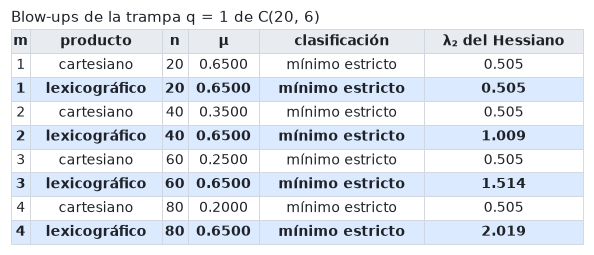

In [10]:
W = grafo_circulante(20, 6)
theta = twisted_state(20, 1)
filas = []
for m in [1, 2, 3, 4]:
    productos = {"cartesiano": blowup_cartesiano(W, m), "lexicográfico": blowup_lexicografico(W, m)}
    for nombre, M in productos.items():
        tipo, autovalores = clasificar(np.tile(theta, m), M)
        filas.append([m, nombre, len(M), f"{conectividad(M):.4f}", tipo, f"{np.sort(autovalores)[1]:.3f}"])
mostrar_tabla(["m", "producto", "n", "μ", "clasificación", "λ₂ del Hessiano"], filas,
              titulo="Blow-ups de la trampa q = 1 de C(20, 6)", resaltar=[1, 3, 5, 7])

El blow-up lexicográfico (resaltado) mantiene $\mu = 0.65$ y la trampa para todo $m$. El cartesiano
también mantiene la trampa, pero $\mu$ cae.

Generalizando, los clusters pueden tener tamaños distintos y entre dos clusters no hace falta unir todo
con todo, sino una fracción de los pares: es el marco de las plantillas de la sección 2.2.

### 3.2 El estado de 4 clusters C4 ($\mu = 3/4$)

**El estado.** Cuatro clusters iguales ($x_a = 1/4$) en las fases $0, \pi/2, \pi, 3\pi/2$. Cada uno
está completo por dentro y unido completamente a sus dos vecinos, pero **no** al opuesto:
- grado: el propio cluster más los dos vecinos, $3 \cdot \frac14 = \frac34$;
- equilibrio: los dos vecinos tiran igual y en sentidos opuestos;
- splitting: $c_a = 1/4 > 0$ (solo tiran los compañeros, porque los vecinos están a $90°$ y
  $\cos 90° = 0$);
- modos de cluster: **$L \equiv 0$**. Rotar clusters enteros no cuesta energía a segundo orden, porque
  los pares unidos tienen $\cos = 0$ y los opuestos no están unidos.

**De dónde sale y qué se sabe.** Kassabov, Strogatz y Townsend (2021) probaron $\mu_c \le 3/4$ y
mostraron que su método no podía bajar de ahí justamente por este estado, que está "en el filo" de la
estabilidad. Lepsveridze y Zhang (2026) mostraron que **no** es un mínimo (separar dos clusters vecinos
baja la energía a tercer orden), lo que da $\mu_c < 3/4$, y que cerca de $3/4$ es el único obstáculo
posible.

**Por qué importa.** C4 tiene $\mu$ muy alto pero es degenerado. Tanto Canale como O'Keeffe lo
**deforman** para volverlo estable, pagando con algo de $\mu$.

In [11]:
# biblioteca
def plantilla_c4():
    """Estado de 4 clusters de Kassabov–Strogatz–Townsend: μ = 3/4, L ≡ 0 (degenerado)."""
    P = np.array([
        [1, 1, 0, 1],
        [1, 1, 1, 0],
        [0, 1, 1, 1],
        [1, 0, 1, 1],
    ], dtype=float)
    return Plantilla(np.full(4, 0.25), np.arange(4) * np.pi / 2, P, "C4")


def plantilla_canale(a=1.0, b=1.0, c=1.0, d=0.5, interna=1.0):
    """Plantilla de Canale (arXiv 2209.06362, sec. V): 4 pares de clusters (i, ±) en πi/2 ± β/2.

    Los conjuntos E_t del paper tienen erratas; usamos la geometría de su Fig. 2 y del Lema 1:
      c: (i,+)–(i,−)       diferencia β          a: (i,+)–(i+1,−)   diferencia α
      b: (i,s)–(i+1,s)     diferencia π/2        d: (i,−)–(i+1,+)   diferencia α + 2β
    con α + β = π/2 y equilibrio (a − d) tan α = c. Estable si c² > 2ad.
    Con a = b = c = 1 y d → 1/2⁻, μ → 11/16. Índice del cluster (i, s): 2i + (s == +1).
    """
    def indice(i, s):
        """Índice del cluster (i, s) en la plantilla."""
        return 2 * (i % 4) + (s == 1)

    P = np.zeros((8, 8))
    for i in range(4):
        P[indice(i, 1), indice(i, -1)] = c
        P[indice(i, 1), indice(i + 1, -1)] = a
        P[indice(i, 1), indice(i + 1, 1)] = b
        P[indice(i, -1), indice(i + 1, -1)] = b
        P[indice(i, -1), indice(i + 1, 1)] = d
    P = P + P.T
    np.fill_diagonal(P, interna)
    alpha = np.arctan2(c, a - d)
    beta = np.pi / 2 - alpha
    phi = np.zeros(8)
    for k in range(8):
        signo = 1 if k % 2 else -1
        phi[k] = np.pi * (k // 2) / 2 + signo * beta / 2
    return Plantilla(np.full(8, 1 / 8), phi, P, f"Canale (a,b,c,d)=({a},{b},{c},{d})")

In [12]:
T = plantilla_c4()
for clave, valor in T.reporte().items():
    print(f"{clave:16s} {valor:+.3e}")
print("autovalores de L en 1⊥:", np.round(T.autovalores_clusters(), 14))

mu               +7.500e-01
max|F|           +0.000e+00
min c            +2.500e-01
min autovalor L  -1.961e-17
autovalores de L en 1⊥: [-0.  0.  0.]


### 3.3 Twisted states como plantilla: un programa lineal

**De dónde sale.** Las primeras cotas inferiores usan twisted states. En el anillo $C_{n,k}$ el último
$k$ con trampa da $\mu \to 0.681$. Después se buscó en grafos **circulantes** más generales (cada
vértice unido con los de ciertas distancias, no necesariamente $1, \dots, k$): Canale–Monzón (2015)
llegaron a 0.6818, Townsend–Stillman–Strogatz (2020) a 0.6828 y Yoneda–Tatsukawa–Teramae (2021) a
0.6838 con el circulante óptimo, encontrado por programación entera.

**Como plantilla.** $m$ clusters iguales en $\varphi_a = 2\pi q a/m$ (un twisted state de $q$ vueltas),
con una densidad $p_j$ que solo depende de la distancia $j$ entre clusters. Por simetría el equilibrio
se cumple solo, y $L$ es una matriz circulante cuyos autovalores son **lineales** en las $p_j$.
Maximizar el grado con $L \succ 0$ es entonces un **programa lineal (LP)**, que se resuelve exacto. Se
excluye $q = m/4$, que es C4.

In [13]:
# biblioteca
def twisted_lp(m, q=1, margen=1e-9):
    """Mayor μ de una plantilla twisted con m clusters y q vueltas (0 si es infactible)."""
    distancias = np.arange(1, m // 2 + 1)
    # j y −j son la misma distancia salvo j = m/2, que aparece una sola vez
    multiplicidad = np.full(len(distancias), 2)
    if m % 2 == 0:
        multiplicidad[-1] = 1
    paso = 2 * np.pi * q / m
    cosenos = multiplicidad * np.cos(distancias * paso)

    filas, cotas = [], []
    for k in range(1, m):
        autovalor_k = cosenos * (2 - 2 * np.cos(2 * np.pi * distancias * k / m)) / m**2
        filas.append(-autovalor_k)
        cotas.append(-margen)
    # splitting: c_a = (1 + Σ_j p_j cos(j·paso))/m > 0
    filas.append(-cosenos / m)
    cotas.append(1 / m - margen)

    objetivo = -multiplicidad / m
    limites = [(0, 1)] * len(distancias)
    resultado = linprog(objetivo, A_ub=filas, b_ub=cotas, bounds=limites, method="highs")
    if not resultado.success:
        return 0.0
    return 1 / m - resultado.fun


def mejor_twisted(m):
    """Mejor μ sobre q para m clusters, sin q = m/4 (que es el estado degenerado C4)."""
    mejor = 0.0
    for q in range(1, (m - 1) // 4 + 1):
        if 4 * q == m:
            continue
        mejor = max(mejor, twisted_lp(m, q))
    return mejor

mejor m: 19
mejor μ: 0.683876   (Yoneda–Tatsukawa–Teramae 2021: 0.6838)
μ con m = 120: 0.681966   (límite de los anillos C(n,k) con q = 1: ≈ 0.681)


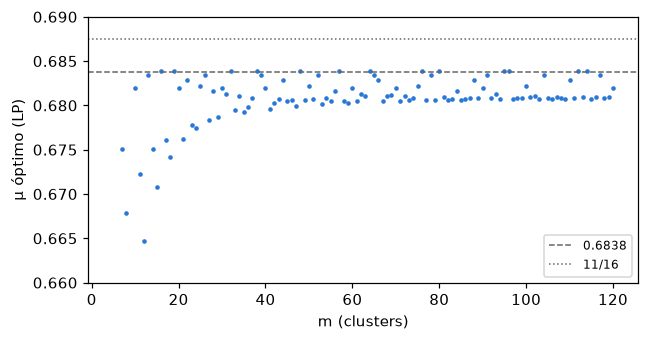

In [14]:
ms = np.arange(5, 121)
mejores = []
for m in ms:
    mejores.append(mejor_twisted(m))
mejores = np.array(mejores)
i = int(mejores.argmax())
print("mejor m:", ms[i])
print("mejor μ:", f"{mejores[i]:.6f}   (Yoneda–Tatsukawa–Teramae 2021: 0.6838)")
print("μ con m = 120:", f"{mejores[-1]:.6f}   (límite de los anillos C(n,k) con q = 1: ≈ 0.681)")

fig, eje = plt.subplots(figsize=(6, 3.2))
eje.plot(ms, mejores, ".", ms=4, color=COLORES[0])
for y, nombre, estilo in [(0.6838, "0.6838", "--"), (11 / 16, "11/16", ":")]:
    eje.axhline(y, ls=estilo, color="0.4", lw=1, label=nombre)
eje.set(xlabel="m (clusters)", ylabel="μ óptimo (LP)", ylim=(0.66, 0.69))
eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

El LP reencuentra el 0.6838 de Yoneda et al. y, para $m$ grande, el 0.681 de los anillos. Para pasar
de ahí hacen falta estados que no sean twisted.

### 3.4 Canale: 11/16 con grafos explícitos

Canale (*From weighted to unweighted graphs in Synchronizing Graph Theory*, 2022) dio los primeros
grafos explícitos con trampa y densidad cercana a $11/16$. Su construcción tiene dos partes, y las dos
las reutilizamos.

**(1) Un grafo con pesos de 8 vértices.** Cada cluster de C4 se parte en dos mitades, "$-$" y "$+$",
corridas $\mp\beta/2$ respecto de la fase del sector: $\theta_{2i+s} = i\pi/2 + s\beta/2$. Hay cuatro
tipos de aristas, con pesos $a, b, c, d$ según el ángulo entre sus extremos:

| tipo | diferencia de fase | quiénes | efecto |
|---|---|---|---|
| $c$ | $\beta$ | las dos mitades de un sector | estabiliza ($\cos > 0$) |
| $a$ | $\alpha = \pi/2 - \beta$ | mitades cercanas de sectores vecinos | estabiliza |
| $b$ | $\pi/2$ | mitades "del mismo lado" de sectores vecinos | neutro ($\cos = 0$); sus tirones se cancelan |
| $d$ | $\alpha + 2\beta = \pi/2 + \beta$ | mitades lejanas de sectores vecinos | **desestabiliza** ($\cos < 0$) |

- **Equilibrio:** $(a - d)\tan\alpha = c$, que fija el ángulo.
- **Estabilidad (Lema 1):** es estable si $c^2 > 2ad$.
- **Elección:** con $a = b = c = 1$ la estabilidad pide $d < 1/2$: las aristas lejanas, las que
  desestabilizan, tienen que quedar **a menos de la mitad de densidad**. Con $d = 1/2$,
  $\tan\alpha = 2$ y $\beta = \arctan(1/2) \approx 26.6°$.
- **Grado:** propio + $a$ + $2b$ + $c$ + $d$ $= (1 + 1 + 2 + 1 + \tfrac12)/8 = 11/16$, en el límite
  $d \to 1/2^-$.

(Los conjuntos de aristas $E_t$ escritos en el paper tienen erratas: se superponen. Usamos la
geometría de su Figura 2 y del Hessiano del Lema 1, que no son ambiguos.) En el lenguaje de
plantillas son 8 clusters iguales, y la estabilidad cambia exactamente en $d = 1/2$:

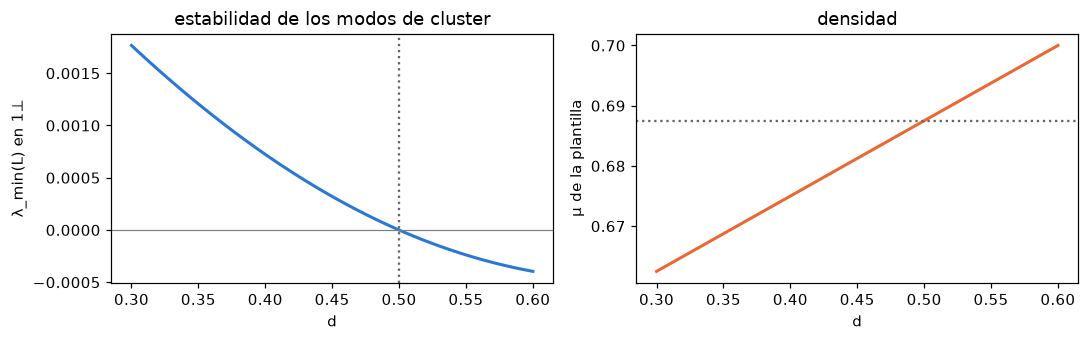

In [15]:
ds = np.linspace(0.3, 0.6, 61)
autovalores_min = []
mus = []
for d in ds:
    T = plantilla_canale(d=d)
    autovalores_min.append(T.autovalores_clusters().min())
    mus.append(T.mu())

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.2))
ejes[0].plot(ds, autovalores_min, color=COLORES[0], lw=2)
ejes[0].axhline(0, color="0.5", lw=0.8)
ejes[0].axvline(0.5, ls=":", color="0.4")
ejes[0].set(xlabel="d", ylabel="λ_min(L) en 1⊥", title="estabilidad de los modos de cluster")
ejes[1].plot(ds, mus, color=COLORES[1], lw=2)
ejes[1].axhline(11 / 16, ls=":", color="0.4")
ejes[1].set(xlabel="d", ylabel="μ de la plantilla", title="densidad")
plt.tight_layout()
plt.show()

**(2) De pesos a un grafo simple: el $k$-spinning.** Cada vértice del grafo con pesos pasa a ser un
clique de $k$ copias, numeradas en $\mathbb Z_k$, y una arista de peso $w$ une la copia $i$ con las
copias $i, i+1, \dots, i+w-1$ del otro vértice: un **intervalo** de copias consecutivas. Así cada copia
tiene exactamente $w$ vecinos del otro lado, y el peso se vuelve un grado exacto. Es un blow-up en el
que la densidad entre clusters es $w/k$: así nacen las **densidades intermedias**, la clave para pasar
de 0.6838. Esta es la herramienta que generalizamos en la sección 8.

**Grafos reales.** Canale toma $(a, b, c, d) = (k, k, k, \lceil k/2\rceil - 1)$: un grafo regular con
$n = 8k$ y $\mu = (5.5k - 1)/(8k) \to 11/16$ por debajo. `realizar` con `tipo="intervalo"` construye
exactamente esos grafos. Chequeamos con el Hessiano del grafo entero que sea un mínimo estricto, y con
una simulación desde un estado perturbado que vuelva:

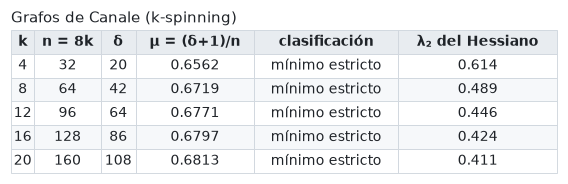

simulación con k = 8 desde una perturbación de 0.05 rad:
  convergió: True
  dispersión final respecto del estado (salvo rotación): 7.0e-11


In [16]:
filas = []
for k in [4, 8, 12, 16, 20]:
    d = int(np.ceil(k / 2)) - 1
    W, theta = realizar(plantilla_canale(d=d / k), k, rng=0, tipo="intervalo")
    tipo, autovalores = clasificar(theta, W)
    delta = W.sum(axis=1).min()
    filas.append([k, len(W), int(delta), f"{(delta + 1) / len(W):.4f}", tipo, f"{np.sort(autovalores)[1]:.3f}"])
mostrar_tabla(["k", "n = 8k", "δ", "μ = (δ+1)/n", "clasificación", "λ₂ del Hessiano"], filas,
              titulo="Grafos de Canale (k-spinning)")

W, theta = realizar(plantilla_canale(d=3 / 8), 8, rng=0, tipo="intervalo")
perturbacion = 0.05 * np.random.default_rng(1).standard_normal(len(theta))
simulacion = simular(theta + perturbacion, W, guardar=False)
desvio = np.angle(np.exp(1j * (simulacion["theta"] - theta)))
print("simulación con k = 8 desde una perturbación de 0.05 rad:")
print("  convergió:", simulacion["convergio"])
print("  dispersión final respecto del estado (salvo rotación):", f"{np.ptp(desvio):.1e}")

Todos son mínimos estrictos y la simulación vuelve al estado. Con $k$ chico, $\mu$ queda bastante
debajo de $11/16$: el récord es un **límite**. La condición $c^2 > 2ad$ obliga a $d < k/2$, y eso frena
la densidad en $11/16$. O'Keeffe cuenta que sus búsquedas con links 0/1 volvían siempre al estado de
Canale, lo que hizo pensar que $11/16$ podía ser el valor exacto de $\mu_c$.

### 3.5 O'Keeffe: S7 y 0.6929, pero sin grafo

O'Keeffe (*Beyond 11/16: dense Kuramoto networks that resist synchrony*, arXiv 2610.21271, octubre de
2026) usa plantillas con densidades intermedias y sube la cota a $\mu_c \ge 0.6929077$. Cuenta que gran
parte del trabajo la hicieron agentes de IA, con él eligiendo el problema y el estándar de evidencia.
Sus scripts no son públicos; por eso los reconstruimos.

**La familia S7.** Se deforma C4 así:
- los sectores **A** (fase 0), **B** ($\pi/2$) y **C** ($\pi$) tienen tamaño $2a$ cada uno y se parten
  en dos mitades, $m$ ("menos") y $p$ ("más"), corridas $h\,s$ respecto de la fase del sector;
- el sector **W** ($3\pi/2$) tiene tamaño $1 - 6a$, queda entero y hace de **ancla**;
- son 7 clusters (de ahí el nombre), en el orden $(A_m, A_p, B_m, B_p, C_m, C_p, W)$, con
  desplazamientos $s = (-1, 1, -w, w, -1, 1, 0)$.

$h$ es la **apertura**: cuánto se separan las mitades, del orden de $10^{-3}$ a $10^{-6}$.

**El patrón límite** (Tabla II del paper), cuando $h \to 0$: todo es 1 (completo) o 0 (vacío), salvo
**cuatro pares cruzados** con densidad $q$: Am–Bp, Ap–Bm, Bm–Cp y Bp–Cm. A–C y B–W, los sectores
opuestos, no tienen links.

**Grados límite.** Las mitades tienen tamaño $a$ y W tiene $1 - 6a$:
- un vértice de Am ve su sector ($2a$), Bm completo y Bp con densidad $q$ ($(1+q)a$), nada de C, y W
  completo: $d_A = 2a + (1+q)a + (1 - 6a) = 1 - (3 - q)a$;
- un vértice de Bm ve su sector y, en A y en C, una mitad completa y otra con $q$; nada de W:
  $d_B = 2a + 2(1+q)a = (4 + 2q)a$;
- W ve A, C y a sí mismo: $d_W = 4a + (1 - 6a) = 1 - 2a$.

Se elige $a$ para que A y B tengan el mismo grado: $a = 1/(7 + q)$. (Si W fuera más grande, A tendría
más grado y B menos, y el mínimo bajaría.) Entonces $d_W = (5+q)/(7+q)$ es mayor, y
$$\mu_0(q) = \frac{4 + 2q}{7 + q},$$
que crece con $q$. Cuanto más grande $q$, mejor, pero hay un límite.

**La esquina.** Para $h \to 0$ los modos de cluster de S7 tienen autovalores de orden $h^2$. Subir $q$
ablanda dos de ellos (los "dipolos": rotar A contra C, y B contra W). Hay un punto $(q^*, w^*)$, la
**esquina**, en el que los dos quedan exactamente neutros. Es la raíz de las dos condiciones del
Apéndice A:
$$f = -2q^2w^2 - 4q^2w - 3q^2 - 2q + 4w + 1 = 0, \qquad e = -q^2w^2 + q^2 - 2qw^2 + 6q - w^2 + 1 = 0.$$
$q^*$ es además la raíz en $(0,1)$ de un polinomio de grado 8 (el polinomio (3) del paper), así que
$\mu_0 = \mu_0(q^*)$ es algebraico.

**El código** reconstruye todo esto en alta precisión: las condiciones, la esquina por Newton
(`mp.findroot`), el patrón límite, la corrección de primer orden $p'$ y el ajuste final.

In [17]:
# biblioteca
INDICE = {nombre: i for i, nombre in enumerate(NOMBRES)}


CUARTOS = [0, 0, 1, 1, 2, 2, 3]


CAMINO = [("Am", "Bm"), ("Bm", "Cm"), ("Cm", "W"), ("W", "Cp"), ("Cp", "Bp"), ("Bp", "Ap")]


def f_e(q, w):
    """Las dos condiciones de neutralidad del modelo límite (Apéndice A, (I5))."""
    f = -2 * q**2 * w**2 - 4 * q**2 * w - 3 * q**2 - 2 * q + 4 * w + 1
    e = -q**2 * w**2 + q**2 - 2 * q * w**2 + 6 * q - w**2 + 1
    return f, e


def u13(q, w):
    """Parámetro u13(q, w) del Apéndice A, ec. (A3)."""
    return (2 * q**2 * w**2 + 2 * q**2 * w - q**2 - 6 * q + 4 * w**2 - 2 * w + 3) / 2


def polinomio_3(q):
    """Polinomio (3) de O'Keeffe, cuya única raíz en (0, 1) es q*."""
    return (9 * q**8 + 72 * q**7 + 288 * q**6 + 448 * q**5 + 470 * q**4
            + 88 * q**3 - 208 * q**2 - 128 * q - 15)


def esquina(dps=50):
    """(q*, w*, μ0): punto donde los dos dipolos del modelo límite son exactamente neutros."""
    with mp.workdps(dps):
        q, w = mp.findroot(f_e, (mp.mpf("0.65"), mp.mpf("1.4")))
        return q, w, (4 + 2 * q) / (7 + q)


def matriz_cero(m=7):
    """Matriz m × m de ceros como lista de listas."""
    return [[mp.mpf(0)] * m for _ in range(m)]


def _poner(P, nombre1, nombre2, valor):
    """Escribe un valor simétrico en P para el par de clusters (nombre1, nombre2)."""
    P[INDICE[nombre1]][INDICE[nombre2]] = valor
    P[INDICE[nombre2]][INDICE[nombre1]] = valor


def patron_limite(q):
    """Patrón límite de la Tabla II: 1 completo, q adelgazado, 0 vacío."""
    filas = [
        [1, 1, 1, q, 0, 0, 1],
        [1, 1, q, 1, 0, 0, 1],
        [1, q, 1, 1, 1, q, 0],
        [q, 1, 1, 1, q, 1, 0],
        [0, 0, 1, q, 1, 1, 1],
        [0, 0, q, 1, 1, 1, 1],
        [1, 1, 0, 0, 1, 1, 1],
    ]
    P = []
    for fila in filas:
        P.append([mp.mpf(v) for v in fila])
    return P


def primer_orden(q, w, a, xW, kappa=mp.mpf(19) / 10):
    """Corrección de primer orden p′ (Apéndice A, después de la ec. (A1))."""
    u = u13(q, w)
    A1 = w * (w + 1) - u / 2
    A2 = u / 2 - w * (w - 1)
    P = matriz_cero()
    _poner(P, "Am", "Bm", A1 - kappa)
    _poner(P, "Bp", "Cp", A1 - kappa)
    _poner(P, "Ap", "Bm", A2 - kappa)
    _poner(P, "Bp", "Cm", A2 - kappa)
    for nombre1, nombre2 in [("Ap", "Bp"), ("Bm", "Cm"), ("Am", "Bp"), ("Bm", "Cp")]:
        _poner(P, nombre1, nombre2, -kappa)
    _poner(P, "Am", "W", a / xW * (A1 + 2 - 2 * kappa))
    _poner(P, "Cp", "W", a / xW * (A1 + 2 - 2 * kappa))
    _poner(P, "Ap", "W", a / xW * (A2 - 2 - 2 * kappa))
    _poner(P, "Cm", "W", a / xW * (A2 - 2 - 2 * kappa))
    return P


def _corregir_equilibrio(x, phi, P):
    """Resuelve Δ sobre el CAMINO para que F = 0 exacto (F es afín en P).

    Se descarta la ecuación del cluster W, que se deduce de Σ x_a F_a = 0. Devuelve Δ y P corregida.
    """
    F_actual = fuerzas(x, phi, P, mp)
    columnas = []
    for nombre1, nombre2 in CAMINO:
        E = matriz_cero()
        _poner(E, nombre1, nombre2, mp.mpf(1))
        columnas.append(fuerzas(x, phi, E, mp))
    J = mp.matrix(6, 6)
    for fila in range(6):
        for columna in range(6):
            J[fila, columna] = columnas[columna][fila]
    lado_derecho = mp.matrix([-F_actual[fila] for fila in range(6)])
    delta = mp.lu_solve(J, lado_derecho)
    for k, (nombre1, nombre2) in enumerate(CAMINO):
        i, j = INDICE[nombre1], INDICE[nombre2]
        _poner(P, nombre1, nombre2, P[i][j] + delta[k])
    return delta, P


def construir(t, h, dps=60, corregir=True):
    """Plantilla S7 para (t, h): dict con x, phi, P (mpmath, listas), q, w, F_primer_orden y delta."""
    with mp.workdps(dps):
        t = mp.mpf(t)
        h = mp.mpf(h)
        q_estrella, w, _ = esquina(dps)
        q = q_estrella - t
        a = 1 / (7 + q)
        xW = 1 - 6 * a
        x = [a] * 6 + [xW]
        desplazamientos = [-1, 1, -w, w, -1, 1, 0]
        phi = []
        for c in range(7):
            phi.append(CUARTOS[c] * mp.pi / 2 + h * desplazamientos[c])

        limite = patron_limite(q)
        correccion = primer_orden(q, w, a, xW)
        P = matriz_cero()
        for i in range(7):
            for j in range(7):
                P[i][j] = limite[i][j] + h * correccion[i][j]

        F_primer_orden = fuerzas(x, phi, P, mp)
        delta = None
        if corregir:
            delta, P = _corregir_equilibrio(x, phi, P)
        return {"x": x, "phi": phi, "P": P, "q": q, "w": w, "t": t, "h": h,
                "F_primer_orden": F_primer_orden, "delta": delta}

q*  = 0.65056916694479880261
w*  = 1.3982781340204611796
μ0  = 0.69290770636958636365
polinomio (3) en q*: 1.47e-39
q*: 0.6505691669447988   (referencia: 0.6505691669447988, coincide)
w*: 1.398278134020461   (referencia: 1.3982781340204613, coincide)
μ0: 0.6929077063695863   (referencia: 0.6929077063, coincide)


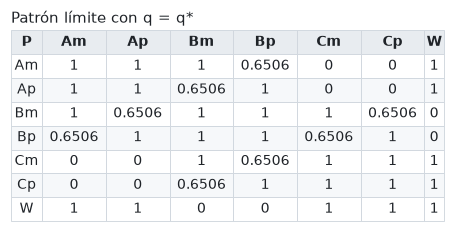

In [18]:
mp.mp.dps = 40
q_estrella, w_estrella, mu_cero = esquina()
print("q*  =", mp.nstr(q_estrella, 20))
print("w*  =", mp.nstr(w_estrella, 20))
print("μ0  =", mp.nstr(mu_cero, 20))
print("polinomio (3) en q*:", mp.nstr(polinomio_3(q_estrella), 3))
comparar("q*", float(q_estrella))
comparar("w*", float(w_estrella))
comparar("μ0", float(mu_cero), tolerancia=1e-10)

filas = []
for nombre, fila in zip(NOMBRES, patron_limite(q_estrella)):
    textos = [nombre]
    for valor in fila:
        textos.append(f"{float(valor):.4f}" if 0 < valor < 1 else f"{float(valor):.0f}")
    filas.append(textos)
mostrar_tabla(["P"] + NOMBRES, filas, titulo="Patrón límite con q = q*")

**Miembros finitos.** Para $(t, h)$ concretos, O'Keeffe toma $q = q^* - t$ y densidades
$$P = p + h\,p' + \Delta:$$
- $p$ es el patrón límite;
- $p'$ es una corrección de primer orden, explícita en el Apéndice A, que hace valer el equilibrio
  hasta orden $h$. Elige un parámetro $\kappa = 19/10$ "para que $p' < 0$ en todos los pares vecinos
  con $p = 1$": a $h$ finito **todos** los pares vecinos bajan de 1, no solo los cuatro cruzados;
- $\Delta = O(h^2)$ es un ajuste final sobre un camino de 6 pares (Am–Bm–Cm–W–Cp–Bp–Ap) que hace el
  equilibrio **exacto**. Como $F$ es lineal en $P$, es un sistema lineal de $6 \times 6$.

Hay dos parámetros chicos, y el orden importa: primero se fija $t$, después se toma $h$ chico para ese
$t$.
- $t > 0$ es la **distancia a la esquina**: vuelve estrictamente estables los dipolos, con una brecha
  proporcional a $t$, a cambio de $\mu_0(q^* - t) < \mu_0$.
- $h$ es la apertura. El modo más débil queda a $\sim h^2(t + h)$ de la neutralidad.

Primero chequeamos que $F(p + hp')$ escala como $h^2$ (eso confirma que leímos bien $p'$). Después
miramos $\mu$ y el menor autovalor de $L$ para varios $(t, h)$; con $t < 0$, o sea $q > q^*$, tiene
que fallar: es el control negativo.

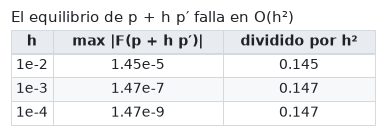

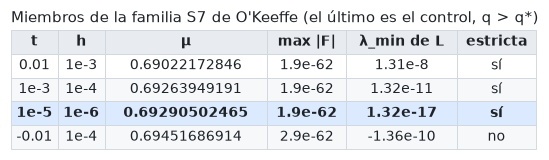

In [19]:
filas = []
for h in ["1e-2", "1e-3", "1e-4"]:
    S = construir("1e-3", h, corregir=False)
    residuo = max(abs(v) for v in S["F_primer_orden"])
    filas.append([h, mp.nstr(residuo, 3), mp.nstr(residuo / mp.mpf(h) ** 2, 3)])
mostrar_tabla(["h", "max |F(p + h p′)|", "dividido por h²"], filas, titulo="El equilibrio de p + h p′ falla en O(h²)")

filas = []
for t, h in [("0.01", "1e-3"), ("1e-3", "1e-4"), ("1e-5", "1e-6"), ("-0.01", "1e-4")]:
    S = construir(t, h)
    r = analizar(S["x"], S["phi"], S["P"], mp)
    menor = min(r["autovalores L"])
    filas.append([t, h, mp.nstr(r["mu"], 11), mp.nstr(r["max|F|"], 2), mp.nstr(menor, 3), si_no(menor > 0)])
mostrar_tabla(["t", "h", "μ", "max |F|", "λ_min de L", "estricta"], filas,
              titulo="Miembros de la familia S7 de O'Keeffe (el último es el control, q > q*)", resaltar=[2])

El cociente por $h^2$ queda constante, y los miembros con $t > 0$ son estrictos con $\mu$ que se acerca
a $\mu_0$, mientras que el control con $t < 0$ no lo es. El menor autovalor del miembro resaltado, $(t, h) = (10^{-5}, 10^{-6})$, es del orden de $10^{-18}$.

### 3.6 Un certificado propio de la Proposición 1 de O'Keeffe

**Por qué hace falta un certificado.** El menor autovalor es del orden de $10^{-18}$, más chico que el
error de redondeo de los números de punto flotante ($\sim 10^{-16}$). Una cuenta común no prueba nada.
Se usa **aritmética de intervalos**: cada número se reemplaza por un intervalo que seguro contiene el
valor verdadero, redondeando siempre hacia afuera. Si una desigualdad vale para todo el intervalo,
vale para el valor real: es una demostración por computadora.

**Los pasos** (el mismo esquema que el Apéndice B del paper, con código escrito de cero):
1. **datos exactos:** redondear tamaños y densidades a fracciones con un denominador común $D$
   (`racionalizar`);
2. **fases:** refinarlas por Newton en alta precisión (son irracionales, así que solo se conocen
   aproximadas; `fases_newton`);
3. **existencia del equilibrio (test de Krawczyk):** una versión de Newton con intervalos. Si manda una
   caja de fases $X$ estrictamente adentro de sí misma, hay **exactamente un** equilibrio verdadero en
   $X$. En fórmulas, con $\tilde\varphi$ el centro de la caja e $Y$ una inversa aproximada de $J$:
   $$K(X) = \tilde\varphi - Y F(\tilde\varphi) + \big(I - Y J(X)\big)(X - \tilde\varphi) \subset \operatorname{int} X;$$
4. **$c > 0$** sobre toda la caja;
5. **$L \succ 0$ con Cholesky por intervalos:** una matriz simétrica es definida positiva si y solo si
   su factorización de Cholesky tiene pivotes positivos. Si la factorización de la matriz de intervalos
   de $L$ (sin la fila y columna de la rotación) termina con pivotes positivos, vale para la $L$
   verdadera en el equilibrio verdadero;
6. **no es la sincronización:** alguna cota inferior de $|\sin((\varphi_a - \varphi_b)/2)|$ es positiva;
7. **$\mu$ exacto** como fracción.

**De la plantilla al grafo (Lema 2 de O'Keeffe).** Cada cluster se vuelve un anillo $\mathbb Z_g$ y los
links entre anillos se eligen con desplazamientos al azar, como en `realizar`. Así cada vértice tiene
exactamente el número de vecinos pedido, y las direcciones oscilantes quedan controladas con alta
probabilidad. Para los datos con denominador $D$ hace falta $n \ge D^2$: el grafo existe, pero nadie
lo escribe.

**El código** (los seis pasos):

In [20]:
# biblioteca
def racionalizar(x, P, D, diagonal_maxima=True):
    """Redondea (x, P) a denominador común D (par), con Σ x = 1 exacto ajustando el último cluster.

    Si diagonal_maxima, las diagonales quedan en (D − 1)/D (clique completo, como pide el Lema 2).
    """
    assert D % 2 == 0
    m = len(x)
    with mp.workdps(len(str(D)) + 30):  # precisión suficiente para redondear a 1/D
        X = []
        for xa in x[:-1]:
            X.append(int(mp.nint(xa * D)))
        X.append(D - sum(X))
        Q = [[0] * m for _ in range(m)]
        for a in range(m):
            for b in range(a, m):
                if a == b:
                    valor = D - 1 if diagonal_maxima else int(mp.floor(P[a][b] * D))
                else:
                    valor = int(mp.nint(P[a][b] * D))
                tope = D - 1 if a == b else D
                valor = max(0, min(tope, valor))
                Q[a][b] = valor
                Q[b][a] = valor
    xq = [Fraction(Xa, D) for Xa in X]
    Pq = []
    for fila in Q:
        Pq.append([Fraction(valor, D) for valor in fila])
    return xq, Pq


def _a_mpf(fraccion):
    """Fraction → mpf."""
    return mp.mpf(fraccion.numerator) / fraccion.denominator


def _a_intervalo(fraccion):
    """Fraction → intervalo de mpmath.iv que la contiene."""
    return iv.mpf(fraccion.numerator) / fraccion.denominator


def fases_newton(xq, Pq, phi0, dps=120, iteraciones=60):
    """Refina las fases por Newton (φ_0 fijo) para los datos racionales, en mpmath de alta precisión."""
    with mp.workdps(dps):
        x = [_a_mpf(v) for v in xq]
        P = []
        for fila in Pq:
            P.append([_a_mpf(v) for v in fila])
        phi = [mp.mpf(p) for p in phi0]
        m = len(x)
        for _ in range(iteraciones):
            F = mp.matrix(fuerzas(x, phi, P, mp)[1:])
            if mp.norm(F) < mp.mpf(10) ** (-dps + 10):
                break
            J = mp.matrix(jacobiano_fuerzas(x, phi, P, mp))
            paso = mp.lu_solve(J, F)
            for a in range(1, m):
                phi[a] -= paso[a - 1]
        return phi


def _cota_inferior(intervalo):
    """Extremo inferior de un intervalo de mpmath.iv, como mpf."""
    return mp.mpf(intervalo.a.a)


def _krawczyk(x, P, centro, caja):
    """¿K(X) = m − Y F(m) + (I − Y J(X))(X − m) cae en el interior de la caja X?"""
    n = len(caja) - 1
    F_centro = fuerzas(x, centro, P, iv)[1:]
    J_centro = jacobiano_fuerzas(x, centro, P, iv)
    J_punto = mp.matrix(n, n)
    for i in range(n):
        for j in range(n):
            J_punto[i, j] = mp.mpf(J_centro[i][j].mid)
    Y = J_punto ** -1
    J_caja = jacobiano_fuerzas(x, caja, P, iv)

    for i in range(n):
        K_i = centro[i + 1]
        for k in range(n):
            K_i = K_i - iv.mpf(Y[i, k]) * F_centro[k]
        for j in range(n):
            coeficiente = 1 if i == j else 0
            for k in range(n):
                coeficiente = coeficiente - iv.mpf(Y[i, k]) * J_caja[k][j]
            K_i = K_i + coeficiente * (caja[j + 1] - centro[j + 1])
        dentro = K_i.a > caja[i + 1].a and K_i.b < caja[i + 1].b
        if not dentro:
            return False
    return True


def _cholesky_intervalos(A):
    """Cholesky de una matriz de intervalos; devuelve (éxito, cota inferior del menor pivote)."""
    n = len(A)
    L = [[iv.mpf(0)] * n for _ in range(n)]
    menor_pivote = None
    for j in range(n):
        pivote = A[j][j]
        for k in range(j):
            pivote = pivote - L[j][k] ** 2
        cota = _cota_inferior(pivote)
        menor_pivote = cota if menor_pivote is None else min(menor_pivote, cota)
        if not cota > 0:
            return False, menor_pivote
        L[j][j] = iv.sqrt(pivote)
        for i in range(j + 1, n):
            suma = A[i][j]
            for k in range(j):
                suma = suma - L[i][k] * L[j][k]
            L[i][j] = suma / L[j][j]
    return True, menor_pivote


def _separaciones(caja):
    """Cotas inferiores de |sin((φ_a − φ_b)/2)| sobre la caja, para todos los pares a < b."""
    m = len(caja)
    cotas = []
    for a in range(m):
        for b in range(a + 1, m):
            cotas.append(_cota_inferior(abs(iv.sin((caja[a] - caja[b]) / 2))))
    return cotas


def certificar(xq, Pq, phi_centro, radio="1e-40", dps=100, verbose=True):
    """Corre todos los pasos del certificado. Devuelve un dict; ok = True solo si todos pasan.

    La clave "caja" tiene la caja de fases (intervalos) donde Krawczyk garantiza la solución.
    """
    iv.dps = dps
    mp.mp.dps = dps
    m = len(xq)
    x = [_a_intervalo(v) for v in xq]
    P = []
    for fila in Pq:
        P.append([_a_intervalo(v) for v in fila])
    r = mp.mpf(radio)
    centro_mp = [mp.mpf(p) for p in phi_centro]
    centro = [iv.mpf(p) for p in centro_mp]
    caja = [iv.mpf(centro_mp[0])]
    for a in range(1, m):
        caja.append(iv.mpf([centro_mp[a] - r, centro_mp[a] + r]))

    resultado = {}
    resultado["krawczyk"] = _krawczyk(x, P, centro, caja)

    c = splitting(x, caja, P, iv)
    resultado["min c (cota inf)"] = min(_cota_inferior(ca) for ca in c)
    resultado["c>0"] = resultado["min c (cota inf)"] > 0

    L = matriz_clusters(x, caja, P, iv)
    L_sin_rotacion = [fila[1:] for fila in L[1:]]
    exito, menor_pivote = _cholesky_intervalos(L_sin_rotacion)
    resultado["cholesky"] = exito
    resultado["min pivote (cota inf)"] = menor_pivote

    separaciones = _separaciones(caja)
    resultado["min |sin(Δφ/2)| (cota inf)"] = min(separaciones)
    resultado["distintas"] = resultado["min |sin(Δφ/2)| (cota inf)"] > 0
    resultado["no sync"] = max(separaciones) > 0

    resultado["mu"] = min(grados(xq, Pq))
    resultado["caja"] = caja
    resultado["ok"] = (resultado["krawczyk"] and resultado["c>0"]
                       and resultado["cholesky"] and resultado["no sync"])
    if verbose:
        imprimir_certificado(resultado)
    return resultado


def imprimir_certificado(resultado):
    """Imprime cada paso del certificado y el μ exacto."""
    for clave, valor in resultado.items():
        if clave in ("mu", "caja"):
            continue
        texto = valor if isinstance(valor, bool) else mp.nstr(valor, 6)
        print(f"  {clave:28s} {texto}")
    mu = resultado["mu"]
    bits = mu.denominator.bit_length()
    print(f"  {'mu (exacto)':28s} {float(mu):.16f}  (denominador {bits} bits)")

Con $(t, h) = (10^{-5}, 10^{-6})$, denominador $D = 2\cdot10^{42}$, una caja de radio $10^{-54}$ y
114 dígitos, reproducimos la Proposición 1, $\mu^* = 0.6929050246493944\ldots$ (la diferencia en el
dígito 14 viene de cómo se redondean las fracciones). Tarda menos de un segundo:

In [21]:
inicio = time.time()
S = construir("1e-5", "1e-6", dps=120)
D = 2 * 10**42
xq, Pq = racionalizar(S["x"], S["P"], D)
phi = fases_newton(xq, Pq, S["phi"], dps=140)
resultado = certificar(xq, Pq, phi, radio=mp.mpf(10) ** -54, dps=114)
print()
print("O'Keeffe, Proposición 1: μ* = 0.6929050246493944…")
print(f"tiempo: {time.time() - inicio:.2f} s")

  krawczyk                     True
  min c (cota inf)             0.215744
  c>0                          True
  cholesky                     True
  min pivote (cota inf)        3.6094e-18
  min |sin(Δφ/2)| (cota inf)   1.0e-6
  distintas                    True
  no sync                      True
  ok                           True
  mu (exacto)                  0.6929050246493601  (denominador 282 bits)

O'Keeffe, Proposición 1: μ* = 0.6929050246493944…
tiempo: 0.05 s


Todos los pasos dan verdadero, y el menor pivote de Cholesky es diminuto pero con cota inferior
positiva. **El problema es el tamaño:** con $D \approx 2\cdot 10^{42}$, el grafo del Lema 2 tiene
$n \ge D^2 \approx 10^{85}$ vértices. Ese es el punto de partida de nuestro objetivo (sección 5).

## 4. La búsqueda: ¿hay algo mejor que S7?

Antes de construir el grafo, exploramos si había plantillas mejores que S7. Esta sección cuenta esa
búsqueda: otros patrones de partición de C4, el caso sin densidades intermedias (la idea original del
"apilado") y las *semillas*, estados en el borde de la estabilidad que podrían deformarse como C4.

### 4.1 El problema interno es convexo: un SDP

Con los tamaños $x$ y las fases $\varphi$ fijos, los senos y cosenos son **números**, así que los
grados, $F$, $c$ y la matriz de $L$ son **lineales** en las densidades $P$. Maximizar
$\mu = \min_a d_a$ sobre $P$ es entonces:

$$\max\ \tau \quad\text{sujeto a}\quad
\begin{cases}
0 \le P \le 1 \text{ simétrica},\ P_{aa} = 1,\ P_{ab} = 0 \text{ en los pares prohibidos}\\
\sum_b P_{ab}x_b \ge \tau \text{ para todo } a \\
F(P) = 0, \quad c(P) \ge 10^{-3}\\
Q^\top L(P)\,Q\,/\,\text{escala} \succeq \varepsilon I
\end{cases}$$

donde $Q$ es una base ortonormal de $\mathbf 1^\perp$ y "$\succeq$" quiere decir "semidefinida
positiva". Un problema con objetivo lineal, restricciones lineales y una restricción "esta matriz, que
depende linealmente de las variables, es semidefinida positiva" es un **programa semidefinido (SDP)**.
Lo importante es que es **convexo**: no tiene óptimos locales falsos, y un solver (CLARABEL, a través
de `cvxpy`) encuentra el óptimo global en milisegundos. La condición de estabilidad, que a primera
vista es "$L(y) > 0$ para infinitos $y$", queda como una sola restricción sobre una matriz.

**La escala.** Cerca de un estado degenerado como C4 los modos de cluster son de orden $h^2$, así que se
divide por $\text{escala} = h^2$; si no, el margen $\varepsilon$ mata justo los estados buscados
(O'Keeffe lo advierte en su sección VI).

**El problema externo.** Las fases dependen de los desplazamientos, y con ellos como variables el
problema deja de ser convexo. Una **base** es un estado de sectores (fases y tamaños, como C4) y un
**patrón** dice en cuántas piezas se parte cada sector; S7 es el patrón $(2, 2, 2, 1)$ de C4. Las piezas
del sector $j$ quedan en $\varphi = \text{fase}_j + h s$, y sus tamaños y desplazamientos $s$ se
optimizan con **Nelder–Mead** (un método sin derivadas) desde varios arranques. `FamiliaParticiones`
traduce un vector de parámetros a $(x, \varphi)$ y llama al SDP.

In [22]:
# biblioteca
def sdp_interno(x, phi, escala=1.0, margen=1e-6, margen_c=1e-3, prohibidos=None, solver="CLARABEL"):
    """Mayor μ sobre las densidades P con x y φ fijos. Devuelve (μ, P) o (None, None) si es infactible."""
    m = len(x)
    diferencias = phi[:, None] - phi[None, :]
    senos = np.sin(diferencias)
    cosenos = np.cos(diferencias)
    pesos_L = np.outer(x, x) * cosenos
    np.fill_diagonal(pesos_L, 0)

    P = cp.Variable((m, m), symmetric=True)
    t = cp.Variable()
    K = cp.multiply(P, pesos_L)
    L = cp.diag(cp.sum(K, axis=1)) - K
    Q = base_perpendicular(m)
    restricciones = [
        P >= 0,
        P <= 1,
        cp.diag(P) == 1,
        P @ x >= t,
        cp.multiply(P, senos) @ x == 0,
        cp.multiply(P, cosenos) @ x >= margen_c,
        (Q.T @ L @ Q) / escala >> margen * np.eye(m - 1),
    ]
    if prohibidos is not None:
        restricciones.append(cp.multiply(P, prohibidos.astype(float)) == 0)
    problema = cp.Problem(cp.Maximize(t), restricciones)
    try:
        problema.solve(solver=solver)
    except cp.error.SolverError:
        return None, None
    if problema.status not in ("optimal", "optimal_inaccurate"):
        return None, None
    return float(t.value), np.array(P.value)


@dataclass
class Base:
    """Estado de sectores sobre el que se parten clusters.

    fases: fase de cada sector. tamanos: tamaño total de cada sector (para los arranques).
    prohibidos: pares de sectores sin links. radios: amplitud inicial de los desplazamientos por sector.
    """

    nombre: str
    fases: np.ndarray
    tamanos: np.ndarray
    prohibidos: np.ndarray
    radios: np.ndarray


def base_c4(q=0.6505691669447988, w=1.3982781340204612):
    """C4 con los tamaños de S7 (2a, 2a, 2a, 1 − 6a) y radios (1, w*, 1, 1); opuestos sin links."""
    a = 1 / (7 + q)
    T = plantilla_c4()
    return Base(
        nombre="C4",
        fases=T.phi,
        tamanos=np.array([2 * a, 2 * a, 2 * a, 1 - 6 * a]),
        prohibidos=(T.P == 0),
        radios=np.array([1.0, w, 1.0, 1.0]),
    )


def base_canale():
    """Canale en el borde d = 1/2 (8 sectores iguales); sin links donde Canale no los tiene."""
    T = plantilla_canale(d=0.5)
    return Base(
        nombre="Canale",
        fases=T.phi,
        tamanos=T.x,
        prohibidos=(T.P == 0),
        radios=np.ones(8),
    )


class FamiliaParticiones:
    """Plantillas que parten cada sector j de una base en piezas[j] piezas, separadas por h·s."""

    def __init__(self, base, piezas, h):
        """Arma la familia: a qué sector pertenece cada pieza y qué pares quedan prohibidos."""
        assert len(piezas) == len(base.fases), "un número de piezas por sector"
        self.base = base
        self.piezas = list(piezas)
        self.h = h
        self.sector = np.repeat(np.arange(len(piezas)), self.piezas)
        self.m = len(self.sector)
        self.partida = np.array([self.piezas[j] > 1 for j in self.sector])
        self.prohibidos = base.prohibidos[np.ix_(self.sector, self.sector)]

    def cantidad_parametros(self):
        """Largo de z: un logit por pieza más un desplazamiento por pieza partida."""
        return self.m + int(self.partida.sum())

    def decodificar(self, z):
        """z = (logits de tamaños, desplazamientos de las piezas partidas) → (x, φ)."""
        logits = z[: self.m]
        desplazamientos_libres = z[self.m:]
        x = np.exp(logits - logits.max())
        x = x / x.sum()
        desplazamientos = np.zeros(self.m)
        desplazamientos[self.partida] = desplazamientos_libres
        phi = self.base.fases[self.sector] + self.h * desplazamientos
        return x, phi

    def desplazamientos(self, phi):
        """Inversa parcial de decodificar: s = (φ − fase del sector)/h."""
        return (phi - self.base.fases[self.sector]) / self.h

    def mu(self, z, margen=1e-6):
        """μ del SDP interno para los parámetros z (−1 si es infactible o hay piezas vacías)."""
        x, phi = self.decodificar(z)
        if np.min(x) < 1e-3:
            return -1.0
        mu, _ = sdp_interno(x, phi, escala=self.h**2, margen=margen, prohibidos=self.prohibidos)
        return -1.0 if mu is None else mu


def arranque_estructurado(familia, rng=None, ruido=0.0):
    """Tamaños de la base repartidos en partes iguales y desplazamientos equiespaciados en [−r_j, r_j].

    Con la base C4 y el patrón (2,2,2,1) es el ansatz de S7. Con ruido > 0 sirve para reinicios.
    """
    rng = np.random.default_rng(rng)
    tamanos = np.repeat(familia.base.tamanos / np.array(familia.piezas), familia.piezas)
    desplazamientos = []
    for j, k in enumerate(familia.piezas):
        if k > 1:
            r = familia.base.radios[j]
            desplazamientos.extend(np.linspace(-r, r, k))
    z = np.concatenate([np.log(tamanos), np.array(desplazamientos)])
    return z + ruido * rng.standard_normal(len(z))


def arranque_aleatorio(familia, rng):
    """Tamaños casi iguales por sector y desplazamientos al azar en [−1.5, 1.5]."""
    sectores = len(familia.piezas)
    tamanos = np.repeat(1 / sectores / np.array(familia.piezas), familia.piezas)
    logits = np.log(tamanos) + 0.1 * rng.standard_normal(familia.m)
    desplazamientos = []
    for k in familia.piezas:
        if k > 1:
            desplazamientos.extend(np.sort(rng.uniform(-1.5, 1.5, k)))
    return np.concatenate([logits, np.array(desplazamientos)])


def optimizar_familia(familia, z0, margen=1e-6, max_iteraciones=400):
    """Nelder–Mead sobre z maximizando μ desde z0. Devuelve (mejor μ, mejor z)."""
    mejor = (familia.mu(z0, margen), z0)
    opciones = {"maxiter": max_iteraciones, "xatol": 1e-4, "fatol": 1e-7, "adaptive": True}
    resultado = minimize(lambda z: -familia.mu(z, margen), z0, method="Nelder-Mead", options=opciones)
    if -resultado.fun > mejor[0]:
        mejor = (-resultado.fun, resultado.x)
    return mejor

**Validación.** S7 con $h = 0.01$, desde el arranque de O'Keeffe, tiene que acercarse al $0.6918$ que
reporta el paper (con pocas iteraciones queda un poco abajo; la exploración de 4.2 lo afina):

In [23]:
inicio = time.time()
familia = FamiliaParticiones(base_c4(), (2, 2, 2, 1), h=0.01)
mu, z = optimizar_familia(familia, arranque_estructurado(familia), max_iteraciones=150)
print("μ de S7 con h = 0.01 (150 iteraciones):", f"{mu:.5f}")
print("O'Keeffe con h = 0.01:", 0.6918)
print(f"tiempo: {time.time() - inicio:.0f} s")

μ de S7 con h = 0.01 (150 iteraciones): 0.69124
O'Keeffe con h = 0.01: 0.6918
tiempo: 3 s


### 4.2 Otros patrones de partición

S7 parte tres de los cuatro clusters de C4 en dos mitades. ¿Qué pasa con otros patrones: partir los
cuatro, partir en tres piezas, partir solo dos? `explorar_patron` corre varios reinicios de
Nelder–Mead para un patrón, con dos tipos de arranque:
- **estilo S7** (`arranque_estructurado`): los tamaños de la base repartidos en partes iguales y los
  desplazamientos equiespaciados en $[-r_j, r_j]$ (con $(2,2,2,1)$ es el ansatz de O'Keeffe);
- **al azar** (`arranque_aleatorio`).

**Ojo:** estos números son evidencia numérica (un SDP con tolerancias del solver), no certificados.

In [24]:
# biblioteca
BASES = {"c4": base_c4, "canale": base_canale}


PATRONES_C4 = [
    (2, 2, 2, 1),  # S7 (O'Keeffe)
    (2, 2, 1, 1),  # dos vecinos
    (2, 1, 2, 1),  # dos opuestos
    (2, 2, 2, 2),  # los cuatro
    (3, 2, 2, 1),
    (2, 3, 2, 1),
    (3, 3, 3, 1),
    (2, 2, 3, 2),
    (3, 3, 3, 3),
    (2, 1, 1, 1),
    (3, 1, 1, 1),
    (3, 3, 1, 1),
]


def explorar_patron(trabajo):
    """Corre los reinicios de un patrón y devuelve el mejor resultado."""
    nombre_base, piezas, h, reinicios, max_iteraciones, semilla_rng, arranque = trabajo
    familia = FamiliaParticiones(BASES[nombre_base](), piezas, h)
    rng = np.random.default_rng(semilla_rng)
    inicio = time.time()
    mus = []
    mejor_z = None
    for reinicio in range(reinicios):
        usar_estructurado = arranque == "estructurado" or (arranque == "mixto" and reinicio % 2 == 0)
        if usar_estructurado:
            z0 = arranque_estructurado(familia, rng, ruido=0.05 * reinicio)
        else:
            z0 = arranque_aleatorio(familia, rng)
        mu, z = optimizar_familia(familia, z0, max_iteraciones=max_iteraciones)
        mus.append(mu)
        if mu >= max(mus):
            mejor_z = z
    x, phi = familia.decodificar(mejor_z)
    return {
        "base": nombre_base,
        "piezas": list(piezas),
        "h": h,
        "arranque": arranque,
        "mejor_mu": max(mus),
        "todos_mu": mus,
        "x": x.tolist(),
        "s": familia.desplazamientos(phi).tolist(),
        "segundos": time.time() - inicio,
    }

In [25]:
%%writefile externos/particiones.py
"""Patrones de partición de C4 (sección 4.2): el mejor μ de cada patrón, con Nelder–Mead afuera del SDP.

Completo: 12 patrones con h = 0.02 (arranques estilo S7 y al azar) y S7 contra (3,3,3,1) con h = 0.01
y 0.005, 8 reinicios de hasta 1000 iteraciones. Reducido: 4 patrones con h = 0.02 y 2 con h = 0.01, un
solo arranque de 300 iteraciones. Uso: python externos/particiones.py [--reducido] [--procesos N]
"""
import argparse
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parent))
from biblioteca_s7 import *  # noqa: E402,F403


def trabajos_completos():
    """(base, piezas, h, reinicios, iteraciones, semilla, arranque) de la exploración completa."""
    trabajos = []
    for arranque in ["estructurado", "aleatorio"]:
        for i, piezas in enumerate(PATRONES_C4):
            trabajos.append(("c4", piezas, 0.02, 8, 1000, 1000 + i, arranque))
    for h in [0.01, 0.005]:
        for i, piezas in enumerate([(2, 2, 2, 1), (3, 3, 3, 1)]):
            trabajos.append(("c4", piezas, h, 8, 1000, 1000 + i, "estructurado"))
    return trabajos


def trabajos_reducidos():
    """Versión chica: pocos patrones, un arranque estilo S7 y 300 iteraciones."""
    trabajos = []
    for i, piezas in enumerate([(2, 2, 2, 1), (3, 3, 3, 1), (2, 2, 2, 2), (2, 2, 1, 1)]):
        trabajos.append(("c4", piezas, 0.02, 1, 300, 1000 + i, "estructurado"))
    for i, piezas in enumerate([(2, 2, 2, 1), (3, 3, 3, 1)]):
        trabajos.append(("c4", piezas, 0.01, 1, 300, 1000 + i, "estructurado"))
    return trabajos


def main():
    """Corre los patrones en paralelo y guarda resultados/particiones[_reducido].json."""
    parser = argparse.ArgumentParser()
    parser.add_argument("--reducido", action="store_true")
    parser.add_argument("--procesos", type=int, default=8)
    args = parser.parse_args()
    trabajos = trabajos_reducidos() if args.reducido else trabajos_completos()
    resultados = []
    for r in correr_en_paralelo(explorar_patron, trabajos, args.procesos):
        print(f"h = {r['h']}  {r['arranque']:12s} {tuple(r['piezas'])}: μ = {r['mejor_mu']:.5f}"
              f"   ({r['segundos']:.0f} s)", flush=True)
        resultados.append(r)
    resultados.sort(key=lambda r: (r["h"], r["arranque"], -r["mejor_mu"]))
    nombre = "particiones_reducido.json" if args.reducido else "particiones.json"
    print("guardado en", guardar_json(nombre, resultados))


if __name__ == "__main__":
    main()

Overwriting externos/particiones.py


<table>
<tr><th align="left">▶ Cómo correr <code>externos/particiones.py</code> (desde la carpeta del notebook)</th></tr>
<tr><td align="left"><b>Máquina:</b> CPU, varios núcleos (no usa GPU)<br><b>Tiempo:</b> completo: ~5 h de CPU (~40 min con 8 procesos) · reducido: ~1–2 min<br><b>Salida:</b> <code>resultados/particiones.json</code> (o <code>particiones_reducido.json</code>)</td></tr>
<tr><td align="left"><pre>nohup python externos/particiones.py --procesos 8 &gt; particiones.log 2&gt;&amp;1 &amp;</pre></td></tr>
<tr><td align="left"><pre>python externos/particiones.py --reducido --procesos 2</pre></td></tr>
</table>

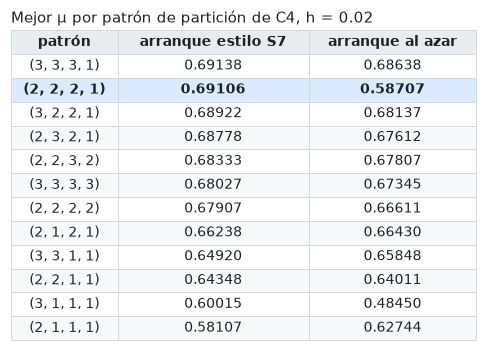

In [26]:
if existe_resultado("particiones.json"):
    particiones = cargar_json("particiones.json")
elif CORRER["particiones"]:
    correr_paso("particiones.py", f"--procesos {PROCESOS}", "particiones (completo)")
    particiones = cargar_json("particiones.json")
else:
    print("versión reducida (para la completa: CORRER['particiones'] = True o correr el script afuera)")
    if not existe_resultado("particiones_reducido.json"):
        correr_paso("particiones.py", f"--reducido --procesos {PROCESOS}", "particiones (reducido)")
    particiones = cargar_json("particiones_reducido.json")


def mejores_por_patron(filas, h, arranque):
    """{patrón: mejor μ} de las filas con ese h y ese arranque."""
    mejores = {}
    for fila in filas:
        if fila["h"] == h and fila["arranque"] == arranque:
            mejores[tuple(fila["piezas"])] = fila["mejor_mu"]
    return mejores


estructurado = mejores_por_patron(particiones, 0.02, "estructurado")
aleatorio = mejores_por_patron(particiones, 0.02, "aleatorio")
filas = []
for patron in sorted(estructurado, key=lambda p: -estructurado[p]):
    al_azar = f"{aleatorio[patron]:.5f}" if patron in aleatorio else "—"
    filas.append([str(patron), f"{estructurado[patron]:.5f}", al_azar])
mostrar_tabla(["patrón", "arranque estilo S7", "arranque al azar"], filas,
              titulo="Mejor μ por patrón de partición de C4, h = 0.02",
              resaltar=[i for i, f in enumerate(filas) if f[0] == "(2, 2, 2, 1)"])

**Lectura** (de la exploración completa).
- **Arranques:** al azar ni siquiera se reencuentra S7 ($(2,2,2,1)$ queda en $\approx 0.59$): las
  cuencas de los buenos estados son angostas, como advierte O'Keeffe.
- Con arranques estilo S7, los patrones que parten el cluster ancla W, o que parten menos de tres
  clusters, quedan claramente debajo. Solo $(3,3,3,1)$ le gana a S7 con el mismo $h$.

¿Se mantiene esa ventaja cuando $h \to 0$? Comparamos los dos patrones para varios $h$, junto con los
valores que reporta O'Keeffe para S7:

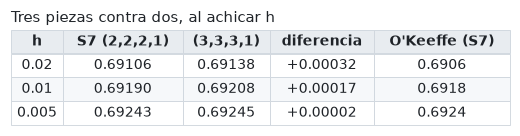

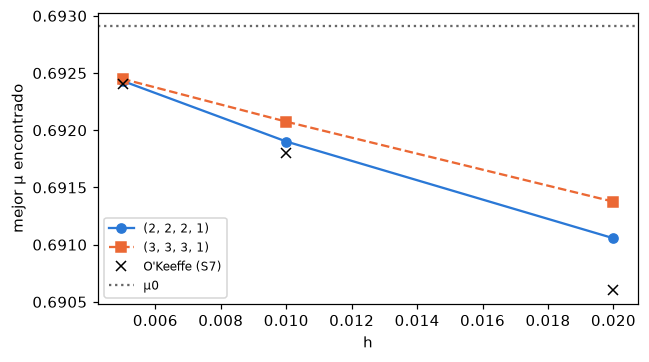

In [27]:
okeeffe = {0.02: 0.6906, 0.01: 0.6918, 0.005: 0.6924}
hs = sorted({fila["h"] for fila in particiones}, reverse=True)
filas = []
puntos = {(2, 2, 2, 1): [], (3, 3, 3, 1): []}
for h in hs:
    por_patron = mejores_por_patron(particiones, h, "estructurado")
    if (2, 2, 2, 1) not in por_patron or (3, 3, 3, 1) not in por_patron:
        continue
    a = por_patron[(2, 2, 2, 1)]
    b = por_patron[(3, 3, 3, 1)]
    puntos[(2, 2, 2, 1)].append((h, a))
    puntos[(3, 3, 3, 1)].append((h, b))
    filas.append([h, f"{a:.5f}", f"{b:.5f}", f"{b - a:+.5f}", okeeffe.get(h, "—")])
mostrar_tabla(["h", "S7 (2,2,2,1)", "(3,3,3,1)", "diferencia", "O'Keeffe (S7)"], filas,
              titulo="Tres piezas contra dos, al achicar h")

fig, eje = plt.subplots(figsize=(6, 3.4))
for (patron, valores), estilo, color in zip(puntos.items(), ["o-", "s--"], COLORES):
    eje.plot([v[0] for v in valores], [v[1] for v in valores], estilo, color=color, label=str(patron))
eje.plot(list(okeeffe), list(okeeffe.values()), "x", color="k", label="O'Keeffe (S7)")
eje.axhline(float(mu_cero), ls=":", color="0.4", label="μ0")
eje.set(xlabel="h", ylabel="mejor μ encontrado")
eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

En la corrida completa la diferencia baja más o menos linealmente con $h$ (+0.00032, +0.00018,
+0.00002 para $h$ = 0.02, 0.01, 0.005), así que en el límite $h \to 0$ partir en tres piezas **no**
mejora $\mu_0$. Es consistente con lo que afirma O'Keeffe ("allowing more pieces per cluster did not
raise it"): un resultado negativo, pero documentado. (Con la versión reducida, de un solo arranque
corto, los números quedan algo más abajo y la tendencia es menos limpia.)

### 4.3 El caso 0/1: blow-ups completos

La idea original del "apilado", generalizada: tomar un grafo base chico $H$, poner un clique por
vértice y un bipartito completo por arista. Es una plantilla con $P = A_H + I$ fija, **sin densidades
intermedias**. Para cada $H$ conexo con $k$ vértices se buscan tamaños y fases que den un estado
estricto no sincronizado con el mayor $\mu$:
$$\max\ \min_a d_a \quad\text{sobre } x \text{ y } \varphi\ (\varphi_0 = 0) \quad\text{con}\quad F = 0,\ c_a \ge 10^{-3},\ \lambda_{\min}(L|_{\mathbf 1^\perp}) \ge 10^{-6},$$
con SLSQP (un optimizador con restricciones) desde varios arranques. Antes, un **prefiltro** descarta
los $H$ que no pueden dar $\mu > 0.6$ ni ignorando la estabilidad: el LP
$\max_x \min_a (Mx)_a$ sobre el símplex, que es una cota superior.

Los grafos conexos se enumeran con el atlas de grafos de `networkx` (todos los grafos de hasta 7
vértices), que reemplaza al programa `geng` de nauty.

In [28]:
# biblioteca
def grafos_conexos(k):
    """Genera (graph6, matriz de adyacencia) de todos los grafos conexos con k vértices (atlas de networkx)."""
    for G in nx.graph_atlas_g():
        if G.number_of_nodes() == k and nx.is_connected(G):
            codigo = nx.to_graph6_bytes(G, header=False).decode().strip()
            yield codigo, nx.to_numpy_array(G)


def mu_sin_estabilidad(M):
    """LP: max_x min_a (M x)_a con x en el símplex. Devuelve (valor, x óptimo)."""
    k = len(M)
    objetivo = np.zeros(k + 1)
    objetivo[-1] = -1
    desigualdades = np.hstack([-M, np.ones((k, 1))])
    suma_uno = [list(np.ones(k)) + [0]]
    resultado = linprog(objetivo, A_ub=desigualdades, b_ub=np.zeros(k), A_eq=suma_uno, b_eq=[1],
                        bounds=[(0, 1)] * (k + 1), method="highs")
    return -resultado.fun, resultado.x[:k]


class Restricciones:
    """Desempaqueta v = (logits de x, φ_1..φ_{k−1}, t) y evalúa las restricciones de una plantilla 0/1."""

    def __init__(self, M, margen, margen_c):
        """Guarda M = A + I, la base de 1^⊥ y los márgenes."""
        self.M = M
        self.k = len(M)
        self.Q = base_perpendicular(self.k)
        self.margen = margen
        self.margen_c = margen_c

    def desempaquetar(self, v):
        """v → (x en el símplex, φ con φ_0 = 0)."""
        k = self.k
        x = np.exp(v[:k] - v[:k].max())
        x = x / x.sum()
        phi = np.concatenate([[0.0], v[k: 2 * k - 1]])
        return x, phi

    def grado_menos_t(self, v):
        """d_a − t (tiene que ser ≥ 0)."""
        x, _ = self.desempaquetar(v)
        return self.M @ x - v[-1]

    def equilibrio(self, v):
        """F_a para a ≥ 1 (tiene que ser 0)."""
        x, phi = self.desempaquetar(v)
        return np.array(fuerzas(x, phi, self.M))[1:]

    def splitting_menos_margen(self, v):
        """c_a − margen_c (tiene que ser ≥ 0)."""
        x, phi = self.desempaquetar(v)
        return np.array(splitting(x, phi, self.M)) - self.margen_c

    def autovalor_min(self, v):
        """Menor autovalor de L en 1^⊥ (sin la rotación global)."""
        x, phi = self.desempaquetar(v)
        L = np.array(matriz_clusters(x, phi, self.M))
        return np.linalg.eigvalsh(self.Q.T @ L @ self.Q).min()

    def para_slsqp(self):
        """Las restricciones en el formato de scipy.optimize.minimize."""
        return [
            {"type": "ineq", "fun": self.grado_menos_t},
            {"type": "eq", "fun": self.equilibrio},
            {"type": "ineq", "fun": self.splitting_menos_margen},
            {"type": "ineq", "fun": lambda v: np.array([self.autovalor_min(v) - self.margen])},
        ]


def optimizar_grafo(M, arranques, rng, margen=1e-6, margen_c=1e-3):
    """Mejor estado estricto no sync del blow-up completo de M = A + I, o None si no se encontró."""
    k = len(M)
    restricciones = Restricciones(M, margen, margen_c)
    _, x_lp = mu_sin_estabilidad(M)
    mejor = None
    for _ in range(arranques):
        x0 = 0.5 * x_lp + 0.5 / k + 0.02 * rng.random(k)
        v0 = np.concatenate([np.log(x0), rng.uniform(-np.pi, np.pi, k - 1), [0.5]])
        try:
            resultado = minimize(lambda v: -v[-1], v0, constraints=restricciones.para_slsqp(),
                                 method="SLSQP", options={"maxiter": 300, "ftol": 1e-10})
        except Exception:
            continue
        v = resultado.x
        x, phi = restricciones.desempaquetar(v)
        autovalor = restricciones.autovalor_min(v)
        agrupamiento = np.abs(np.exp(1j * phi).mean())
        valido = (np.abs(restricciones.equilibrio(v)).max() < 1e-8
                  and restricciones.splitting_menos_margen(v).min() > -margen_c / 2
                  and autovalor > margen / 2
                  and agrupamiento < 1 - 1e-6)
        if not valido:
            continue
        mu = (M @ x).min()
        if mejor is None or mu > mejor["mu"]:
            mejor = {"mu": float(mu), "x": x.tolist(), "phi": phi.tolist(), "autovalor_min": float(autovalor)}
    return mejor


def optimizar_trabajo(trabajo):
    """Trabajo en paralelo: (graph6, arranques, semilla) → (graph6, mejor estado o None)."""
    codigo, arranques, semilla_rng = trabajo
    G = nx.from_graph6_bytes(codigo.encode())
    M = nx.to_numpy_array(G) + np.eye(G.number_of_nodes())
    return codigo, optimizar_grafo(M, arranques, np.random.default_rng(semilla_rng))

In [29]:
%%writefile externos/caso_01.py
"""Caso 0/1 (sección 4.3): blow-ups completos de todos los grafos conexos H con k vértices.

Completo: k = 5, 6, 7 con 20 arranques. Reducido: k = 5, 6 con 5 arranques.
Uso: python externos/caso_01.py [--reducido] [--procesos N]
"""
import argparse
import sys
import time
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parent))
from biblioteca_s7 import *  # noqa: E402,F403


def un_k(k, arranques, piso, procesos):
    """Prefiltro LP y optimización en paralelo para los grafos de k vértices."""
    inicio = time.time()
    cantidad = 0
    candidatos = []
    for codigo, A in grafos_conexos(k):
        cantidad += 1
        M = A + np.eye(k)
        if M.min() == 1:  # H completo: sincroniza
            continue
        if mu_sin_estabilidad(M)[0] > piso + 1e-9:
            candidatos.append(codigo)
    print(f"k = {k}: {cantidad} grafos conexos, {len(candidatos)} pasan el prefiltro LP > {piso}", flush=True)
    trabajos = []
    for i, codigo in enumerate(candidatos):
        trabajos.append((codigo, arranques, i))
    encontrados = []
    for codigo, mejor in correr_en_paralelo(optimizar_trabajo, trabajos, procesos):
        if mejor is not None:
            encontrados.append({"g6": codigo, **mejor})
    encontrados.sort(key=lambda r: -r["mu"])
    print(f"   con algún estado estricto no sync: {len(encontrados)}   [{time.time() - inicio:.0f} s]", flush=True)
    return {"k": k, "arranques": arranques, "cantidad_grafos": cantidad, "cantidad_prefiltro": len(candidatos),
            "encontrados": encontrados[:200]}


def main():
    """Recorre los k pedidos y guarda resultados/blowups_01[_reducido].json."""
    parser = argparse.ArgumentParser()
    parser.add_argument("--reducido", action="store_true")
    parser.add_argument("--piso", type=float, default=0.6, help="prefiltro: μ del LP mayor que esto")
    parser.add_argument("--procesos", type=int, default=8)
    args = parser.parse_args()
    ks = [5, 6] if args.reducido else [5, 6, 7]
    arranques = 5 if args.reducido else 20
    resultados = []
    for k in ks:
        resultados.append(un_k(k, arranques, args.piso, args.procesos))
    nombre = "blowups_01_reducido.json" if args.reducido else "blowups_01.json"
    print("guardado en", guardar_json(nombre, resultados))


if __name__ == "__main__":
    main()

Overwriting externos/caso_01.py


<table>
<tr><th align="left">▶ Cómo correr <code>externos/caso_01.py</code> (desde la carpeta del notebook)</th></tr>
<tr><td align="left"><b>Máquina:</b> CPU, varios núcleos<br><b>Tiempo:</b> completo: ~35 min de CPU (~5 min con 8 procesos) · reducido: ~2 min de CPU<br><b>Salida:</b> <code>resultados/blowups_01.json</code> (o <code>blowups_01_reducido.json</code>)</td></tr>
<tr><td align="left"><pre>python externos/caso_01.py --procesos 8</pre></td></tr>
<tr><td align="left"><pre>python externos/caso_01.py --reducido --procesos 2</pre></td></tr>
</table>

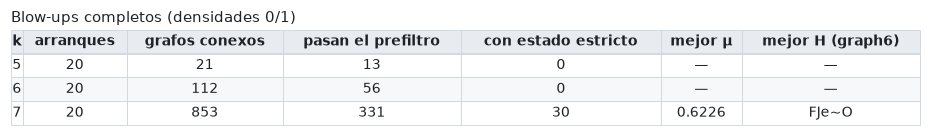

In [30]:
if existe_resultado("blowups_01.json"):
    caso_01 = cargar_json("blowups_01.json")
elif CORRER["caso_01"]:
    correr_paso("caso_01.py", f"--procesos {PROCESOS}", "caso 0/1 (completo)")
    caso_01 = cargar_json("blowups_01.json")
else:
    print("versión reducida (para la completa: CORRER['caso_01'] = True o correr el script afuera)")
    if not existe_resultado("blowups_01_reducido.json"):
        correr_paso("caso_01.py", f"--reducido --procesos {PROCESOS}", "caso 0/1 (reducido)")
    caso_01 = cargar_json("blowups_01_reducido.json")

filas = []
for datos in caso_01:
    encontrados = datos["encontrados"]
    mejor = f"{encontrados[0]['mu']:.4f}" if encontrados else "—"
    grafo = encontrados[0]["g6"] if encontrados else "—"
    filas.append([datos["k"], datos["arranques"], datos["cantidad_grafos"], datos["cantidad_prefiltro"],
                  len(encontrados), mejor, grafo])
mostrar_tabla(["k", "arranques", "grafos conexos", "pasan el prefiltro", "con estado estricto", "mejor μ",
               "mejor H (graph6)"], filas, titulo="Blow-ups completos (densidades 0/1)")

Con grafos base chicos, los blow-ups completos no pasan de $\mu \approx 0.62$ (el mejor con $k = 7$),
lejos de $11/16$: hacen falta **densidades intermedias**, como las $d \to 1/2$ de Canale o las
$q^* \approx 0.65$ de S7.

### 4.4 Semillas

Una **semilla** es un estado de clusters con $\mu$ alto que está justo en el borde de la estabilidad
($L \succeq 0$ con modos neutros), como C4, o como Canale en $d = 1/2$. Las construcciones récord son
semilla más deformación: S7 es C4 deformado. `semilla` corre el SDP **sin margen** y cuenta los modos
neutros del óptimo. Probamos dos geometrías:
- una red de $\ell$ clusters iguales equiespaciados ($\ell = 4$ es C4);
- dos redes de $\ell$ puntos rotadas un ángulo $\beta$ entre sí, con pesos $r$ y $1 - r$ ($\ell = 4$ es
  la geometría de Canale).

In [31]:
# biblioteca
def semilla(x, phi):
    """μ de borde (L ⪰ 0, sin brecha) y cantidad de modos de cluster neutros en el óptimo."""
    mu, P = sdp_interno(x, phi, margen=0.0, margen_c=1e-6)
    if mu is None:
        return None, None
    T = Plantilla(x, phi, (P + P.T) / 2)
    neutros = int((T.autovalores_clusters() < 1e-7).sum())
    return mu, neutros


def una_red(l):
    """ℓ clusters iguales equiespaciados."""
    return np.full(l, 1 / l), 2 * np.pi * np.arange(l) / l


def dos_redes(l, r, beta):
    """Dos redes de ℓ puntos rotadas β entre sí, con pesos totales r y 1 − r."""
    red = 2 * np.pi * np.arange(l) / l
    x = np.concatenate([np.full(l, r / l), np.full(l, (1 - r) / l)])
    phi = np.concatenate([red, red + beta])
    return x, phi


def barrer_una_red(ls):
    """Semilla de cada red de ℓ clusters."""
    resultados = []
    for l in ls:
        mu, neutros = semilla(*una_red(l))
        resultados.append({"l": l, "mu": mu, "neutros": neutros})
    return resultados


def barrer_dos_redes(ls, rs, cantidad_betas):
    """Mejores semillas de dos redes rotadas, sobre una grilla de β y pesos r."""
    resultados = []
    for l in ls:
        betas = np.linspace(0.02, 2 * np.pi / l - 0.02, cantidad_betas)
        for r in rs:
            for beta in betas:
                mu, neutros = semilla(*dos_redes(l, r, beta))
                if mu is not None:
                    resultados.append({"l": l, "r": r, "beta_grados": float(np.degrees(beta)),
                                       "mu": mu, "neutros": neutros})
    resultados.sort(key=lambda fila: -fila["mu"])
    return resultados

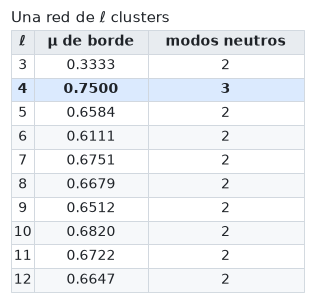

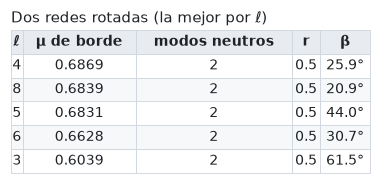

chequeo, Canale como base sin partir: μ = 0.6875 (tiene que ser 11/16 = 0.6875)
tiempo: 13 s


In [32]:
inicio = time.time()
una = barrer_una_red(range(3, 13))
dos = barrer_dos_redes([3, 4, 5, 6, 8], [0.3, 0.4, 0.5], 40)
TIEMPOS["semillas"] = time.time() - inicio

filas = []
for fila in una:
    filas.append([fila["l"], "—" if fila["mu"] is None else f"{fila['mu']:.4f}", fila["neutros"]])
mostrar_tabla(["ℓ", "μ de borde", "modos neutros"], filas, titulo="Una red de ℓ clusters", resaltar=[1])

filas = []
vistos = set()
for fila in dos:
    if fila["l"] in vistos:
        continue
    vistos.add(fila["l"])
    filas.append([fila["l"], f"{fila['mu']:.4f}", fila["neutros"], fila["r"], f"{fila['beta_grados']:.1f}°"])
mostrar_tabla(["ℓ", "μ de borde", "modos neutros", "r", "β"], filas, titulo="Dos redes rotadas (la mejor por ℓ)")

familia = FamiliaParticiones(base_canale(), [1] * 8, h=0.01)
print("chequeo, Canale como base sin partir: μ =", round(familia.mu(np.log(np.full(8, 1 / 8)), margen=0.0), 6),
      "(tiene que ser 11/16 = 0.6875)")
print(f"tiempo: {TIEMPOS['semillas']:.0f} s")

La mejor semilla es C4 ($\ell = 4$, $\mu = 3/4$, con 3 modos neutros). Entre las dos redes rotadas, la
mejor es la de $\ell = 4$ con $\beta \approx 26°$ y $\mu \approx 0.687$: la geometría de Canale en su borde
$d = 1/2$, con $\mu \to 11/16$. Ninguna geometría nueva supera a las conocidas, y es consistente con lo
que probaron Lepsveridze y Zhang: cerca de $3/4$ el único obstáculo posible es el estado de 4 clusters.

### 4.5 Conclusión de la búsqueda

Ningún otro patrón, ni el caso 0/1, ni otra semilla, supera a S7 deformando C4. **El mejor estado
conocido es el de O'Keeffe**, con $\mu \to 0.6929$. Su problema no es la densidad sino el tamaño: el
grafo tiene más de $10^{85}$ vértices y nadie puede escribirlo. Eso define el objetivo.

## 5. El objetivo y el plan

**Objetivo:** un grafo **escrito, sin pesos**, con $\mu > 11/16$ y una trampa **certificada** (no solo
numérica), con $n$ lo más chico posible.

El $n$ de O'Keeffe tiene dos causas, y atacamos cada una:

| causa | solución |
|---|---|
| blow-up aleatorio, $n = D^2\ell$ | blow-up **circulante** como el k-spinning de Canale, con grados exactos y $n = 23g$ para cualquier $g$ (Fase 2) |
| margen diminuto ($6\cdot10^{-19}$), que obliga a un denominador $D$ enorme | resignar un poco de $\mu$ a cambio de margen (Fase 0) y redondear a enteros con cuidado (Fase 1) |

El camino, en fases:

```
Plantilla (números reales)  →  Datos enteros (grados d_ab)  →  Grafo  →  Certificado  →  Validación
x, φ, P con 7 clusters          vecinos de cada vértice        blow-up    intervalos      el grafo real,
                                de a en b                      circulante                 en float64
      FASE 0                          FASE 1                   FASE 2     FASE 3          FASE 4
  "¿qué P elegir?"           "¿cómo redondear sin
                               perder el equilibrio?"
```

Las secciones 6 a 11 recorren las fases para el grafo general; las secciones 12 y 13 repiten el camino
imponiendo la simetría de S7, que lo simplifica todo.

## 6. Fase 0: elegir las densidades

### 6.1 Densidades óptimas en lugar de la fórmula perturbativa

La fórmula de O'Keeffe, $P = p + hp' + \Delta$, está pensada para $h \to 0$: a $h$ finito pierde mucho
$\mu$ (con $t = 10^{-3}$ y $h = 0.01$ da 0.6830, debajo de $11/16$). Además deja el margen de
estabilidad en $\sim 10^{-18}$, y ese margen diminuto es lo que obliga al denominador gigante.

Nosotros fijamos $h$ y buscamos **las mejores densidades posibles para un margen dado**: el SDP de la
sección 4.1 con la estructura de S7 (los pares opuestos, A–C y B–W, prohibidos), escala $h^2$ y
margen $\varepsilon$:
$$Q^\top L(P)\,Q\,/\,h^2 \succeq \varepsilon I.$$

**El margen $\varepsilon$ reemplaza al $t$ de O'Keeffe.** Ganar estabilidad cuesta $\mu$ en las dos
construcciones; difieren en cómo se paga.
- En O'Keeffe la estabilidad se controla indirectamente: se elige $q = q^* - t$ en la fórmula, y la
  brecha sale proporcional a $t$.
- Acá se pide directamente $\lambda_{\min}(L)/h^2 \ge \varepsilon$, y el SDP elige **todas** las
  densidades libremente. No hay un único $q$ ni un $t$.
- Con la escala de O'Keeffe (modo más débil $\sim h^2(t + h)$), pedir $\varepsilon$ equivale a
  $t + h \gtrsim \varepsilon$: si $h \gg \varepsilon$, la propia apertura aporta el margen y no hace
  falta alejarse de la esquina. El SDP aprovecha esa libertad.

**El lazo de afuera.** Los desplazamientos $s$ de las seis mitades se eligen con Nelder–Mead, desde el
ansatz de O'Keeffe $s_0 = (-1, 1, -w^*, w^*, -1, 1)$; para cada $s$, el SDP da el mejor $P$ y su
$\mu$.

**Tamaños racionales desde el principio.** $x = (k_A, \dots, k_A, k_W)/K$ con $(k_A, k_W) = (3, 5)$, así
que $K = 6\cdot3 + 5 = 23$. Así no hay que redondearlos después. La razón $k_W/k_A = 5/3 \approx 1.67$ está
cerca del óptimo del límite, $(1 - 6a)/a = 1 + q^* \approx 1.65$.

**El código.** `fases_s7` y `prohibidos_s7` son las mismas cuentas que en `src/enteros.py`, escritas
directamente para S7 (allá pasan por `FamiliaParticiones` con la base C4; el resultado es idéntico).
`optimizar_s7` es el lazo de afuera, y `espectro_s7` mide el resultado: autovalores normalizados de
$L$ (los de $X^{-1/2} L X^{-1/2}$ sin el 0 de la rotación), $\min c$ y la condición del Jacobiano.

In [33]:
# biblioteca
SECTORES = [0, 0, 1, 1, 2, 2, 3]
K_S7 = [3] * 6 + [5]                     # tamaños (3, 5): x = (3, …, 3, 5)/23


def fases_s7(h, s):
    """φ = fase del sector (múltiplo de π/2) + h·s; W queda en 3π/2."""
    desplazamientos = np.concatenate([s, [0.0]])
    return np.array(SECTORES) * np.pi / 2 + h * desplazamientos


def prohibidos_s7():
    """Pares sin links: sectores opuestos (A–C y B–W)."""
    prohibidos = np.zeros((7, 7), dtype=bool)
    for a in range(7):
        for b in range(7):
            if abs(SECTORES[a] - SECTORES[b]) == 2:
                prohibidos[a, b] = True
    return prohibidos


def tamanos_racionales(k_mitad, k_w):
    """x = (k_mitad, …, k_mitad, k_w)/(6 k_mitad + k_w) como array."""
    k = np.array([k_mitad] * 6 + [k_w], dtype=float)
    return k / k.sum()


def desplazamientos_iniciales():
    """Ansatz de S7: s = (−1, 1, −w*, w*, −1, 1) para las seis mitades."""
    _, w, _ = esquina(30)
    w = float(w)
    return np.array([-1.0, 1.0, -w, w, -1.0, 1.0])


def mejor_P(x, h, s, margen):
    """SDP interno con L/h² ⪰ margen: (μ, P) o (None, None)."""
    return sdp_interno(x, fases_s7(h, s), escala=h**2, margen=margen, prohibidos=prohibidos_s7())


def optimizar_s7(x, h, margen, s0=None, max_iteraciones=600):
    """Nelder–Mead en los desplazamientos s con x fijo. Devuelve (μ, s, P)."""
    if s0 is None:
        s0 = desplazamientos_iniciales()

    def menos_mu(s):
        mu, _ = mejor_P(x, h, s, margen)
        return 1.0 if mu is None else -mu

    opciones = {"maxiter": max_iteraciones, "xatol": 1e-5, "fatol": 1e-9, "adaptive": True}
    resultado = minimize(menos_mu, s0, method="Nelder-Mead", options=opciones)
    s = resultado.x if resultado.fun < menos_mu(s0) else np.asarray(s0)
    mu, P = mejor_P(x, h, s, margen)
    return mu, s, P


def autovalores_normalizados(x, phi, P):
    """Autovalores de X^{-1/2} L X^{-1/2} sin el 0 de la rotación (la misma normalización que analizar con mp)."""
    x = np.asarray(x, dtype=float)
    L = np.array(matriz_clusters(x, phi, P), dtype=float)
    raices = np.sqrt(x)
    autovalores = np.linalg.eigvalsh(L / np.outer(raices, raices))
    indice_rotacion = np.argmin(np.abs(autovalores))
    return np.sort(np.delete(autovalores, indice_rotacion))


def espectro_s7(x, phi, P):
    """Autovalores normalizados de L, min c y número de condición del Jacobiano del equilibrio."""
    J = np.array(jacobiano_fuerzas(x, phi, P))
    return {
        "autovalores": autovalores_normalizados(x, phi, P).tolist(),
        "min c": float(min(splitting(x, phi, P))),
        "condicion": float(np.linalg.cond(J)),
    }

**Chequeo:** las fases y los pares prohibidos coinciden con los de la familia general de la sección 4.1.

In [34]:
s_prueba = np.array([-1.0, 1.0, -1.3, 1.3, -1.0, 1.0])
familia = FamiliaParticiones(base_c4(), (2, 2, 2, 1), 0.03)
print("fases iguales:", np.allclose(fases_s7(0.03, s_prueba), familia.decodificar(
    np.concatenate([np.log(tamanos_racionales(3, 5)), s_prueba]))[1]))
print("pares prohibidos iguales:", bool((prohibidos_s7() == familia.prohibidos).all()))

fases iguales: True
pares prohibidos iguales: True


### 6.2 Una plantilla, en vivo

Optimizamos la plantilla que se usa en todo lo que sigue: $h = 0.03$, $\varepsilon = 10^{-3}$, tamaños
$(3, 5)$. Tarda alrededor de medio minuto.

In [35]:
inicio = time.time()
x_plantilla = tamanos_racionales(3, 5)
mu_vivo, s_vivo, P_vivo = optimizar_s7(x_plantilla, 0.03, 1e-3)
TIEMPOS["plantilla h = 0.03"] = time.time() - inicio
print("μ:", f"{mu_vivo:.6f}")
print("desplazamientos s:", np.round(s_vivo, 4))
print(f"tiempo: {TIEMPOS['plantilla h = 0.03']:.0f} s")
comparar("μ plantilla h = 0.03", round(mu_vivo, 6))

μ: 0.688469
desplazamientos s: [-0.8732  0.8333 -1.2469  1.2416 -0.9116  0.9481]
tiempo: 13 s
μ plantilla h = 0.03: 0.688469   (referencia: 0.688469, coincide)


### 6.3 Cuánto $\mu$ cuesta el margen

`un_punto` (de `scripts/curva_s7.py`) optimiza S7 para un $(h, \varepsilon, \text{tamaños})$ y mide su
espectro. Cada punto es independiente, así que se reparten entre procesos. La curva completa recorre
$h \in \{0.005, 0.01, 0.02, 0.03, 0.05\}$, ocho márgenes y tres pares de tamaños; la reducida, que corre
en vivo, tres $h$, cuatro márgenes y los tamaños $(3, 5)$, que incluye las tres plantillas que usa la
Fase 1.

In [36]:
# biblioteca
TAMANOS = [(3, 5), (11, 18), (20, 33)]


def un_punto(trabajo):
    """Optimiza S7 para (h, margen, tamaños) y mide su espectro y el redondeo ingenuo."""
    h, margen, (k_mitad, k_w), con_ingenuo = trabajo
    inicio = time.time()
    x = tamanos_racionales(k_mitad, k_w)
    mu, s, P = optimizar_s7(x, h, margen)
    fila = {"h": h, "margen": margen, "k": [k_mitad, k_w], "mu": mu}
    if mu is None:
        return fila
    phi = fases_s7(h, s)
    fila.update(espectro_s7(x, phi, P))
    fila["s"] = s.tolist()
    fila["P"] = np.asarray(P).tolist()
    if con_ingenuo:
        k = [k_mitad] * 6 + [k_w]
        x_exacto, phi_exacto, P_exacto = pulir(tamanos_exactos(k), phi, P)
        n_min, _ = n_minimo_ingenuo(x_exacto, P_exacto, phi_exacto, h, k, exponentes=np.arange(4, 16.01, 1))
        fila["n_min_ingenuo"] = n_min
    fila["segundos"] = time.time() - inicio
    return fila

In [37]:
%%writefile externos/curva.py
"""Curva μ contra margen de S7 (sección 6.3): optimiza S7 para cada (h, ε, tamaños) en paralelo.

Completo: h ∈ {0.005, 0.01, 0.02, 0.03, 0.05}, 8 márgenes y 3 pares de tamaños (120 puntos).
Reducido: h ∈ {0.01, 0.02, 0.03}, ε ∈ {1e-4, 1e-3, 3e-3, 1e-2} y tamaños (3, 5) (12 puntos).
Con --con-ingenuo mide además el n mínimo del redondeo ingenuo (necesita la biblioteca de la sección 7).
Uso: python externos/curva.py [--reducido] [--con-ingenuo] [--procesos N]
"""
import argparse
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parent))
from biblioteca_s7 import *  # noqa: E402,F403


def main():
    """Barre (h, margen, tamaños) en paralelo y guarda resultados/s7_curva[_reducida].json."""
    parser = argparse.ArgumentParser()
    parser.add_argument("--reducido", action="store_true")
    parser.add_argument("--con-ingenuo", action="store_true")
    parser.add_argument("--procesos", type=int, default=8)
    args = parser.parse_args()
    if args.reducido:
        hs = [0.01, 0.02, 0.03]
        margenes = [1e-4, 1e-3, 3e-3, 1e-2]
        tamanos = [(3, 5)]
    else:
        hs = [0.005, 0.01, 0.02, 0.03, 0.05]
        margenes = [1e-5, 1e-4, 3e-4, 1e-3, 2e-3, 3e-3, 5e-3, 1e-2]
        tamanos = TAMANOS
    trabajos = []
    for h in hs:
        for margen in margenes:
            for par in tamanos:
                trabajos.append((h, margen, par, args.con_ingenuo))
    resultados = []
    for fila in correr_en_paralelo(un_punto, trabajos, args.procesos):
        if fila["mu"] is None:
            print(f"h = {fila['h']}  ε = {fila['margen']:.0e}  k = {fila['k']}: infactible", flush=True)
            continue
        print(f"h = {fila['h']}  ε = {fila['margen']:.0e}  k = {fila['k']}:  μ = {fila['mu']:.5f}"
              f"  λ_min = {fila['autovalores'][0]:.2e}  ({fila['segundos']:.0f} s)", flush=True)
        resultados.append(fila)
    resultados.sort(key=lambda fila: (fila["h"], fila["margen"], fila["k"]))
    nombre = "s7_curva_reducida.json" if args.reducido else "s7_curva.json"
    print("guardado en", guardar_json(nombre, resultados))


if __name__ == "__main__":
    main()

Overwriting externos/curva.py


<table>
<tr><th align="left">▶ Cómo correr <code>externos/curva.py</code> (desde la carpeta del notebook)</th></tr>
<tr><td align="left"><b>Máquina:</b> CPU, varios núcleos (no usa GPU)<br><b>Tiempo:</b> completa: ~60 min de CPU (~10 min con 8 procesos) · reducida: ~6 min de CPU<br><b>Salida:</b> <code>resultados/s7_curva.json</code> (o <code>s7_curva_reducida.json</code>)</td></tr>
<tr><td align="left"><pre>nohup python externos/curva.py --procesos 8 &gt; curva.log 2&gt;&amp;1 &amp;</pre></td></tr>
<tr><td align="left"><pre>python externos/curva.py --reducido --procesos 2</pre></td></tr>
</table>

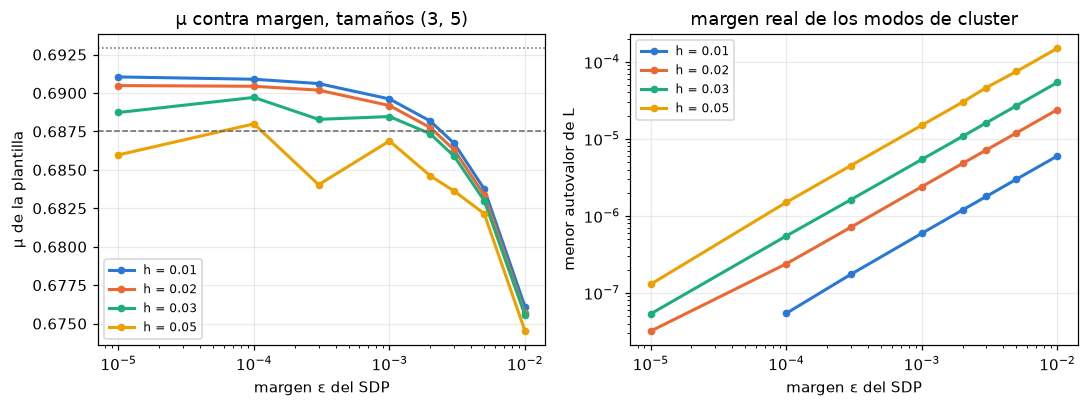

In [38]:
if existe_resultado("s7_curva.json"):
    ARCHIVO_CURVA = "s7_curva.json"
elif CORRER["curva"]:
    correr_paso("curva.py", f"--procesos {PROCESOS}", "curva (completa)")
    ARCHIVO_CURVA = "s7_curva.json"
else:
    print("versión reducida (para la completa: CORRER['curva'] = True o correr el script afuera)")
    ARCHIVO_CURVA = "s7_curva_reducida.json"
    if not existe_resultado(ARCHIVO_CURVA):
        correr_paso("curva.py", f"--reducido --procesos {PROCESOS}", "curva (reducida)")
curva = cargar_json(ARCHIVO_CURVA)

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.8))
hs_curva = sorted({f["h"] for f in curva if f["h"] >= 0.01})
for color, h in zip(COLORES, hs_curva):
    filas = sorted([f for f in curva if f["h"] == h and tuple(f["k"]) == (3, 5)], key=lambda f: f["margen"])
    ejes[0].plot([f["margen"] for f in filas], [f["mu"] for f in filas], "o-", color=color, lw=2, ms=4,
                 label=f"h = {h}")
    positivos = [f for f in filas if f["autovalores"][0] > 0]     # con ε muy chico el SDP puede dar ≤ 0 (ruido)
    ejes[1].plot([f["margen"] for f in positivos], [f["autovalores"][0] for f in positivos], "o-", color=color,
                 lw=2, ms=4, label=f"h = {h}")
ejes[0].axhline(11 / 16, color="0.4", lw=1, ls="--")
ejes[0].text(ejes[0].get_xlim()[0] * 1.2, 11 / 16 + 3e-4, "11/16", color="0.3", fontsize=8)
ejes[0].axhline(float(mu_cero), color="0.4", lw=1, ls=":")
ejes[0].text(ejes[0].get_xlim()[0] * 1.2, float(mu_cero) - 9e-4, "μ0 (O'Keeffe)", color="0.3", fontsize=8)
ejes[0].set(xscale="log", xlabel="margen ε del SDP", ylabel="μ de la plantilla", title="μ contra margen, tamaños (3, 5)")
ejes[1].set(xscale="log", yscale="log", xlabel="margen ε del SDP", ylabel="menor autovalor de L",
            title="margen real de los modos de cluster")
for eje in ejes:
    eje.grid(alpha=0.25)
    eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura.**
- $\mu$ baja al subir el margen $\varepsilon$, y baja más rápido cuanto más grande es $h$. La curva
  completa es algo ruidosa porque Nelder–Mead no siempre encuentra el óptimo en $s$ (sobre todo con
  $h = 0.05$).
- El menor autovalor de $L$ crece como $\sim \varepsilon h^2$.
- Hay una ventana con $\mu > 11/16$ y margen apreciable. La plantilla elegida ($h = 0.03$,
  $\varepsilon = 10^{-3}$) tiene $\mu \approx 0.6885$, entre $11/16 = 0.6875$ y $\mu_0 = 0.6929$. Ahí
  $h$ es 30 veces más grande que $\varepsilon$: el margen lo aporta la apertura de los pares, sin
  necesidad de un $t$.

### 6.4 La plantilla elegida

`reporte_plantilla` resume una plantilla: $\mu$, $\max|F|$, $\min c$, los autovalores normalizados de
$L$ y los valores singulares del Jacobiano $J$. Tomamos la fila de la curva y comprobamos que el SDP,
corrido de nuevo con esos $s$, da el mismo $\mu$.

In [39]:
# biblioteca
def reporte_plantilla(x, phi, P):
    """μ, max|F|, min c, autovalores de X^{-1/2} L X^{-1/2} (sin la rotación) y valores singulares de J."""
    x = np.asarray(x, dtype=float)
    phi = np.asarray(phi, dtype=float)
    P = np.asarray(P, dtype=float)
    raiz = 1 / np.sqrt(x)
    M = raiz[:, None] * np.array(matriz_clusters(x, phi, P)) * raiz[None, :]
    autovalores = np.linalg.eigvalsh(M)
    rotacion = int(np.argmin(np.abs(autovalores)))
    return {
        "mu": float((P @ x).min()),
        "max|F|": float(np.abs(fuerzas(x, phi, P)).max()),
        "min c": float(min(splitting(x, phi, P))),
        "autovalores L": np.delete(autovalores, rotacion),
        "singulares J": np.linalg.svd(np.array(jacobiano_fuerzas(x, phi, P)), compute_uv=False),
    }


def fila_curva(curva, h, margen, k=(3, 5)):
    """Fila de la curva con esos parámetros."""
    for fila in curva:
        if fila["h"] == h and fila["margen"] == margen and tuple(fila["k"]) == tuple(k):
            return fila
    raise KeyError((h, margen, k))

μ (SDP corrido de nuevo): 0.688469
μ (plantilla de la curva): 0.688469
max |F|: 1.5e-11
min c: 0.2179
autovalores de L (los 3 menores): 5.40e-06  6.90e-06  7.51e-04
valores singulares de J: 2.61e-01  2.61e-01  1.29e-01  5.95e-04  5.29e-06  2.34e-06


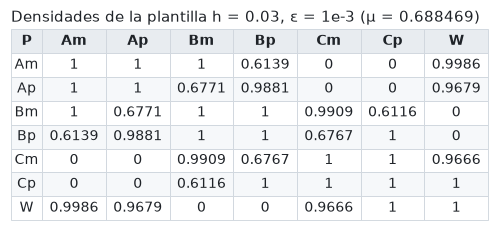

In [40]:
H_PLANTILLA = 0.03
plantilla = fila_curva(curva, H_PLANTILLA, 1e-3)
phi_plantilla = fases_s7(H_PLANTILLA, np.array(plantilla["s"]))
P_plantilla = np.array(plantilla["P"])
mu_sdp, _ = mejor_P(x_plantilla, H_PLANTILLA, np.array(plantilla["s"]), 1e-3)
reporte = reporte_plantilla(x_plantilla, phi_plantilla, P_plantilla)

print("μ (SDP corrido de nuevo):", f"{mu_sdp:.6f}")
print("μ (plantilla de la curva):", f"{reporte['mu']:.6f}")
print("max |F|:", f"{reporte['max|F|']:.1e}")
print("min c:", f"{reporte['min c']:.4f}")
print("autovalores de L (los 3 menores):", "  ".join(f"{v:.2e}" for v in reporte["autovalores L"][:3]))
print("valores singulares de J:", "  ".join(f"{v:.2e}" for v in reporte["singulares J"]))

filas = []
for a, nombre in enumerate(NOMBRES):
    fila = [nombre]
    for b in range(7):
        valor = P_plantilla[a, b]
        fila.append("1" if valor > 1 - 1e-7 else "0" if valor < 1e-7 else f"{valor:.4f}")
    filas.append(fila)
mostrar_tabla(["P"] + NOMBRES, filas, titulo=f"Densidades de la plantilla h = 0.03, ε = 1e-3 (μ = {reporte['mu']:.6f})")

- **$\mu \approx 0.6885$:** entre $11/16$ y $\mu_0$.
- **$\max|F| \ne 0$:** el SDP no da un equilibrio exacto, sino uno con error del orden de la tolerancia
  del solver. En la sección 7 se corrige.
- **Valores singulares de $J$:** hay **tres** chicos (del orden de $10^{-3}$ a $10^{-6}$); los demás son
  $\gtrsim 0.1$. Son los modos casi neutros heredados de C4, y van a decidir el tamaño del grafo.
- **Las densidades:** además de los cuatro pares cruzados (cerca de 0.61–0.68), algunos pares vecinos
  que en el patrón límite valen 1 bajan un poco. No es un error: O'Keeffe hace lo mismo con su $p'$
  (sección 12).

## 7. Fase 1: pasar a enteros sin perder el equilibrio

### 7.1 Datos enteros

Un grafo concreto se describe con:
- **tamaños** $n_a = k_a g$: seis mitades de $3g$ vértices y W de $5g$, así que $n = 23g$;
- **grados** $d_{ab}$: cuántos vecinos tiene **cada** vértice de $a$ en $b$.

Hay dos restricciones:
- contar las aristas entre $a$ y $b$ desde los dos lados da $n_a d_{ab} = n_b d_{ba}$, así que $d_{ab}$
  tiene que ser múltiplo de $k_b/\mathrm{mcd}(k_a, k_b)$ (1 entre dos mitades, 5 entre una mitad y W);
- cada cluster es un clique: $d_{aa} = n_a - 1$.

La plantilla del grafo es $x_a = n_a/n$, $P_{ab} = d_{ab}/n_b$, y $\mu = (\delta+1)/n$ con
$\delta = \min_a \sum_b d_{ab}$. Hay **un entero por par** $a < b$: de los 21 pares, 6 son opuestos
(vacíos), y los que la plantilla deja en 0 o en 1 quedan fijos. Los demás, con $0 < P_{ab} < 1$, son
los **libres** (`pares_libres`).

**El redondeo ingenuo** toma $d_{ab}$ igual al múltiplo permitido más cercano a $P_{ab} n_b$. Cada
densidad cambia en $\sim 1/n$.

**El código:** tamaños, el paso permitido, el redondeo ingenuo, la plantilla exacta de los datos
enteros (con fracciones, `Fraction`) y el $\mu$ exacto.

In [41]:
# biblioteca
def tamanos_exactos(k):
    """x_a = k_a/K como Fraction."""
    K = sum(int(ka) for ka in k)
    return [Fraction(int(ka), K) for ka in k]


def tamanos_enteros(k, g):
    """n_a = k_a·g."""
    return [int(ka) * g for ka in k]


def paso_grado(k, a, b):
    """d_ab tiene que ser múltiplo de k_b/mcd(k_a, k_b) para que n_a d_ab = n_b d_ba."""
    return int(k[b]) // gcd(int(k[a]), int(k[b]))


def grados_ingenuos(x, P, k, g):
    """Redondea P_ab·n_b al múltiplo permitido más cercano (para a < b) y completa por simetría."""
    m = len(k)
    n_a = tamanos_enteros(k, g)
    d = [[0] * m for _ in range(m)]
    for a in range(m):
        d[a][a] = n_a[a] - 1
        for b in range(a + 1, m):
            paso = paso_grado(k, a, b)
            j = int(mp.nint(P[a][b] * n_a[b] / paso))
            j = max(0, min(j, n_a[b] // paso))
            d[a][b] = j * paso
            d[b][a] = d[a][b] * n_a[a] // n_a[b]
    return d


def plantilla_entera(k, g, d):
    """(x, P) exactos como Fraction: x_a = n_a/n, P_ab = d_ab/n_b (con P_aa = (n_a − 1)/n_a)."""
    n_a = tamanos_enteros(k, g)
    n = sum(n_a)
    x = [Fraction(na, n) for na in n_a]
    P = []
    for a in range(len(k)):
        fila = []
        for b in range(len(k)):
            fila.append(Fraction(d[a][b], n_a[b]))
        P.append(fila)
    return x, P


def mu_entero(k, g, d):
    """μ = (δ + 1)/n exacto, con δ el grado mínimo."""
    n_a = tamanos_enteros(k, g)
    n = sum(n_a)
    grados = []
    for fila in d:
        grados.append(sum(fila))
    return Fraction(min(grados) + 1, n)

### 7.2 Pulir y evaluar

Antes de redondear hay que **pulir** la plantilla: el SDP deja $F \approx 10^{-9}$, y como el Jacobiano
del equilibrio es casi singular, ese error movería las fases mucho más que el redondeo. $F$ es lineal
en $P$, así que se corrige con el cambio de **menor norma** en los pares libres que hace $F = 0$ exacto
(mínimos cuadrados, con 60 dígitos).

Después de redondear hay que **evaluar** los datos enteros, en alta precisión:
1. resolver el equilibrio exacto por Newton desde las fases de la plantilla;
2. pedir $\lambda_{\min}(L) > 0$, $\min c > 0$ y $\max|F| < 10^{-20}$;
3. pedir que las fases no se hayan alejado más de $h/4$ de las de la plantilla: si el redondeo destruye
   el equilibrio, Newton puede encontrar **otro** equilibrio lejos, que no es el que queremos.

In [42]:
# biblioteca
def _a_mp(valor):
    """Fraction o float → mpf (exacto para Fraction)."""
    if isinstance(valor, Fraction):
        return mp.mpf(valor.numerator) / valor.denominator
    return mp.mpf(float(valor))


def pares_libres(P, tolerancia=1e-7):
    """Pares a < b con densidad estrictamente entre 0 y 1 (los demás son vacíos o completos)."""
    m = len(P)
    pares = []
    for a in range(m):
        for b in range(a + 1, m):
            if tolerancia < float(P[a][b]) < 1 - tolerancia:
                pares.append((a, b))
    return pares


def _ajustar_extremo(valor, tolerancia=1e-7):
    """Lleva a 0 o 1 exactos las densidades que el SDP dejó a menos de tolerancia de un extremo."""
    valor = float(valor)
    if valor < tolerancia:
        return mp.mpf(0)
    if valor > 1 - tolerancia:
        return mp.mpf(1)
    return mp.mpf(valor)


def pulir(x, phi, P, dps=60):
    """Corrige P con el menor cambio (mínima norma) para que F(φ) = 0 exacto en alta precisión.

    El SDP deja F ≈ 1e-9, y como el Jacobiano del equilibrio es casi singular eso movería las fases
    mucho más que el redondeo. F es lineal en P, así que basta un problema de mínimos cuadrados.
    Solo se tocan los pares a < b con 0 < P_ab < 1 (los completos y vacíos quedan fijos).
    """
    m = len(x)
    with mp.workdps(dps):
        pares = pares_libres(P)
        x_mp = [_a_mp(v) for v in x]
        phi_mp = [mp.mpf(float(v)) for v in phi]
        P_mp = []
        for fila in P:
            P_mp.append([_ajustar_extremo(v) for v in fila])
        # La ecuación del último cluster sobra: se deduce de Σ x_a F_a ≡ 0.
        A = mp.matrix(m - 1, len(pares))
        for j, (a, b) in enumerate(pares):
            seno = mp.sin(phi_mp[a] - phi_mp[b])
            if a < m - 1:
                A[a, j] = x_mp[b] * seno
            if b < m - 1:
                A[b, j] = -x_mp[a] * seno
        F = mp.matrix(m - 1, 1)
        for a in range(m - 1):
            for b in range(m):
                if b != a:
                    F[a] += P_mp[a][b] * x_mp[b] * mp.sin(phi_mp[a] - phi_mp[b])
        delta = A.T * mp.lu_solve(A * A.T, -F)
        for j, (a, b) in enumerate(pares):
            P_mp[a][b] += delta[j]
            P_mp[b][a] = P_mp[a][b]
        return x_mp, phi_mp, P_mp


def evaluar_enteros(k, g, d, phi0, h, dps=40, phi_referencia=None):
    """Resuelve el equilibrio exacto de los datos enteros y mira si es estricto (en alta precisión).

    Devuelve un dict con ok, el menor autovalor de L, min c y cuánto se movieron las fases. Se exige
    además que las fases no se alejen más de h/4 de phi_referencia (por defecto φ0), para seguir en
    la forma de S7.
    """
    if phi_referencia is None:
        phi_referencia = phi0
    x, P = plantilla_entera(k, g, d)
    try:
        phi = fases_newton(x, P, list(phi0), dps=dps)
    except ZeroDivisionError:
        return {"ok": False, "menor autovalor": -np.inf, "min c": np.nan, "movimiento fases": np.inf, "phi": None}
    with mp.workdps(dps):
        x_mp = [mp.mpf(v.numerator) / v.denominator for v in x]
        P_mp = []
        for fila in P:
            P_mp.append([mp.mpf(v.numerator) / v.denominator for v in fila])
        reporte = analizar(x_mp, phi, P_mp, lib=mp, dps=dps)
        movimiento = max(abs(a - b) for a, b in zip(phi, phi_referencia))
    menor = float(min(reporte["autovalores L"]))
    min_c = float(reporte["min c"])
    max_F = float(reporte["max|F|"])
    ok = menor > 0 and min_c > 0 and max_F < 1e-20 and float(movimiento) < h / 4
    return {"ok": ok, "menor autovalor": menor, "min c": min_c, "movimiento fases": float(movimiento),
            "phi": [float(p) for p in phi]}


def n_minimo_ingenuo(x, P, phi, h, k, exponentes=None):
    """Menor n de la grilla a partir del cual el redondeo ingenuo es estricto en todos los n mayores."""
    if exponentes is None:
        exponentes = np.arange(3, 16.01, 0.5)
    K = int(sum(k))
    resultados = []
    for e in exponentes:
        g = max(1, int(round(10**e / K)))
        d = grados_ingenuos(x, P, k, g)
        evaluacion = evaluar_enteros(k, g, d, phi, h)
        resultados.append((K * g, evaluacion["ok"]))
    n_min = None
    for n, ok in reversed(resultados):
        if not ok:
            break
        n_min = n
    return n_min, resultados

Probamos el redondeo ingenuo de la plantilla $h = 0.03$ con $n = 3\cdot10^7$ y con $n = 10^9$:

max |F| después de pulir: 2.29e-62
pares libres: Am–Bp, Am–W, Ap–Bm, Ap–Bp, Ap–W, Bm–Cm, Bm–Cp, Bp–Cm, Cm–W


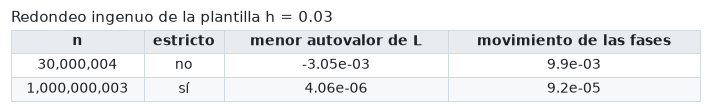

In [43]:
x_exacto, phi_pulida, P_pulida = pulir(tamanos_exactos(K_S7), phi_plantilla, P_plantilla)
print("max |F| después de pulir:", mp.nstr(max(abs(v) for v in fuerzas(x_exacto, phi_pulida, P_pulida, mp)), 3))
print("pares libres:", ", ".join(f"{NOMBRES[a]}–{NOMBRES[b]}" for a, b in pares_libres(P_pulida)))

filas = []
for n_objetivo in [3e7, 1e9]:
    g = int(round(n_objetivo / sum(K_S7)))
    d = grados_ingenuos(x_exacto, P_pulida, K_S7, g)
    evaluacion = evaluar_enteros(K_S7, g, d, phi_pulida, H_PLANTILLA)
    filas.append([f"{sum(K_S7) * g:,}", si_no(evaluacion["ok"]), f"{evaluacion['menor autovalor']:.2e}",
                  f"{evaluacion['movimiento fases']:.1e}"])
mostrar_tabla(["n", "estricto", "menor autovalor de L", "movimiento de las fases"], filas,
              titulo="Redondeo ingenuo de la plantilla h = 0.03")

Con $n = 3\cdot10^7$ el redondeo ingenuo da un equilibrio **inestable** (autovalor negativo de $L$); con
$n = 10^9$ funciona. ¿Por qué hace falta un $n$ tan grande?

### 7.3 El pliegue

El Jacobiano $J$ del equilibrio tiene tres valores singulares $\sigma_k$ diminutos (sección 6.4): hay
tres direcciones **blandas** en las que el equilibrio casi no está sostenido. Son la herencia de los
modos neutros de C4.

Una imagen: el equilibrio es una bolita en un pozo muy poco profundo. Si se inclina un poco la mesa (el
error de redondeo), el pozo desaparece. En fórmulas, en cada dirección blanda el equilibrio de los
datos perturbados es raíz de
$$\sigma_k\, y + \tfrac{c}{2}\, y^2 + \rho_k = 0,$$
donde $y$ es cuánto se mueven las fases en esa dirección y $\rho_k$ es el error del redondeo en esa
ecuación. Es la forma normal de un **pliegue** (o silla-nodo): un equilibrio estable y uno inestable que
se acercan, se juntan y desaparecen.
- Hay solución solo si $2c\rho_k \le \sigma_k^2$, y su estabilidad es $\sqrt{\sigma_k^2 - 2c\rho_k}$:
  baja a 0 al llegar al pliegue.
- Si el redondeo pasa el pliegue, el equilibrio **desaparece**: Newton no converge o las fases saltan a
  otro estado.
- Con el redondeo ingenuo $\rho_k \sim 1/n$, así que hace falta $n \gtrsim c/\sigma_k^2$. Para esta
  plantilla, $n \approx 10^9$.

**Qué errores absorben las fases y cuáles no.** Separando el error en las direcciones de la SVD de $J$:
en las direcciones **rígidas** ($\sigma \gtrsim 0.1$) la tolerancia es enorme frente a $1/n$ y las
fases absorben el error sin problemas; en las **blandas** la tolerancia es diminuta, y el error ahí
hay que eliminarlo eligiendo bien los grados.

### 7.4 Lyapunov–Schmidt: medir solo lo que importa

Para elegir los grados hace falta medir "cuánto error queda en las direcciones blandas". La reducción
de **Lyapunov–Schmidt** separa lo fácil de lo difícil, con $J = U S V^\top$ en la plantilla:
1. se deja que las fases se muevan **solo en las direcciones rígidas**, $\varphi = \varphi^* + V_r z$,
   hasta que las ecuaciones rígidas $U_r^\top F = 0$ se cumplen exactamente (Newton común, que ahí
   converge);
2. lo que queda en las direcciones blandas es el **residuo blando** $g = U_b^\top F$: tres números.

$g$ solo depende de los grados, está bien definido aunque no haya equilibrio y es casi lineal en los
grados. El objetivo queda: **elegir los grados enteros para que cada $|g_k|$ quede bien por debajo de su
tolerancia $\sim\sigma_k^2$.**

### 7.5 Newton entero y el reticulado

Cerca del redondeo ingenuo, $g(d + u) \approx g(d) + G\,u$, con $G = \partial g/\partial d$ (3 filas, una
columna por grado libre). Newton común pediría $G u = -g$; con más incógnitas que ecuaciones hay
infinitas soluciones reales, y la de menor norma es $u_0$. Pero $u$ tiene que ser **entero**, y
redondear $u_0$ coordenada a coordenada no sirve: cada coordenada se mueve hasta $\pm1/2$ y el error
vuelve a ser del tamaño del redondeo ingenuo.

**La idea clave: elegir los enteros en conjunto.** Por ejemplo, buscar enteros con
$u_1 + \sqrt2\,u_2 \approx -0.3$. Con $|u_i| \le 1$ lo mejor es $(1, -1)$, con error 0.11; con
$|u_i| \le 10$ aparece $(11, -8)$: $11 - 11.314 = -0.314$, error 0.014. Cuanto más se dejan mover los
enteros, más combinaciones hay y alguna cae muy cerca. A cambio, un $u$ grande rompe la linealización:
por eso se prueban varios radios (3, 10, 30, 100), se repite el paso unas pocas veces, y la decisión
final la toma la evaluación exacta.

Encontrar "el $u$ entero cerca de $u_0$ con $G(u - u_0) \approx 0$" es un problema de **vector más
cercano en un reticulado**. Un reticulado es el conjunto de combinaciones con coeficientes enteros de
unos vectores base, como $\mathbb Z^2$ pero posiblemente inclinado y estirado.
- **Encaje de Kannan:** a cada entero $u$ se le asigna el vector $v(u) = (u/r,\ \text{peso}\cdot Gu)$, y
  al objetivo $v(u_0)$. Entonces
  $|v(u) - v(u_0)|^2 = |u - u_0|^2/r^2 + \text{peso}^2\,|G(u - u_0)|^2$: un $u$ con esa distancia chica
  no se aleja **y** cancela el residuo. Los $v(u)$ forman un reticulado (sus vectores base son las filas
  de la matriz `B` del código), así que el problema es "el punto del reticulado más cercano a un
  objetivo".
- **LLL** (Lenstra–Lenstra–Lovász): un mismo reticulado tiene muchas bases, y con una mala base
  redondear da cualquier cosa. Por ejemplo, $(1,0)$ y $(100,1)$ generan $\mathbb Z^2$; en esa base el
  punto $(0.4, 0.4)$ es $-39.6\,b_1 + 0.4\,b_2$, y redondeando los coeficientes queda $(-40, 0)$, a
  distancia 40. LLL transforma una base en otra del mismo reticulado con vectores cortos y casi
  perpendiculares, restando múltiplos enteros e intercambiando vectores.
- **Plano más cercano de Babai:** con la base reducida, ortogonaliza (Gram–Schmidt) y redondea el
  coeficiente de cada dirección, de la última a la primera, restando lo ya elegido. No garantiza el
  óptimo exacto, pero con una base LLL queda cerca.

In [44]:
# biblioteca
def gram_schmidt(B):
    """Ortogonalización sin normalizar: (B*, μ) con B_i = B*_i + Σ_{j<i} μ_ij B*_j."""
    n = B.shape[0]
    ortogonales = np.zeros_like(B)
    mu = np.zeros((n, n))
    for i in range(n):
        vector = B[i].copy()
        for j in range(i):
            mu[i, j] = B[i] @ ortogonales[j] / (ortogonales[j] @ ortogonales[j])
            vector -= mu[i, j] * ortogonales[j]
        ortogonales[i] = vector
    return ortogonales, mu


def lll(B, delta=0.99):
    """Base LLL-reducida del reticulado generado por las filas de B."""
    B = np.array(B, dtype=float)
    n = B.shape[0]
    ortogonales, mu = gram_schmidt(B)
    k = 1
    while k < n:
        for j in range(k - 1, -1, -1):
            q = round(mu[k, j])
            if q != 0:
                B[k] -= q * B[j]
                ortogonales, mu = gram_schmidt(B)
        lovasz = (delta - mu[k, k - 1] ** 2) * (ortogonales[k - 1] @ ortogonales[k - 1])
        if ortogonales[k] @ ortogonales[k] >= lovasz:
            k += 1
        else:
            B[[k, k - 1]] = B[[k - 1, k]]
            ortogonales, mu = gram_schmidt(B)
            k = max(k - 1, 1)
    return B


def babai(B, objetivo):
    """Coeficientes enteros c tales que c·B está cerca de objetivo (plano más cercano de Babai).

    Conviene pasar una base LLL-reducida: así el error queda acotado por la base.
    """
    ortogonales, _ = gram_schmidt(B)
    resto = np.array(objetivo, dtype=float)
    coeficientes = np.zeros(B.shape[0])
    for i in range(B.shape[0] - 1, -1, -1):
        c = round(resto @ ortogonales[i] / (ortogonales[i] @ ortogonales[i]))
        resto -= c * B[i]
        coeficientes[i] = c
    return coeficientes


def enteros_cercanos(formas, objetivo, radio, peso=1e3):
    """u ∈ Z^m con |u − objetivo| del orden de radio y formas·(u − objetivo) ≈ 0.

    Encaje de Kannan: el reticulado tiene filas (e_i/radio, peso·formas[:, i]). Las formas se escalan
    todas por el mismo factor (máximo 1), así que el que llama decide cuánto pesa cada una.
    """
    formas = np.asarray(formas, dtype=float)
    formas = formas / max(np.abs(formas).max(), 1e-300)
    m = formas.shape[1]
    factor = peso * radio
    B = np.hstack([np.eye(m) / radio, factor * formas.T])
    objetivo = np.asarray(objetivo, dtype=float)
    vector_objetivo = np.concatenate([objetivo / radio, factor * formas @ objetivo])
    reducida = lll(B)
    coeficientes = babai(reducida, vector_objetivo)
    return np.round((coeficientes @ reducida)[:m] * radio)

**Un ejemplo de juguete** con el mismo tamaño que nuestro problema: 3 formas lineales al azar sobre
$\mathbb Z^9$ y un objetivo real al azar. Comparamos redondear cada coordenada por separado (lo que hace
el redondeo ingenuo) con `enteros_cercanos`. Lo que importa es $|A(u - u_0)|$, que en el problema real
es el residuo blando:

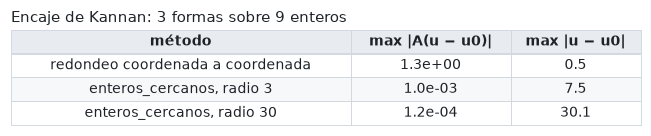

In [45]:
rng = np.random.default_rng(0)
A_juguete = rng.standard_normal((3, 9))
objetivo_juguete = rng.uniform(-50, 50, 9)
filas = []
for nombre, u in [("redondeo coordenada a coordenada", np.round(objetivo_juguete)),
                  ("enteros_cercanos, radio 3", enteros_cercanos(A_juguete, objetivo_juguete, 3)),
                  ("enteros_cercanos, radio 30", enteros_cercanos(A_juguete, objetivo_juguete, 30))]:
    filas.append([nombre, f"{np.abs(A_juguete @ (u - objetivo_juguete)).max():.1e}",
                  f"{np.abs(u - objetivo_juguete).max():.1f}"])
mostrar_tabla(["método", "max |A(u − u0)|", "max |u − u0|"], filas, titulo="Encaje de Kannan: 3 formas sobre 9 enteros")

Redondear coordenada a coordenada deja $|A(u - u_0)| \sim 1$. El reticulado lo baja varios órdenes de
magnitud a cambio de alejarse un poco más del objetivo, y cuanto más grande el radio, más chico el
residuo. En el problema real, eso es lo que permite esquivar el pliegue.

**El ciclo completo** (`redondeo_reticulado`): SVD de $J$ en la plantilla separando las 3 direcciones
blandas; tolerancias $\sigma_k^2$; arranque en el redondeo ingenuo; para cada radio, cuatro pasos de
Newton entero (residuo blando y su derivada por diferencias finitas con 60 dígitos, y
`corregir_grados`, que mide cada componente de $g$ en unidades de su tolerancia y llama a
`enteros_cercanos`); cada candidato se evalúa en exacto y se guarda el mejor.

In [46]:
# biblioteca
def base_blanda(x, P, phi, cantidad=2):
    """Vectores singulares de J en la plantilla: (U_blando, U_rígido, V_blando, V_rígido) en float."""
    J = np.array(jacobiano_fuerzas([float(v) for v in x], [float(v) for v in phi], np.array(P, dtype=float)))
    U, singulares, Vt = np.linalg.svd(J)
    corte = J.shape[0] - cantidad
    return {"U_blando": U[:, corte:], "U_rigido": U[:, :corte],
            "V_blando": Vt[corte:].T, "V_rigido": Vt[:corte].T, "singulares": singulares[corte:]}


def _fuerzas_vector(x, phi, P):
    """F_1..F_{m−1} como mp.matrix (F_0 se deduce de Σ x_a F_a ≡ 0)."""
    return mp.matrix(fuerzas(x, phi, P, mp)[1:])


def _mover(phi_referencia, V, z):
    """φ = φ_ref + V z en las coordenadas 1..m−1 (φ_0 queda fijo)."""
    phi = list(phi_referencia)
    for a in range(1, len(phi)):
        for j in range(V.cols):
            phi[a] += V[a - 1, j] * z[j]
    return phi


def residuo_blando(x, P, phi_referencia, base, dps=60, iteraciones=30):
    """Resuelve las ecuaciones rígidas U_rᵀ F(φ_ref + V_r z) = 0 y devuelve (g, φ) con g = U_bᵀ F."""
    with mp.workdps(dps):
        U_r = mp.matrix(base["U_rigido"].tolist())
        U_b = mp.matrix(base["U_blando"].tolist())
        V_r = mp.matrix(base["V_rigido"].tolist())
        z = mp.matrix(V_r.cols, 1)
        tolerancia = mp.mpf(10) ** (-dps + 10)
        for _ in range(iteraciones):
            phi = _mover(phi_referencia, V_r, z)
            rigidas = U_r.T * _fuerzas_vector(x, phi, P)
            if mp.norm(rigidas) < tolerancia:
                break
            J = mp.matrix(jacobiano_fuerzas(x, phi, P, mp))
            z = z - mp.lu_solve(U_r.T * J * V_r, rigidas)
        phi = _mover(phi_referencia, V_r, z)
        g = U_b.T * _fuerzas_vector(x, phi, P)
        return [g[i] for i in range(g.rows)], phi


def derivada_residuo(x, P, phi_referencia, base, pares, dps=60):
    """(g, dg/dP_ab) por diferencias finitas en alta precisión: vector y matriz (blandos × pares)."""
    with mp.workdps(dps):
        g, phi = residuo_blando(x, P, phi_referencia, base, dps)
        delta = mp.mpf(10) ** (-(dps // 2 - 5))
        columnas = []
        for a, b in pares:
            P_movida = [fila[:] for fila in P]
            P_movida[a][b] += delta
            P_movida[b][a] += delta
            g_movida, _ = residuo_blando(x, P_movida, phi_referencia, base, dps)
            columna = []
            for v_movido, v in zip(g_movida, g):
                columna.append(float((v_movido - v) / delta))
            columnas.append(columna)
        return np.array([float(v) for v in g]), np.array(columnas).T, phi


def densidades_enteras(d, k, g, dps=60):
    """P_ab = d_ab/n_b en mpmath."""
    n_a = tamanos_enteros(k, g)
    P = []
    with mp.workdps(dps):
        for a in range(len(k)):
            fila = []
            for b in range(len(k)):
                fila.append(mp.mpf(d[a][b]) / n_a[b])
            P.append(fila)
    return P


def corregir_grados(d, k, g, pares, residuo, derivada, radio, tolerancias):
    """Un paso de Newton entero: grados cuyo cambio anula (en lo posible) el residuo blando.

    Cada componente del residuo se mide en unidades de su tolerancia (la distancia al pliegue, ~σ_k²).
    """
    n_a = tamanos_enteros(k, g)
    pasos = []
    actuales = []
    escalas = []
    for a, b in pares:
        paso = paso_grado(k, a, b)
        pasos.append(paso)
        actuales.append(d[a][b] // paso)
        escalas.append(paso / n_a[b])
    pesos = 1 / np.asarray(tolerancias)
    formas = pesos[:, None] * derivada * np.array(escalas)[None, :]
    objetivo = np.linalg.lstsq(formas, -pesos * residuo, rcond=None)[0]
    u = enteros_cercanos(formas, objetivo, radio)
    nuevos = [fila[:] for fila in d]
    for i, (a, b) in enumerate(pares):
        j = max(0, min(actuales[i] + int(u[i]), n_a[b] // pasos[i]))
        nuevos[a][b] = j * pasos[i]
        nuevos[b][a] = nuevos[a][b] * n_a[a] // n_a[b]
    return nuevos


def _mejor(candidato, actual):
    """¿La evaluación candidato es mejor que actual? (primero estricta, después mayor autovalor)."""
    if actual is None:
        return True
    return (candidato["ok"], candidato["menor autovalor"]) > (actual["ok"], actual["menor autovalor"])


def redondeo_reticulado(x, P, phi, h, k, g, radios=(3, 10, 30, 100), iteraciones=4, cantidad=3):
    """Grados enteros que mantienen la estrictez: Newton entero sobre el residuo blando.

    Arranca del redondeo ingenuo; en cada paso calcula el residuo blando de los datos enteros y su
    derivada, y elige con enteros_cercanos la corrección que lo anula. Evalúa en exacto partiendo de
    las fases de la reducción (donde Newton sí converge) y se queda con la mejor evaluación.
    Devuelve (d, evaluación).
    """
    pares = pares_libres(P)
    base = base_blanda(x, P, phi, cantidad)
    tolerancias = base["singulares"] ** 2
    x_entero = [_a_mp(v) for v in tamanos_exactos(k)]
    inicial = grados_ingenuos(x, P, k, g)
    mejor_d = inicial
    mejor_evaluacion = evaluar_enteros(k, g, inicial, phi, h)
    for radio in radios:
        d = inicial
        for _ in range(iteraciones):
            residuo, derivada, _ = derivada_residuo(x_entero, densidades_enteras(d, k, g), phi, base, pares)
            d = corregir_grados(d, k, g, pares, residuo, derivada, radio, tolerancias)
            _, phi_reducida = residuo_blando(x_entero, densidades_enteras(d, k, g), phi, base)
            evaluacion = evaluar_enteros(k, g, d, phi_reducida, h, phi_referencia=phi)
            if _mejor(evaluacion, mejor_evaluacion):
                mejor_d = d
                mejor_evaluacion = evaluacion
    return mejor_d, mejor_evaluacion

Lo corremos para el mismo caso de arriba ($h = 0.03$, $n = 3\cdot10^7$). Tarda unos segundos:

n: 30,000,004
estricto: sí
menor autovalor de L: 5.25e-06
μ exacto: 10327019/15000002 ≈ 0.688468
tiempo: 2.7 s


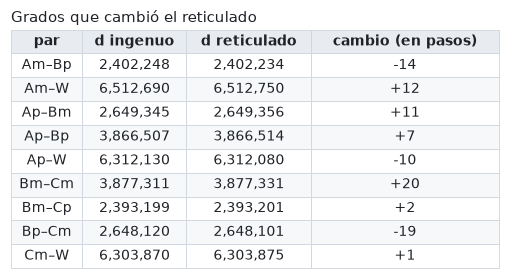

In [47]:
g_chico = int(round(3e7 / sum(K_S7)))
inicio = time.time()
d_reticulado, evaluacion = redondeo_reticulado(x_exacto, P_pulida, phi_pulida, H_PLANTILLA, K_S7, g_chico)
mu_reticulado = mu_entero(K_S7, g_chico, d_reticulado)
print("n:", f"{sum(K_S7) * g_chico:,}")
print("estricto:", si_no(evaluacion["ok"]))
print("menor autovalor de L:", f"{evaluacion['menor autovalor']:.2e}")
print("μ exacto:", f"{mu_reticulado} ≈ {float(mu_reticulado):.6f}")
print(f"tiempo: {time.time() - inicio:.1f} s")

d_ingenuo = grados_ingenuos(x_exacto, P_pulida, K_S7, g_chico)
filas = []
for a in range(7):
    for b in range(a + 1, 7):
        if d_reticulado[a][b] != d_ingenuo[a][b]:
            cambio = (d_reticulado[a][b] - d_ingenuo[a][b]) // paso_grado(K_S7, a, b)
            filas.append([f"{NOMBRES[a]}–{NOMBRES[b]}", f"{d_ingenuo[a][b]:,}", f"{d_reticulado[a][b]:,}", f"{cambio:+d}"])
mostrar_tabla(["par", "d ingenuo", "d reticulado", "cambio (en pasos)"], filas, titulo="Grados que cambió el reticulado")

Bastan cambios de unas pocas unidades en algunos grados, de un total de $\sim10^7$, para que el
equilibrio pase de inestable a estricto.

### 7.6 La grilla en $n$

`un_n` (de `scripts/s7_entero.py`) hace esto para una plantilla y un $n$: pule, prueba el redondeo
ingenuo y el reticulado, y guarda los grados y las fases. El script recorre tres plantillas
($h = 0.03, 0.02, 0.01$ con $\varepsilon = 10^{-3}$) y $n$ de $10^6$ a $10^9$, en paralelo. Corre en
vivo: unos 4 minutos de CPU en total.

In [48]:
# biblioteca
def plantilla_de_la_curva(curva, h, margen, tamanos):
    """Fila de data/s7_curva.json para (h, ε, tamaños)."""
    for fila in curva:
        if fila["h"] == h and fila["margen"] == margen and tuple(fila["k"]) == tamanos:
            return fila
    raise KeyError(f"no está en s7_curva.json: h = {h}, ε = {margen}, k = {tamanos}")


def un_n(trabajo):
    """Redondeo ingenuo y por reticulado para un candidato y un n."""
    fila, n = trabajo
    inicio = time.time()
    h = fila["h"]
    k_mitad, k_w = fila["k"]
    k = [k_mitad] * 6 + [k_w]
    g = int(round(n / sum(k)))
    phi = fases_s7(h, np.array(fila["s"]))
    x, phi, P = pulir(tamanos_exactos(k), phi, np.array(fila["P"]))
    ingenuo = evaluar_enteros(k, g, grados_ingenuos(x, P, k, g), phi, h)
    d, reticulado = redondeo_reticulado(x, P, phi, h, k, g)
    mu = mu_entero(k, g, d)
    return {
        "h": h, "margen": fila["margen"], "k": fila["k"], "mu_plantilla": fila["mu"],
        "n": g * sum(k), "g": g,
        "ingenuo_ok": ingenuo["ok"],
        "reticulado_ok": reticulado["ok"],
        "menor_autovalor": reticulado["menor autovalor"],
        "mu": float(mu), "mu_exacto": f"{mu.numerator}/{mu.denominator}",
        "grados": d, "fases": reticulado["phi"],
        "segundos": time.time() - inicio,
    }

In [49]:
%%writefile externos/enteros.py
"""Fase 1 (sección 7.6): redondeo ingenuo y por reticulado para 3 plantillas y una grilla de n.

Plantillas h ∈ {0.03, 0.02, 0.01} con ε = 1e-3 y tamaños (3, 5), leídas de la curva de la sección 6
(s7_curva.json si está, si no s7_curva_reducida.json). n ∈ {1e6, 3e6, …, 1e9}.
Uso: python externos/enteros.py [--procesos N]
"""
import argparse
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parent))
from biblioteca_s7 import *  # noqa: E402,F403


def main():
    """Corre la grilla (plantilla, n) en paralelo y guarda resultados/s7_enteros.json."""
    parser = argparse.ArgumentParser()
    parser.add_argument("--ns", default="1e6,3e6,1e7,3e7,1e8,3e8,1e9")
    parser.add_argument("--procesos", type=int, default=8)
    args = parser.parse_args()
    archivo = "s7_curva.json" if existe_resultado("s7_curva.json") else "s7_curva_reducida.json"
    curva = cargar_json(archivo)
    trabajos = []
    for h in [0.03, 0.02, 0.01]:
        fila = plantilla_de_la_curva(curva, h, 1e-3, (3, 5))
        for n in [float(v) for v in args.ns.split(",")]:
            trabajos.append((fila, n))
    resultados = []
    for r in correr_en_paralelo(un_n, trabajos, args.procesos):
        print(f"h = {r['h']}  n = {r['n']:.1e}:  reticulado {r['reticulado_ok']}"
              f" (λ = {r['menor_autovalor']:.2e}, μ = {r['mu']:.6f})  ingenuo {r['ingenuo_ok']}"
              f"  ({r['segundos']:.0f} s)", flush=True)
        resultados.append(r)
    resultados.sort(key=lambda r: (r["h"], r["margen"], r["n"]))
    print("guardado en", guardar_json("s7_enteros.json", resultados))


if __name__ == "__main__":
    main()

Overwriting externos/enteros.py


<table>
<tr><th align="left">▶ Cómo correr <code>externos/enteros.py</code> (desde la carpeta del notebook)</th></tr>
<tr><td align="left"><b>Máquina:</b> CPU, varios núcleos<br><b>Tiempo:</b> ~4 min de CPU en total (~1 min con 8 procesos)<br><b>Salida:</b> <code>resultados/s7_enteros.json</code></td></tr>
<tr><td align="left"><pre>python externos/enteros.py --procesos 8</pre></td></tr>
</table>

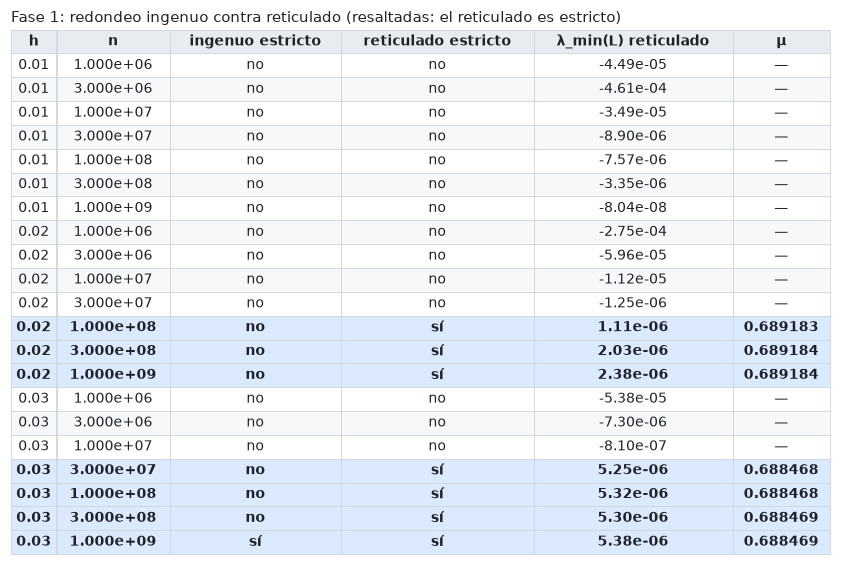

In [50]:
if not existe_resultado("s7_enteros.json"):
    correr_paso("enteros.py", f"--procesos {PROCESOS}", "Fase 1: grilla en n")
filas_enteras = cargar_json("s7_enteros.json")
filas = []
resaltadas = []
for i, r in enumerate(filas_enteras):
    filas.append([f"{r['h']:.2f}", f"{r['n']:.3e}", si_no(r["ingenuo_ok"]), si_no(r["reticulado_ok"]),
                  f"{r['menor_autovalor']:.2e}", f"{r['mu']:.6f}" if r["reticulado_ok"] else "—"])
    if r["reticulado_ok"]:
        resaltadas.append(i)
mostrar_tabla(["h", "n", "ingenuo estricto", "reticulado estricto", "λ_min(L) reticulado", "μ"], filas,
              titulo="Fase 1: redondeo ingenuo contra reticulado (resaltadas: el reticulado es estricto)",
              resaltar=resaltadas)

**Lectura.**
- El reticulado baja el $n$ necesario en uno o dos órdenes de magnitud: con $h = 0.03$, de $10^9$ a
  $3\cdot10^7$; con $h = 0.02$, de más de $10^9$ a $10^8$, con un $\mu$ un poco mayor.
- $h = 0.01$ tiene más $\mu$ pero menos margen, y no alcanza ni con $n = 10^9$.
- **Escala (heurística):** el ingenuo necesita $n \sim \sigma^{-2}$; el reticulado con $m$ enteros libres
  y 3 restricciones, $n \sim \sigma^{-(1 + 3/m)}$. Con más enteros libres por restricción se acerca a
  $\sigma^{-1}$. (Esa idea, partir clusters en sub-piezas de la misma fase para tener más enteros
  libres, se exploró aparte como "camino B" y no está en este notebook. La sección 12 muestra un camino
  mejor: la simetría.)

## 8. Fase 2: el grafo, un blow-up circulante

### 8.1 La construcción

Falta un grafo en el que **cada** vértice de $a$ tenga **exactamente** $d_{ab}$ vecinos en $b$. Con eso
las fases de los clusters son un equilibrio exacto del grafo, porque la velocidad de un vértice de $a$
es $-n F_a = 0$. Usamos un **blow-up circulante**, que generaliza el k-spinning de Canale a clusters de
tamaños distintos:

- **Vértices:** el cluster $a$ tiene $k_a$ bloques, y cada bloque es una copia de $\mathbb Z_g$. El
  vértice es $(a, i, v)$, con $i < k_a$ y $v \in \mathbb Z_g$.
- **Dentro de un cluster:** clique.
- **Entre clusters $a < b$:** $(a, i, v) \sim (b, j, v + s \bmod g)$ para $s \in \{0, \dots, t_{ij}-1\}$:
  cada vértice se une con un **intervalo** de $t_{ij}$ vértices consecutivos del otro bloque.
- **Grados:** un vértice $(a, i, \cdot)$ tiene $\sum_j t_{ij}$ vecinos en $b$, y uno $(b, j, \cdot)$ tiene
  $\sum_i t_{ij}$ vecinos en $a$. Hace falta entonces una tabla $t$ de $k_a\times k_b$ con filas que sumen
  $d_{ab}$, columnas que sumen $d_{ba}$ y entradas en $[0, g]$: un **problema de transporte**.

**Solución explícita del transporte:** todas las entradas valen $\text{base}$ o $\text{base}+1$, con
$\text{base} = \lfloor d_{ab}/k_b \rfloor$; en la fila $i$ los "+1" van en las columnas
$ie, \dots, ie + e - 1 \pmod{k_b}$, con $e = d_{ab} - k_b\,\text{base}$. Recorridas en orden, las filas
cubren las columnas en forma cíclica, así que cada columna recibe la misma cantidad de "+1".

No hace falta que $g$ sea múltiplo de nada: ahí se ahorra el $D^2$ de O'Keeffe. El grafo tiene
$n = 23g$ vértices, con $g$ libre.

**Lo que se publica:** $k$, $g$, los grados, las tablas y las fases (`descripcion_compacta`). Son unos
pocos KB, y con eso cualquiera reconstruye el grafo.

In [51]:
# biblioteca
def tabla_transporte(d_ab, k_a, k_b, g):
    """Tabla t (k_a × k_b) con filas d_ab, columnas d_ba = k_a d_ab/k_b y entradas en {base, base + 1} ⊂ [0, g].

    Los "+1" de la fila i van en las columnas i·e, …, i·e + e − 1 (mod k_b), con e = d_ab − k_b·base:
    recorridas en orden, las filas cubren las columnas de forma cíclica y cada una recibe los mismos.
    """
    total = k_a * d_ab
    assert total % k_b == 0, "tiene que valer k_a d_ab = k_b d_ba"
    assert 0 <= d_ab <= k_b * g
    base = total // (k_a * k_b)
    extra_fila = d_ab - k_b * base
    t = [[base] * k_b for _ in range(k_a)]
    for i in range(k_a):
        for desplazamiento in range(extra_fila):
            t[i][(i * extra_fila + desplazamiento) % k_b] += 1
    return t


def tablas_bloques(k, g, d):
    """{(a, b): tabla t} para a < b."""
    tablas = {}
    for a in range(len(k)):
        for b in range(a + 1, len(k)):
            tablas[(a, b)] = tabla_transporte(d[a][b], k[a], k[b], g)
    return tablas


def desplazamientos_cluster(k, g):
    """Índice del primer vértice de cada cluster (vértice (a, i, v) ↦ inicio_a + i·g + v)."""
    inicios = [0]
    for ka in k[:-1]:
        inicios.append(inicios[-1] + ka * g)
    return inicios


def adyacencia_densa(k, g, d):
    """Matriz de adyacencia del blow-up (solo para n chico: tests y validación)."""
    n_a = tamanos_enteros(k, g)
    inicios = desplazamientos_cluster(k, g)
    W = np.zeros((sum(n_a), sum(n_a)))
    for a in range(len(k)):
        bloque = slice(inicios[a], inicios[a] + n_a[a])
        W[bloque, bloque] = 1 - np.eye(n_a[a])
    v = np.arange(g)
    for (a, b), t in tablas_bloques(k, g, d).items():
        for i in range(k[a]):
            for j in range(k[b]):
                origen = inicios[a] + i * g + v
                for s in range(t[i][j]):
                    destino = inicios[b] + j * g + (v + s) % g
                    W[origen, destino] = 1
                    W[destino, origen] = 1
    return W


def hessiano_denso(W, theta):
    """H = diag(Σ_v W_uv cos(θ_u − θ_v)) − [W_uv cos(θ_u − θ_v)]."""
    A = W * np.cos(theta[:, None] - theta[None, :])
    return np.diag(A.sum(axis=1)) - A


def descripcion_compacta(k, g, d, fases):
    """Todo lo necesario para reconstruir el grafo y su estado (lo que se publica)."""
    tablas = {}
    for (a, b), t in tablas_bloques(k, g, d).items():
        tablas[f"{a},{b}"] = t
    return {
        "k": list(k), "g": g, "n": sum(tamanos_enteros(k, g)), "grados": d,
        "tablas": tablas, "conjuntos": "intervalos {0, …, t−1}", "fases": list(fases),
    }

**Un ejemplo chico:** $k = (1, 2, 3)$, $g = 5$ ($n = 30$), con grados elegidos a mano. Armamos la
adyacencia densa, verificamos que cada vértice tiene exactamente los grados pedidos y dibujamos la
matriz.

grados exactos en los 30 vértices: sí


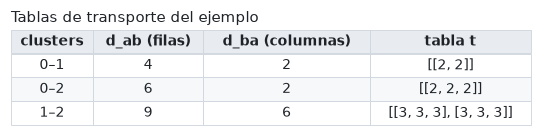

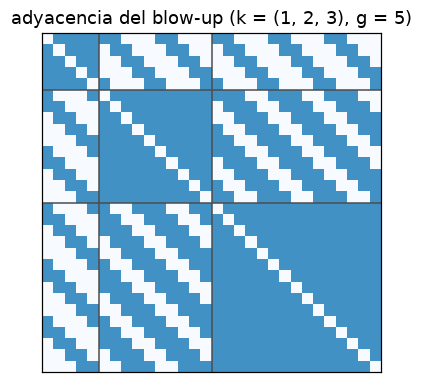

In [52]:
k_ejemplo = [1, 2, 3]
g_ejemplo = 5
d_ejemplo = [[4, 4, 6], [2, 9, 9], [2, 6, 14]]     # n_a d_ab = n_b d_ba con n = (5, 10, 15)
W_ejemplo = adyacencia_densa(k_ejemplo, g_ejemplo, d_ejemplo)
inicios = desplazamientos_cluster(k_ejemplo, g_ejemplo)
tamanos = tamanos_enteros(k_ejemplo, g_ejemplo)
exactos = True
for a in range(3):
    for b in range(3):
        cuentas = W_ejemplo[inicios[a]: inicios[a] + tamanos[a], inicios[b]: inicios[b] + tamanos[b]].sum(axis=1)
        exactos = exactos and bool((cuentas == d_ejemplo[a][b]).all())
print("grados exactos en los 30 vértices:", si_no(exactos))

filas = []
for (a, b), t in tablas_bloques(k_ejemplo, g_ejemplo, d_ejemplo).items():
    filas.append([f"{a}–{b}", d_ejemplo[a][b], d_ejemplo[b][a], str(t)])
mostrar_tabla(["clusters", "d_ab (filas)", "d_ba (columnas)", "tabla t"], filas, titulo="Tablas de transporte del ejemplo")

fig, eje = plt.subplots(figsize=(4, 4))
eje.imshow(W_ejemplo, cmap="Blues", vmin=0, vmax=1.6)
for corte in inicios[1:]:
    eje.axhline(corte - 0.5, color="0.3", lw=1)
    eje.axvline(corte - 0.5, color="0.3", lw=1)
eje.set(title="adyacencia del blow-up (k = (1, 2, 3), g = 5)", xticks=[], yticks=[])
plt.show()

Las diagonales fuera de los bloques de cada cluster son los intervalos de desplazamientos (matrices
circulantes).

### 8.2 El grafo general

Tomamos la solución estricta de la Fase 1 con menor $n$ (en la corrida de referencia, $h = 0.03$ y
$n = 3\cdot10^7$) y armamos su descripción compacta. Sus grados $d_{ab}$, y la tabla $t$ de un par con
densidad intermedia:

h de la plantilla: 0.03
g: 1,304,348
n general: 30000004   (referencia: 30000004, coincide)
μ general: 10327019/15000002   (referencia: 10327019/15000002, coincide)


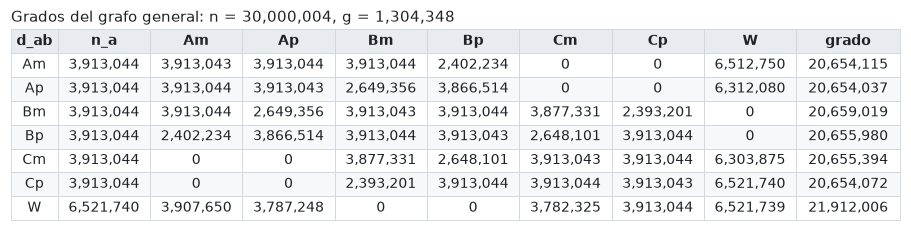

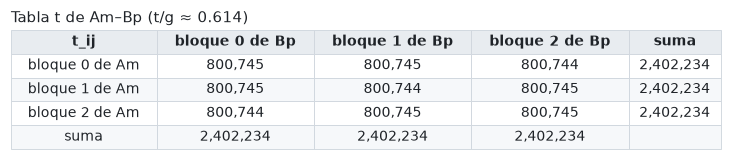

In [53]:
fila_general = min([r for r in filas_enteras if r["reticulado_ok"]], key=lambda r: (r["n"], -r["h"]))
descripcion_general = descripcion_compacta(K_S7, fila_general["g"], fila_general["grados"], fila_general["fases"])
tamanos_general = tamanos_enteros(K_S7, fila_general["g"])
print("h de la plantilla:", fila_general["h"])
print("g:", f"{fila_general['g']:,}")
comparar("n general", descripcion_general["n"])
comparar("μ general", fila_general["mu_exacto"])

filas = []
for a, nombre in enumerate(NOMBRES):
    fila = [nombre, f"{tamanos_general[a]:,}"]
    for valor in descripcion_general["grados"][a]:
        fila.append(f"{valor:,}")
    fila.append(f"{sum(descripcion_general['grados'][a]):,}")
    filas.append(fila)
mostrar_tabla(["d_ab", "n_a"] + NOMBRES + ["grado"], filas,
              titulo=f"Grados del grafo general: n = {descripcion_general['n']:,}, g = {descripcion_general['g']:,}")

tabla = descripcion_general["tablas"]["0,3"]
filas = []
for i, fila in enumerate(tabla):
    filas.append([f"bloque {i} de Am"] + [f"{t:,}" for t in fila] + [f"{sum(fila):,}"])
filas.append(["suma"] + [f"{sum(columna):,}" for columna in zip(*tabla)] + [""])
mostrar_tabla(["t_ij", "bloque 0 de Bp", "bloque 1 de Bp", "bloque 2 de Bp", "suma"], filas,
              titulo=f"Tabla t de Am–Bp (t/g ≈ {tabla[0][0] / descripcion_general['g']:.3f})")

**La tabla $d_{ab}$ no es simétrica, y no tiene por qué serlo.** La adyacencia sí es simétrica, pero
$d_{ab}$ cuenta vecinos **por vértice**. Contando las aristas entre $a$ y $b$ desde cada lado tiene que
dar lo mismo, $n_a d_{ab} = n_b d_{ba}$, así que $d_{ab} = d_{ba}$ solo si $n_a = n_b$. Acá las seis
mitades tienen 3 bloques y W tiene 5: solo la fila y la columna de W difieren, en la proporción
$n_W/n_a = 5/3$. Lo simétrico es la **densidad** del par, $d_{ab}/n_b = d_{ba}/n_a$.

n_a·d_ab = n_b·d_ba en los 21 pares: sí


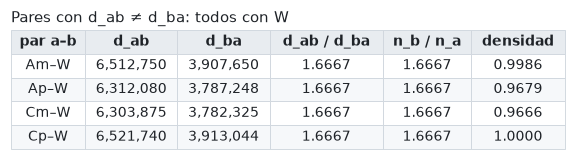

In [54]:
n = tamanos_general
d = descripcion_general["grados"]
balance = True
for a in range(7):
    for b in range(7):
        balance = balance and n[a] * d[a][b] == n[b] * d[b][a]
print("n_a·d_ab = n_b·d_ba en los 21 pares:", si_no(balance))

filas = []
for a in range(7):
    for b in range(a + 1, 7):
        if d[a][b] != d[b][a]:
            filas.append([f"{NOMBRES[a]}–{NOMBRES[b]}", f"{d[a][b]:,}", f"{d[b][a]:,}", f"{d[a][b] / d[b][a]:.4f}",
                          f"{n[b] / n[a]:.4f}", f"{d[a][b] / n[b]:.4f}"])
mostrar_tabla(["par a–b", "d_ab", "d_ba", "d_ab / d_ba", "n_b / n_a", "densidad"], filas,
              titulo="Pares con d_ab ≠ d_ba: todos con W")

### 8.3 Cómo se ve el grafo

Con $3\cdot10^7$ vértices no se puede dibujar la matriz de adyacencia, pero sí **a escala**: cada bloque
$\mathbb Z_g$ se parte en $F$ franjas de $L = \lfloor g/F\rfloor$ vértices consecutivos, y cada píxel
muestra la fracción de pares unidos entre dos franjas.

**La densidad de un píxel se calcula exacta.** En un bloque circulante con intervalo
$\{0, \dots, t-1\}$, el vértice $v$ de la franja $p$ y el $w$ de la franja $q$ están unidos si
$(w - v) \bmod g < t$. La cantidad de pares con $w - v = \delta$ es $L - |\delta - (q-p)L|$ (una
"carpa"), así que la densidad solo depende de $q - p$:
$$\text{densidad}(p, q) = \frac{1}{L^2}\sum_{|\delta - (q-p)L| < L} \big(L - |\delta - (q-p)L|\big)\,
[\,(\delta \bmod g) < t\,].$$

La figura tiene dos paneles: **(a)** el grafo de clusters, cada uno en su fase (con los desvíos dentro
de cada sector exagerados, porque son de $\sim 0.03$ rad), con área proporcional a $n_a$ y una arista por
par con su densidad; **(b)** la adyacencia a escala. El código es el de `scripts/visualizar_grafo.py`.

In [55]:
# biblioteca
LETRAS = ["A", "B", "C", "W"]


TONOS = [0.58, 0.07, 0.40, 0.80]     # azul, naranja, verde, violeta (uno por sector)


GRIS = "#8c959f"


def sectores(fases):
    """Sector de C4 de cada cluster (0: A, 1: B, 2: C, 3: W) y su desvío respecto de k·π/2."""
    sector = np.round(np.asarray(fases) / (np.pi / 2)).astype(int) % 4
    desvio = np.asarray(fases) - sector * np.pi / 2
    return sector, desvio


def nombres_y_colores(fases):
    """Nombre (Am, Ap, … o W1, W2 si las piezas tienen la misma fase) y color de cada cluster."""
    sector, desvio = sectores(fases)
    nombres = [""] * len(fases)
    colores = [None] * len(fases)
    for s in range(4):
        piezas = sorted(np.flatnonzero(sector == s), key=lambda a: desvio[a])
        separadas = len(piezas) == 2 and abs(desvio[piezas[0]] - desvio[piezas[1]]) > 1e-3
        for orden, a in enumerate(piezas):
            if len(piezas) == 1:
                nombres[a] = LETRAS[s]
            elif separadas:
                nombres[a] = LETRAS[s] + ("m" if orden == 0 else "p")
            else:
                nombres[a] = f"{LETRAS[s]}{orden + 1}"
            luz = 0.42 + 0.2 * orden / max(len(piezas) - 1, 1)
            colores[a] = colorsys.hls_to_rgb(TONOS[s], luz, 0.65)
    return nombres, colores


def densidad_circulante(t, g, franjas):
    """Densidad por píxel (franjas × franjas) del bloque circulante v ~ v + s, s < t, en Z_g.

    Solo depende de la diferencia de franjas q − p; los pares con w − v = δ son L − |δ − (q − p)L|.
    """
    largo = g // franjas
    desfase = np.arange(-largo + 1, largo)
    peso = largo - np.abs(desfase)
    por_diferencia = np.zeros(franjas)
    for diferencia in range(franjas):
        delta = diferencia * largo + desfase
        por_diferencia[diferencia] = (peso * ((delta % g) < t)).sum() / largo**2
    p, q = np.meshgrid(np.arange(franjas), np.arange(franjas), indexing="ij")
    return por_diferencia[(q - p) % franjas]


def imagen_adyacencia(descripcion, franjas):
    """Matriz de densidades (K·franjas)² del grafo: bloque por bloque."""
    k = descripcion["k"]
    g = descripcion["g"]
    inicios = np.concatenate([[0], np.cumsum(k)]) * franjas
    lado = sum(k) * franjas
    imagen = np.zeros((lado, lado))
    for a in range(len(k)):
        imagen[inicios[a]: inicios[a + 1], inicios[a]: inicios[a + 1]] = 1
    for clave, tabla in descripcion["tablas"].items():
        a, b = (int(c) for c in clave.split(","))
        for i in range(k[a]):
            for j in range(k[b]):
                if tabla[i][j] == 0:
                    continue
                bloque = densidad_circulante(tabla[i][j], g, franjas)
                filas = slice(inicios[a] + i * franjas, inicios[a] + (i + 1) * franjas)
                columnas = slice(inicios[b] + j * franjas, inicios[b] + (j + 1) * franjas)
                imagen[filas, columnas] = bloque
                imagen[columnas, filas] = bloque.T
    return imagen, inicios


def posiciones_clusters(fases, exageracion):
    """Posición de cada cluster: ángulo del sector más el desvío exagerado; las piezas con la misma fase, hacia adentro."""
    sector, desvio = sectores(fases)
    angulos = sector * np.pi / 2 + exageracion * desvio
    radios = np.ones(len(fases))
    for a in range(len(fases)):
        for b in range(a):
            if sector[a] == sector[b] and abs(desvio[a] - desvio[b]) < 1e-3:
                radios[a] = radios[b] - 0.45
    return np.column_stack([radios * np.cos(angulos), radios * np.sin(angulos)])


def dibujar_grafo_clusters(eje, descripcion, nombres, colores):
    """Panel (a): clusters en sus fases y aristas con la densidad de cada par."""
    fases = [float(p) for p in descripcion["fases"]]
    k = descripcion["k"]
    g = descripcion["g"]
    n_a = np.array(k) * g
    _, desvio = sectores(fases)
    exageracion = 0.45 / np.abs(desvio).max()
    posiciones = posiciones_clusters(fases, exageracion)
    circulo = np.linspace(0, 2 * np.pi, 200)
    eje.plot(np.cos(circulo), np.sin(circulo), color="#d0d7de", lw=1, zorder=0)
    for a in range(len(k)):
        for b in range(a + 1, len(k)):
            densidad = descripcion["grados"][a][b] / n_a[b]
            if densidad == 0:
                continue
            (x0, y0), (x1, y1) = posiciones[a], posiciones[b]
            completo = densidad > 0.999
            eje.plot([x0, x1], [y0, y1], color=GRIS if completo else TINTA, lw=0.6 + 2.4 * densidad,
                     alpha=0.35 if completo else 0.8, zorder=1)
            if densidad < 0.95:
                # etiquetas a 40% o 60% del camino, alternadas, para que no se encimen las que salen del mismo cluster
                fraccion = 0.4 if (a + b) % 2 == 0 else 0.6
                eje.text(x0 + fraccion * (x1 - x0), y0 + fraccion * (y1 - y0), f"{100 * densidad:.1f}%", fontsize=7,
                         color=TINTA,
                         ha="center", va="center", zorder=3,
                         bbox={"boxstyle": "round,pad=0.15", "fc": "white", "ec": "none", "alpha": 0.85})
    areas = 1300 * n_a / n_a.max()
    eje.scatter(posiciones[:, 0], posiciones[:, 1], s=areas, c=colores, edgecolors="white", linewidths=2, zorder=2)
    for a in range(len(k)):
        x, y = posiciones[a]
        radio = np.hypot(x, y)
        # los clusters del borde llevan la etiqueta afuera; los de adentro (misma fase que otro), hacia el centro
        escala = 1.36 / radio if radio > 0.99 else (radio - 0.36) / radio
        eje.text(x * escala, y * escala, f"{nombres[a]}\nφ = {fases[a]:.3f}\nn = {n_a[a]:,}", fontsize=7.5,
                 color=TINTA, ha="center", va="center")
    eje.set(xlim=(-1.75, 1.75), ylim=(-1.75, 1.75), aspect="equal", xticks=[], yticks=[])
    for borde in eje.spines.values():
        borde.set_visible(False)
    eje.set_title(f"(a) clusters en su fase (desvíos ×{exageracion:.0f}; misma fase: uno adentro del otro)\n"
                  "gris: unión completa; negro: parcial (etiqueta si < 95%; el resto, en (b))", fontsize=9,
                  color=TINTA)


def dibujar_estructura(descripcion, mu, archivo):
    """Figura con el grafo de clusters y la adyacencia a escala."""
    fases = [float(p) for p in descripcion["fases"]]
    nombres, colores = nombres_y_colores(fases)
    fig, ejes = plt.subplots(1, 2, figsize=(13, 6.2), gridspec_kw={"width_ratios": [1, 1.1]})
    dibujar_grafo_clusters(ejes[0], descripcion, nombres, colores)

    franjas = max(4, 330 // sum(descripcion["k"]))
    imagen, inicios = imagen_adyacencia(descripcion, franjas)
    figura = ejes[1].imshow(imagen, cmap="Blues", vmin=0, vmax=1, interpolation="nearest")
    for corte in inicios[1:-1]:
        ejes[1].axhline(corte - 0.5, color=TINTA, lw=0.7)
        ejes[1].axvline(corte - 0.5, color=TINTA, lw=0.7)
    centros = (inicios[:-1] + inicios[1:]) / 2 - 0.5
    ejes[1].set_xticks(centros, nombres, fontsize=8)
    ejes[1].set_yticks(centros, nombres, fontsize=8)
    ejes[1].tick_params(length=0)
    for etiqueta, color in zip(ejes[1].get_xticklabels(), colores):
        etiqueta.set_color(color)
    for etiqueta, color in zip(ejes[1].get_yticklabels(), colores):
        etiqueta.set_color(color)
    ejes[1].set_title(f"(b) adyacencia a escala: {franjas} franjas por bloque de g = {descripcion['g']:,} vértices",
                      fontsize=9, color=TINTA)
    barra = fig.colorbar(figura, ax=ejes[1], fraction=0.046, pad=0.03)
    barra.set_label("fracción de pares unidos", fontsize=8)
    fig.suptitle(f"Grafo certificado: n = {descripcion['n']:,} vértices, k = {descripcion['k']}, "
                 f"μ = {mu} ≈ {eval(mu):.6f}", fontsize=11, color=TINTA)
    fig.tight_layout()
    fig.savefig(archivo, dpi=130)
    plt.close(fig)

**Chequeo** de `densidad_circulante` contra el promedio por franjas de una matriz circulante densa:

densidad por franjas exacta: sí


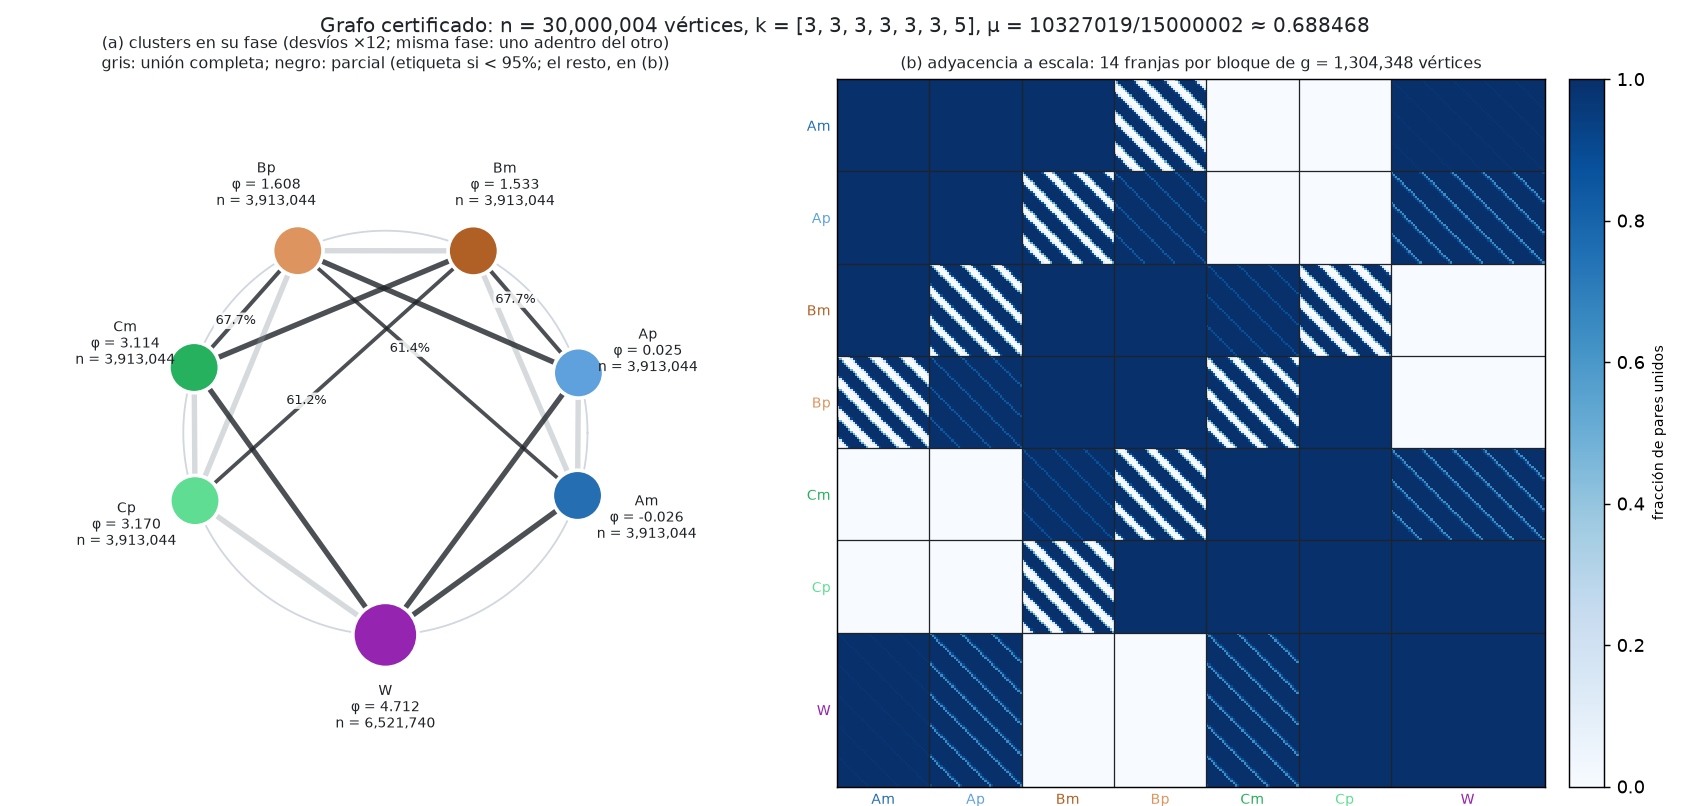

In [56]:
t_prueba, g_prueba, franjas_prueba = 23, 60, 6
circulante = np.zeros((g_prueba, g_prueba))
for v in range(g_prueba):
    for s in range(t_prueba):
        circulante[v, (v + s) % g_prueba] = 1
largo_prueba = g_prueba // franjas_prueba
promedio = circulante.reshape(franjas_prueba, largo_prueba, franjas_prueba, largo_prueba).mean(axis=(1, 3))
print("densidad por franjas exacta:", si_no(np.allclose(promedio, densidad_circulante(t_prueba, g_prueba, franjas_prueba))))

archivo = CARPETA_RESULTADOS / "figuras" / f"grafo_n{descripcion_general['n']}_estructura.png"
dibujar_estructura(descripcion_general, fila_general["mu_exacto"], archivo)
display(Image(filename=str(archivo)))

- **(a)** Es el "cuadrado" de C4: A en 0, B en $\pi/2$, C en $\pi$ y W en $3\pi/2$, con A, B y C partidos
  en dos mitades. Los clusters opuestos (A–C, B–W) no tienen aristas. Las densidades lejos de 0 y 1 son
  los cuatro pares cruzados entre mitades: las $q$ del patrón límite de S7, abiertas por el SDP.
- **(b)** Los bloques llenos son los cliques y los pares completos; los blancos, los pares opuestos; y
  las **bandas diagonales** son los intervalos circulantes: con $t/g \approx 0.61$, cada vértice ve una
  ventana de vértices consecutivos que se corre con él.

## 9. Fase 3: el certificado

Hay que probar, sin errores de redondeo, que el grafo de $3\cdot10^7$ vértices tiene un equilibrio no
sincronizado cuyo Hessiano es definido positivo en $\mathbf 1^\perp$. El Hessiano tiene
$(3\cdot10^7)^2$ entradas, pero mucha simetría.

### 9.1 Descomposición de Fourier

Correr $v \to v + 1$ en todos los bloques a la vez es un automorfismo del grafo (los cliques y los
intervalos se preservan) y no cambia las fases, que son constantes por cluster. Entonces $H$ conmuta con
ese corrimiento y se diagonaliza en bloques, con vectores $\theta_{(a,i,v)} = z_{a,i}\,e^{2\pi\mathrm i mv/g}$,
uno por frecuencia $m = 0, \dots, g-1$. Para cada $m$ queda una matriz hermítica $H_m$ de $K\times K$
($K = \sum k_a = 23$):
$$H_m[(a,i),(b,j)] = \delta_{(a,i),(b,j)}\,D_a - \cos(\varphi_a - \varphi_b)\,\hat N_{ij}(m), \qquad
D_a = \sum_b d_{ab}\cos(\varphi_a - \varphi_b),$$
donde $\hat N_{ij}(m)$ es la transformada del conjunto de desplazamientos:
- entre clusters, $\hat N_{ij}(m) = \sum_{s < t_{ij}} e^{2\pi\mathrm i ms/g}$;
- dentro de un mismo bloque, $\hat N(m) = g[m{=}0] - 1$ (es $\mathbb Z_g \setminus \{0\}$);
- entre dos bloques distintos del mismo cluster, $\hat N(m) = g[m{=}0]$ (es $\mathbb Z_g$ completo).

El espectro de $H$ es la unión de los espectros de los $H_m$.

In [57]:
# biblioteca
def transformada_intervalo(t, g, m):
    """N̂(m) = Σ_{s=0}^{t−1} e^{2πi m s/g}."""
    s = np.arange(t)
    return np.exp(2j * np.pi * m * s / g).sum()


def hessiano_fourier(k, g, d, fases, m):
    """Bloque H_m (K × K, hermítico) del Hessiano del blow-up."""
    K = sum(k)
    fases = np.asarray(fases, dtype=float)
    cos = np.cos(fases[:, None] - fases[None, :])
    inicio_bloque = np.cumsum([0] + list(k[:-1]))
    H = np.zeros((K, K), dtype=complex)
    for a in range(len(k)):
        diagonal = sum(d[a][b] * cos[a, b] for b in range(len(k)))
        for i in range(k[a]):
            fila = inicio_bloque[a] + i
            H[fila, fila] = diagonal - ((g if m == 0 else 0) - 1)
            for j in range(k[a]):
                if j != i:
                    H[fila, inicio_bloque[a] + j] = -(g if m == 0 else 0)
    for (a, b), t in tablas_bloques(k, g, d).items():
        for i in range(k[a]):
            for j in range(k[b]):
                valor = -cos[a, b] * transformada_intervalo(t[i][j], g, m)
                H[inicio_bloque[a] + i, inicio_bloque[b] + j] = valor
                H[inicio_bloque[b] + j, inicio_bloque[a] + i] = np.conj(valor)
    return H

Lo verificamos en el ejemplo chico de la sección 8.1, con fases cualesquiera: los 30 autovalores del
Hessiano denso contra la unión de los espectros de los 5 bloques $H_m$ de $6\times6$.

In [58]:
fases_ejemplo = np.array([0.0, 0.4, -0.7])
theta_ejemplo = np.repeat(fases_ejemplo, tamanos_enteros(k_ejemplo, g_ejemplo))
denso = np.sort(np.linalg.eigvalsh(hessiano_denso(W_ejemplo, theta_ejemplo)))
por_bloques = []
for m in range(g_ejemplo):
    por_bloques.extend(np.linalg.eigvalsh(hessiano_fourier(k_ejemplo, g_ejemplo, d_ejemplo, fases_ejemplo, m)))
print("máxima diferencia entre espectros:", f"{np.abs(denso - np.sort(por_bloques)).max():.1e}")

máxima diferencia entre espectros: 1.4e-14


### 9.2 Modos de cluster: el cociente de $7\times7$

Los vectores constantes en cada cluster, $\theta = \sum_a y_a \mathbf 1_a$, viven en $H_0$. Como cada
vértice de $a$ tiene exactamente $d_{ab}$ vecinos en $b$,
$\mathbf 1_a^\top H\mathbf 1_b = -n_a d_{ab}\cos(\varphi_a - \varphi_b)$, y entonces
$$\theta^\top H\theta = n^2 L(y)$$
con la plantilla entera $x_a = n_a/n$, $P_{ab} = d_{ab}/n_b$. El certificado de estos modos es el
certificado de la plantilla de la sección 3.6 (`certificar`): Krawczyk en una caja de fases de radio
$10^{-40}$, $c > 0$, Cholesky por intervalos de $L$ y fases distintas, con 100 dígitos.

### 9.3 El resto de los modos: Gershgorin por bloques

Los demás modos son los $H_m$ con $m \ne 0$, más la parte de $H_0$ con $\sum_i z_{a,i} = 0$ en cada
cluster. En esos modos la parte de cada cluster es diagonal, $(D_a + 1)I$, y los bloques entre clusters
son $-\cos_{ab}\hat N(m)$.

**Cota de Schur:** $\|\hat N\|_2 \le \sqrt{(\text{máx. suma de fila})(\text{máx. suma de columna})}$ de
$|\hat N|$.
- **Para $m \ne 0$:** $|\hat N_{ij}(m)| \le \min(t_{ij}, g - t_{ij})$, porque la suma sobre todo
  $\mathbb Z_g$ es 0; las sumas de fila quedan $\le \min(d_{ab}, n_b - d_{ab})$.
- **Para $m = 0$ con suma cero:** la parte constante $\text{base}\cdot J$ de la tabla se anula y solo
  actúan los "+1", con filas $\le d_{ab} - k_b\,\text{base}$.

En ningún caso importa **qué** desplazamientos se eligieron, solo los grados.

**Gershgorin por bloques:** todo autovalor de esos modos es al menos
$$\min_a\Big(D_a + 1 - \sum_{b\ne a}|\cos_{ab}|\sqrt{s_{ab}}\Big),$$
con $s_{ab}$ el producto de las dos cotas de Schur. Con `lib = mpmath.iv` y los cosenos evaluados sobre
la caja de Krawczyk, la cota es rigurosa.

### 9.4 $\mu$ exacto y el certificado completo

$\mu = (\delta+1)/n$ se calcula con fracciones (`mu_entero`) y se compara con $11/16$ en aritmética
exacta. `certificar_blowup` junta todo.

In [59]:
# biblioteca
UMBRAL = Fraction(11, 16)


def acoplamientos(k, g, d):
    """Cotas de Schur s_ab de los acoplamientos entre clusters, en los dos tipos de modos.

    - m ≠ 0: |N̂_ij(m)| ≤ min(t_ij, g − t_ij), y sumando una fila ≤ min(d_ab, n_b − d_ab).
    - m = 0 con suma cero dentro de cada cluster: solo actúa E = t − base (la parte constante
      se anula), con filas d_ab − k_b·base y columnas d_ba − k_a·base.
    Devuelve (s_fourier, s_cero), matrices m × m simétricas con s_aa = 0 (enteros exactos bajo raíz).
    """
    m = len(k)
    n_a = tamanos_enteros(k, g)
    s_fourier = [[0] * m for _ in range(m)]
    s_cero = [[0] * m for _ in range(m)]
    for a in range(m):
        for b in range(a + 1, m):
            fila = min(d[a][b], n_a[b] - d[a][b])
            columna = min(d[b][a], n_a[a] - d[b][a])
            s_fourier[a][b] = s_fourier[b][a] = fila * columna
            base = (k[a] * d[a][b]) // (k[a] * k[b])
            fila = d[a][b] - k[b] * base
            columna = d[b][a] - k[a] * base
            s_cero[a][b] = s_cero[b][a] = fila * columna
    return s_fourier, s_cero


def margenes_gershgorin(k, g, d, fases, lib=np):
    """Margen por cluster: Σ_b d_ab cos_ab + 1 − Σ_{b≠a} |cos_ab| √s_ab, para cada tipo de modo.

    Si todos son > 0, la forma cuadrática del Hessiano es positiva en todos los modos que no son
    constantes por cluster (H_m con m ≠ 0, y la parte de H_0 ortogonal a los modos de cluster).
    Con lib = mpmath.iv y fases como intervalos (la caja de Krawczyk) la cota es rigurosa.
    """
    m = len(k)
    s_fourier, s_cero = acoplamientos(k, g, d)
    margenes = {"fourier": [], "cero": []}
    for a in range(m):
        cos = [lib.cos(fases[a] - fases[b]) for b in range(m)]
        diagonal = 1
        for b in range(m):
            diagonal = diagonal + d[a][b] * cos[b]
        for nombre, s in (("fourier", s_fourier), ("cero", s_cero)):
            total = diagonal
            for b in range(m):
                if b != a:
                    total = total - abs(cos[b]) * lib.sqrt(s[a][b])
            margenes[nombre].append(total)
    return margenes


def certificar_blowup(k, g, d, fases, dps=100, radio="1e-40"):
    """Certificado riguroso del blow-up de (k, g, d), con fases iniciales `fases`. Devuelve un dict.

    ok = True si: Krawczyk + c > 0 + Cholesky de L + estado no sync en el cociente (`certificar`),
    márgenes de Gershgorin > 0 sobre la caja de Krawczyk (resto de los modos) y μ > 11/16 exacto.
    """
    x, P = plantilla_entera(k, g, d)
    try:
        phi = fases_newton(x, P, fases, dps=dps + 20)
    except ZeroDivisionError:
        return {"ok": False, "motivo": "Newton no converge"}
    cociente = certificar(x, P, phi, radio=radio, dps=dps, verbose=False)
    margenes = margenes_gershgorin(k, g, d, cociente["caja"], lib=iv)
    menor_fourier = min(mp.mpf(v.a) for v in margenes["fourier"])
    menor_cero = min(mp.mpf(v.a) for v in margenes["cero"])
    mu = mu_entero(k, g, d)
    n = sum(k) * g
    ok = cociente["ok"] and menor_fourier > 0 and menor_cero > 0 and mu > UMBRAL
    return {
        "ok": bool(ok),
        "krawczyk": bool(cociente["krawczyk"]),
        "c>0": bool(cociente["c>0"]),
        "cholesky": bool(cociente["cholesky"]),
        "distintas": bool(cociente["distintas"]),
        "no sync": bool(cociente["no sync"]),
        "min pivote L (cota inf)": float(cociente["min pivote (cota inf)"]),
        "margen fourier / n (cota inf)": float(menor_fourier / n),
        "margen cero / n (cota inf)": float(menor_cero / n),
        "mu": float(mu), "mu_exacto": f"{mu.numerator}/{mu.denominator}",
        "mu > 11/16": bool(mu > UMBRAL),
        "radio caja": radio,
        "fases": [mp.nstr(p, 30) for p in phi],
    }

**El script de la Fase 3** certifica cada solución estricta de la Fase 1 y, como **control negativo**,
el redondeo ingenuo del mismo $n$ (que tiene que fallar, salvo donde la Fase 1 ya lo dio estricto).
Tarda unos segundos.

In [60]:
# biblioteca
def control_ingenuo(r, curva):
    """Grados del redondeo ingenuo para el mismo (h, ε, k, n) que la fila r de s7_enteros.json."""
    fila = [f for f in curva if f["h"] == r["h"] and f["margen"] == r["margen"] and f["k"] == r["k"]][0]
    k = [r["k"][0]] * 6 + [r["k"][1]]
    phi = fases_s7(r["h"], np.array(fila["s"]))
    x, phi, P = pulir(tamanos_exactos(k), phi, np.array(fila["P"]))
    return grados_ingenuos(x, P, k, r["g"]), [float(p) for p in phi]


def imprimir(etiqueta, resultado):
    """Una línea por grafo."""
    if "krawczyk" not in resultado:
        print(f"{etiqueta}: falla ({resultado['motivo']})", flush=True)
        return
    print(f"{etiqueta}: ok {resultado['ok']}  (Krawczyk {resultado['krawczyk']}, Cholesky {resultado['cholesky']},"
          f" pivote {resultado['min pivote L (cota inf)']:.2e}, margen Fourier {resultado['margen fourier / n (cota inf)']:.3f} n,"
          f" μ = {resultado['mu']:.6f})", flush=True)

In [61]:
%%writefile externos/certificar_grafos.py
"""Fase 3 (sección 9.4): certifica cada solución estricta de la Fase 1 y su control ingenuo.

Guarda la descripción compacta de cada grafo con su certificado en resultados/grafos_s7.json.
Uso: python externos/certificar_grafos.py [--dps 100]
"""
import argparse
import sys
import time
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parent))
from biblioteca_s7 import *  # noqa: E402,F403


def main():
    """Certifica cada solución entera estricta (y su control ingenuo) y guarda las descripciones compactas."""
    parser = argparse.ArgumentParser()
    parser.add_argument("--dps", type=int, default=100)
    args = parser.parse_args()
    curva = cargar_json("s7_curva.json" if existe_resultado("s7_curva.json") else "s7_curva_reducida.json")
    salida = []
    for r in sorted(cargar_json("s7_enteros.json"), key=lambda r: (r["n"], -r["h"])):
        if not r["reticulado_ok"]:
            continue
        k = [r["k"][0]] * 6 + [r["k"][1]]
        inicio = time.time()
        resultado = certificar_blowup(k, r["g"], r["grados"], r["fases"], dps=args.dps)
        imprimir(f"h = {r['h']}  n = {r['n']:.2e}  reticulado", resultado)
        fila = {"h": r["h"], "margen": r["margen"], "redondeo": "reticulado", "segundos": time.time() - inicio,
                "certificado": resultado,
                "grafo": descripcion_compacta(k, r["g"], r["grados"], resultado.get("fases", r["fases"]))}
        salida.append(fila)
        d_ingenuo, phi = control_ingenuo(r, curva)
        negativo = certificar_blowup(k, r["g"], d_ingenuo, phi, dps=args.dps)
        imprimir(f"h = {r['h']}  n = {r['n']:.2e}  ingenuo   ", negativo)
        salida.append({"h": r["h"], "margen": r["margen"], "redondeo": "ingenuo", "certificado": negativo,
                       "grafo": descripcion_compacta(k, r["g"], d_ingenuo, negativo.get("fases", phi))})
    print("guardado en", guardar_json("grafos_s7.json", salida))


if __name__ == "__main__":
    main()

Overwriting externos/certificar_grafos.py


<table>
<tr><th align="left">▶ Cómo correr <code>externos/certificar_grafos.py</code> (desde la carpeta del notebook)</th></tr>
<tr><td align="left"><b>Máquina:</b> CPU local (cualquiera)<br><b>Tiempo:</b> unos segundos<br><b>Salida:</b> <code>resultados/grafos_s7.json</code></td></tr>
<tr><td align="left"><pre>python externos/certificar_grafos.py</pre></td></tr>
</table>

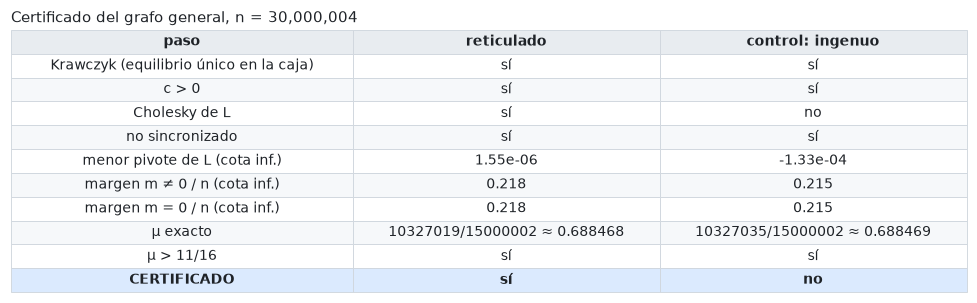

In [62]:
if not existe_resultado("grafos_s7.json"):
    correr_paso("certificar_grafos.py", "", "Fase 3: certificados")
grafos = cargar_json("grafos_s7.json")


def columna_certificado(r):
    """Valores de un resultado de certificar_blowup, en el orden de las filas de la tabla."""
    if "krawczyk" not in r:
        return ["—"] * 9 + [f"no ({r['motivo']})"]
    return [si_no(r["krawczyk"]), si_no(r["c>0"]), si_no(r["cholesky"]), si_no(r["no sync"]),
            f"{r['min pivote L (cota inf)']:.2e}", f"{r['margen fourier / n (cota inf)']:.3f}",
            f"{r['margen cero / n (cota inf)']:.3f}", f"{r['mu_exacto']} ≈ {r['mu']:.6f}",
            si_no(r["mu > 11/16"]), si_no(r["ok"])]


general = [f for f in grafos if f["redondeo"] == "reticulado" and f["grafo"]["n"] == descripcion_general["n"]
           and f["h"] == fila_general["h"]][0]
control = [f for f in grafos if f["redondeo"] == "ingenuo" and f["grafo"]["n"] == descripcion_general["n"]
           and f["h"] == fila_general["h"]][0]
etiquetas = ["Krawczyk (equilibrio único en la caja)", "c > 0", "Cholesky de L", "no sincronizado",
             "menor pivote de L (cota inf.)", "margen m ≠ 0 / n (cota inf.)", "margen m = 0 / n (cota inf.)",
             "μ exacto", "μ > 11/16", "CERTIFICADO"]
filas = []
for etiqueta, valor, valor_control in zip(etiquetas, columna_certificado(general["certificado"]),
                                           columna_certificado(control["certificado"])):
    filas.append([etiqueta, valor, valor_control])
mostrar_tabla(["paso", "reticulado", "control: ingenuo"], filas,
              titulo=f"Certificado del grafo general, n = {descripcion_general['n']:,}", resaltar=[len(filas) - 1])

**Lectura.**
- **El grafo general queda certificado.**
- El menor pivote del Cholesky de $L$ es chico ($\sim10^{-6}$), pero su cota inferior por intervalos es
  positiva. El resto de los modos tiene margen $\ge 0.2\,n$: el blow-up no cuesta nada, y toda la
  dificultad está en el cociente de $7\times7$.
- **En el control,** Krawczyk sí encuentra un equilibrio, pero Cholesky falla: es el equilibrio
  inestable de la sección 7.2.

Todos los grafos:

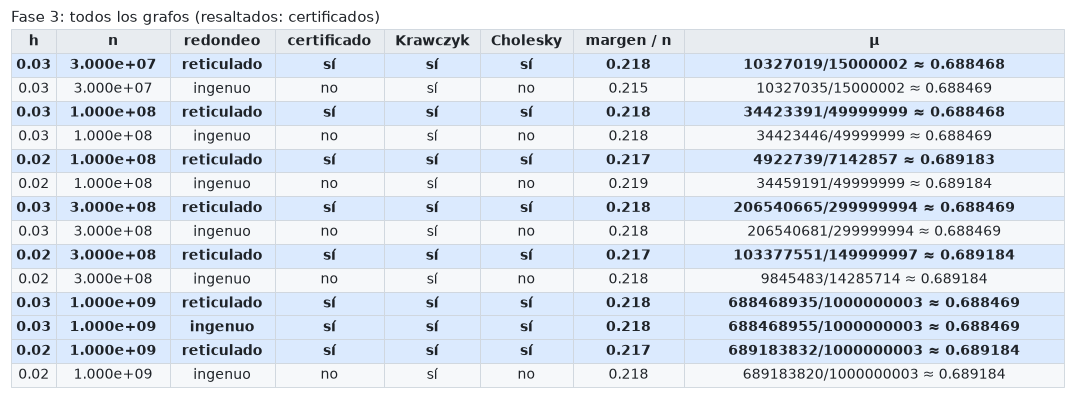

In [63]:
filas = []
resaltadas = []
for i, f in enumerate(grafos):
    c = f["certificado"]
    if "krawczyk" not in c:
        filas.append([f"{f['h']:.2f}", f"{f['grafo']['n']:.3e}", f["redondeo"], "no", "—", "—", "—", c["motivo"]])
        continue
    margen = min(c["margen fourier / n (cota inf)"], c["margen cero / n (cota inf)"])
    filas.append([f"{f['h']:.2f}", f"{f['grafo']['n']:.3e}", f["redondeo"], si_no(c["ok"]), si_no(c["krawczyk"]),
                  si_no(c["cholesky"]), f"{margen:.3f}", f"{c['mu_exacto']} ≈ {c['mu']:.6f}"])
    if c["ok"]:
        resaltadas.append(i)
mostrar_tabla(["h", "n", "redondeo", "certificado", "Krawczyk", "Cholesky", "margen / n", "μ"], filas,
              titulo="Fase 3: todos los grafos (resaltados: certificados)", resaltar=resaltadas)
descripcion_general = general["grafo"]

Todos los grafos del reticulado quedan certificados; los controles ingenuos fallan, salvo donde la
Fase 1 ya había dado el ingenuo como estricto ($h = 0.03$ con $n = 10^9$). Desde acá, la descripción
del grafo general lleva las fases certificadas (30 dígitos).

## 10. Fase 4: validación ciega

El certificado trabaja con los **datos** del grafo (grados, la plantilla de $7\times7$, los bloques de
Fourier) y depende de que la teoría de la sección 9 esté bien. Si hubiera un error entre los datos y el
grafo, por ejemplo al pasar de los grados a las tablas, el certificado no lo vería. Por eso lo
chequeamos de dos maneras independientes:
1. **Validación ciega** (10.1–10.2): a partir de la regla de adyacencia y nada más, en float64, contamos
   los vecinos, medimos la velocidad en las fases certificadas y buscamos el menor autovalor del
   Hessiano con Lanczos.
2. **Espectro completo** (10.3–10.4): usando la estructura circulante, calculamos **todos** los
   autovalores del Hessiano y los comparamos con las cotas del certificado.

### 10.1 Productos implícitos y Lanczos

Armar la matriz es imposible: el grafo general tiene $\sim6\cdot10^{14}$ aristas. Solo usamos productos
matriz-vector, que salen de la regla de adyacencia.

**$Wy$ implícito:**
- **dentro de un cluster** (clique): $(Wy)_u = \sum_{v \in a} y_v - y_u$;
- **entre clusters:** el vértice $(a, i, v)$ recibe $\sum_j\sum_{s<t_{ij}} y_{(b,j,v+s)}$, una suma sobre
  una ventana cíclica, y $(b, j, w)$ recibe la ventana hacia atrás $\sum_i\sum_{s<t_{ij}} y_{(a,i,w-s)}$.

Con la suma prefija $S$ de $[y, y]$ (cada bloque repetido dos veces, para no preocuparse por el
"mod $g$"), la ventana hacia adelante es $S[v+t] - S[v]$: cada una cuesta $O(1)$, un producto cuesta
$O(nk)$ y la memoria es $O(n)$. Dos detalles:
- **precisión:** cada bloque se centra por su media antes de la suma prefija (la media se suma después,
  $t$ veces); sin eso, las sumas prefijas de $10^6$ términos pierden dígitos;
- **máscaras:** las tablas solo tienen dos valores ($\text{base}$ y $\text{base}+1$). Para cada valor
  $t$ se guarda la matriz 0/1 $M_t$ ($k_a\times k_b$) de los pares $(i, j)$ que lo tienen, y $M_t$
  reparte entre los bloques de $a$ las ventanas de todos los bloques de $b$, calculadas de una vez.

**$Hx$ implícito.** Con $\cos(\theta_u - \theta_v) = \cos\theta_u\cos\theta_v + \sin\theta_u\sin\theta_v$:
$$Hx = h\circ x - \cos\theta\circ W(\cos\theta\circ x) - \sin\theta\circ W(\sin\theta\circ x), \qquad
h = \cos\theta\circ W\cos\theta + \sin\theta\circ W\sin\theta.$$
No usa que las fases sean constantes por cluster.

**El código.** La clase `Arreglos` hace las pocas operaciones que hacen falta con numpy o con torch (en
CPU o en GPU), siempre en float64; `GrafoImplicito` guarda $k$, $g$, las máscaras, $\cos\theta$,
$\sin\theta$ y $h$, y tiene los productos. Los chequeos:
1. **grados:** $W\mathbf 1_b$ cuenta los vecinos de cada vértice en el cluster $b$; el mínimo y el máximo
   en cada cluster $a$ tienen que ser exactamente $d_{ab}$ (son enteros: en float64 es exacto);
2. **velocidad:** $\dot\theta = \cos\theta\circ W\sin\theta - \sin\theta\circ W\cos\theta$ en las fases
   certificadas tiene que ser error de redondeo;
3. **modos de cluster:** $Q_{ab} = \mathbf 1_a^\top H\mathbf 1_b/\sqrt{n_a n_b}$ con $H$ implícito, contra la
   fórmula de los grados $Q_{ab} = -\sqrt{n_a/n_b}\,d_{ab}\cos_{ab}$, $Q_{aa} = \sum_{c\ne a} d_{ac}\cos_{ac}$;
4. **el resto de los modos:** el menor autovalor de $H$ en el complemento de los modos de cluster;
5. **todo junto:** el menor autovalor de $H$ en $\mathbf 1^\perp$, desde un vector al azar y sin separar
   nada. Tiene que dar el menor autovalor de $Q$ que no es la rotación.

**Lanczos** encuentra el menor autovalor usando solo productos $Hx$. Genera una base ortonormal
$q_1, q_2, \dots$ del espacio de Krylov $\{x, Hx, H^2x, \dots\}$ con la recurrencia de tres términos
$\beta_k q_{k+1} = Hq_k - \alpha_k q_k - \beta_{k-1}q_{k-1}$.
- Los autovalores de la tridiagonal $T_k = \mathrm{tridiag}(\beta, \alpha, \beta)$ (los **valores de
  Ritz**) aproximan los extremos del espectro.
- Si $s$ es el autovector de $T_k$ del menor valor de Ritz $\vartheta$, el residuo de su vector de Ritz
  es $\|Hy - \vartheta y\| = \beta_k|s_k|$, y se calcula sin armar $y$.
- Solo hace falta guardar tres vectores.
- **Proyección:** para buscar en un subespacio se proyecta después de cada producto (restar la media de
  cada cluster, o la media global).
- **Detalle numérico:** el resto del espectro es muy degenerado y $\beta$ cae a $\sim10^{-10}$ en pocos
  pasos. Entonces $w/\beta$ amplifica el redondeo en las direcciones proyectadas afuera y aparece un
  valor de Ritz espurio $\approx 0$. Se evita reproyectando $w$ antes de normalizarlo.

In [64]:
# biblioteca
class Arreglos:
    """Las pocas operaciones que hacen falta, con numpy (dispositivo None) o con torch."""

    def __init__(self, dispositivo=None):
        self.torch = None
        if dispositivo is not None:
            import torch
            self.torch = torch
            self.dispositivo = torch.device(dispositivo)

    def desde(self, x):
        """numpy → arreglo del backend (float64)."""
        x = np.asarray(x, dtype=np.float64)
        if self.torch is None:
            return x
        return self.torch.from_numpy(x).to(self.dispositivo)

    def ceros(self, n):
        """Vector de ceros de largo n."""
        return self.desde(np.zeros(n))

    def aleatorio(self, n, semilla):
        """Vector gaussiano de largo n (generado en CPU para que sea reproducible)."""
        return self.desde(np.random.default_rng(semilla).standard_normal(n))

    def a_numpy(self, x):
        """Arreglo del backend → numpy."""
        if self.torch is None:
            return np.asarray(x)
        return x.cpu().numpy()

    def escalar(self, x):
        """Escalar del backend → float."""
        return float(x)

    def suma_prefija_doble(self, Y):
        """S de forma (k, 2g + 1): S[:, l] = suma de las primeras l entradas de [Y, Y] (fila por fila)."""
        if self.torch is None:
            Z = np.concatenate([Y, Y], axis=1)
            return np.concatenate([np.zeros((Y.shape[0], 1)), np.cumsum(Z, axis=1)], axis=1)
        Z = self.torch.cat([Y, Y], dim=1)
        ceros = self.torch.zeros((Y.shape[0], 1), dtype=Y.dtype, device=Y.device)
        return self.torch.cat([ceros, self.torch.cumsum(Z, dim=1)], dim=1)

    def media_filas(self, Y):
        """Media de cada fila, como columna (k, 1)."""
        if self.torch is None:
            return Y.mean(axis=1, keepdims=True)
        return Y.mean(dim=1, keepdim=True)

    def punto(self, x, y):
        """Producto escalar ⟨x, y⟩."""
        return self.escalar((x * y).sum())

    def norma(self, x):
        """Norma euclídea."""
        return self.punto(x, x) ** 0.5

    def coseno_seno(self, x):
        """(cos x, sin x) elemento a elemento."""
        if self.torch is None:
            return np.cos(x), np.sin(x)
        return self.torch.cos(x), self.torch.sin(x)

    def tomar(self, x, indices):
        """x[indices] como numpy (indices: arreglo numpy de enteros)."""
        if self.torch is None:
            return np.asarray(x[indices])
        return x[self.torch.from_numpy(indices).to(self.dispositivo)].cpu().numpy()


class GrafoImplicito:
    """Blow-up de la descripción compacta, con W·y y H·x implícitos.

    Vértice (a, i, v) ↦ índice inicio_a + i·g + v (el mismo orden que `blowup.adyacencia_densa`).
    """

    def __init__(self, descripcion, arreglos):
        self.arreglos = arreglos
        self.k = list(descripcion["k"])
        self.g = int(descripcion["g"])
        self.n = sum(self.k) * self.g
        self.inicios = [0]
        for ka in self.k[:-1]:
            self.inicios.append(self.inicios[-1] + ka * self.g)
        self.mascaras = {}
        for clave, tabla in descripcion["tablas"].items():
            a, b = (int(c) for c in clave.split(","))
            self.mascaras[(a, b)] = self._mascaras_tabla(np.array(tabla))
        fases_cluster = [float(p) for p in descripcion["fases"]]
        theta = np.repeat(fases_cluster, [ka * self.g for ka in self.k])
        self.coseno = arreglos.desde(np.cos(theta))
        self.seno = arreglos.desde(np.sin(theta))
        self.diagonal = (self.coseno * self.producto_adyacencia(self.coseno)
                         + self.seno * self.producto_adyacencia(self.seno))

    def _mascaras_tabla(self, tabla):
        """[(t, M_t)]: para cada valor t de la tabla, la matriz 0/1 de los pares (i, j) con t_ij = t."""
        assert tabla.min() >= 0 and tabla.max() <= self.g
        mascaras = []
        for t in np.unique(tabla):
            if t > 0:
                mascaras.append((int(t), self.arreglos.desde((tabla == t).astype(float))))
        return mascaras

    def por_cluster(self, y):
        """Vistas (k_a, g) de y, una por cluster (escribir en ellas escribe en y)."""
        partes = []
        for a, ka in enumerate(self.k):
            partes.append(y[self.inicios[a]: self.inicios[a] + ka * self.g].reshape(ka, self.g))
        return partes

    def producto_adyacencia(self, y):
        """W·y. Las ventanas cíclicas salen de sumas prefijas de y centrado por bloque (más preciso)."""
        g = self.g
        salida = self.arreglos.ceros(self.n)
        partes = self.por_cluster(y)
        partes_salida = self.por_cluster(salida)
        medias = []
        prefijas = []
        for a, Y in enumerate(partes):
            partes_salida[a] += Y.sum() - Y
            media = self.arreglos.media_filas(Y)
            medias.append(media)
            prefijas.append(self.arreglos.suma_prefija_doble(Y - media))
        for (a, b), mascaras in self.mascaras.items():
            for t, M in mascaras:
                # (a, i, v) recibe Σ_{s<t} y_(b, j, v+s);  (b, j, w) recibe Σ_{s<t} y_(a, i, w−s)
                adelante = prefijas[b][:, t: t + g] - prefijas[b][:, :g] + t * medias[b]
                atras = prefijas[a][:, g + 1: 2 * g + 1] - prefijas[a][:, g + 1 - t: 2 * g + 1 - t] + t * medias[a]
                partes_salida[a] += M @ adelante
                partes_salida[b] += M.T @ atras
        return salida

    def producto_hessiano(self, x):
        """H·x con H = diag(Σ_v W_uv cos(θ_u − θ_v)) − [W_uv cos(θ_u − θ_v)]."""
        cruzado = (self.coseno * self.producto_adyacencia(self.coseno * x)
                   + self.seno * self.producto_adyacencia(self.seno * x))
        return self.diagonal * x - cruzado

    def velocidad(self):
        """θ̇_u = Σ_v W_uv sin(θ_v − θ_u) en las fases del grafo."""
        return self._velocidad(self.coseno, self.seno)

    def velocidad_en(self, theta):
        """θ̇_u = Σ_v W_uv sin(θ_v − θ_u) en fases θ cualesquiera (para simular la dinámica)."""
        coseno, seno = self.arreglos.coseno_seno(theta)
        return self._velocidad(coseno, seno)

    def _velocidad(self, coseno, seno):
        """cos θ ∘ W sin θ − sin θ ∘ W cos θ, que es Σ_v W_uv sin(θ_v − θ_u)."""
        return coseno * self.producto_adyacencia(seno) - seno * self.producto_adyacencia(coseno)

    def indicadora(self, b):
        """Vector 1 en los vértices del cluster b."""
        y = self.arreglos.ceros(self.n)
        y[self.inicios[b]: self.inicios[b] + self.k[b] * self.g] = 1
        return y

    def quitar_medias_cluster(self, x):
        """Proyección al complemento de los modos de cluster (resta la media de cada cluster)."""
        x = x.clone() if self.arreglos.torch is not None else x.copy()
        for X in self.por_cluster(x):
            X -= X.mean()
        return x

    def quitar_media(self, x):
        """Proyección a 1^⊥ (quita la rotación global)."""
        return x - x.mean()


def grados_medidos(grafo):
    """Matriz (m × m) con [min, max] de los vecinos que tiene un vértice de a en b, contados con W·1_b."""
    m = len(grafo.k)
    minimos = np.zeros((m, m), dtype=np.int64)
    maximos = np.zeros((m, m), dtype=np.int64)
    for b in range(m):
        cuenta = grafo.arreglos.a_numpy(grafo.producto_adyacencia(grafo.indicadora(b)))
        for a in range(m):
            tramo = cuenta[grafo.inicios[a]: grafo.inicios[a] + grafo.k[a] * grafo.g]
            minimos[a, b] = int(np.rint(tramo.min()))
            maximos[a, b] = int(np.rint(tramo.max()))
    return minimos, maximos


def cociente_implicito(grafo):
    """Q_ab = 1_aᵀ H 1_b / √(n_a n_b), calculada con el producto implícito."""
    m = len(grafo.k)
    Q = np.zeros((m, m))
    tamanos = [ka * grafo.g for ka in grafo.k]
    for b in range(m):
        columna = grafo.arreglos.a_numpy(grafo.producto_hessiano(grafo.indicadora(b)))
        for a in range(m):
            tramo = columna[grafo.inicios[a]: grafo.inicios[a] + tamanos[a]]
            Q[a, b] = tramo.sum() / np.sqrt(tamanos[a] * tamanos[b])
    return Q


def cociente_formula(descripcion):
    """La misma Q con la fórmula de los grados: Q_ab = −√(n_a/n_b) d_ab cos_ab, Q_aa = Σ_{c≠a} d_ac cos_ac."""
    k = descripcion["k"]
    g = descripcion["g"]
    d = np.array(descripcion["grados"], dtype=float)
    fases = np.array([float(p) for p in descripcion["fases"]])
    coseno = np.cos(fases[:, None] - fases[None, :])
    tamanos = np.array(k, dtype=float) * g
    Q = -np.sqrt(tamanos[:, None] / tamanos[None, :]) * d * coseno
    for a in range(len(k)):
        Q[a, a] = sum(d[a, c] * coseno[a, c] for c in range(len(k)) if c != a)
    return Q


def _extremos_ritz(alfas, betas):
    """(menor valor de Ritz, último componente de su vector, mayor valor de Ritz) de la tridiagonal."""
    if len(alfas) == 1:
        return alfas[0], 1.0, alfas[0]
    menor, vector = eigh_tridiagonal(alfas, betas[:-1], select="i", select_range=(0, 0))
    mayor = eigh_tridiagonal(alfas, betas[:-1], eigvals_only=True, select="i",
                             select_range=(len(alfas) - 1, len(alfas) - 1))
    return float(menor[0]), float(vector[-1, 0]), float(mayor[0])


def lanczos(aplicar, proyectar, inicial, arreglos, iteraciones, cada=25, tolerancia=1e-6, informar=None):
    """Lanczos sin reortogonalizar para el menor autovalor de un operador simétrico.

    El residuo ‖H y − θ y‖ del vector de Ritz es β_k·|s_k| (último componente), sin calcular y.
    Corta cuando ese residuo es ≤ tolerancia·|θ|, o si β se anula (el Krylov ya es invariante).
    `informar(fila)` recibe el progreso cada `cada` pasos.
    """
    q = proyectar(inicial)
    q = q / arreglos.norma(q)
    q_anterior = None
    beta = 0.0
    alfas = []
    betas = []
    historial = []
    escala = 0.0
    for paso in range(1, iteraciones + 1):
        w = proyectar(aplicar(q))
        alfa = arreglos.punto(q, w)
        w = w - alfa * q
        if q_anterior is not None:
            w = w - beta * q_anterior
        # reproyectar: si β es chico, w/β amplifica el redondeo en las direcciones proyectadas
        # (donde el operador proyectado vale 0) y aparece un valor de Ritz espurio ≈ 0
        w = proyectar(w)
        beta = arreglos.norma(w)
        alfas.append(alfa)
        betas.append(beta)
        escala = max(escala, abs(alfa))
        final = paso == iteraciones or beta <= 1e-12 * escala
        if paso % cada == 0 or final:
            menor, ultimo, mayor = _extremos_ritz(np.array(alfas), np.array(betas))
            fila = {"paso": paso, "menor": menor, "residuo": beta * abs(ultimo), "mayor": mayor}
            historial.append(fila)
            if informar is not None:
                informar(fila)
            if fila["residuo"] <= tolerancia * abs(menor) or final:
                break
        q_anterior = q
        q = w / beta
    return {"menor": historial[-1]["menor"], "residuo": historial[-1]["residuo"],
            "mayor": historial[-1]["mayor"], "pasos": historial[-1]["paso"],
            "convergio": historial[-1]["residuo"] <= tolerancia * abs(historial[-1]["menor"]),
            "historial": historial}


def elegir_grafo(filas, n=None):
    """Fila certificada con ese n (o la de n más chico si n es None).

    `filas` es el contenido de data/grafos_s7.json (lista; se toman solo los redondeos por reticulado)
    o de data/grafo_simetrico_s7.json (un solo grafo).
    """
    if isinstance(filas, dict):
        filas = [filas]
    filas = [f for f in filas if f.get("redondeo", "reticulado") == "reticulado" and f["certificado"]["ok"]]
    if n is not None:
        filas = [f for f in filas if f["grafo"]["n"] == n]
    if not filas:
        raise ValueError(f"no hay un grafo certificado con n = {n}")
    return min(filas, key=lambda f: (f["grafo"]["n"], -f["h"]))

**Prueba en un análogo chico.** Las mismas densidades y fases que el grafo general, pero con $g = 60$
($n = 1380$), donde sí se puede armar el Hessiano denso. Comparamos el producto implícito con el denso,
y Lanczos con `eigvalsh` del Hessiano denso restringido a los dos subespacios que usa la validación.

|H·x implícito − H·x denso|: 1.4e-12


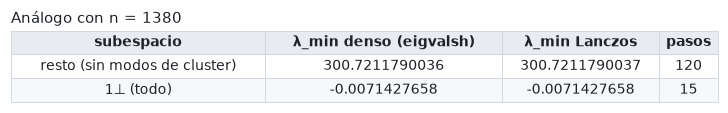

In [65]:
k_real = descripcion_general["k"]
g_analogo = 60
n_analogo = tamanos_enteros(k_real, g_analogo)
d_analogo = [[0] * 7 for _ in range(7)]
for a in range(7):
    d_analogo[a][a] = n_analogo[a] - 1
    for b in range(a + 1, 7):
        paso = paso_grado(k_real, a, b)
        d_analogo[a][b] = int(round(descripcion_general["grados"][a][b] / tamanos_general[b] * n_analogo[b] / paso)) * paso
        d_analogo[b][a] = d_analogo[a][b] * n_analogo[a] // n_analogo[b]
fases_reales = [float(p) for p in descripcion_general["fases"]]
analogo = GrafoImplicito(descripcion_compacta(k_real, g_analogo, d_analogo, fases_reales), Arreglos())
theta_analogo = np.repeat(fases_reales, n_analogo)
H_analogo = hessiano_denso(adyacencia_densa(k_real, g_analogo, d_analogo), theta_analogo)

x_prueba = np.random.default_rng(1).standard_normal(analogo.n)
diferencia = np.abs(analogo.producto_hessiano(x_prueba) - H_analogo @ x_prueba).max()
print("|H·x implícito − H·x denso|:", f"{diferencia:.1e}")


def complemento(base):
    """Base ortonormal del complemento de las columnas de base."""
    Q, _ = np.linalg.qr(np.hstack([base, np.eye(base.shape[0])]))
    return Q[:, base.shape[1]:]


indicadoras = np.zeros((analogo.n, 7))
for a in range(7):
    indicadoras[analogo.inicios[a]: analogo.inicios[a] + n_analogo[a], a] = 1
casos = [("resto (sin modos de cluster)", analogo.quitar_medias_cluster, complemento(indicadoras)),
         ("1⊥ (todo)", analogo.quitar_media, complemento(np.ones((analogo.n, 1))))]
filas = []
for nombre, proyectar, C in casos:
    exacto = np.linalg.eigvalsh(C.T @ H_analogo @ C).min()
    r = lanczos(analogo.producto_hessiano, proyectar, analogo.arreglos.aleatorio(analogo.n, 0),
                analogo.arreglos, iteraciones=2000, cada=5, tolerancia=1e-9)
    filas.append([nombre, f"{exacto:.10f}", f"{r['menor']:.10f}", r["pasos"]])
mostrar_tabla(["subespacio", "λ_min denso (eigvalsh)", "λ_min Lanczos", "pasos"], filas,
              titulo=f"Análogo con n = {analogo.n}")

Coinciden. Además, el análogo con $n = 1380$ es **inestable** ($\lambda_{\min} < 0$ en $\mathbf 1^\perp$):
con las mismas densidades redondeadas a un $n$ chico, el equilibrio no sobrevive. Es otra vez el
pliegue de la sección 7.3.

### 10.2 La validación del grafo de $3\cdot10^7$ vértices

El script corre los cinco chequeos sobre el grafo real. Como el subespacio de los modos de cluster es
invariante (por el chequeo 1), los pasos 3 y 4 ya dan $\lambda_{\min}(H|_{\mathbf 1^\perp})$; el paso 5
lo confirma sin suponer nada. Cada producto recorre vectores de 240 MB con sumas prefijas: es un
cálculo limitado por la memoria, así que una GPU ayuda mucho (también en float64).

In [66]:
# biblioteca
def informar_lanczos(etiqueta, inicio):
    """Función que imprime el progreso de Lanczos."""
    def imprimir(fila):
        print(f"  [{etiqueta}] paso {fila['paso']:6d}  θ_min = {fila['menor']:.10e}  residuo = {fila['residuo']:.2e}"
              f"  θ_max = {fila['mayor']:.4e}  ({time.time() - inicio:.0f} s)", flush=True)
    return imprimir


def correr_lanczos(grafo, proyectar, etiqueta, args, semilla):
    """Lanczos de H con la proyección dada, desde un vector gaussiano."""
    inicio = time.time()
    resultado = lanczos(grafo.producto_hessiano, proyectar, grafo.arreglos.aleatorio(grafo.n, semilla),
                        grafo.arreglos, args.iteraciones, cada=args.cada, tolerancia=args.tolerancia,
                        informar=informar_lanczos(etiqueta, inicio))
    resultado["segundos"] = time.time() - inicio
    return resultado

In [67]:
%%writefile externos/validar_grafo.py
"""Validación ciega (sección 10.2): grados, velocidad, modos de cluster y Lanczos del grafo real.

Lee la descripción compacta de resultados/<archivo> (grafos_s7.json: el general; grafo_simetrico_s7.json: el
simétrico) y guarda resultados/validacion_s7_n<n>.json.
Uso: python externos/validar_grafo.py [--archivo grafo_simetrico_s7.json] [--dispositivo numpy|cpu|cuda]
"""
import argparse
import sys
import time
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parent))
from biblioteca_s7 import *  # noqa: E402,F403


def main():
    """Corre los cinco chequeos y guarda el resultado."""
    parser = argparse.ArgumentParser()
    parser.add_argument("--archivo", default="grafos_s7.json")
    parser.add_argument("--dispositivo", default="numpy", help="numpy, cpu o cuda")
    parser.add_argument("--iteraciones", type=int, default=30000)
    parser.add_argument("--cada", type=int, default=50)
    parser.add_argument("--tolerancia", type=float, default=1e-6, help="residuo relativo para cortar Lanczos")
    parser.add_argument("--semilla", type=int, default=0)
    args = parser.parse_args()

    fila = elegir_grafo(cargar_json(args.archivo))
    descripcion = fila["grafo"]
    certificado = fila["certificado"]
    arreglos = Arreglos(None if args.dispositivo == "numpy" else args.dispositivo)
    inicio = time.time()
    grafo = GrafoImplicito(descripcion, arreglos)
    n = grafo.n
    print(f"grafo h = {fila['h']}, n = {n}, k = {grafo.k}, g = {grafo.g}, μ = {certificado['mu_exacto']}"
          f" ({args.dispositivo})", flush=True)

    t0 = time.time()
    grafo.producto_hessiano(grafo.arreglos.aleatorio(n, 1))
    segundos_producto = time.time() - t0
    print(f"un producto H·x: {segundos_producto:.2f} s", flush=True)

    minimos, maximos = grados_medidos(grafo)
    esperados = np.array(descripcion["grados"])
    grados_ok = bool((minimos == esperados).all() and (maximos == esperados).all())
    grado_min = int((esperados.sum(axis=1)).min())
    print(f"1. grados exactos: {grados_ok}   grado mínimo δ = {grado_min}", flush=True)

    velocidad = np.abs(arreglos.a_numpy(grafo.velocidad())).max()
    print(f"2. max |θ̇| = {velocidad:.3e}", flush=True)

    Q = cociente_implicito(grafo)
    diferencia = float(np.abs(Q - cociente_formula(descripcion)).max())
    autovalores_Q = np.linalg.eigvalsh((Q + Q.T) / 2)
    print(f"3. modos de cluster: |Q implícita − fórmula| = {diferencia:.2e}", flush=True)
    rotacion = int(np.argmin(np.abs(autovalores_Q)))
    menor_cluster = float(np.delete(autovalores_Q, rotacion).min())

    cota = n * min(certificado["margen fourier / n (cota inf)"], certificado["margen cero / n (cota inf)"])
    print(f"4. resto de los modos (cota de Gershgorin certificada: λ ≥ {cota:.6e})", flush=True)
    resto = correr_lanczos(grafo, grafo.quitar_medias_cluster, "resto", args, args.semilla)
    print(f"5. Lanczos en 1^⊥ (esperado: menor autovalor de Q = {menor_cluster:.10e})", flush=True)
    completo = correr_lanczos(grafo, grafo.quitar_media, "1^⊥", args, args.semilla + 1)

    estable = menor_cluster > 0 and resto["menor"] > 0
    salida = {
        "h": fila["h"], "n": n, "dispositivo": args.dispositivo, "mu_exacto": certificado["mu_exacto"],
        "segundos_producto": segundos_producto,
        "grados_ok": grados_ok, "grado_min": grado_min, "max_velocidad": float(velocidad),
        "Q_diferencia": diferencia, "autovalores_Q": autovalores_Q.tolist(),
        "menor_cluster": menor_cluster, "cota_gershgorin": cota, "resto": resto, "completo": completo,
        "estable": bool(estable), "segundos": time.time() - inicio,
    }
    print("guardado en", guardar_json(f"validacion_s7_n{n}.json", salida))


if __name__ == "__main__":
    main()

Overwriting externos/validar_grafo.py


<table>
<tr><th align="left">▶ Cómo correr <code>externos/validar_grafo.py</code> (desde la carpeta del notebook)</th></tr>
<tr><td align="left"><b>Máquina:</b> GPU con torch + CUDA (GTX 1080 Ti: 0.7 s por producto, ~1.5 min en total) o CPU sin torch<br><b>Tiempo:</b> CPU: ~4.5 s por producto H·x, ~12 min en total, ~3 GB de RAM<br><b>Salida:</b> <code>resultados/validacion_s7_n30000004.json</code></td></tr>
<tr><td align="left"><pre>nohup python externos/validar_grafo.py --dispositivo cuda &gt; validacion_n3e7.log 2&gt;&amp;1 &amp;</pre></td></tr>
<tr><td align="left"><pre>python externos/validar_grafo.py --dispositivo numpy</pre></td></tr>
</table>

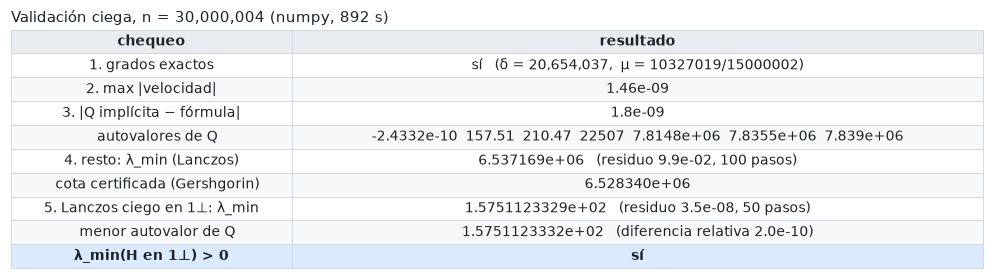

λ_min general: 157.5112333   (referencia: 157.5112333, coincide)


In [68]:
NOMBRE_VALIDACION = f"validacion_s7_n{descripcion_general['n']}.json"
if not existe_resultado(NOMBRE_VALIDACION) and CORRER["validacion_n3e7"]:
    correr_paso("validar_grafo.py", f"--dispositivo {DISPOSITIVO}", "validación ciega n = 3·10⁷")


def mostrar_validacion(v):
    """Tabla con los cinco chequeos de la validación ciega."""
    c = v["completo"]
    relativa = abs(c["menor"] - v["menor_cluster"]) / v["menor_cluster"]
    mostrar_tabla(["chequeo", "resultado"], [
        ["1. grados exactos", f"{si_no(v['grados_ok'])}   (δ = {v['grado_min']:,},  μ = {v['mu_exacto']})"],
        ["2. max |velocidad|", f"{v['max_velocidad']:.2e}"],
        ["3. |Q implícita − fórmula|", f"{v['Q_diferencia']:.1e}"],
        ["   autovalores de Q", "  ".join(f"{a:.5g}" for a in v["autovalores_Q"])],
        ["4. resto: λ_min (Lanczos)", f"{v['resto']['menor']:.6e}   (residuo {v['resto']['residuo']:.1e}, {v['resto']['pasos']} pasos)"],
        ["   cota certificada (Gershgorin)", f"{v['cota_gershgorin']:.6e}"],
        ["5. Lanczos ciego en 1⊥: λ_min", f"{c['menor']:.10e}   (residuo {c['residuo']:.1e}, {c['pasos']} pasos)"],
        ["   menor autovalor de Q", f"{v['menor_cluster']:.10e}   (diferencia relativa {relativa:.1e})"],
        ["λ_min(H en 1⊥) > 0", si_no(v["estable"])],
    ], titulo=f"Validación ciega, n = {v['n']:,} ({v['dispositivo']}, {v['segundos']:.0f} s)", resaltar=[8])


if existe_resultado(NOMBRE_VALIDACION):
    validacion_general = cargar_json(NOMBRE_VALIDACION)
    mostrar_validacion(validacion_general)
    comparar("λ_min general", round(validacion_general["menor_cluster"], 7), tolerancia=1e-6)
else:
    validacion_general = None
    print("La validación del grafo de 3·10⁷ no se corrió (CORRER['validacion_n3e7'] = False).")
    print("Para correrla afuera: python externos/validar_grafo.py --dispositivo cuda (o numpy).")
    print("La misma validación corre en vivo sobre el grafo simétrico en la sección 13.7.")

**Lectura** (de la corrida de referencia).
- **Grados:** exactos. **Velocidad:** $\sim10^{-9}$, error de redondeo para fuerzas de tamaño $\sim n$.
- **$Q$:** coincide con la fórmula. Sus autovalores son 0 (la rotación), luego **157.5** y 210.5 (los
  modos casi neutros de S7), y después $2.3\cdot10^4$ y tres $\approx 7.8\cdot10^6$.
- **Resto:** $\lambda_{\min} \approx 6.537\cdot10^6$, apenas arriba de la cota de Gershgorin
  $6.528\cdot10^6$: la cota es casi justa.
- **Lanczos ciego en $\mathbf 1^\perp$:** desde un vector al azar llega a $\lambda_{\min} = 157.511$, el
  menor autovalor de $Q$, con diferencia relativa $\sim10^{-10}$, en solo 50 pasos. El espectro de $H$ en
  $\mathbf 1^\perp$ son unos pocos autovalores aislados y una banda lejana, y Lanczos atrapa los
  aislados enseguida.

Dividido por $n$, $157.5/n \approx 5.25\cdot10^{-6}$: es el mismo menor autovalor normalizado de $L$
que dio la Fase 1.

### 10.3 El espectro completo por bloques de Fourier

**Lo que Lanczos no puede dar.** Cada valor de Ritz es **mayor o igual** que el verdadero menor
autovalor ($T_k$ es la compresión de $H$ a un subespacio). El residuo garantiza que hay un autovalor
cerca de $\vartheta$, pero no descarta uno más chico que el vector inicial no "vio". Por eso, en el paso
4, "Lanczos $\ge$ cota" es **consistente** con el certificado pero no lo prueba. La precisión de float64
no es el problema (el error es $\sim10^{-16}\|H\|$); el problema es que la cota es de un solo lado.

**La estructura circulante.** Con la descomposición de la sección 9.1, $H$ se parte en $g$ matrices
hermíticas $H_m$ de $23\times23$ y el espectro de $H$ es la unión de sus espectros. Tres detalles:
- **fórmula cerrada:** $\hat N(m) = e^{\mathrm i\pi m(t-1)/g}\sin(\pi mt/g)/\sin(\pi m/g)$ (y $t$ si
  $m = 0$); los productos $m\cdot t$ se reducen módulo $2g$ en enteros antes de multiplicar por $\pi/g$,
  así los ángulos no pierden precisión;
- **mitad de las frecuencias:** $H_{g-m} = \overline{H_m}$ tiene los mismos autovalores; alcanza con
  $m = 0, \dots, \lfloor g/2\rfloor$;
- **$m = 0$ contiene los modos de cluster:** con la base $C$ ($K\times7$) de los vectores constantes en
  los bloques de cada cluster, $C^\top H_0 C$ da los 7 autovalores de $Q$, y el complemento ($K - 7 = 16$
  direcciones) da el resto de $m = 0$. El acople $C^\top H_0 C^\perp$ tiene que ser 0.

**Antes de usarlo, se valida:** el producto $Hx$ por bloques (FFT de cada bloque, $H_m$ en cada
frecuencia, FFT inversa) se compara con el producto implícito de 10.1, que solo usa la regla de
adyacencia.

In [69]:
# biblioteca
def inicios_bloques(k):
    """Índice del primer bloque de cada cluster dentro de los K bloques."""
    return np.cumsum([0] + list(k[:-1]))


def transformada_intervalos(tabla, g, frecuencias):
    """N̂_ij(m) = Σ_{s<t_ij} e^{2πi m s/g} con forma (M, k_a, k_b), por la fórmula de la suma geométrica.

    N̂ = e^{iπm(t−1)/g} sin(πmt/g) / sin(πm/g), y t si m = 0. Los productos m·t se reducen mod 2g en
    enteros, así los ángulos quedan en [0, 2π) sin perder precisión aunque m·t sea grande.
    """
    t = np.asarray(tabla, dtype=np.int64)[None, :, :]
    m = np.asarray(frecuencias, dtype=np.int64)[:, None, None]
    fase = np.pi * ((m * (t - 1)) % (2 * g)) / g
    numerador = np.sin(np.pi * ((m * t) % (2 * g)) / g)
    denominador = np.sin(np.pi * m / g)
    cociente = np.divide(numerador, denominador, out=np.zeros(numerador.shape), where=denominador != 0)
    return np.where(m == 0, t.astype(float), np.exp(1j * fase) * cociente)


def bloques_fourier(descripcion, frecuencias):
    """Bloques H_m (M × K × K, hermíticos) del Hessiano, para las frecuencias dadas."""
    k = list(descripcion["k"])
    g = int(descripcion["g"])
    d = np.array(descripcion["grados"], dtype=float)
    fases = np.array([float(p) for p in descripcion["fases"]])
    coseno = np.cos(fases[:, None] - fases[None, :])
    frecuencias = np.asarray(frecuencias, dtype=np.int64)
    inicios = inicios_bloques(k)
    K = sum(k)
    H = np.zeros((len(frecuencias), K, K), dtype=complex)
    clique = np.where(frecuencias == 0, g, 0).astype(float)
    for a, ka in enumerate(k):
        indices = np.arange(inicios[a], inicios[a] + ka)
        H[:, indices[:, None], indices[None, :]] = -clique[:, None, None] * np.ones((ka, ka))
        diagonal = float((d[a] * coseno[a]).sum())
        H[:, indices, indices] = diagonal - (clique[:, None] - 1)
    for clave, tabla in descripcion["tablas"].items():
        a, b = (int(c) for c in clave.split(","))
        N = transformada_intervalos(tabla, g, frecuencias)
        filas = slice(inicios[a], inicios[a] + k[a])
        columnas = slice(inicios[b], inicios[b] + k[b])
        H[:, filas, columnas] = -coseno[a, b] * N
        H[:, columnas, filas] = -coseno[a, b] * np.conj(N).transpose(0, 2, 1)
    return H


def producto_fourier(descripcion, x, lote=4096):
    """H·x por bloques: FFT en cada bloque Z_g, H_m en cada frecuencia y FFT inversa."""
    K = sum(descripcion["k"])
    g = int(descripcion["g"])
    X = np.fft.fft(np.asarray(x, dtype=float).reshape(K, g), axis=1)
    Y = np.empty_like(X)
    for inicio in range(0, g, lote):
        m = np.arange(inicio, min(inicio + lote, g))
        Y[:, m] = np.einsum("mij,jm->im", bloques_fourier(descripcion, m), X[:, m])
    return np.fft.ifft(Y, axis=1).real.reshape(-1)


def base_cluster(k):
    """Matriz K × len(k): columna a = indicadora de los bloques del cluster a, normalizada."""
    C = np.zeros((sum(k), len(k)))
    inicios = inicios_bloques(k)
    for a, ka in enumerate(k):
        C[inicios[a]: inicios[a] + ka, a] = 1 / np.sqrt(ka)
    return C


def espectro_fourier(descripcion, lote=4096, informar=None):
    """Todos los autovalores de H, agrupados.

    - "cluster": los de los modos constantes por cluster (H_0 restringida a la base de clusters);
    - "cero": los del resto de H_0 (diferencias entre bloques de un mismo cluster);
    - "minimos": el menor autovalor de H_m para cada m de "frecuencias" (1, …, ⌊g/2⌋);
    - "acople": max |Cᵀ H_0 C⊥|, que es 0 si los modos de cluster son invariantes (grados exactos);
    - "maximo": el mayor autovalor de H.
    `informar(hechas, total)` recibe el progreso.
    """
    k = list(descripcion["k"])
    g = int(descripcion["g"])
    H0 = bloques_fourier(descripcion, [0])[0].real
    C = base_cluster(k)
    completa, _ = np.linalg.qr(C, mode="complete")
    resto = completa[:, len(k):]
    cluster = np.linalg.eigvalsh(C.T @ H0 @ C)
    cero = np.linalg.eigvalsh(resto.T @ H0 @ resto)
    frecuencias = np.arange(1, g // 2 + 1)
    minimos = np.empty(len(frecuencias))
    maximo = max(cluster.max(), cero.max())
    for inicio in range(0, len(frecuencias), lote):
        tramo = slice(inicio, min(inicio + lote, len(frecuencias)))
        valores = np.linalg.eigvalsh(bloques_fourier(descripcion, frecuencias[tramo]))
        minimos[tramo] = valores[:, 0]
        maximo = max(maximo, float(valores[:, -1].max()))
        if informar is not None:
            informar(tramo.stop, len(frecuencias))
    return {
        "cluster": cluster, "cero": cero, "frecuencias": frecuencias, "minimos": minimos,
        "acople": float(np.abs(C.T @ H0 @ resto).max()), "maximo": float(maximo),
    }


def curva_minimos(frecuencias, minimos, g, puntos=2000):
    """(m/g, menor autovalor) reducida a ~`puntos` tramos, tomando el mínimo de cada tramo."""
    tramos = np.array_split(np.arange(len(minimos)), min(puntos, len(minimos)))
    abscisas = []
    valores = []
    for tramo in tramos:
        mejor = tramo[np.argmin(minimos[tramo])]
        abscisas.append(float(frecuencias[mejor] / g))
        valores.append(float(minimos[mejor]))
    return abscisas, valores


def chequear_producto(descripcion, grafo, semillas, lote):
    """Máximo error relativo ‖H x (Fourier) − H x (implícito)‖ / ‖H x‖ sobre vectores gaussianos."""
    errores = []
    for semilla in semillas:
        x = np.random.default_rng(semilla).standard_normal(grafo.n)
        implicito = grafo.arreglos.a_numpy(grafo.producto_hessiano(grafo.arreglos.desde(x)))
        fourier = producto_fourier(descripcion, x, lote=lote)
        errores.append(float(np.linalg.norm(fourier - implicito) / np.linalg.norm(implicito)))
    return max(errores)


def informar_espectro(inicio, lote):
    """Función que imprime el progreso de la diagonalización (cada 50 lotes)."""
    def imprimir(hechas, total):
        if hechas == total or (hechas // lote) % 50 == 0:
            print(f"  {hechas}/{total} frecuencias ({time.time() - inicio:.0f} s)", flush=True)
    return imprimir

**Chequeo** de la fórmula cerrada contra la suma directa, y de los bloques contra `hessiano_fourier` de
la sección 9.1, en el grafo general:

In [70]:
g_general = descripcion_general["g"]
error_formula = 0.0
error_bloques = 0.0
for m in [0, 1, 2, g_general // 3, g_general // 2]:
    t = descripcion_general["tablas"]["0,3"][0][0]
    directa = np.exp(2j * np.pi * m * np.arange(t) / g_general).sum()
    error_formula = max(error_formula, abs(transformada_intervalos([[t]], g_general, [m])[0, 0, 0] - directa) / t)
    bloque = hessiano_fourier(descripcion_general["k"], g_general, descripcion_general["grados"], fases_reales, m)
    error_bloques = max(error_bloques, np.abs(bloques_fourier(descripcion_general, [m])[0] - bloque).max()
                        / np.abs(bloque).max())
print("fórmula cerrada contra suma directa (relativo):", f"{error_formula:.1e}")
print("bloques_fourier contra hessiano_fourier (relativo):", f"{error_bloques:.1e}")

fórmula cerrada contra suma directa (relativo): 8.4e-15
bloques_fourier contra hessiano_fourier (relativo): 2.6e-15


### 10.4 El espectro del grafo general

Son 652 175 matrices de $23\times23$: unos 2 minutos en CPU, con ~4 GB de memoria (por el producto de
control con vectores de $3\cdot10^7$).

In [71]:
%%writefile externos/espectro.py
"""Espectro completo por bloques de Fourier (sección 10.4), comparado con las cotas del certificado.

Uso: python externos/espectro.py [--archivo grafo_simetrico_s7.json]
"""
import argparse
import sys
import time
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parent))
from biblioteca_s7 import *  # noqa: E402,F403


def main():
    """Calcula el espectro, lo compara con el certificado y guarda resultados/espectro_s7_n<n>.json."""
    parser = argparse.ArgumentParser()
    parser.add_argument("--archivo", default="grafos_s7.json")
    parser.add_argument("--lote", type=int, default=4096, help="frecuencias por lote")
    parser.add_argument("--puntos", type=int, default=2000, help="puntos de la curva guardada")
    args = parser.parse_args()

    fila = elegir_grafo(cargar_json(args.archivo))
    descripcion = fila["grafo"]
    certificado = fila["certificado"]
    inicio = time.time()
    grafo = GrafoImplicito(descripcion, Arreglos())
    n = grafo.n
    print(f"grafo de {args.archivo}: n = {n}, k = {grafo.k}, g = {grafo.g}", flush=True)

    error = chequear_producto(descripcion, grafo, [0, 1], args.lote)
    print(f"1. H·x por Fourier contra el implícito: error relativo {error:.1e}", flush=True)

    espectro = espectro_fourier(descripcion, lote=args.lote, informar=informar_espectro(time.time(), args.lote))
    cluster = espectro["cluster"]
    formula = np.linalg.eigvalsh(cociente_formula(descripcion))
    rotacion = int(np.argmin(np.abs(cluster)))
    menor_cluster = float(np.delete(cluster, rotacion).min())
    menor_cero = float(espectro["cero"].min())
    posicion = int(np.argmin(espectro["minimos"]))
    menor_fourier = float(espectro["minimos"][posicion])
    cota_cero = n * certificado["margen cero / n (cota inf)"]
    cota_fourier = n * certificado["margen fourier / n (cota inf)"]
    # la cota de m = 0 puede ser exacta (cluster sin acople), así que se compara con tolerancia de redondeo
    tolerancia = 1e-12
    respeta_cotas = (menor_cero >= cota_cero * (1 - tolerancia)
                     and menor_fourier >= cota_fourier * (1 - tolerancia))
    estable = menor_cluster > 0 and menor_cero > 0 and menor_fourier > 0
    abscisas, valores = curva_minimos(espectro["frecuencias"], espectro["minimos"], grafo.g, args.puntos)
    salida = {
        "archivo": args.archivo, "n": n, "g": grafo.g, "mu_exacto": certificado["mu_exacto"],
        "error_producto": error, "acople_cluster": espectro["acople"],
        "autovalores_cluster": cluster.tolist(), "autovalores_Q_grados": formula.tolist(),
        "diferencia_Q": float(np.abs(cluster - formula).max()),
        "menor_cluster": menor_cluster, "autovalores_cero": espectro["cero"].tolist(),
        "menor_cero": menor_cero, "cota_cero": cota_cero,
        "menor_fourier": menor_fourier, "m_menor_fourier": int(espectro["frecuencias"][posicion]),
        "cota_fourier": cota_fourier,
        "maximo": espectro["maximo"], "estable": bool(estable), "respeta_cotas": bool(respeta_cotas),
        "curva_m_sobre_g": abscisas, "curva_menor_autovalor": valores,
        "segundos": time.time() - inicio,
    }
    print(f"λ_min = {min(menor_cluster, menor_cero, menor_fourier):.6e}, respeta las cotas: {respeta_cotas}"
          f"   ({time.time() - inicio:.0f} s)", flush=True)
    print("guardado en", guardar_json(f"espectro_s7_n{n}.json", salida))


if __name__ == "__main__":
    main()

Overwriting externos/espectro.py


<table>
<tr><th align="left">▶ Cómo correr <code>externos/espectro.py</code> (desde la carpeta del notebook)</th></tr>
<tr><td align="left"><b>Máquina:</b> CPU (numpy; no hace falta GPU)<br><b>Tiempo:</b> grafo general: ~2 min, ~4 GB de RAM · grafo simétrico: ~1 s<br><b>Salida:</b> <code>resultados/espectro_s7_n&lt;n&gt;.json</code></td></tr>
<tr><td align="left"><pre>python externos/espectro.py</pre></td></tr>
<tr><td align="left"><pre>python externos/espectro.py --archivo grafo_simetrico_s7.json</pre></td></tr>
</table>

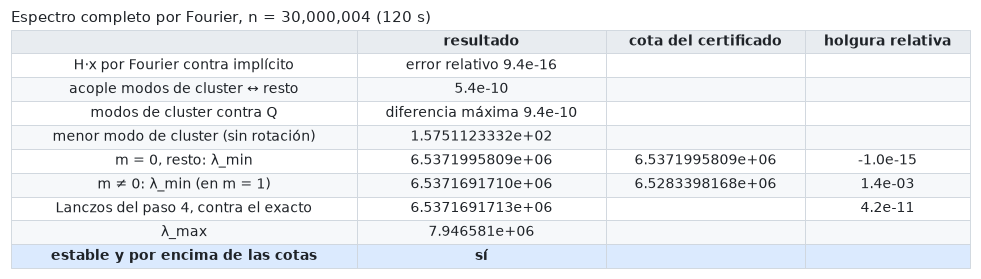

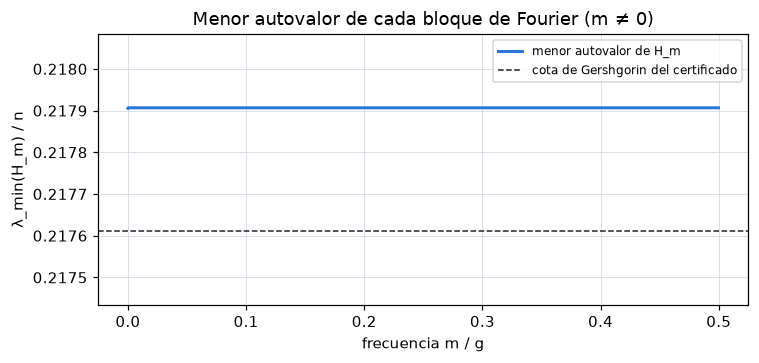

In [72]:
NOMBRE_ESPECTRO = f"espectro_s7_n{descripcion_general['n']}.json"
if not existe_resultado(NOMBRE_ESPECTRO) and CORRER["espectro_n3e7"]:
    correr_paso("espectro.py", "", "espectro n = 3·10⁷")


def mostrar_espectro(e, lanczos_resto=None):
    """Tabla del espectro completo contra las cotas del certificado, y la curva de mínimos por frecuencia."""
    filas = [
        ["H·x por Fourier contra implícito", f"error relativo {e['error_producto']:.1e}", "", ""],
        ["acople modos de cluster ↔ resto", f"{e['acople_cluster']:.1e}", "", ""],
        ["modos de cluster contra Q", f"diferencia máxima {e['diferencia_Q']:.1e}", "", ""],
        ["menor modo de cluster (sin rotación)", f"{e['menor_cluster']:.10e}", "", ""],
        ["m = 0, resto: λ_min", f"{e['menor_cero']:.10e}", f"{e['cota_cero']:.10e}",
         f"{e['menor_cero'] / e['cota_cero'] - 1:.1e}"],
        [f"m ≠ 0: λ_min (en m = {e['m_menor_fourier']})", f"{e['menor_fourier']:.10e}", f"{e['cota_fourier']:.10e}",
         f"{e['menor_fourier'] / e['cota_fourier'] - 1:.1e}"],
    ]
    if lanczos_resto is not None:
        exacto = min(e["menor_fourier"], e["menor_cero"])
        filas.append(["Lanczos del paso 4, contra el exacto", f"{lanczos_resto:.10e}", "", f"{lanczos_resto / exacto - 1:.1e}"])
    filas.append(["λ_max", f"{e['maximo']:.6e}", "", ""])
    filas.append(["estable y por encima de las cotas", si_no(e["estable"] and e["respeta_cotas"]), "", ""])
    mostrar_tabla(["", "resultado", "cota del certificado", "holgura relativa"], filas,
                  titulo=f"Espectro completo por Fourier, n = {e['n']:,} ({e['segundos']:.0f} s)",
                  resaltar=[len(filas) - 1])

    fig, eje = plt.subplots(figsize=(7, 3.4))
    curva_m = np.array(e["curva_menor_autovalor"]) / e["n"]
    cota = e["cota_fourier"] / e["n"]
    eje.plot(e["curva_m_sobre_g"], curva_m, color=COLORES[0], lw=2, label="menor autovalor de H_m")
    eje.axhline(cota, color=TINTA, lw=1, ls="--", label="cota de Gershgorin del certificado")
    separacion = curva_m.min() - cota
    eje.set_ylim(cota - 0.6 * separacion, curva_m.max() + 0.6 * separacion)
    eje.set(xlabel="frecuencia m / g", ylabel="λ_min(H_m) / n", title="Menor autovalor de cada bloque de Fourier (m ≠ 0)")
    eje.grid(color=BORDE, lw=0.5)
    eje.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


if existe_resultado(NOMBRE_ESPECTRO):
    resto_lanczos = validacion_general["resto"]["menor"] if validacion_general else None
    mostrar_espectro(cargar_json(NOMBRE_ESPECTRO), resto_lanczos)
else:
    print("El espectro del grafo de 3·10⁷ no se corrió (CORRER['espectro_n3e7'] = False).")
    print("Para correrlo afuera: python externos/espectro.py")
    print("El mismo cálculo corre en vivo sobre el grafo simétrico en la sección 13.8.")

**Lectura** (de la corrida de referencia).
- **La descomposición es correcta:** el producto por bloques coincide con el implícito a $\sim10^{-15}$,
  el acople de los modos de cluster con el resto es despreciable y los 7 autovalores de $C^\top H_0C$ son
  los de $Q$.
- **Gershgorin es casi exacta en $m \ne 0$:** el verdadero mínimo supera la cota en solo 0.14%, y está en
  $m = 1$. La curva es casi plana: la parte principal de $H_m$ es la diagonal ($\approx 0.22\,n$), y los
  acoples entre clusters son chicos porque las densidades intermedias están entre clusters casi a 90°
  ($\cos\approx0$) y las demás son 0 o 1 (sin oscilación en $m$).
- **En $m = 0$ la cota es exacta:** la pone W, cuyas tablas con los demás clusters son constantes, así que
  en las diferencias entre sus bloques no actúa ningún acople y el autovalor es justo
  $\sum_b d_{Wb}\cos_{Wb} + 1$, que es lo que calcula la cota.

Ningún autovalor queda debajo de su cota: el certificado es consistente con el espectro completo, no
solo con una cota de un lado.

## 11. La dinámica del grafo general

El certificado prueba que el estado $\theta^*$ es un **mínimo local estricto**: toda perturbación
suficientemente chica vuelve. No dice **cuán chica**. Acá simulamos la dinámica, en tiempo normalizado:
$$\dot\theta_u = \frac1n\sum_v W_{uv}\sin(\theta_v - \theta_u).$$

**Escalas de tiempo.** Linealizando en $\theta^*$, $\dot{\delta\theta} = -(H/n)\,\delta\theta$, así que cada
modo decae a tasa $\lambda/n$. Por la sección 10:
- los modos **dentro de los clusters** (el resto) tienen $\lambda/n \ge 0.218$: se apagan en
  $t \sim 10$–$50$;
- los **modos de cluster** tienen tasas $157.5/n \approx 5.3\cdot10^{-6}$, $210.5/n \approx 7\cdot10^{-6}$,
  $7.5\cdot10^{-4}$ y $\approx 0.26$: los dos primeros tardan $t \sim 10^5$–$10^6$.

Simular el grafo completo hasta $t\sim10^6$ es imposible (cada paso son varios productos $Wy$ de
$3\cdot10^7$ entradas). Pero no hace falta:

**Reducción exacta a los clusters.** Si todos los vértices de cada cluster tienen la misma fase $y_a$,
como cada vértice de $a$ tiene **exactamente** $d_{ab}$ vecinos en $b$,
$$\dot y_a = \sum_b \frac{d_{ab}}{n}\sin(y_b - y_a),$$
y el estado sigue siendo constante por cluster. Es una ecuación por cluster, **exacta** para el grafo (no
una aproximación de campo medio), y se integra hasta $t = 10^7$ en milisegundos con un integrador para
sistemas rígidos (LSODA). Su Jacobiano en $\varphi$ tiene autovalores $-\lambda/n$ de los modos de cluster.

**Por qué esperamos una cuenca chica.** En las dos direcciones lentas la fuerza de retorno es
$\sim5\cdot10^{-6}\,y$, mientras que los términos no lineales son $\sim c\,y^2$ con $c$ de orden 1. Se
compensan en $y\sim10^{-5}$–$10^{-4}$: más lejos, la dinámica ya no vuelve. Es el mismo pliegue de la
sección 7.3, ahora visto como tamaño de la cuenca.

### 11.1 Perturbaciones de los clusters (en vivo)

`simular_clusters` perturba las fases de los clusters con amplitud $\delta$ en dos direcciones (la del
modo más lento y una al azar, sin componente de rotación) e integra hasta $t = 10^7$.

In [73]:
# biblioteca
def campo_clusters(descripcion):
    """(f, jac) de ẏ_a = Σ_b (d_ab/n) sin(y_b − y_a): Kuramoto normalizado restringido a estados constantes por cluster."""
    A = np.array(descripcion["grados"], dtype=float) / descripcion["n"]

    def f(t, y):
        return (A * np.sin(y[None, :] - y[:, None])).sum(axis=1)

    def jac(t, y):
        C = A * np.cos(y[None, :] - y[:, None])
        np.fill_diagonal(C, 0)
        return C - np.diag(C.sum(axis=1))

    return f, jac


def envolver(angulo):
    """Ángulo llevado a [−π, π)."""
    return (angulo + np.pi) % (2 * np.pi) - np.pi


def integrar_clusters(descripcion, y0, tiempo, puntos=120):
    """Integra la dinámica por clusters desde y0 (LSODA): tiempos, distancia a las fases certificadas y r."""
    fases = np.array([float(p) for p in descripcion["fases"]])
    x = np.array(descripcion["k"], dtype=float) / sum(descripcion["k"])
    f, jac = campo_clusters(descripcion)
    tiempos = np.concatenate([[0], np.logspace(-1, np.log10(tiempo), puntos)])
    sol = solve_ivp(f, (0, tiempo), y0, method="LSODA", jac=jac, rtol=1e-10, atol=1e-13, t_eval=tiempos)
    distancias = []
    radios = []
    for y in sol.y.T:
        diferencia = envolver(y - fases)
        distancias.append(float(np.abs(envolver(diferencia - np.sum(x * diferencia))).max()))
        radios.append(float(abs(np.sum(x * np.exp(1j * y)))))
    return sol.t, distancias, radios


def simular_clusters(descripcion, amplitudes, tiempo, semilla):
    """Para cada amplitud δ: perturba las fases de los clusters (al azar y en el modo más lento) e integra."""
    fases = np.array([float(p) for p in descripcion["fases"]])
    x = np.array(descripcion["k"], dtype=float) / sum(descripcion["k"])
    _, jac = campo_clusters(descripcion)
    autovalores, vectores = np.linalg.eig(jac(0, fases))
    orden = np.argsort(-autovalores.real)
    direcciones = {"modo más lento": vectores[:, orden[1]].real,
                   "al azar": np.random.default_rng(semilla).standard_normal(len(fases))}
    corridas = []
    for nombre, direccion in direcciones.items():
        direccion = direccion - np.sum(x * direccion)
        direccion = direccion / np.abs(direccion).max()
        for delta in amplitudes:
            inicio = time.time()
            tiempos, distancias, radios = integrar_clusters(descripcion, fases + delta * direccion, tiempo)
            r_final = radios[-1]
            print(f"  {nombre:15s} δ = {delta:.0e}: distancia final {distancias[-1]:.1e},  r final = {r_final:.4f}"
                  f"  ({time.time() - inicio:.1f} s)", flush=True)
            corridas.append({"direccion": nombre, "delta": delta, "t": tiempos.tolist(), "distancia": distancias,
                             "r_final": r_final})
    return corridas, -np.sort(autovalores.real)[::-1]

  modo más lento  δ = 1e-04: distancia final 8.3e-13,  r final = 0.0430  (0.0 s)


  modo más lento  δ = 3e-04: distancia final 2.5e+00,  r final = 1.0000  (0.0 s)


  modo más lento  δ = 1e-03: distancia final 2.5e+00,  r final = 1.0000  (0.0 s)


  modo más lento  δ = 1e-02: distancia final 2.5e+00,  r final = 1.0000  (0.0 s)


  modo más lento  δ = 1e-01: distancia final 2.5e+00,  r final = 1.0000  (0.0 s)


  al azar         δ = 1e-04: distancia final 4.7e-12,  r final = 0.0430  (0.0 s)


  al azar         δ = 3e-04: distancia final 2.7e-12,  r final = 0.0430  (0.0 s)


  al azar         δ = 1e-03: distancia final 2.5e+00,  r final = 1.0000  (0.0 s)


  al azar         δ = 1e-02: distancia final 2.5e+00,  r final = 1.0000  (0.0 s)


  al azar         δ = 1e-01: distancia final 2.5e+00,  r final = 1.0000  (0.0 s)


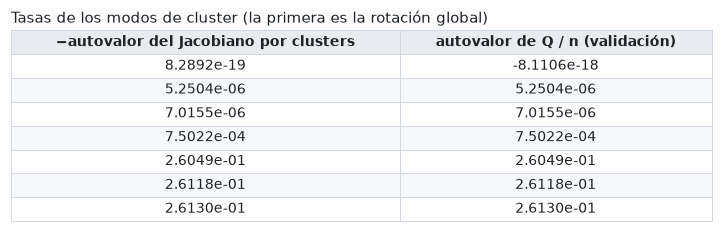

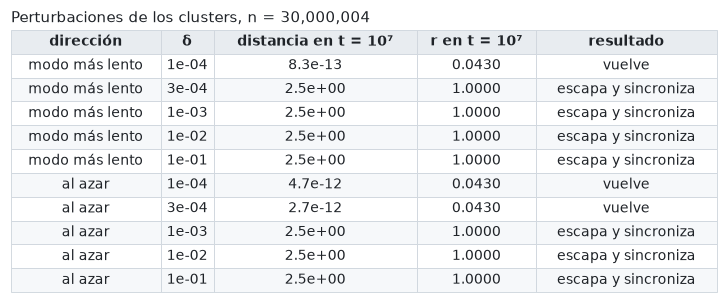

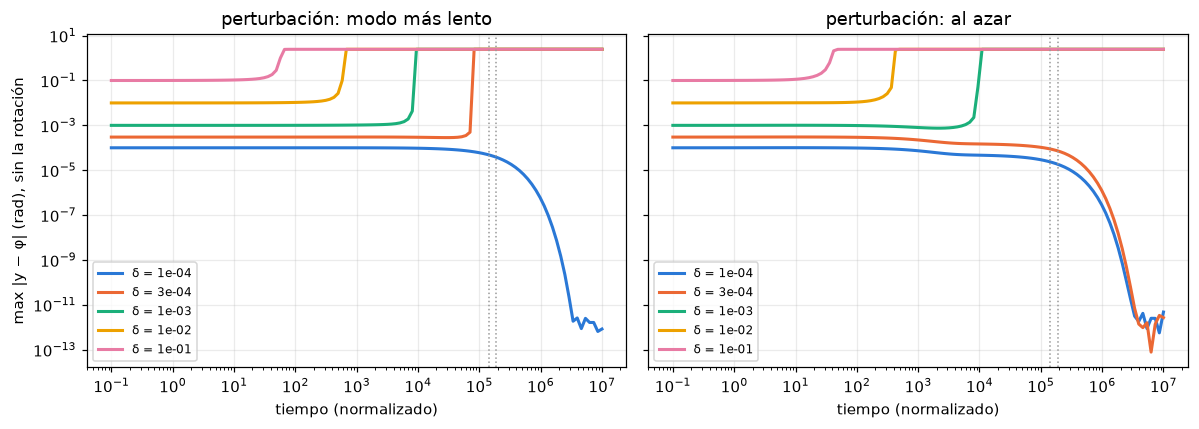

In [74]:
def mostrar_clusters(descripcion, autovalores_Q=None):
    """Tasas de los modos de cluster, tabla de perturbaciones y su gráfico (dinámica exacta por clusters)."""
    corridas, tasas = simular_clusters(descripcion, [1e-4, 3e-4, 1e-3, 1e-2, 1e-1], 1e7, 0)
    if autovalores_Q is not None:
        filas = []
        for tasa, lam in zip(tasas, sorted(autovalores_Q)):
            filas.append([f"{tasa:.4e}", f"{lam / descripcion['n']:.4e}"])
        mostrar_tabla(["−autovalor del Jacobiano por clusters", "autovalor de Q / n (validación)"], filas,
                      titulo="Tasas de los modos de cluster (la primera es la rotación global)")
    else:
        print("tasas de los modos de cluster:", "  ".join(f"{t:.3e}" for t in tasas))
    filas = []
    for c in corridas:
        vuelve = c["distancia"][-1] < 1e-6
        filas.append([c["direccion"], f"{c['delta']:.0e}", f"{c['distancia'][-1]:.1e}", f"{c['r_final']:.4f}",
                      "vuelve" if vuelve else "escapa y sincroniza"])
    mostrar_tabla(["dirección", "δ", "distancia en t = 10⁷", "r en t = 10⁷", "resultado"], filas,
                  titulo=f"Perturbaciones de los clusters, n = {descripcion['n']:,}")
    fig, ejes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for eje, direccion in zip(ejes, ["modo más lento", "al azar"]):
        propias = [c for c in corridas if c["direccion"] == direccion]
        for color, c in zip(COLORES, propias):
            eje.plot(c["t"][1:], c["distancia"][1:], color=color, lw=2, label=f"δ = {c['delta']:.0e}")
        for tasa in tasas[1:3]:
            eje.axvline(1 / tasa, color="0.6", lw=1, ls=":")
        eje.set(xscale="log", yscale="log", xlabel="tiempo (normalizado)", title=f"perturbación: {direccion}")
        eje.grid(alpha=0.25)
        eje.legend(fontsize=8)
    ejes[0].set_ylabel("max |y − φ| (rad), sin la rotación")
    plt.tight_layout()
    plt.show()


mostrar_clusters(descripcion_general, validacion_general["autovalores_Q"] if validacion_general else None)

- **Las tasas** son los autovalores de $Q$ de la validación divididos por $n$: la reducción a clusters es
  la misma dinámica.
- **$\delta = 10^{-4}$ vuelve** en las dos direcciones, en la escala $1/\lambda\sim2\cdot10^5$ (líneas
  punteadas), hasta distancias de $10^{-12}$.
- **$\delta \ge 3\cdot10^{-4}$ en la dirección lenta escapa:** la distancia se queda casi quieta un rato
  largo (la fuerza es diminuta) y después salta, con $r \to 1$: **sincroniza**. En la dirección al azar
  el borde está entre $3\cdot10^{-4}$ y $10^{-3}$ (esa dirección tiene parte en modos rápidos, que
  vuelven solos).

La cuenca de la trampa, en las direcciones lentas, mide entre $10^{-4}$ y $3\cdot10^{-4}$ radianes.

### 11.2 El grafo completo

La clase `Simulacion` integra la dinámica del grafo completo con RK4 ($dt = 0.5$) y los productos
implícitos de la sección 10, y mide $r = |\langle e^{\mathrm i\theta}\rangle|$ y la distancia al estado
certificado (sin la rotación global). Dos condiciones iniciales:
- **perturbado:** $\theta^*$ más ruido gaussiano de desvío $\sigma$, al que se le resta la media en cada
  cluster (solo se perturban los modos internos: los clusters enteros arrancan en su lugar);
- **azar:** fases uniformes en $[0, 2\pi)$.

Hasta $t = 60$ se integra el grafo completo; después, los modos internos ya decayeron
($e^{-0.22\cdot60}\sim10^{-6}$) y el estado es constante por cluster salvo errores de ese orden, así que se
sigue con la reducción exacta (`integrar_clusters`) desde las fases medias de cada cluster. La figura
muestra $r(t)$, la distancia, y fotos de las fases de 4000 vértices al azar.

In [75]:
# biblioteca
def fases_vertices(descripcion):
    """θ del estado certificado, vértice por vértice."""
    fases = [float(p) for p in descripcion["fases"]]
    return np.repeat(fases, np.array(descripcion["k"]) * descripcion["g"])


class Simulacion:
    """Kuramoto normalizado sobre el grafo implícito: θ̇ = (1/n) Σ_v W_uv sin(θ_v − θ_u)."""

    def __init__(self, descripcion, arreglos, muestra=4000, semilla=0):
        self.grafo = GrafoImplicito(descripcion, arreglos)
        self.arreglos = arreglos
        self.estrella = arreglos.desde(fases_vertices(descripcion))
        rng = np.random.default_rng(semilla)
        self.muestra = np.sort(rng.choice(self.grafo.n, size=min(muestra, self.grafo.n), replace=False))
        self.cluster_muestra = np.searchsorted(self.grafo.inicios, self.muestra, side="right") - 1

    def campo(self, theta):
        """θ̇ normalizado por n."""
        return self.grafo.velocidad_en(theta) / self.grafo.n

    def paso_rk4(self, theta, dt):
        """Un paso de Runge–Kutta 4."""
        k1 = self.campo(theta)
        k2 = self.campo(theta + 0.5 * dt * k1)
        k3 = self.campo(theta + 0.5 * dt * k2)
        k4 = self.campo(theta + dt * k3)
        return theta + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

    def medir(self, theta):
        """r = |⟨e^{iθ}⟩| y distancia (máxima, sin la rotación global) al estado certificado."""
        coseno, seno = self.arreglos.coseno_seno(theta)
        r = (float(coseno.mean()) ** 2 + float(seno.mean()) ** 2) ** 0.5
        diferencia = theta - self.estrella
        coseno, seno = self.arreglos.coseno_seno(diferencia)
        giro = np.arctan2(float(seno.mean()), float(coseno.mean()))
        envuelta = (diferencia - giro + np.pi) % (2 * np.pi) - np.pi
        return r, float(abs(envuelta).max())

    def correr(self, theta, tiempo, dt, fotos, t0=0.0, medir_cada=1):
        """Integra de t0 a `tiempo`; guarda r y la distancia cada `medir_cada` pasos y las fases de la muestra en `fotos`.

        Medir obliga a traer números a la CPU (en GPU, una espera por medición): con pasos chicos y tiempos
        largos conviene medir cada tanto.
        """
        pasos = int(round((tiempo - t0) / dt))
        tiempos_foto = set()
        for t in fotos:
            tiempos_foto.add(int(round((t - t0) / dt)))
        aviso = max(1, pasos // 10)
        serie = {"t": [], "r": [], "distancia": []}
        instantaneas = []
        inicio = time.time()
        for paso in range(pasos + 1):
            if paso % medir_cada == 0 or paso % aviso == 0 or paso == pasos:
                r, distancia = self.medir(theta)
                serie["t"].append(t0 + paso * dt)
                serie["r"].append(r)
                serie["distancia"].append(distancia)
            if paso in tiempos_foto:
                instantaneas.append((t0 + paso * dt, self.arreglos.tomar(theta, self.muestra)))
            if paso % aviso == 0:
                print(f"  t = {t0 + paso * dt:9.1f}  r = {r:.4f}  distancia al estado = {distancia:.2e}"
                      f"  ({time.time() - inicio:.0f} s)", flush=True)
            if paso < pasos:
                theta = self.paso_rk4(theta, dt)
        return serie, instantaneas, theta

    def medias_cluster(self, theta):
        """Fase media (circular) de cada cluster, como numpy."""
        coseno, seno = self.arreglos.coseno_seno(theta)
        medias = []
        for C, S in zip(self.grafo.por_cluster(coseno), self.grafo.por_cluster(seno)):
            medias.append(np.arctan2(float(S.mean()), float(C.mean())))
        return np.array(medias)

    def inicial_perturbado(self, ruido, semilla):
        """Estado certificado + ruido gaussiano con media 0 en cada cluster (solo modos dentro de los clusters)."""
        perturbacion = self.arreglos.aleatorio(self.grafo.n, semilla) * ruido
        return self.estrella + self.grafo.quitar_medias_cluster(perturbacion)

    def inicial_azar(self, semilla):
        """Fases uniformes en [0, 2π)."""
        return self.arreglos.desde(np.random.default_rng(semilla).uniform(0, 2 * np.pi, self.grafo.n))


def dibujar_simulacion(serie, continuacion, instantaneas, cluster_muestra, descripcion, titulo, archivo):
    """r(t) y distancia al estado certificado (grafo completo y continuación por clusters), y fotos de las fases."""
    nombres, colores = nombres_y_colores([float(p) for p in descripcion["fases"]])
    fig = plt.figure(figsize=(13, 6.6))
    grilla = fig.add_gridspec(2, len(instantaneas), height_ratios=[1, 1.15])
    eje_r = fig.add_subplot(grilla[0, : len(instantaneas) // 2])
    eje_d = fig.add_subplot(grilla[0, len(instantaneas) // 2:])
    distancias = serie["distancia"] + continuacion["distancia"]
    for eje, clave, color in ((eje_r, "r", "#2a78d6"), (eje_d, "distancia", "#eb6834")):
        eje.plot(serie["t"][1:], serie[clave][1:], color=color, lw=2, label="grafo completo (RK4)")
        eje.plot(continuacion["t"], continuacion[clave], color=color, lw=2, ls="--",
                 label=f"reducción a clusters desde t = {continuacion['desde']:g}")
        eje.axvline(continuacion["desde"], color=GRIS, lw=1, ls=":")
        eje.set(xscale="log", xlabel="tiempo (normalizado)")
        eje.grid(alpha=0.25)
        eje.legend(fontsize=7, loc="best")
    eje_r.set(ylabel="r = |⟨e^{iθ}⟩|", ylim=(0, 1.03), title="parámetro de orden (1 = sincronizado)")
    eje_d.set(ylabel="max |θ − θ*| (rad)", title="distancia al estado certificado θ* (sin la rotación)")
    if min(distancias) < 0.1 * max(distancias):
        eje_d.set_yscale("log")
    rng = np.random.default_rng(1)
    color_vertices = np.array([colores[c] for c in cluster_muestra])
    for columna, (t, fases) in enumerate(instantaneas):
        eje = fig.add_subplot(grilla[1, columna], projection="polar")
        radio = 1 + 0.08 * rng.standard_normal(len(fases))
        eje.scatter(fases, radio, s=4, c=color_vertices, alpha=0.6, linewidths=0)
        eje.set(ylim=(0, 1.35), yticks=[], title=f"t = {t:g}")
        eje.set_xticks(np.arange(4) * np.pi / 2, ["0", "π/2", "π", "3π/2"], fontsize=7)
    manijas = []
    for nombre, color in zip(nombres, colores):
        manijas.append(plt.Line2D([], [], marker="o", ls="", color=color, label=nombre))
    fig.legend(handles=manijas, loc="lower center", ncol=len(nombres), fontsize=8, frameon=False)
    fig.suptitle(titulo, fontsize=11, color=TINTA)
    fig.tight_layout(rect=(0, 0.05, 1, 0.95))
    fig.savefig(archivo, dpi=130)
    plt.close(fig)

In [76]:
%%writefile externos/simular.py
"""Simulación de Kuramoto sobre el grafo completo (secciones 11.2 y 13.9), seguida por la reducción a clusters.

Modos: perturbado (estado certificado + ruido con media 0 en cada cluster) y azar (fases uniformes).
El grafo completo se integra con RK4 hasta --tiempo (desde --continuar-desde sigue en paralelo la reducción
exacta a clusters, hasta --tiempo-clusters). Guarda resultados/simulacion_n<n>.json (una clave por corrida)
y las figuras en resultados/figuras/.
Uso: python externos/simular.py [--archivo ...] [--modos perturbado,azar] [--ruido 0.05] [--tiempo 60]
"""
import argparse
import sys
from pathlib import Path

sys.path.insert(0, str(Path(__file__).resolve().parent))
from biblioteca_s7 import *  # noqa: E402,F403


def main():
    """Corre las simulaciones pedidas y guarda series y figuras."""
    parser = argparse.ArgumentParser()
    parser.add_argument("--archivo", default="grafos_s7.json")
    parser.add_argument("--modos", default="perturbado", help="perturbado y/o azar, separados por comas")
    parser.add_argument("--dispositivo", default="numpy", help="numpy, cpu o cuda")
    parser.add_argument("--tiempo", type=float, default=60.0)
    parser.add_argument("--continuar-desde", type=float, default=None)
    parser.add_argument("--fotos", default=None, help="tiempos de las fotos (por defecto 0, T/20, T/4, T)")
    parser.add_argument("--dt", type=float, default=0.5)
    parser.add_argument("--ruido", type=float, default=0.05)
    parser.add_argument("--tiempo-clusters", type=float, default=1e7)
    parser.add_argument("--semilla", type=int, default=0)
    args = parser.parse_args()

    fila = elegir_grafo(cargar_json(args.archivo))
    descripcion = fila["grafo"]
    n = descripcion["n"]
    nombre_json = f"simulacion_n{n}.json"
    resumen = cargar_json(nombre_json) if existe_resultado(nombre_json) else {"n": n, "origen": args.archivo}
    simulacion = Simulacion(descripcion, Arreglos(None if args.dispositivo == "numpy" else args.dispositivo),
                            semilla=args.semilla)
    fotos = [0, args.tiempo / 20, args.tiempo / 4, args.tiempo]
    if args.fotos:
        fotos = [float(t) for t in args.fotos.split(",")]
    desde = args.tiempo if args.continuar_desde is None else args.continuar_desde
    fases = np.array([float(p) for p in descripcion["fases"]])
    for modo in args.modos.split(","):
        print(f"simulación '{modo}' (grafo completo, n = {n:,}, {args.dispositivo}):", flush=True)
        if modo == "perturbado":
            theta = simulacion.inicial_perturbado(args.ruido, args.semilla)
            titulo = f"Desde el estado certificado + ruido de {args.ruido} rad dentro de cada cluster (n = {n:,})"
            sufijo = f"perturbado_ruido{args.ruido:g}_t{args.tiempo:g}"
        else:
            theta = simulacion.inicial_azar(args.semilla)
            titulo = f"Desde fases uniformes al azar (n = {n:,})"
            sufijo = f"azar_t{args.tiempo:g}"
        serie, instantaneas, theta = simulacion.correr(theta, desde, args.dt, fotos)
        # en `desde` cada cluster está casi concentrado: la reducción a sus fases medias sigue desde ahí
        y0 = fases + envolver(simulacion.medias_cluster(theta) - fases)
        tiempos, distancias, radios = integrar_clusters(descripcion, y0, args.tiempo_clusters)
        continuacion = {"desde": desde, "t": (desde + tiempos[1:]).tolist(), "distancia": distancias[1:],
                        "r": radios[1:]}
        if args.tiempo > desde:
            resto, fotos_resto, theta = simulacion.correr(theta, args.tiempo, args.dt, fotos, t0=desde)
            for clave in serie:
                serie[clave].extend(resto[clave][1:])
            instantaneas.extend(fotos_resto[1:] if fotos_resto and fotos_resto[0][0] == desde else fotos_resto)
        archivo = CARPETA_RESULTADOS / "figuras" / f"grafo_n{n}_sim_{sufijo}.png"
        archivo.parent.mkdir(parents=True, exist_ok=True)
        dibujar_simulacion(serie, continuacion, instantaneas, simulacion.cluster_muestra, descripcion, titulo,
                           archivo)
        print(f"  fin: r = {serie['r'][-1]:.4f}, distancia = {serie['distancia'][-1]:.2e};"
              f" reducción hasta t = {continuacion['t'][-1]:.0e}: r = {radios[-1]:.4f},"
              f" distancia = {distancias[-1]:.2e} → {archivo}", flush=True)
        resumen[sufijo] = {"grafo completo": serie, "continuacion": continuacion}
        guardar_json(nombre_json, resumen)
    print("series guardadas en", CARPETA_RESULTADOS / nombre_json)


if __name__ == "__main__":
    main()

Overwriting externos/simular.py


<table>
<tr><th align="left">▶ Cómo correr <code>externos/simular.py</code> con el grafo general (desde la carpeta del notebook)</th></tr>
<tr><td align="left"><b>Máquina:</b> GPU con torch + CUDA (GTX 1080 Ti: ~6 min por simulación) o CPU (~40 min por simulación, ~3 GB)<br><b>Tiempo:</b> tres simulaciones: ~20 min en GPU, ~2 h en CPU<br><b>Salida:</b> <code>resultados/simulacion_n30000004.json</code> y <code>resultados/figuras/grafo_n30000004_sim_*.png</code></td></tr>
<tr><td align="left"><pre>nohup sh -c "python externos/simular.py --modos perturbado,azar --ruido 0.05 --dispositivo cuda &amp;&amp; python externos/simular.py --modos perturbado --ruido 0.5 --dispositivo cuda" &gt; simulacion_n3e7.log 2&gt;&amp;1 &amp;</pre></td></tr>
</table>

In [77]:
NOMBRE_SIMULACION = f"simulacion_n{descripcion_general['n']}.json"
CORRIDAS_GENERAL = [("perturbado_ruido0.05_t60", "ruido 0.05 rad"), ("perturbado_ruido0.5_t60", "ruido 0.5 rad"),
                    ("azar_t60", "fases al azar")]


def faltan_corridas(nombre, claves):
    """¿Falta alguna de esas corridas en resultados/<nombre>?"""
    if not existe_resultado(nombre):
        return True
    guardadas = cargar_json(nombre)
    for clave in claves:
        if clave not in guardadas:
            return True
    return False


if faltan_corridas(NOMBRE_SIMULACION, [c[0] for c in CORRIDAS_GENERAL]) and CORRER["simulaciones_n3e7"]:
    correr_paso("simular.py", f"--modos perturbado,azar --ruido 0.05 --dispositivo {DISPOSITIVO}",
                "simulación n = 3·10⁷ (ruido 0.05 y azar)")
    correr_paso("simular.py", f"--modos perturbado --ruido 0.5 --dispositivo {DISPOSITIVO}",
                "simulación n = 3·10⁷ (ruido 0.5)")


def mostrar_simulaciones(nombre, corridas, tiempo_completo):
    """r(t) y distancia de cada corrida (grafo completo y continuación por clusters), y una tabla resumen."""
    simulacion = cargar_json(nombre)
    fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
    filas = []
    for (clave, etiqueta), color in zip(corridas, COLORES):
        if clave not in simulacion:
            continue
        completo = simulacion[clave]["grafo completo"]
        continuacion = simulacion[clave]["continuacion"]
        for eje, cantidad in zip(ejes, ["r", "distancia"]):
            eje.plot(completo["t"][1:], completo[cantidad][1:], color=color, lw=2, label=etiqueta)
            eje.plot(continuacion["t"], continuacion[cantidad], color=color, lw=2, ls="--")
        sincroniza = None
        for t, r in zip(completo["t"] + continuacion["t"], completo["r"] + continuacion["r"]):
            if r > 0.5:
                sincroniza = t
                break
        filas.append([etiqueta, f"{completo['distancia'][-1]:.2e}", f"{continuacion['distancia'][-1]:.2e}",
                      f"{continuacion['r'][-1]:.4f}", "no" if sincroniza is None else f"sí (r > 0.5 en t ≈ {sincroniza:.0f})"])
    for eje in ejes:
        eje.axvline(tiempo_completo, color="0.6", lw=1, ls=":")
        eje.set(xscale="log", xlabel="tiempo (normalizado)")
        eje.grid(alpha=0.25)
        eje.legend(fontsize=8)
    ejes[0].set(ylabel="r = |⟨e^{iθ}⟩|", ylim=(0, 1.03), title="parámetro de orden (1 = sincronizado)")
    ejes[1].set(ylabel="max |θ − θ*| (rad)", yscale="log", title="distancia al estado certificado")
    fig.suptitle(f"Grafo completo hasta t = {tiempo_completo:g} (llena) y dinámica exacta por clusters después (punteada)",
                 fontsize=10)
    plt.tight_layout()
    plt.show()
    mostrar_tabla(["inicial", f"distancia en t = {tiempo_completo:g}", "distancia en t = 10⁷", "r en t = 10⁷",
                   "¿sincroniza?"], filas, titulo=f"Simulación de Kuramoto sobre el grafo de n = {simulacion['n']:,}")


if not faltan_corridas(NOMBRE_SIMULACION, [c[0] for c in CORRIDAS_GENERAL]):
    mostrar_simulaciones(NOMBRE_SIMULACION, CORRIDAS_GENERAL, 60)
    display(Image(filename=str(CARPETA_RESULTADOS / "figuras" / f"grafo_n{descripcion_general['n']}_sim_perturbado_ruido0.5_t60.png")))
else:
    print("Las simulaciones del grafo de 3·10⁷ no se corrieron (CORRER['simulaciones_n3e7'] = False).")
    print("Para correrlas afuera, ver el recuadro de arriba. El grafo simétrico se simula en vivo en la sección 13.9.")

Las simulaciones del grafo de 3·10⁷ no se corrieron (CORRER['simulaciones_n3e7'] = False).
Para correrlas afuera, ver el recuadro de arriba. El grafo simétrico se simula en vivo en la sección 13.9.


**Lectura** (de la corrida de referencia).
- **Ruido 0.05 rad: vuelve.** Los modos internos se apagan en $t\approx35$; queda un corrimiento de los
  clusters enteros de $\sim10^{-4}$, que vuelve en la escala lenta ($t\sim10^6$) hasta $10^{-12}$. $r$ queda
  en 0.043, el valor del estado certificado.
- **Ruido 0.5 rad: escapa.** Las fotos muestran los cuatro grupos formándose en $0, \pi/2, \pi, 3\pi/2$ y el
  ruido apagándose, pero queda un corrimiento de los clusters de $\sim10^{-2}$, fuera de la cuenca, y en
  $t\approx1000$ el estado sincroniza.
- **De dónde sale el corrimiento**, si el ruido tiene media 0 en cada cluster: mientras los clusters
  están desparramados, cada uno tira con una fuerza proporcional a $\langle\cos\rangle$ de su dispersión,
  y como se relajan a velocidades un poco distintas, las fuerzas netas no se cancelan del todo. Es un
  efecto de segundo orden: el corrimiento escala como $\sigma^2$.
- **Fases al azar: sincroniza** (en $t\approx40$; arranca con $r\sim n^{-1/2}$ y crece exponencialmente).

**Conclusión.** La trampa es real: la dinámica del grafo vuelve al estado certificado desde
perturbaciones chicas. Pero su cuenca es **diminuta** en las direcciones lentas ($\sim10^{-4}$ rad), una
consecuencia directa de estar al lado del pliegue: el margen que se resignó en la Fase 0 compra un grafo
chico, no una trampa robusta. Para la pregunta de $\mu_c$ alcanza con que el mínimo sea estricto (lo es).

## 12. Las densidades "casi 1" y la simetría de S7

### 12.1 ¿Por qué hay pares cerca de 1 que no son 1?

En la plantilla del SDP (sección 6.4), además de los cuatro cruzados, hay pares que en el patrón límite
valen 1 y acá valen 0.97–0.99. **No es un error: O'Keeffe hace lo mismo.** Su corrección $p'$ es
negativa en todos los pares vecinos (sección 3.5): a $h$ finito el equilibrio necesita corregir esas
densidades a primer orden, y un par en 1 solo puede bajar.

| par | $p$ | $p'$ de O'Keeffe |
|---|---|---|
| Am–Bp, Bm–Cp | $q$ | $-\kappa = -1.9$ |
| Ap–Bm, Bp–Cm | $q$ | $\approx -0.82$ |
| Ap–Bp, Bm–Cm | 1 | $-1.9$ |
| Ap–W, Cm–W | 1 | $\approx -2.86$ |
| Am–Bm, Bp–Cp | 1 | $\approx -0.18$ |
| Am–W, Cp–W | 1 | $\approx -0.05$ |

Y hay una coincidencia: los pares que el SDP deja en 1 son los que O'Keeffe adelgaza menos ($-0.18$ y
$-0.05$), y los que el SDP baja son los que él baja más ($-1.9$ y $-2.86$). Su $\kappa = 1.9$ es una
elección cómoda, no óptima; el SDP adelgaza solo lo necesario, porque adelgazar cuesta $\mu$.

### 12.2 La simetría de reflejo

S7 tiene A en $0$, B en $\pi/2$, C en $\pi$ y W en $3\pi/2$. La reflexión $\varphi \mapsto \pi - \varphi$
(un espejo que pasa por B y por W) deja la figura igual si cada cluster va al lugar de otro:
$$A_m \leftrightarrow C_p, \qquad A_p \leftrightarrow C_m, \qquad B_m \leftrightarrow B_p, \qquad W \leftrightarrow W.$$
(Am está en $-h$ y va a $\pi + h$, que es donde está Cp.) Para que el estado sea simétrico, los
desplazamientos tienen que cumplir $s_{Cp} = -s_{Am}$, $s_{Cm} = -s_{Ap}$, $s_{Bp} = -s_{Bm}$: quedan **3
desplazamientos libres** en lugar de 6. Las densidades también tienen que respetar el espejo:
$P_{ab} = P_{R(a)R(b)}$.

**Por qué las cuatro densidades cruzadas no pueden ser iguales.** En el patrón límite valen todas $q$,
pero con $h > 0$ no son geométricamente iguales. Bp está en $\pi/2 + wh$, corrido hacia C:
- **Am** queda a $\pi/2 + (1+w)h$ de Bp, a **más** de 90°: un par **lejano**, con $\cos < 0$, cuyos
  links **desestabilizan**;
- **Cm** queda a $\pi/2 - (1+w)h$, a **menos** de 90°: un par **cercano**, con $\cos > 0$, cuyos links
  **estabilizan**.

Conviene que los lejanos sean más finos que los cercanos. El reflejo empareja lejano con lejano (Am–Bp
con Cp–Bm) y cercano con cercano (Ap–Bm con Cm–Bp): la simetría permite **dos** valores de $q$, uno por
tipo. (O'Keeffe también los separa: $q - 1.9h$ contra $q - 0.82h$.)

**El código:** los desplazamientos simétricos a partir de 3 parámetros, y los ángulos de los cuatro pares
cruzados con los desplazamientos de O'Keeffe.

In [78]:
# biblioteca
REFLEJO = [5, 4, 3, 2, 1, 0, 6]          # Am↔Cp, Ap↔Cm, Bm↔Bp, W fijo
H = 0.03
MARGEN = 1e-3


def s_simetrico(p):
    """Desplazamientos (s_Am, s_Ap, s_Bm) → los seis, con s_Cp = −s_Am, s_Cm = −s_Ap, s_Bp = −s_Bm."""
    am, ap, bm = p
    return np.array([am, ap, bm, -bm, -ap, -am])

el estado de O'Keeffe es simétrico: sí


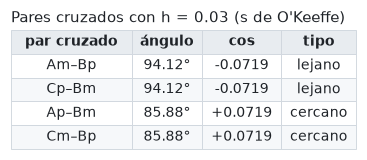

In [79]:
w_okeeffe = float(w_estrella)
phi_okeeffe = fases_s7(H, s_simetrico([-1.0, 1.0, -w_okeeffe]))
print("el estado de O'Keeffe es simétrico:", si_no(np.allclose(np.cos(phi_okeeffe[REFLEJO]), np.cos(np.pi - phi_okeeffe))))
filas = []
for a, b, tipo in [(0, 3, "lejano"), (5, 2, "lejano"), (1, 2, "cercano"), (4, 3, "cercano")]:
    angulo = abs(phi_okeeffe[a] - phi_okeeffe[b])
    filas.append([f"{NOMBRES[a]}–{NOMBRES[b]}", f"{np.degrees(angulo):.2f}°", f"{np.cos(angulo):+.4f}", tipo])
mostrar_tabla(["par cruzado", "ángulo", "cos", "tipo"], filas, titulo=f"Pares cruzados con h = {H} (s de O'Keeffe)")

Los pares de cada tipo están a exactamente el mismo ángulo: el reflejo los intercambia. Entre tipos, el
signo del coseno es opuesto.

### 12.3 La Fase 0 con restricciones

Al SDP se le pueden agregar restricciones **lineales** en $P$ sin que deje de ser un SDP:
- `"reflejo"`: $P = RPR^\top$, con los desplazamientos simétricos (Nelder–Mead en 3 parámetros);
- `"q_unico"`: los cuatro pares cruzados con la misma densidad (la Tabla II con un solo $q$);
- `"vecinos_en_1"`: los pares vecinos que valen 1 en el patrón límite quedan en 1 (solo se mueven los
  cuatro cruzados).

**Por qué el reflejo no cuesta $\mu$.** Si $\varphi$ es simétrico, el problema es invariante por el
reflejo: si $P$ es factible, $RPR^\top$ también, con el mismo $\mu$. Como el problema es convexo, el
promedio $\tfrac12(P + RPR^\top)$ también es factible, con al menos el mismo $\mu$. Siempre hay un óptimo
simétrico, y pedir simetría no pierde nada. En cambio, Nelder–Mead busca en 3 parámetros en lugar de 6,
que es más fácil.

**El código.** `sdp_s7` es `sdp_interno` (sección 4.1) escrito para S7, con las restricciones opcionales.
`optimizar_s7_restringido` hace Nelder–Mead en los desplazamientos (6, o 3 con reflejo) desde el ansatz
de O'Keeffe. Es la variante de `optimizar_s7` de la sección 6 con restricciones, con dos diferencias:
usa Nelder–Mead sin la opción adaptativa (por eso la variante "sin restricciones" no da exactamente la
plantilla de la sección 6), y **reinicia** Nelder–Mead una vez desde su resultado, con un símplex
nuevo. El reinicio importa: el SDP tiene un ruido del orden de la tolerancia del solver, y con algunas
versiones de las librerías el primer Nelder–Mead se detiene antes en un punto apenas peor
($\mu = 0.688562$). El reinicio llega al óptimo ($\mu \approx 0.68858$).

In [80]:
# biblioteca
CRUZADOS = [(0, 3), (1, 2), (2, 5), (3, 4)]                                 # Am–Bp, Ap–Bm, Bm–Cp, Bp–Cm
VECINOS_EN_1 = [(0, 2), (1, 3), (2, 4), (3, 5), (0, 6), (1, 6), (4, 6), (5, 6)]


def sdp_s7(x, phi, h, margen, restricciones=()):
    """Mayor μ sobre las densidades P con x y φ fijos. Devuelve (μ, P) o (None, None) si es infactible."""
    m = len(x)
    diferencias = phi[:, None] - phi[None, :]
    senos = np.sin(diferencias)
    cosenos = np.cos(diferencias)
    pesos_L = np.outer(x, x) * cosenos
    np.fill_diagonal(pesos_L, 0)

    P = cp.Variable((m, m), symmetric=True)
    t = cp.Variable()
    K = cp.multiply(P, pesos_L)
    L = cp.diag(cp.sum(K, axis=1)) - K
    Q = base_perpendicular(m)
    lista = [
        P >= 0,
        P <= 1,
        cp.diag(P) == 1,
        P @ x >= t,
        cp.multiply(P, senos) @ x == 0,
        cp.multiply(P, cosenos) @ x >= 1e-3,
        (Q.T @ L @ Q) / h**2 >> margen * np.eye(m - 1),
        cp.multiply(P, prohibidos_s7().astype(float)) == 0,
    ]
    if "reflejo" in restricciones:
        R = np.eye(m)[REFLEJO]
        lista.append(P == R @ P @ R.T)
    if "q_unico" in restricciones:
        a0, b0 = CRUZADOS[0]
        for a, b in CRUZADOS[1:]:
            lista.append(P[a, b] == P[a0, b0])
    if "vecinos_en_1" in restricciones:
        for a, b in VECINOS_EN_1:
            lista.append(P[a, b] == 1)
    problema = cp.Problem(cp.Maximize(t), lista)
    try:
        problema.solve(solver="CLARABEL")
    except cp.error.SolverError:
        return None, None
    if problema.status not in ("optimal", "optimal_inaccurate"):
        return None, None
    return float(t.value), np.array(P.value)


def optimizar_s7_restringido(x, h, margen, restricciones=(), reinicios=1):
    """Nelder–Mead en los desplazamientos (3 con reflejo, 6 sin), reiniciado desde su resultado. Devuelve (μ, s, P)."""
    _, w, _ = esquina(30)
    w = float(w)
    simetrico = "reflejo" in restricciones
    p0 = np.array([-1.0, 1.0, -w]) if simetrico else np.array([-1.0, 1.0, -w, w, -1.0, 1.0])

    def desplazamientos(p):
        return s_simetrico(p) if simetrico else p

    def objetivo(p):
        mu, _ = sdp_s7(x, fases_s7(h, desplazamientos(p)), h, margen, restricciones)
        return 1.0 if mu is None else -mu

    opciones = {"maxiter": 600, "xatol": 1e-5, "fatol": 1e-9}
    resultado = minimize(objetivo, p0, method="Nelder-Mead", options=opciones)
    for _ in range(reinicios):
        resultado = minimize(objetivo, resultado.x, method="Nelder-Mead", options=opciones)
    s = desplazamientos(resultado.x)
    mu, P = sdp_s7(x, fases_s7(h, s), h, margen, restricciones)
    return mu, s, P

Corremos las cuatro variantes con $h = 0.03$, $\varepsilon = 10^{-3}$ y tamaños $(3, 5)$, la misma
plantilla de la sección 6. Tarda alrededor de un minuto y medio.

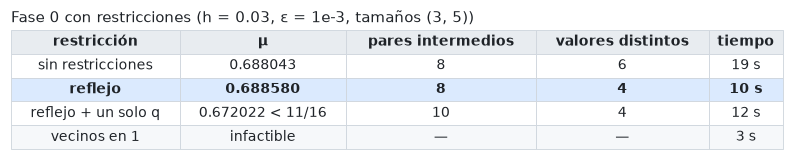

μ plantilla simétrica: 0.68858   (referencia: 0.688579, coincide)


In [81]:
inicio_variantes = time.time()
variantes = {}
filas = []
for nombre, restricciones in [("sin restricciones", ()), ("reflejo", ("reflejo",)),
                              ("reflejo + un solo q", ("reflejo", "q_unico")),
                              ("vecinos en 1", ("vecinos_en_1",))]:
    inicio = time.time()
    mu, s, P = optimizar_s7_restringido(x_plantilla, H, MARGEN, restricciones)
    variantes[nombre] = (mu, s, P)
    if mu is None:
        filas.append([nombre, "infactible", "—", "—", f"{time.time() - inicio:.0f} s"])
        continue
    intermedios = []
    for a in range(7):
        for b in range(a + 1, 7):
            if 1e-4 < P[a, b] < 1 - 1e-4:
                intermedios.append(round(P[a, b], 4))
    filas.append([nombre, f"{mu:.6f}" + (" < 11/16" if mu < 11 / 16 else ""), len(intermedios), len(set(intermedios)),
                  f"{time.time() - inicio:.0f} s"])
TIEMPOS["Fase 0 con restricciones"] = time.time() - inicio_variantes
mostrar_tabla(["restricción", "μ", "pares intermedios", "valores distintos", "tiempo"], filas,
              titulo="Fase 0 con restricciones (h = 0.03, ε = 1e-3, tamaños (3, 5))", resaltar=[1])
comparar("μ plantilla simétrica", round(variantes["reflejo"][0], 6), tolerancia=5e-6)

**Lectura.**
- **Reflejo:** da el $\mu$ más alto. No pierde nada, como predice el argumento de convexidad, y además
  puede ganar un poco, porque Nelder–Mead encuentra mejor el óptimo en 3 parámetros que en 6. Los pares
  intermedios son 8, con **4 valores distintos**.
- **Un solo $q$:** queda por debajo de $11/16$. Forzar lejano = cercano cuesta del orden de $h$ en $\mu$, y
  esa es justo la ventaja de S7 sobre $11/16$.
- **Vecinos en 1:** es infactible. Con $h > 0$ algunos pares que en el patrón límite valen 1 tienen que
  bajar, como en O'Keeffe.

**La plantilla simétrica.** La matriz $P$ completa; las densidades intermedias están pintadas, con un
color por pareja espejo.

In [82]:
# biblioteca
def mostrar_matriz(P, colores_celda, titulo):
    """Matriz de densidades 7 × 7 con nombres de clusters; las celdas con color son las intermedias."""
    textos = []
    for fila in P:
        textos.append(["1" if v > 1 - 1e-4 else "0" if v < 1e-4 else f"{v:.4f}" for v in fila])
    fig, eje = plt.subplots(figsize=(1, 0.22 * (len(P) + 1)))
    eje.axis("off")
    tabla = eje.table(cellText=textos, rowLabels=NOMBRES, colLabels=NOMBRES, loc="center", cellLoc="center")
    tabla.auto_set_font_size(False)
    tabla.set_fontsize(9)
    tabla.auto_set_column_width(list(range(-1, len(P))))
    tabla.scale(1, 1.3)
    for (i, j), celda in tabla.get_celld().items():
        celda.set_edgecolor(BORDE)
        celda.set_linewidth(0.6)
        celda.PAD = 0.15
        celda.get_text().set_color(TINTA)
        if i == 0 or j == -1:
            celda.set_facecolor(FONDO_ENCABEZADO)
            celda.get_text().set_fontweight("bold")
        elif colores_celda[i - 1][j] is not None:
            celda.set_facecolor(colores_celda[i - 1][j])
            celda.get_text().set_fontweight("bold")
    fig.canvas.draw()
    caja = tabla.get_window_extent(fig.canvas.get_renderer())
    x0, y1 = eje.transAxes.inverted().transform((caja.x0, caja.y1))
    eje.annotate(titulo, xy=(x0, y1), xycoords="axes fraction", xytext=(0, 5), textcoords="offset points",
                 fontsize=10, color=TINTA)
    plt.show()

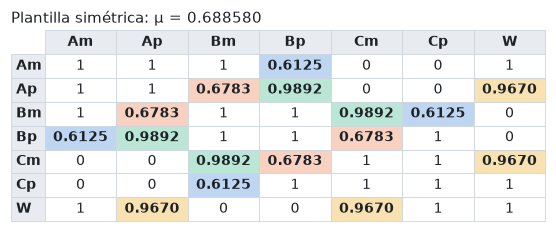

desplazamientos s: [-0.9365  0.8964 -1.2779  1.2779 -0.8964  0.9365]
Am–Bp y Bm–Cp: 0.6125
Ap–Bm y Bp–Cm: 0.6783
Ap–Bp y Bm–Cm: 0.9892
Ap–W y Cm–W: 0.9670


In [83]:
mu_simetrica, s_simetrica, P_sdp = variantes["reflejo"]
colores_celda = [[None] * 7 for _ in range(7)]
leyenda = []
for a in range(7):
    for b in range(a + 1, 7):
        if 1e-4 < P_sdp[a, b] < 1 - 1e-4 and colores_celda[a][b] is None:
            ra, rb = REFLEJO[a], REFLEJO[b]
            color = matplotlib.colors.to_rgba(COLORES[len(leyenda)], 0.3)
            for i, j in [(a, b), (b, a), (ra, rb), (rb, ra)]:
                colores_celda[i][j] = color
            leyenda.append(f"{NOMBRES[a]}–{NOMBRES[b]} y {NOMBRES[min(ra, rb)]}–{NOMBRES[max(ra, rb)]}: {P_sdp[a, b]:.4f}")
mostrar_matriz(P_sdp, colores_celda, f"Plantilla simétrica: μ = {mu_simetrica:.6f}")
print("desplazamientos s:", np.round(s_simetrica, 4))
for linea in leyenda:
    print(linea)

Son **cuatro valores**, cada uno en un par y su espejo; todas las demás densidades son 0 o 1, y la
matriz respeta el espejo (la fila de Am leída al revés es la de Cp, etc.).
- **Azul y naranja:** los pares cruzados, el lejano más fino (Am–Bp, Bm–Cp) y el cercano más grueso
  (Ap–Bm, Bp–Cm).
- **Verde y amarillo:** pares que en el patrón límite valen 1 y bajan un poco: los de Ap con Bp y con W,
  y sus espejos, Cm con Bm y con W. Son las mitades que miran hacia B, y los pares que O'Keeffe adelgaza
  más.

## 13. El grafo simétrico

### 13.1 Por qué la simetría ayuda al redondeo

El problema del redondeo (sección 7.3) es el pliegue: en cada dirección blanda $k$ del Jacobiano, el
error $\rho_k$ que mete el redondeo tiene que ser menor que $\sigma_k^2/(2|c_k|)$. Sin simetría hay 3
direcciones blandas.

**Simetría de las direcciones.** Un movimiento de las fases $\delta\varphi$ se refleja como
$\delta\varphi_{R(a)} \mapsto -\delta\varphi_a$ (el espejo invierte el sentido de giro). Cuando la
plantilla es simétrica, $J$ conmuta con el reflejo, así que cada vector singular de $J$ es **simétrico**
(no cambia al reflejarlo) o **antisimétrico** (cambia de signo).

**Si los datos enteros también son simétricos,** el error de redondeo es simétrico y no puede empujar
en una dirección antisimétrica: las ecuaciones antisimétricas se cumplen **solas**, y el equilibrio se
busca entre los estados simétricos. En esas direcciones ya no hay pliegue; alcanza con que el cambio de
las densidades ($\sim1/n$) sea menor que el margen de estabilidad (los autovalores de $L$, de orden
$5\cdot10^{-6}$). Es una condición lineal en $1/n$, no cuadrática como la del pliegue.

**El código.** Jacobiano completo de $F$ respecto de las 7 fases, su SVD y la paridad de cada vector
singular $v$, medida como $v^\top Rv$ ($+1$ simétrico, $-1$ antisimétrico).

In [84]:
# biblioteca
def jacobiano_completo(x, phi, P):
    """∂F_a/∂φ_b para las 7 fases (incluye la rotación global, que tiene valor singular 0)."""
    J = np.zeros((7, 7))
    for a in range(7):
        for b in range(7):
            if a != b:
                J[a, b] = -P[a, b] * x[b] * np.cos(phi[a] - phi[b])
        J[a, a] = -J[a].sum()
    return J


def matriz_reflejo():
    """δφ ↦ R δφ con (R δφ)_{R(a)} = −δφ_a."""
    R = np.zeros((7, 7))
    for a in range(7):
        R[REFLEJO[a], a] = -1
    return R

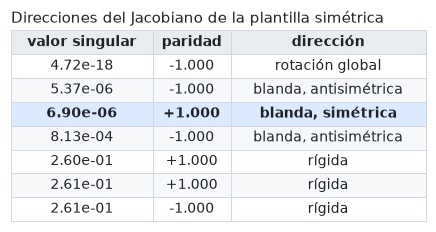

In [85]:
phi_simetrica = fases_s7(H, s_simetrica)
_, singulares, Vt = np.linalg.svd(jacobiano_completo(x_plantilla, phi_simetrica, P_sdp))
R_fases = matriz_reflejo()
filas = []
for i in np.argsort(singulares):
    paridad = Vt[i] @ R_fases @ Vt[i]
    if singulares[i] < 1e-12:
        tipo = "rotación global"
    elif singulares[i] < 1e-2:
        tipo = "blanda, " + ("simétrica" if paridad > 0 else "antisimétrica")
    else:
        tipo = "rígida"
    filas.append([f"{singulares[i]:.2e}", f"{paridad:+.3f}", tipo])
mostrar_tabla(["valor singular", "paridad", "dirección"], filas, titulo="Direcciones del Jacobiano de la plantilla simétrica",
              resaltar=[i for i, f in enumerate(filas) if f[2] == "blanda, simétrica"])

De las tres direcciones blandas, **dos son antisimétricas** y **una es simétrica** (resaltada). Con datos
enteros simétricos, solo esa hay que cuidar.

### 13.2 El sistema reducido

Un estado simétrico queda determinado por $\psi = (\varphi_{Am}, \varphi_{Ap}, \varphi_{Bm})$: las demás
fases son $\pi$ menos la de su espejo, y W queda en $3\pi/2$. Las ecuaciones también se reducen: en un
estado simétrico $F_{R(a)} = -F_a$ y $F_W = 0$. Quedan **3 ecuaciones ($F_{Am}, F_{Ap}, F_{Bm}$) con 3
incógnitas**, y su Jacobiano tiene 2 valores singulares grandes y 1 chico. (Ya no hay rotación global:
rotar un estado simétrico lo deja de hacer simétrico.)

**Datos enteros simétricos.** Los pares en 0 o 1 quedan fijos. Los 8 pares intermedios forman 4
parejas espejo, y en cada pareja se usa **el mismo grado**: son **4 enteros** $j_1, \dots, j_4$, con
$d_{ab} = j_c\cdot\text{paso}$.

**Pulido simétrico.** Primero se promedia $P$ con su reflejo, y las densidades que el SDP dejó a menos de
$10^{-4}$ de 0 o de 1 (ruido del solver) se llevan a 0 o 1 exactos. Después, como en la sección 7.2, se
corrige $P$ con el cambio de menor norma que hace $F = 0$ exacto, pero con una variable por pareja
espejo, para que la plantilla pulida siga siendo simétrica: 3 ecuaciones, 4 incógnitas.

In [86]:
# biblioteca
def simetrizar(P, tolerancia=1e-4):
    """Promedio exacto con el reflejo, y los extremos que el SDP dejó a menos de tolerancia, a 0 o 1."""
    R = np.eye(7)[REFLEJO]
    P = (P + R @ P @ R.T) / 2
    P = (P + P.T) / 2
    P[P < tolerancia] = 0
    P[P > 1 - tolerancia] = 1
    return P


def parejas_libres(P):
    """Pares intermedios agrupados por el reflejo: [[par, espejo], ...], con a < b en cada par."""
    parejas = []
    vistos = set()
    for a in range(7):
        for b in range(a + 1, 7):
            if 0 < P[a][b] < 1 and (a, b) not in vistos:
                espejo = tuple(sorted((REFLEJO[a], REFLEJO[b])))
                parejas.append([(a, b), espejo])
                vistos |= {(a, b), espejo}
    return parejas


def fases_reducidas(psi):
    """Estado simétrico a partir de ψ = (φ_Am, φ_Ap, φ_Bm): φ_R(a) = π − φ_a y W en 3π/2."""
    return [psi[0], psi[1], psi[2], mp.pi - psi[2], mp.pi - psi[1], mp.pi - psi[0], 3 * mp.pi / 2]


def ecuaciones_reducidas(x, psi, P):
    """(F_Am, F_Ap, F_Bm): en un estado simétrico las demás son sus opuestas y F_W = 0."""
    F = fuerzas(x, fases_reducidas(psi), P, mp)
    return mp.matrix([F[0], F[1], F[2]])


def jacobiano_reducido(x, psi, P):
    """∂(F_Am, F_Ap, F_Bm)/∂ψ por la regla de la cadena: dφ/dψ vale +1 en Am, Ap, Bm y −1 en sus espejos."""
    phi = fases_reducidas(psi)
    dphi = [[1, 0, 0], [0, 1, 0], [0, 0, 1], [0, 0, -1], [0, -1, 0], [-1, 0, 0], [0, 0, 0]]
    J = mp.matrix(3, 3)
    for i, a in enumerate([0, 1, 2]):
        fila = [mp.mpf(0)] * 7                       # ∂F_a/∂φ_b
        for b in range(7):
            if b != a:
                termino = P[a][b] * x[b] * mp.cos(phi[a] - phi[b])
                fila[a] += termino
                fila[b] -= termino
        for j in range(3):
            J[i, j] = sum(fila[b] * dphi[b][j] for b in range(7))
    return J


def pulir_simetrico(x, psi, P, parejas):
    """Cambio de mínima norma en P, una variable por pareja espejo, con F(φ(ψ)) = 0 exacto."""
    P = [[mp.mpf(float(v)) for v in fila] for fila in P]
    F = ecuaciones_reducidas(x, psi, P)
    phi = fases_reducidas(psi)
    A = mp.matrix(3, len(parejas))
    for c, pareja in enumerate(parejas):
        E = [[mp.mpf(0)] * 7 for _ in range(7)]       # F es lineal en P: la columna c es F(E_c)
        for a, b in pareja:
            E[a][b] = E[b][a] = mp.mpf(1)
        columna = fuerzas(x, phi, E, mp)
        for i in range(3):
            A[i, c] = columna[i]
    delta = A.T * mp.lu_solve(A * A.T, -F)
    for c, pareja in enumerate(parejas):
        for a, b in pareja:
            P[a][b] += delta[c]
            P[b][a] = P[a][b]
    return P

In [87]:
mp.mp.dps = 50                     # el certificado de la sección 9 dejó la precisión global en 100 dígitos
P_simetrica = simetrizar(P_sdp)
parejas = parejas_libres(P_simetrica)
x_exacto_simetrico = [mp.mpf(v.numerator) / v.denominator for v in tamanos_exactos(K_S7)]
psi_plantilla = [mp.mpf(H) * mp.mpf(float(s_simetrica[0])), mp.mpf(H) * mp.mpf(float(s_simetrica[1])),
                 mp.pi / 2 + mp.mpf(H) * mp.mpf(float(s_simetrica[2]))]
P_pulida_simetrica = pulir_simetrico(x_exacto_simetrico, psi_plantilla, P_simetrica, parejas)
F_pulida = fuerzas(x_exacto_simetrico, fases_reducidas(psi_plantilla), P_pulida_simetrica, mp)
cambio = 0.0
for a in range(7):
    for b in range(7):
        cambio = max(cambio, abs(float(P_pulida_simetrica[a][b]) - P_sdp[a, b]))
for c, pareja in enumerate(parejas):
    print(f"pareja {c + 1}:", " y ".join(NOMBRES[a] + "–" + NOMBRES[b] for a, b in pareja))
assert len(parejas) == 4, "se esperaban 4 parejas libres: la búsqueda exhaustiva crece como 41^parejas"
print("max |F| después de pulir:", mp.nstr(max(abs(v) for v in F_pulida), 3))
print("cambio máximo en P:", f"{cambio:.1e}")

pareja 1: Am–Bp y Bm–Cp
pareja 2: Ap–Bm y Bp–Cm
pareja 3: Ap–Bp y Bm–Cm
pareja 4: Ap–W y Cm–W
max |F| después de pulir: 6.68e-52
cambio máximo en P: 2.3e-06


### 13.3 El residuo blando y el umbral del pliegue

Es la misma reducción de Lyapunov–Schmidt de la sección 7.4, en el sistema reducido:
1. SVD del Jacobiano reducido $J = USV^\top$ en la plantilla: 2 direcciones rígidas y 1 blanda;
2. para unos grados dados, Newton mueve $\psi$ solo en las 2 direcciones rígidas hasta que las 2
   ecuaciones rígidas dan 0;
3. lo que queda en la dirección blanda es el residuo $g$: **un solo número**. El objetivo es elegir
   $j_1, \dots, j_4$ para que $|g|$ quede por debajo del umbral del pliegue, $\sigma^2/(2|c|)$.

El coeficiente $c$ de la forma normal $\sigma y + \tfrac c2y^2$ se mide por diferencias finitas: es la
derivada segunda de la ecuación blanda a lo largo de la dirección blanda. (Las direcciones rígidas no lo
modifican a segundo orden, porque la ecuación blanda no ve los movimientos rígidos: $u_b^\top JV_r = 0$.)

Estas funciones son las versiones reducidas de `base_blanda` y `residuo_blando` de la sección 7.5 (de ahí
el sufijo).

In [88]:
# biblioteca
def grados_simetricos(P, parejas, j, g):
    """d a partir de un entero por pareja (d_ab = j_c · paso, igual en el par y en su espejo)."""
    n_a = tamanos_enteros(K_S7, g)
    d = [[0] * 7 for _ in range(7)]
    for a in range(7):
        d[a][a] = n_a[a] - 1
        for b in range(7):
            if b != a and P[a][b] == 1:
                d[a][b] = n_a[b]
    for c, pareja in enumerate(parejas):
        for a, b in pareja:
            d[a][b] = j[c] * paso_grado(K_S7, a, b)
            d[b][a] = d[a][b] * n_a[a] // n_a[b]
    return d


def enteros_ingenuos(P, parejas, g):
    """El múltiplo permitido más cercano a P_ab·n_b, para el primer par de cada pareja."""
    n_a = tamanos_enteros(K_S7, g)
    j = []
    for pareja in parejas:
        a, b = pareja[0]
        j.append(int(mp.nint(P[a][b] * n_a[b] / paso_grado(K_S7, a, b))))
    return j


def densidades(d, g):
    """P_ab = d_ab/n_b en mpmath."""
    n_a = tamanos_enteros(K_S7, g)
    return [[mp.mpf(d[a][b]) / n_a[b] for b in range(7)] for a in range(7)]


def base_blanda_reducida(x, psi, P):
    """SVD del Jacobiano reducido: (U_rígido, U_blando, V_rígido) y los valores singulares."""
    J = np.array(jacobiano_reducido(x, psi, P).tolist(), dtype=float)
    U, singulares, Vt = np.linalg.svd(J)
    return (mp.matrix(U[:, :2].tolist()), mp.matrix(U[:, 2:].tolist()), mp.matrix(Vt[:2].T.tolist())), singulares


def residuo_blando_reducido(x, P, psi_referencia, base, iteraciones=30):
    """Newton en las 2 direcciones rígidas; devuelve el residuo de la blanda (un número) y ψ."""
    U_r, U_b, V_r = base
    z = mp.matrix(2, 1)
    for _ in range(iteraciones):
        psi = [psi_referencia[i] + V_r[i, 0] * z[0] + V_r[i, 1] * z[1] for i in range(3)]
        rigidas = U_r.T * ecuaciones_reducidas(x, psi, P)
        if mp.norm(rigidas) < mp.mpf(10) ** (-mp.mp.dps + 10):
            break
        z = z - mp.lu_solve(U_r.T * jacobiano_reducido(x, psi, P) * V_r, rigidas)
    psi = [psi_referencia[i] + V_r[i, 0] * z[0] + V_r[i, 1] * z[1] for i in range(3)]
    return (U_b.T * ecuaciones_reducidas(x, psi, P))[0], psi


def forma_normal(x, psi, P):
    """(σ, c) de la ecuación blanda σ y + (c/2) y² a lo largo de la dirección blanda (diferencias finitas)."""
    U, _, Vt = np.linalg.svd(np.array(jacobiano_reducido(x, psi, P).tolist(), dtype=float))
    u_b = mp.matrix(U[:, 2].tolist())
    v_b = Vt[2]

    def blanda(y):
        return (u_b.T * ecuaciones_reducidas(x, [psi[i] + y * v_b[i] for i in range(3)], P))[0]

    e = mp.mpf("1e-8")
    sigma = (blanda(e) - blanda(-e)) / (2 * e)
    c = (blanda(e) - 2 * blanda(0) + blanda(-e)) / e**2
    return abs(float(sigma)), float(c)

In [89]:
base_simetrica, singulares_reducidos = base_blanda_reducida(x_exacto_simetrico, psi_plantilla, P_pulida_simetrica)
sigma_blanda, c_blanda = forma_normal(x_exacto_simetrico, psi_plantilla, P_pulida_simetrica)
umbral = sigma_blanda**2 / (2 * abs(c_blanda))
print("valores singulares del Jacobiano reducido:", "  ".join(f"{v:.3e}" for v in singulares_reducidos))
print("σ de la forma normal:", f"{sigma_blanda:.3e}")
print("c de la forma normal:", f"{c_blanda:.2e}")
print("σ²:", f"{sigma_blanda**2:.1e}")
print("umbral del pliegue σ²/(2|c|):", f"{umbral:.1e}")

valores singulares del Jacobiano reducido: 2.612e-01  2.605e-01  6.895e-06
σ de la forma normal: 6.895e-06
c de la forma normal: 8.97e-04
σ²: 4.8e-11
umbral del pliegue σ²/(2|c|): 2.7e-08


El umbral es unas 500 veces más grande que $\sigma^2$, porque $c$ también es chico (del orden de $h^2$).

### 13.4 Newton entero por búsqueda exhaustiva

Cerca de los grados ingenuos, $g$ es casi lineal en los enteros:
$$g(j + u) \approx g(j) + G\cdot u, \qquad G_c = g(j + e_c) - g(j)$$
($G_c$ es cuánto cambia $g$ al sumarle 1 al entero $c$). Con 4 enteros y radio 20 hay
$41^4 \approx 2.8\cdot10^6$ vectores $u$ posibles, y evaluar $g + G\cdot u$ en todos es una sola
multiplicación de matrices. Se elige el $u$ con menor $|g + G\cdot u|$; como el modelo lineal no es
exacto, se repite una vez con radio 3 desde el nuevo punto. **No hace falta el reticulado:** con 1
ecuación y 4 incógnitas, buscar entre todos es instantáneo y da el óptimo exacto del modelo lineal.

In [90]:
# biblioteca
def newton_entero(x, P, parejas, psi_referencia, base, g, radios=(20, 3)):
    """Newton entero exhaustivo desde el redondeo ingenuo: en cada paso, el u con |u_c| ≤ radio que minimiza |g + G·u|.

    Devuelve los enteros, los grados, ψ y |g| en cada paso.
    """
    j = enteros_ingenuos(P, parejas, g)
    historia = []
    for radio in radios:
        g_actual, _ = residuo_blando_reducido(x, densidades(grados_simetricos(P, parejas, j, g), g), psi_referencia, base)
        G = []
        for c in range(len(parejas)):
            j_mas = list(j)
            j_mas[c] += 1
            g_mas, _ = residuo_blando_reducido(x, densidades(grados_simetricos(P, parejas, j_mas, g), g),
                                               psi_referencia, base)
            G.append(float(g_mas - g_actual))
        historia.append(abs(float(g_actual)))
        candidatos = np.array(list(itertools.product(range(-radio, radio + 1), repeat=len(parejas))))
        u = candidatos[np.argmin(np.abs(float(g_actual) + candidatos @ np.array(G)))]
        j = [int(jc + uc) for jc, uc in zip(j, u)]
    d = grados_simetricos(P, parejas, j, g)
    g_final, psi = residuo_blando_reducido(x, densidades(d, g), psi_referencia, base)
    historia.append(abs(float(g_final)))
    return j, d, psi, historia


def barrido_simetrico(x, P_sdp, s, h, ns):
    """Fase 1 simétrica completa para la plantilla (x, s, P_sdp): pulido, base blanda y, para cada n, ingenuo y Newton."""
    parejas = parejas_libres(simetrizar(P_sdp))
    x_exacto = [mp.mpf(v.numerator) / v.denominator for v in tamanos_exactos(K_S7)]
    psi_plantilla = [mp.mpf(h) * mp.mpf(float(s[0])), mp.mpf(h) * mp.mpf(float(s[1])),
                     mp.pi / 2 + mp.mpf(h) * mp.mpf(float(s[2]))]
    P_pulida = pulir_simetrico(x_exacto, psi_plantilla, simetrizar(P_sdp), parejas)
    base, _ = base_blanda_reducida(x_exacto, psi_plantilla, P_pulida)
    phi_referencia = [float(v) for v in fases_reducidas(psi_plantilla)]
    barrido = []
    for n_objetivo in ns:
        g = int(round(n_objetivo / sum(K_S7)))
        j_ingenuo = enteros_ingenuos(P_pulida, parejas, g)
        d_ingenuo = grados_simetricos(P_pulida, parejas, j_ingenuo, g)
        ingenuo = evaluar_enteros(K_S7, g, d_ingenuo, phi_referencia, h)
        j, d, psi, historia = newton_entero(x_exacto, P_pulida, parejas, psi_plantilla, base, g)
        phi = [float(v) for v in fases_reducidas(psi)]
        newton = evaluar_enteros(K_S7, g, d, phi, h, phi_referencia=phi_referencia)
        barrido.append({"g": g, "n": sum(K_S7) * g, "j": j, "j_ingenuo": j_ingenuo, "d": d, "historia": historia,
                        "ingenuo": ingenuo, "newton": newton})
    return barrido, parejas

### 13.5 El barrido en $n$

`barrido_simetrico` junta los pasos de 13.2–13.4 para una plantilla: pule, arma la base blanda y, para
cada $n$ de la grilla, prueba el redondeo ingenuo (simétrico) y el Newton entero, y evalúa cada uno en
exacto con `evaluar_enteros` (el mismo criterio de la sección 7.2). Tarda uno o dos minutos.

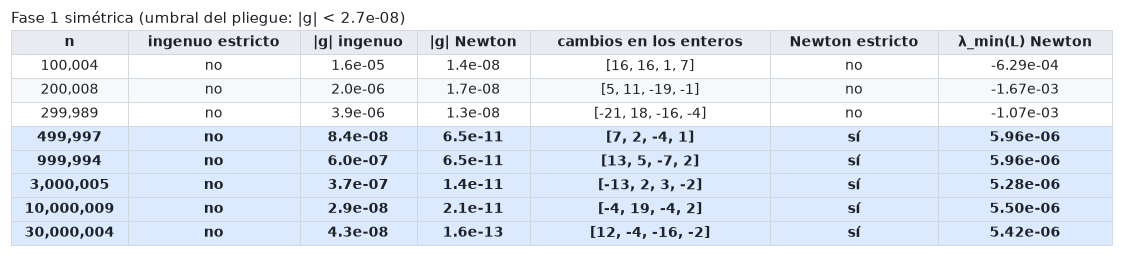

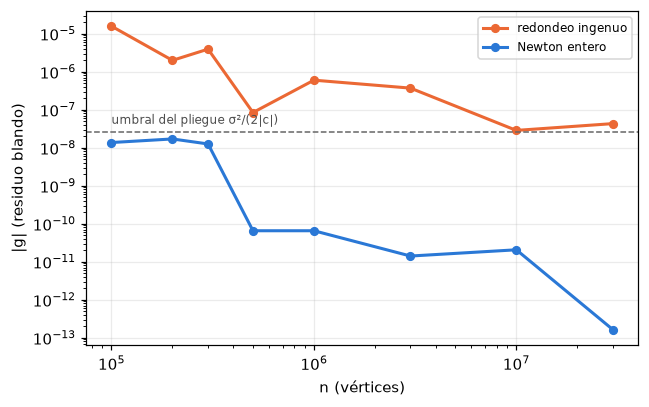

In [91]:
inicio = time.time()
barrido, parejas = barrido_simetrico(x_plantilla, P_sdp, s_simetrica, H, [1e5, 2e5, 3e5, 5e5, 1e6, 3e6, 1e7, 3e7])
TIEMPOS["Fase 1 simétrica"] = time.time() - inicio

filas = []
for r in barrido:
    cambios = [a - b for a, b in zip(r["j"], r["j_ingenuo"])]
    filas.append([f"{r['n']:,}", si_no(r["ingenuo"]["ok"]), f"{r['historia'][0]:.1e}", f"{r['historia'][-1]:.1e}",
                  str(cambios), si_no(r["newton"]["ok"]), f"{r['newton']['menor autovalor']:.2e}"])
mostrar_tabla(["n", "ingenuo estricto", "|g| ingenuo", "|g| Newton", "cambios en los enteros", "Newton estricto",
               "λ_min(L) Newton"], filas, titulo=f"Fase 1 simétrica (umbral del pliegue: |g| < {umbral:.1e})",
              resaltar=[i for i, r in enumerate(barrido) if r["newton"]["ok"]])

fig, eje = plt.subplots(figsize=(6, 3.8))
ns = [r["n"] for r in barrido]
eje.plot(ns, [r["historia"][0] for r in barrido], "o-", color=COLORES[1], lw=2, ms=5, label="redondeo ingenuo")
eje.plot(ns, [r["historia"][-1] for r in barrido], "o-", color=COLORES[0], lw=2, ms=5, label="Newton entero")
eje.axhline(umbral, color="0.4", lw=1, ls="--")
eje.text(ns[0], umbral * 1.6, "umbral del pliegue σ²/(2|c|)", color="0.3", fontsize=8)
eje.set(xscale="log", yscale="log", xlabel="n (vértices)", ylabel="|g| (residuo blando)")
eje.grid(alpha=0.25)
eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura.**
- **El redondeo ingenuo** deja $|g|$ por encima del umbral en toda la grilla: nunca da un equilibrio
  estricto. $|g|$ baja como $1/n$ pero con saltos, porque depende de cuánto le toca redondear a cada
  entero.
- **El Newton entero** baja $|g|$ entre 3 y 5 órdenes de magnitud, cambiando cada entero en a lo sumo 20
  unidades (sobre grados de decenas de miles).
- **El $n$ mínimo baja a unos $3\cdot10^5$–$10^6$.** Con $n = 10^5$ el residuo ya está debajo del
  umbral, pero $\lambda_{\min}(L)$ sale negativo: falla la otra condición. El redondeo cambia las
  densidades en $\sim1/n = 10^{-5}$, más que el margen de estabilidad ($\sim5\cdot10^{-6}$). **El límite
  ya no es el pliegue, sino el margen.** La construcción general necesitaba $n = 3\cdot10^7$.
- **En este régimen el resultado es sensible a la plantilla.** Como $1/n$ y el margen son del mismo
  orden, que un $n$ dado funcione depende de dónde caen los redondeos, y eso depende de los
  desplazamientos $s$ en el quinto o sexto decimal. En la corrida de referencia del repositorio,
  Nelder–Mead terminó en $s = (-0.93669, 0.89667, -1.27825)$ y el menor grafo certificado fue
  $n = 299\,989$; con otras versiones de las librerías Nelder–Mead termina en un punto apenas distinto
  (incluso con un $\mu$ de la plantilla un poco mayor) y el menor $n$ puede ser otro. La celda de abajo
  rehace la Fase 1 con esos tres números y certifica el grafo de referencia.

**El grafo de referencia, desde sus tres desplazamientos.**

In [92]:
S_REFERENCIA = s_simetrico([-0.93669195, 0.89667232, -1.27825000])   # corrida de referencia del repositorio
mu_referencia, P_referencia = sdp_s7(x_plantilla, fases_s7(H, S_REFERENCIA), H, MARGEN, ("reflejo",))
barrido_referencia, _ = barrido_simetrico(x_plantilla, P_referencia, S_REFERENCIA, H, [3e5])
r = barrido_referencia[0]
certificado_referencia = certificar_blowup(K_S7, r["g"], r["d"], r["newton"]["phi"], dps=100)
mp.mp.dps = 50
print("μ de la plantilla de referencia:", f"{mu_referencia:.6f}")
print("n:", f"{r['n']:,}")
print("enteros j:", r["j"])
print("Newton estricto:", si_no(r["newton"]["ok"]))
print("certificado:", si_no(certificado_referencia["ok"]))
print("μ exacto:", certificado_referencia["mu_exacto"])

μ de la plantilla de referencia: 0.688579
n: 299,989
enteros j: [23984, 26540, 38697, 12614]
Newton estricto: sí
certificado: sí
μ exacto: 206565/299989


### 13.6 Certificado y descripción del grafo

El certificado es el mismo de la sección 9 (`certificar_blowup`), sin ningún cambio: no usa la simetría.

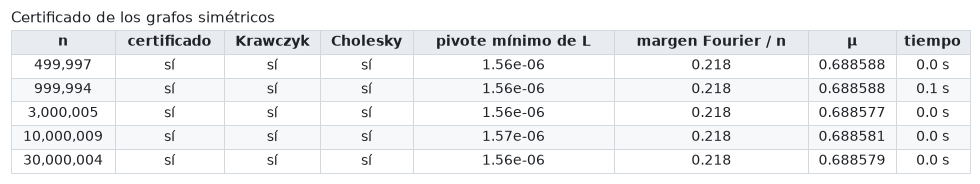

In [93]:
filas = []
for r in barrido:
    if not r["newton"]["ok"]:
        continue
    inicio = time.time()
    r["certificado"] = certificar_blowup(K_S7, r["g"], r["d"], r["newton"]["phi"], dps=100)
    c = r["certificado"]
    filas.append([f"{r['n']:,}", si_no(c["ok"]), si_no(c["krawczyk"]), si_no(c["cholesky"]),
                  f"{c['min pivote L (cota inf)']:.2e}", f"{c['margen fourier / n (cota inf)']:.3f}",
                  f"{c['mu']:.6f}", f"{time.time() - inicio:.1f} s"])
mostrar_tabla(["n", "certificado", "Krawczyk", "Cholesky", "pivote mínimo de L", "margen Fourier / n", "μ", "tiempo"],
              filas, titulo="Certificado de los grafos simétricos")
mp.mp.dps = 50

Seguimos con el grafo certificado más chico entre los de la grilla de esta corrida y el de los
desplazamientos de referencia (los dos están certificados acá, desde cero; si esta corrida no llega a
$n = 299\,989$, el elegido es el de referencia). Su descripción completa es: $g$ y $k = (3,3,3,3,3,3,5)$ (seis
mitades de $3g$ vértices y W de $5g$), los pares completos y vacíos que fija la plantilla, y **cuatro
enteros**, uno por pareja espejo. Con eso, el blow-up circulante de la sección 8 arma el grafo.
Verificamos además que los grados respetan el espejo.

plantilla del grafo elegido: desplazamientos de referencia


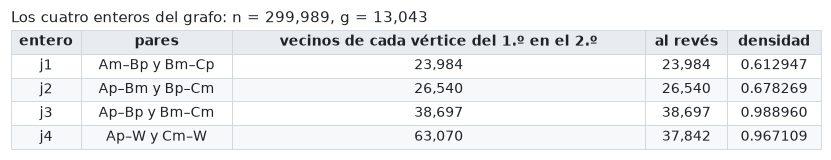

los grados respetan el espejo: sí
pares completos: Am–Ap, Am–Bm, Am–W, Bm–Bp, Bp–Cp, Cm–Cp, Cp–W
pares vacíos: A–C y B–W (sectores opuestos)
n simétrico: 299989   (referencia: 299989, coincide)
μ simétrico: 206565/299989   (referencia: 206565/299989, coincide)
μ ≈ 0.688575 (11/16 = 0.6875)
guardado en resultados/grafo_simetrico_s7.json


In [94]:
barrido_referencia[0]["certificado"] = certificado_referencia
candidatos = []
for r in barrido:
    if r.get("certificado", {}).get("ok"):
        candidatos.append((r, s_simetrica, "esta corrida"))
if certificado_referencia["ok"]:
    candidatos.append((barrido_referencia[0], S_REFERENCIA, "desplazamientos de referencia"))
grafo_simetrico, s_grafo, origen_grafo = min(candidatos, key=lambda c: c[0]["n"])
print("plantilla del grafo elegido:", origen_grafo)
d = grafo_simetrico["d"]
n_a = tamanos_enteros(K_S7, grafo_simetrico["g"])
espejo = True
for a in range(7):
    for b in range(7):
        espejo = espejo and d[REFLEJO[a]][REFLEJO[b]] == d[a][b]

filas = []
for c, pareja in enumerate(parejas):
    (a, b), (ra, rb) = pareja
    filas.append([f"j{c + 1}", f"{NOMBRES[a]}–{NOMBRES[b]} y {NOMBRES[ra]}–{NOMBRES[rb]}", f"{d[a][b]:,}",
                  f"{d[b][a]:,}", f"{d[a][b] / n_a[b]:.6f}"])
mostrar_tabla(["entero", "pares", "vecinos de cada vértice del 1.º en el 2.º", "al revés", "densidad"], filas,
              titulo=f"Los cuatro enteros del grafo: n = {grafo_simetrico['n']:,}, g = {grafo_simetrico['g']:,}")

completos = []
for a in range(7):
    for b in range(a + 1, 7):
        if d[a][b] == n_a[b]:
            completos.append(f"{NOMBRES[a]}–{NOMBRES[b]}")
mu_grafo = mu_entero(K_S7, grafo_simetrico["g"], d)
print("los grados respetan el espejo:", si_no(espejo))
print("pares completos:", ", ".join(completos))
print("pares vacíos: A–C y B–W (sectores opuestos)")
comparar("n simétrico", grafo_simetrico["n"])
comparar("μ simétrico", f"{mu_grafo.numerator}/{mu_grafo.denominator}")
print("μ ≈", f"{float(mu_grafo):.6f}", "(11/16 = 0.6875)")

descripcion_simetrica = descripcion_compacta(K_S7, grafo_simetrico["g"], d, grafo_simetrico["certificado"]["fases"])
guardado = guardar_json("grafo_simetrico_s7.json", {
    "h": H, "margen": MARGEN, "s": s_grafo.tolist(), "enteros": grafo_simetrico["j"],
    "parejas": [[[NOMBRES[a], NOMBRES[b]] for a, b in p] for p in parejas],
    "certificado": grafo_simetrico["certificado"], "grafo": descripcion_simetrica,
})
print("guardado en", guardado)

**Cómo se ve.** La misma figura de la sección 8.3. La simetría se ve en (a) como un espejo vertical que
pasa por B y W.

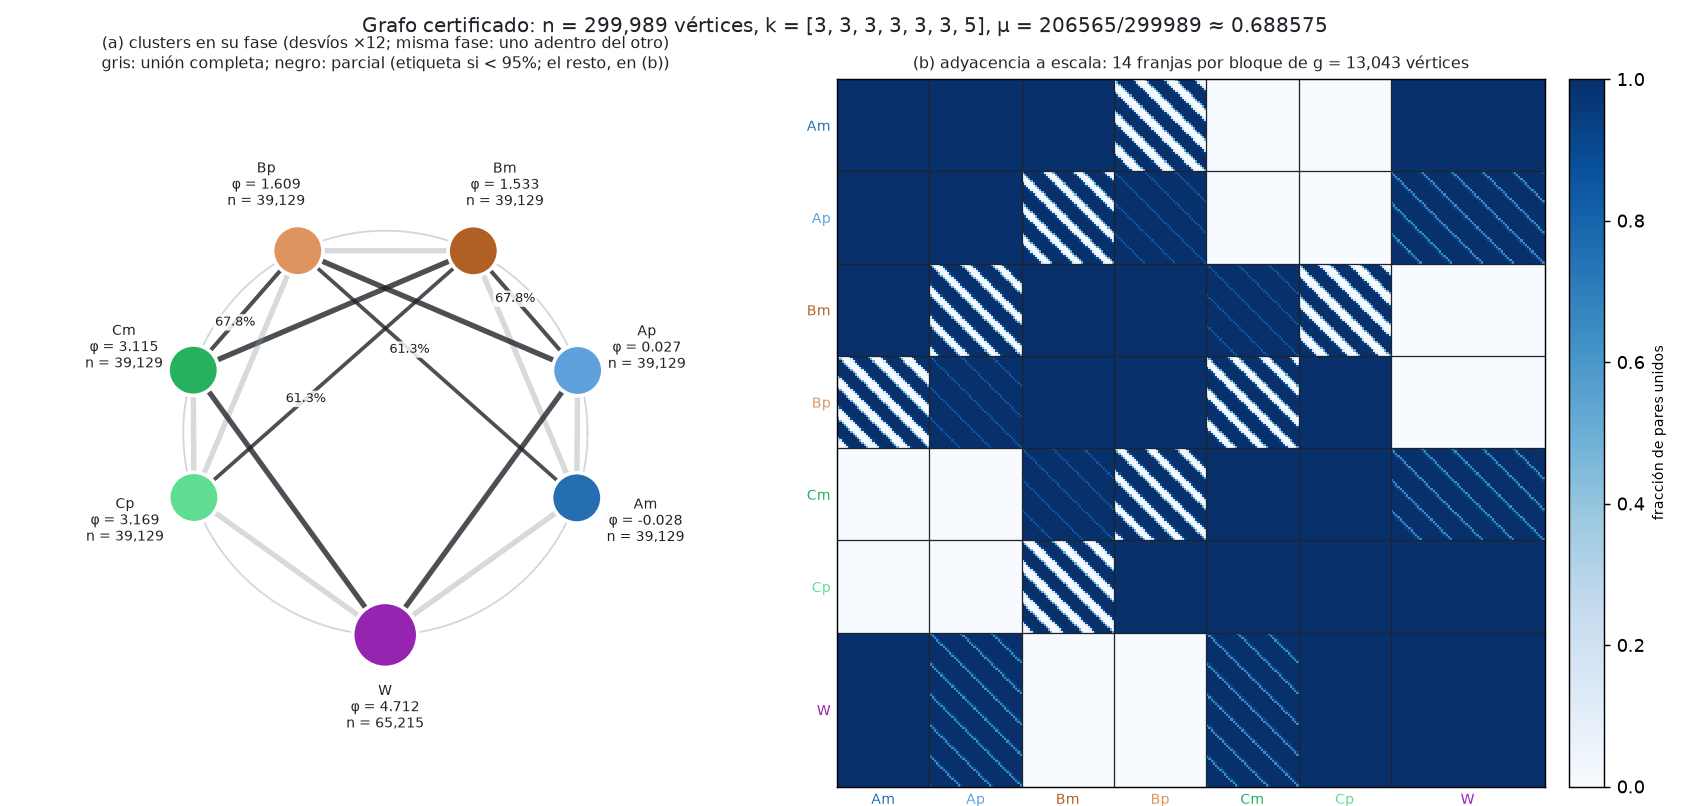

In [95]:
archivo = CARPETA_RESULTADOS / "figuras" / f"grafo_simetrico_n{descripcion_simetrica['n']}_estructura.png"
dibujar_estructura(descripcion_simetrica, grafo_simetrico["certificado"]["mu_exacto"], archivo)
display(Image(filename=str(archivo)))

### 13.7 Validación ciega del grafo simétrico

Con $n = 299\,989$ la validación de la sección 10.2 corre en vivo, en CPU, en unos segundos: un producto
$Hx$ tarda unas centésimas de segundo.

$ /home/imagenes/nicoyanez/investighaton/investighaton-teo-optimizacion-2026/.venv/bin/python -u externos/validar_grafo.py --archivo grafo_simetrico_s7.json --dispositivo numpy


grafo h = 0.03, n = 299989, k = [3, 3, 3, 3, 3, 3, 5], g = 13043, μ = 206565/299989 (numpy)
un producto H·x: 0.04 s


1. grados exactos: True   grado mínimo δ = 206564


2. max |θ̇| = 1.365e-11


3. modos de cluster: |Q implícita − fórmula| = 3.64e-11
4. resto de los modos (cota de Gershgorin certificada: λ ≥ 6.527803e+04)


  [resto] paso     50  θ_min = 6.5366475168e+04  residuo = 1.94e-02  θ_max = 7.9469e+04  (2 s)
5. Lanczos en 1^⊥ (esperado: menor autovalor de Q = 1.2506252672e+00)


  [1^⊥] paso     50  θ_min = 1.2506252671e+00  residuo = 4.79e-08  θ_max = 7.9469e+04  (2 s)
guardado en resultados/validacion_s7_n299989.json


[6 s]
un producto H·x: 0.035 s


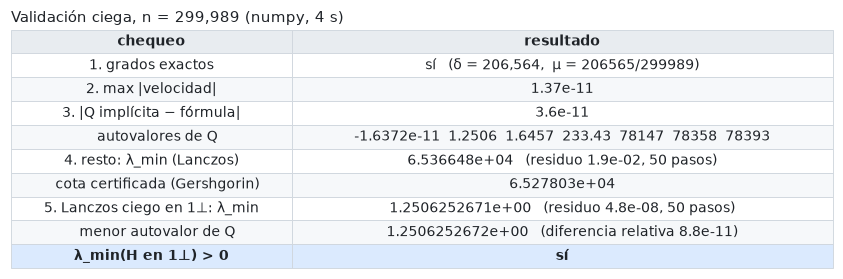

λ_min simétrico: 1.2506252672   (referencia: 1.2506252672, coincide)


In [96]:
NOMBRE_VALIDACION_SIMETRICA = f"validacion_s7_n{descripcion_simetrica['n']}.json"
if not existe_resultado(NOMBRE_VALIDACION_SIMETRICA):
    correr_paso("validar_grafo.py", "--archivo grafo_simetrico_s7.json --dispositivo numpy", "validación ciega simétrico")
validacion_simetrica = cargar_json(NOMBRE_VALIDACION_SIMETRICA)
print("un producto H·x:", f"{validacion_simetrica['segundos_producto']:.3f} s")
mostrar_validacion(validacion_simetrica)
comparar("λ_min simétrico", round(validacion_simetrica["menor_cluster"], 10), tolerancia=1e-8)

**Lectura.**
- **Grados:** exactos, y $\mu = 206565/299989 \approx 0.688575 > 11/16$.
- **Velocidad:** $\sim10^{-11}$, error de redondeo: las fases certificadas son un equilibrio del grafo
  real.
- **$Q$:** coincide con la fórmula. Sus autovalores son 0 (la rotación), **1.2506** y 1.6457 (los dos
  modos casi neutros que vienen de C4), 233.4 y tres $\approx7.8\cdot10^4$.
- **Resto:** $\lambda_{\min}\approx6.5366\cdot10^4$, apenas arriba de la cota de Gershgorin.
- **Lanczos ciego en $\mathbf 1^\perp$:** llega al menor autovalor de $Q$ con diferencia relativa
  $\sim10^{-10}$, en 50 pasos.

Dividido por $n$, $1.2506/n\approx4.2\cdot10^{-6}$: es el margen de estabilidad que limita qué tan chico
puede ser $n$ (sección 13.5).

### 13.8 El espectro completo del grafo simétrico

Son 6 522 matrices de $23\times23$: menos de un segundo.

$ /home/imagenes/nicoyanez/investighaton/investighaton-teo-optimizacion-2026/.venv/bin/python -u externos/espectro.py --archivo grafo_simetrico_s7.json


grafo de grafo_simetrico_s7.json: n = 299989, k = [3, 3, 3, 3, 3, 3, 5], g = 13043


1. H·x por Fourier contra el implícito: error relativo 7.5e-16


  6521/6521 frecuencias (0 s)
λ_min = 1.250625e+00, respeta las cotas: True   (1 s)
guardado en resultados/espectro_s7_n299989.json


[3 s]


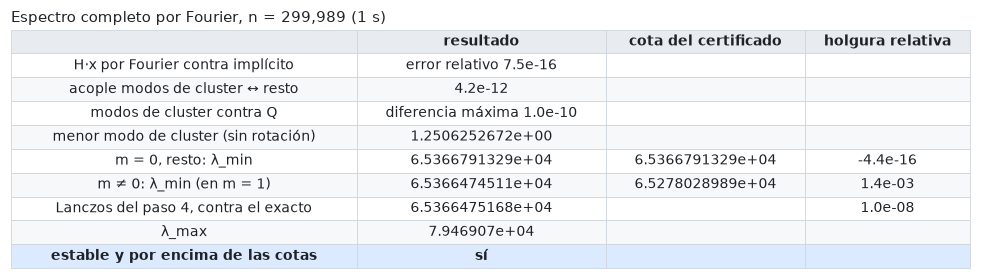

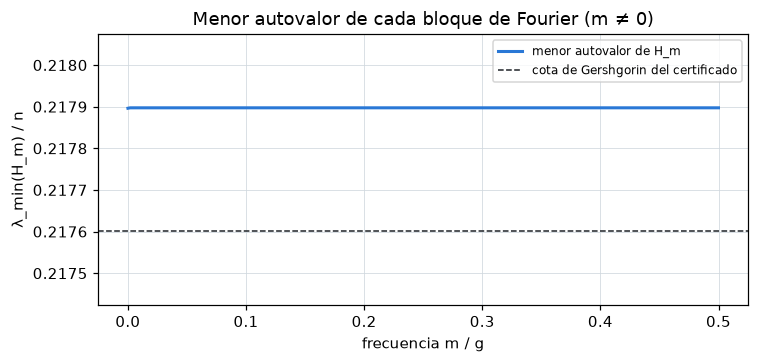

In [97]:
NOMBRE_ESPECTRO_SIMETRICO = f"espectro_s7_n{descripcion_simetrica['n']}.json"
if not existe_resultado(NOMBRE_ESPECTRO_SIMETRICO):
    correr_paso("espectro.py", "--archivo grafo_simetrico_s7.json", "espectro simétrico")
espectro_simetrico = cargar_json(NOMBRE_ESPECTRO_SIMETRICO)
mostrar_espectro(espectro_simetrico, validacion_simetrica["resto"]["menor"])

- **La descomposición es correcta** y Lanczos daba bien: su valor del paso 4 queda a $\sim10^{-8}$
  relativo del menor autovalor exacto, y por encima, como tiene que ser.
- **Gershgorin es casi exacta en $m\ne0$** (el mínimo, en $m = 1$, la supera en 0.14%) y **exacta en
  $m = 0$**, por la misma razón que en el grafo general: la pone W.

El grafo de $299\,989$ vértices, armado desde la regla de adyacencia, tiene los grados del certificado,
las fases certificadas son un equilibrio y su Hessiano es definido positivo en $\mathbf 1^\perp$ con
$\lambda_{\min} = 1.2506$; ningún autovalor queda debajo de las cotas del certificado.

### 13.9 La dinámica del grafo simétrico

Primero la reducción exacta a clusters (sección 11.1): las tasas de los modos lentos son
$1.2506/n\approx4.2\cdot10^{-6}$ y $1.6457/n\approx5.5\cdot10^{-6}$, parecidas a las del grafo general,
así que se espera una cuenca igual de chica.

  modo más lento  δ = 1e-04: distancia final 1.8e-12,  r final = 0.0430  (0.0 s)


  modo más lento  δ = 3e-04: distancia final 2.4e-12,  r final = 0.0430  (0.0 s)


  modo más lento  δ = 1e-03: distancia final 2.4e+00,  r final = 1.0000  (0.0 s)


  modo más lento  δ = 1e-02: distancia final 2.4e+00,  r final = 1.0000  (0.0 s)


  modo más lento  δ = 1e-01: distancia final 2.4e+00,  r final = 1.0000  (0.0 s)


  al azar         δ = 1e-04: distancia final 1.3e-12,  r final = 0.0430  (0.0 s)


  al azar         δ = 3e-04: distancia final 2.5e+00,  r final = 1.0000  (0.0 s)


  al azar         δ = 1e-03: distancia final 2.5e+00,  r final = 1.0000  (0.0 s)


  al azar         δ = 1e-02: distancia final 2.5e+00,  r final = 1.0000  (0.0 s)


  al azar         δ = 1e-01: distancia final 2.5e+00,  r final = 1.0000  (0.0 s)


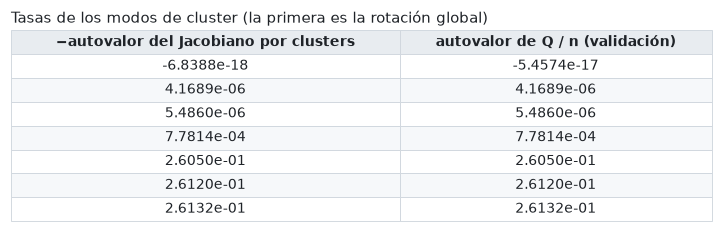

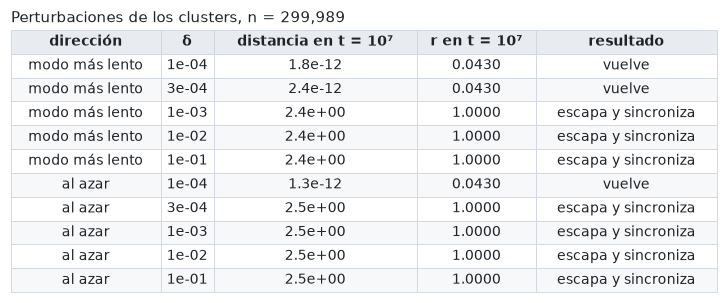

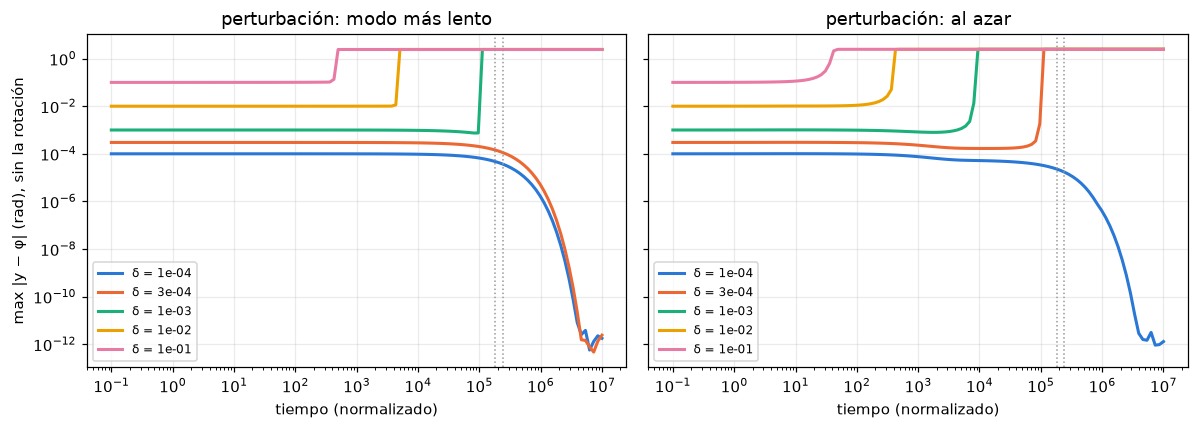

In [98]:
mostrar_clusters(descripcion_simetrica, validacion_simetrica["autovalores_Q"])

**El grafo completo.** Con $n = 3\cdot10^5$ un paso de RK4 tarda ~0.1 s, así que las simulaciones hasta
$t = 60$ (ruido 0.05 y 0.5 rad, seguidas por la reducción a clusters) corren en vivo, en menos de un
minuto. Las simulaciones largas, con el grafo completo hasta $t = 4000$ (unos 15 minutos cada una en
CPU), van con la bandera `simulaciones_simetrico`; ahí la reducción a clusters arranca en $t = 60$ y queda
como comparación, porque todo lo que pasa hasta $t = 4000$ sale de la simulación completa.

<table>
<tr><th align="left">▶ Cómo correr <code>externos/simular.py</code> con el grafo simétrico (desde la carpeta del notebook)</th></tr>
<tr><td align="left"><b>Máquina:</b> CPU (numpy; no hace falta GPU)<br><b>Tiempo:</b> hasta t = 60: ~30 s por corrida · hasta t = 4000: ~15 min por corrida<br><b>Salida:</b> <code>resultados/simulacion_n299989.json</code> y <code>resultados/figuras/grafo_n299989_sim_*.png</code></td></tr>
<tr><td align="left"><pre>python externos/simular.py --archivo grafo_simetrico_s7.json --ruido 0.05</pre></td></tr>
<tr><td align="left"><pre>python externos/simular.py --archivo grafo_simetrico_s7.json --ruido 0.5</pre></td></tr>
<tr><td align="left"><pre>nohup sh -c "python externos/simular.py --archivo grafo_simetrico_s7.json --ruido 0.05 --tiempo 4000 --continuar-desde 60 --fotos 0,15,60,1000,4000 &amp;&amp; python externos/simular.py --archivo grafo_simetrico_s7.json --ruido 0.5 --tiempo 4000 --continuar-desde 60 --fotos 0,15,60,1000,4000" &gt; simulacion_simetrico.log 2&gt;&amp;1 &amp;</pre></td></tr>
</table>

$ /home/imagenes/nicoyanez/investighaton/investighaton-teo-optimizacion-2026/.venv/bin/python -u externos/simular.py --archivo grafo_simetrico_s7.json --ruido 0.05


simulación 'perturbado' (grafo completo, n = 299,989, numpy):


  t =       0.0  r = 0.0430  distancia al estado = 2.36e-01  (0 s)


  t =       6.0  r = 0.0431  distancia al estado = 5.88e-02  (2 s)


  t =      12.0  r = 0.0431  distancia al estado = 1.59e-02  (3 s)


...

  t =    3606.0  r = 1.0000  distancia al estado = 3.14e+00  (917 s)


  t =    4000.0  r = 1.0000  distancia al estado = 3.14e+00  (1020 s)


  fin: r = 1.0000, distancia = 3.14e+00; reducción hasta t = 1e+07: r = 1.0000, distancia = 2.46e+00 → resultados/figuras/grafo_n299989_sim_perturbado_ruido0.5_t4000.png


series guardadas en resultados/simulacion_n299989.json


[1038 s]

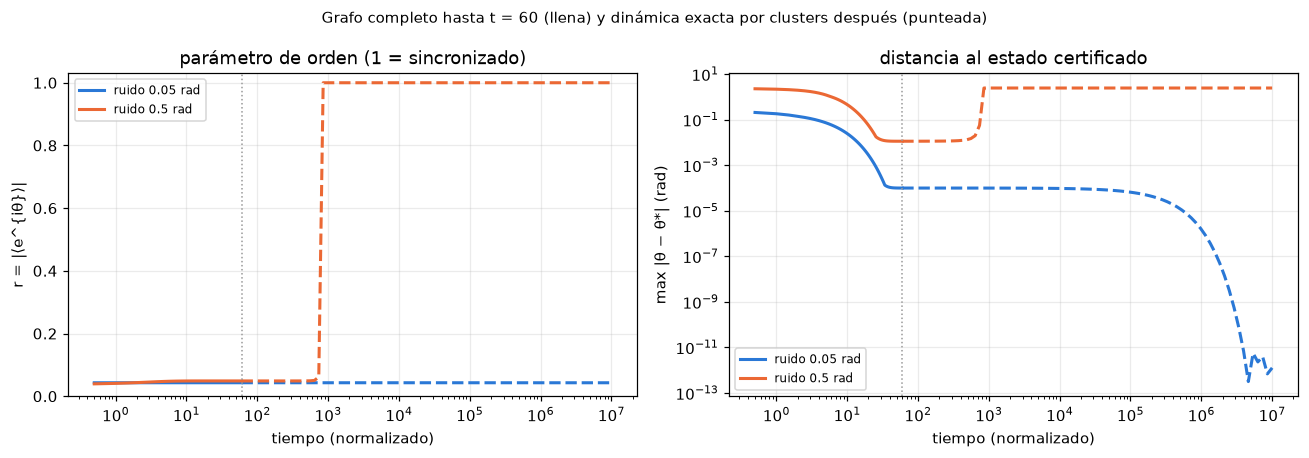

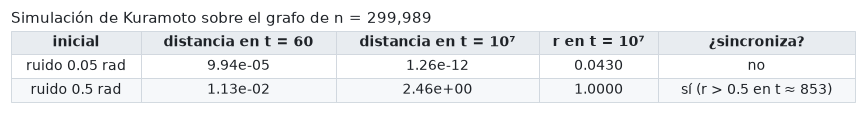

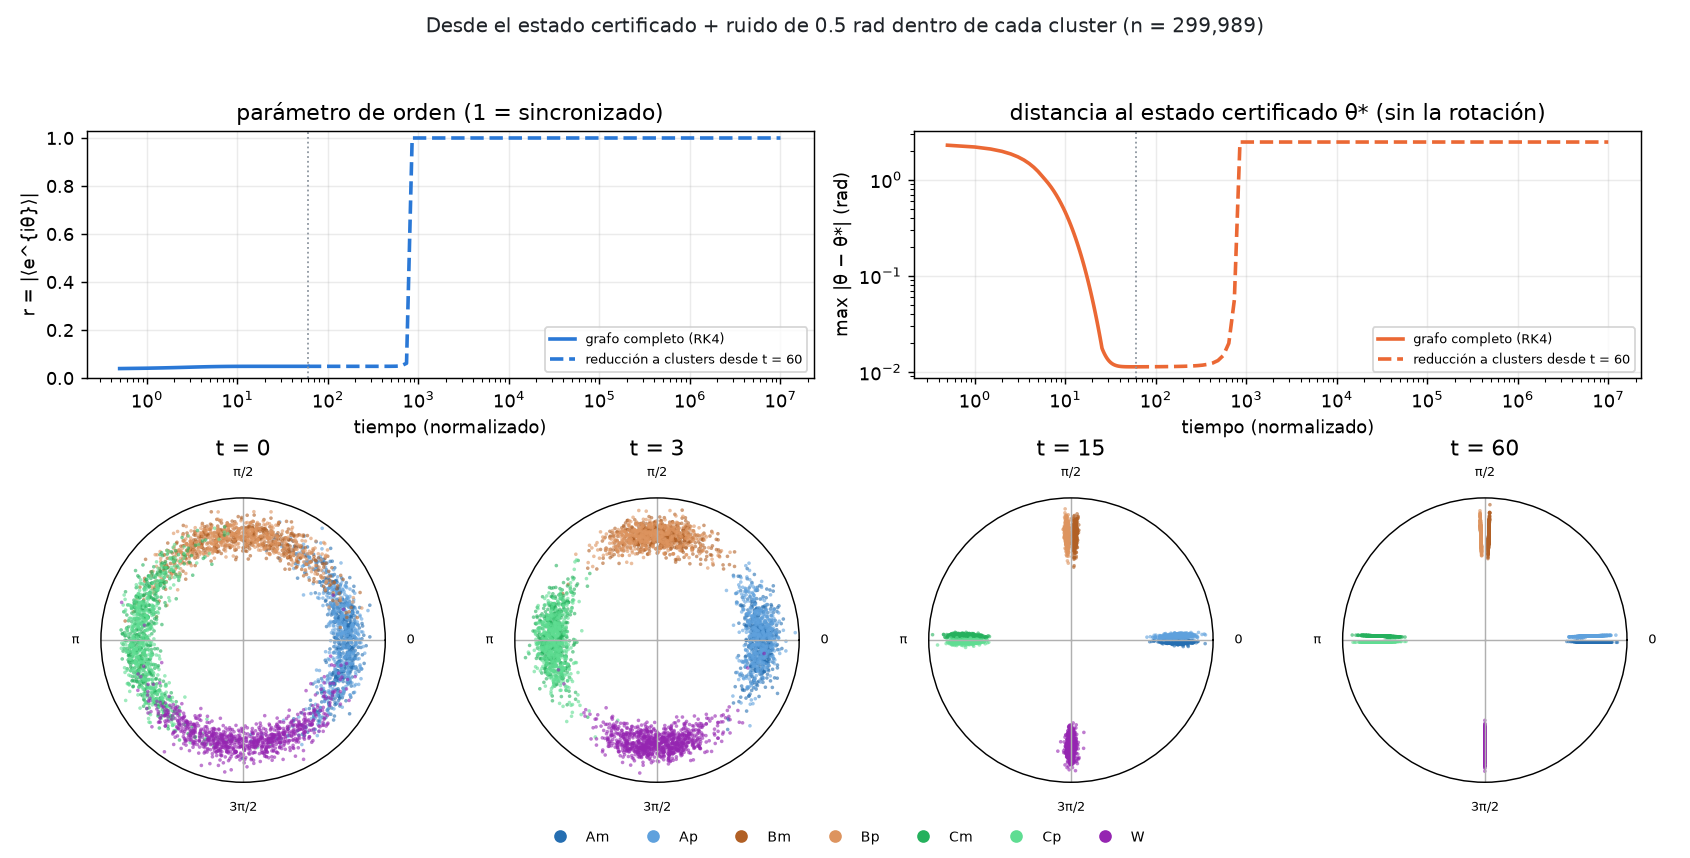

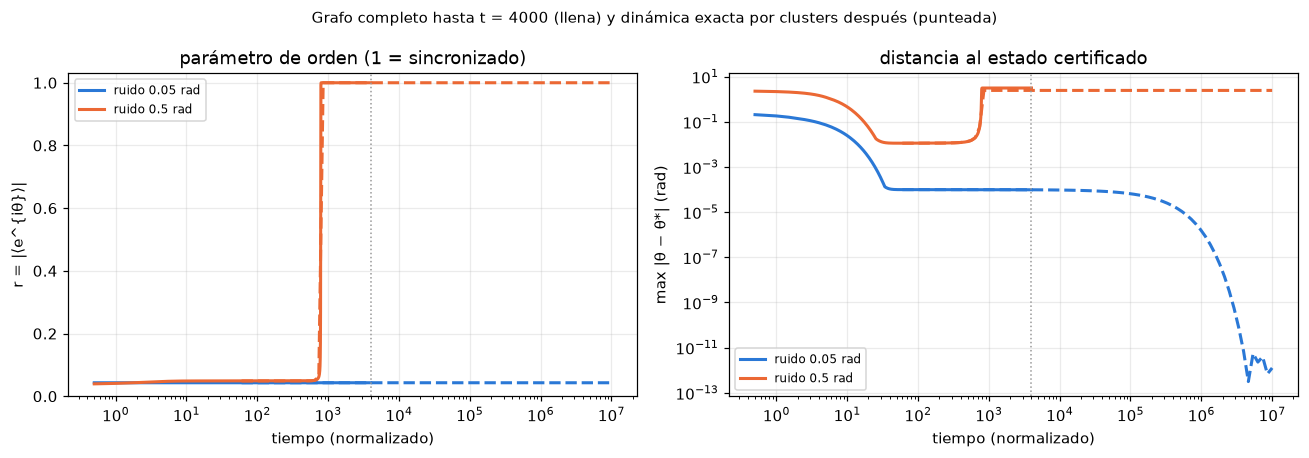

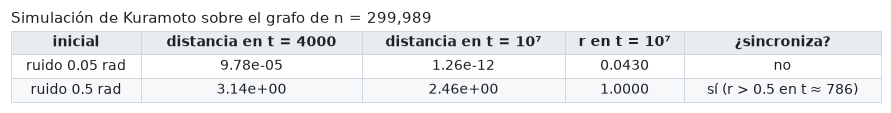

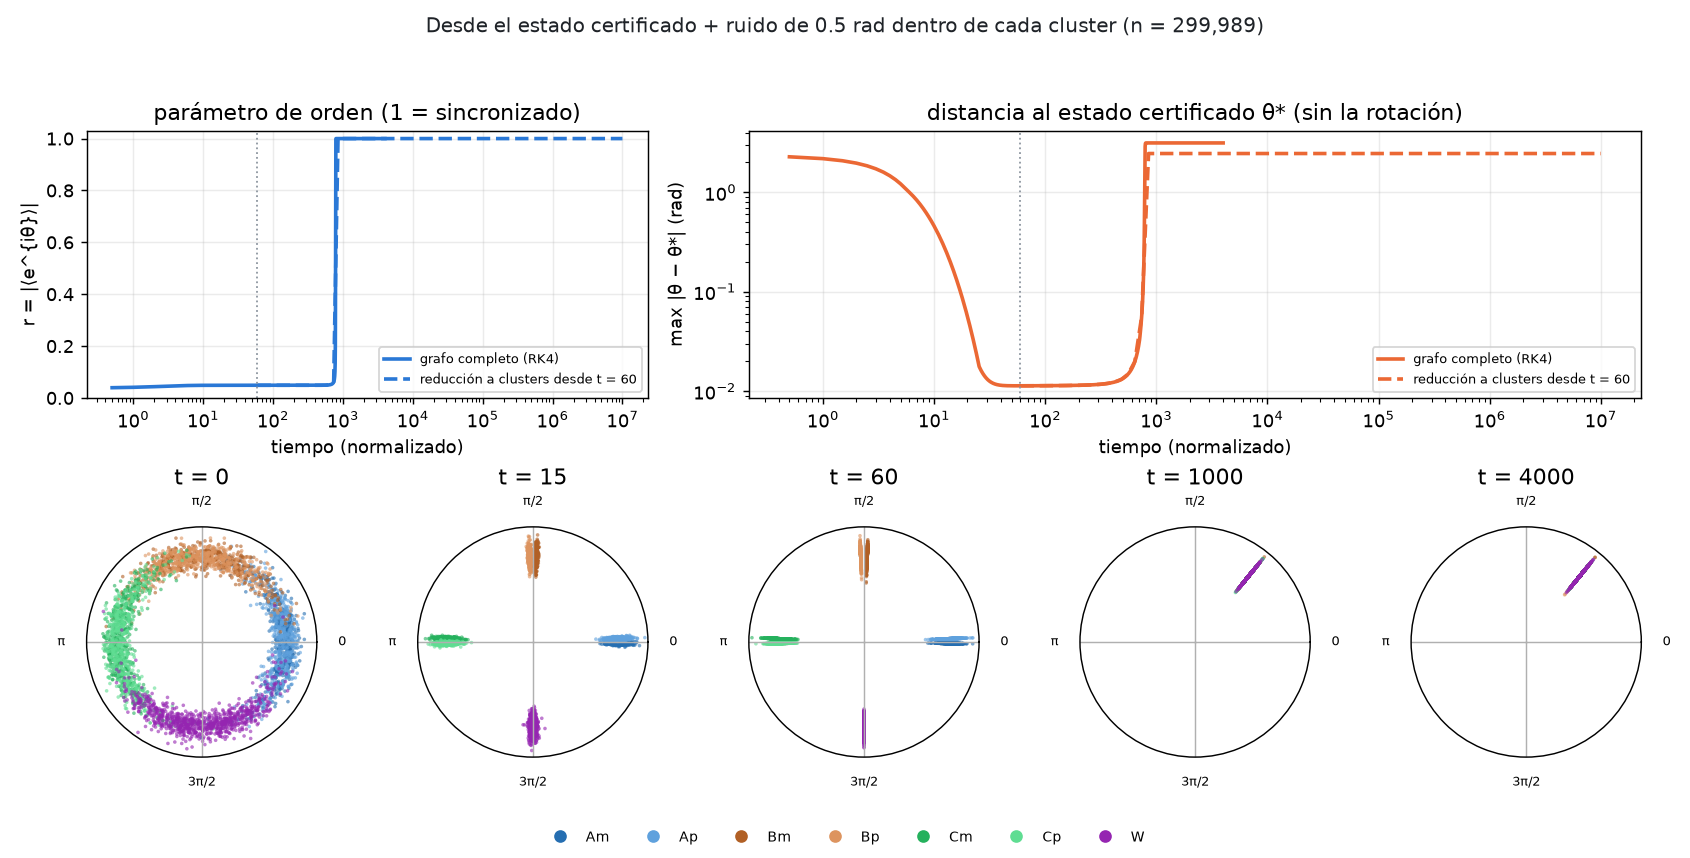

In [99]:
NOMBRE_SIMULACION_SIMETRICA = f"simulacion_n{descripcion_simetrica['n']}.json"
CORRIDAS_CORTAS = [("perturbado_ruido0.05_t60", "ruido 0.05 rad"), ("perturbado_ruido0.5_t60", "ruido 0.5 rad")]
CORRIDAS_LARGAS = [("perturbado_ruido0.05_t4000", "ruido 0.05 rad"), ("perturbado_ruido0.5_t4000", "ruido 0.5 rad")]
for (clave, _), ruido in zip(CORRIDAS_CORTAS, [0.05, 0.5]):
    if faltan_corridas(NOMBRE_SIMULACION_SIMETRICA, [clave]):
        correr_paso("simular.py", f"--archivo grafo_simetrico_s7.json --ruido {ruido}",
                    f"simulación simétrico ruido {ruido} hasta t = 60")
for (clave, _), ruido in zip(CORRIDAS_LARGAS, [0.05, 0.5]):
    if faltan_corridas(NOMBRE_SIMULACION_SIMETRICA, [clave]) and CORRER["simulaciones_simetrico"]:
        correr_paso("simular.py", f"--archivo grafo_simetrico_s7.json --ruido {ruido} --tiempo 4000 "
                    "--continuar-desde 60 --fotos 0,15,60,1000,4000", f"simulación simétrico ruido {ruido} hasta t = 4000")

mostrar_simulaciones(NOMBRE_SIMULACION_SIMETRICA, CORRIDAS_CORTAS, 60)
display(Image(filename=str(CARPETA_RESULTADOS / "figuras" / f"grafo_n{descripcion_simetrica['n']}_sim_perturbado_ruido0.5_t60.png")))
if not faltan_corridas(NOMBRE_SIMULACION_SIMETRICA, [c[0] for c in CORRIDAS_LARGAS]):
    mostrar_simulaciones(NOMBRE_SIMULACION_SIMETRICA, CORRIDAS_LARGAS, 4000)
    display(Image(filename=str(CARPETA_RESULTADOS / "figuras" / f"grafo_n{descripcion_simetrica['n']}_sim_perturbado_ruido0.5_t4000.png")))
else:
    print("Las simulaciones hasta t = 4000 no se corrieron (CORRER['simulaciones_simetrico'] = False).")

**Lectura.** El grafo simétrico se comporta como el general:
- **ruido 0.05 rad: vuelve.** Los modos internos se apagan solos, el corrimiento que queda en los
  clusters es chico y vuelve en la escala lenta, hasta distancias de $\sim10^{-12}$; $r$ queda en el
  valor del estado certificado;
- **ruido 0.5 rad: escapa.** Los cuatro grupos se forman y el ruido interno se apaga, pero el
  corrimiento de los clusters queda fuera de la cuenca y el estado termina sincronizando ($r \to 1$).

La trampa es real y su cuenca en las direcciones lentas es tan chica como la del grafo general, como
anticipaba $\lambda_{\min}/n \approx 4\cdot10^{-6}$.

## 14. Comparación final y qué queda abierto

La tabla junta las construcciones conocidas con los dos grafos de este notebook, con los valores
calculados acá.

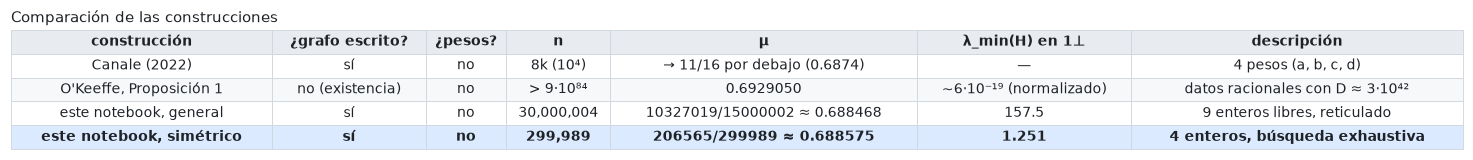

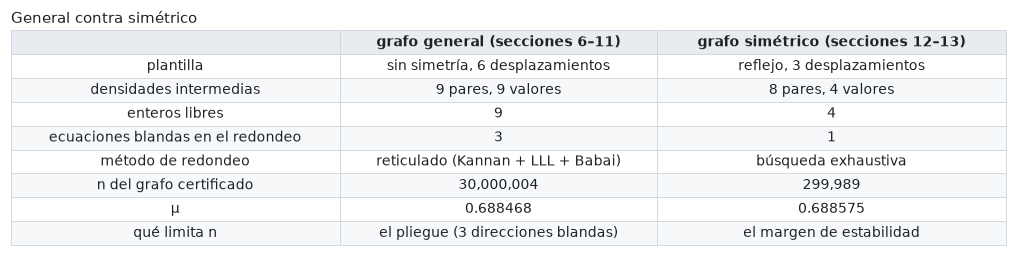

In [100]:
mu_general = general["certificado"]
mu_sim = grafo_simetrico["certificado"]
lambda_general = f"{validacion_general['menor_cluster']:.4g}" if validacion_general else "(sección 10.2)"
mostrar_tabla(["construcción", "¿grafo escrito?", "¿pesos?", "n", "μ", "λ_min(H) en 1⊥", "descripción"], [
    ["Canale (2022)", "sí", "no", "8k (10⁴)", "→ 11/16 por debajo (0.6874)", "—", "4 pesos (a, b, c, d)"],
    ["O'Keeffe, Proposición 1", "no (existencia)", "no", "> 9·10⁸⁴", "0.6929050", "~6·10⁻¹⁹ (normalizado)",
     "datos racionales con D ≈ 3·10⁴²"],
    ["este notebook, general", "sí", "no", f"{descripcion_general['n']:,}",
     f"{mu_general['mu_exacto']} ≈ {mu_general['mu']:.6f}", lambda_general, "9 enteros libres, reticulado"],
    ["este notebook, simétrico", "sí", "no", f"{descripcion_simetrica['n']:,}",
     f"{mu_sim['mu_exacto']} ≈ {mu_sim['mu']:.6f}", f"{validacion_simetrica['menor_cluster']:.4g}",
     "4 enteros, búsqueda exhaustiva"],
], titulo="Comparación de las construcciones", resaltar=[3])

mostrar_tabla(["", "grafo general (secciones 6–11)", "grafo simétrico (secciones 12–13)"], [
    ["plantilla", "sin simetría, 6 desplazamientos", "reflejo, 3 desplazamientos"],
    ["densidades intermedias", "9 pares, 9 valores", "8 pares, 4 valores"],
    ["enteros libres", "9", "4"],
    ["ecuaciones blandas en el redondeo", "3", "1"],
    ["método de redondeo", "reticulado (Kannan + LLL + Babai)", "búsqueda exhaustiva"],
    ["n del grafo certificado", f"{descripcion_general['n']:,}", f"{descripcion_simetrica['n']:,}"],
    ["μ", f"{mu_general['mu']:.6f}", f"{mu_sim['mu']:.6f}"],
    ["qué limita n", "el pliegue (3 direcciones blandas)", "el margen de estabilidad"],
], titulo="General contra simétrico")

### Lo que se logró

- Un grafo **escrito**, **sin pesos** y **certificado** con $\mu > 11/16$: supera a Canale con un grafo
  concreto, combinando las plantillas de O'Keeffe con el blow-up circulante de Canale.
- **Por qué funciona:** (1) tamaños racionales desde el principio; (2) densidades óptimas con margen
  (el SDP) en lugar de las perturbativas; (3) un redondeo a enteros que esquiva el pliegue (reticulado, o
  la simetría); (4) un blow-up circulante con grados exactos, en el que el resto de los modos tiene
  margen $\ge 0.2\,n$ sin importar los desplazamientos.
- La versión simétrica es la más simple y la más chica: 4 enteros, una sola ecuación blanda, sin
  reticulados, y 100 veces menos vértices que la construcción general.
- Los dos grafos se validaron sin la teoría del certificado (regla de adyacencia, float64) y con su
  espectro completo, y se simuló su dinámica.

### Lo que no se logró

- **No mejoramos la cota de $\mu_c$:** O'Keeffe ya probó $\mu_c \ge 0.6929$. El aporte es el grafo
  explícito y chico, no un número mejor.
- **La cuenca es diminuta, aunque eso no afecta la cota.** La trampa es un mínimo local estricto, así que
  la atrae todo un **entorno** de condiciones iniciales (un conjunto de medida positiva). Eso alcanza
  para la cota. Pero el entorno es muy aplanado: ancho en las direcciones internas de cada cluster (el
  ruido se apaga solo), y de solo $\sim10^{-4}$ rad en las direcciones lentas, porque el estado está
  cerca del pliegue. Desde fases al azar el grafo sincroniza; por eso la trampa se prueba con el
  certificado y no con simulaciones.
- **Los resultados dependen de optimizadores numéricos:** con otra versión de Nelder–Mead o del solver
  la plantilla puede salir apenas distinta (en una prueba, el $n$ mínimo simétrico pasó de $3\cdot10^5$
  a $10^6$). Lo que se certifica es el grafo que se obtiene, sea cual sea.

### Lo que queda abierto

- **Densidades puras en $\{0, q, 1\}$:** con las fases en $\pm h$ es infactible (sección 12.3). Queda
  abierto si existe con fases libres.
- **Una familia infinita como la de Canale:** datos racionales fijos con denominador chico, que funcionen
  para todo $g$ múltiplo de él, con un único certificado.
- **Más enteros libres por ecuación blanda** (partir clusters en sub-piezas de la misma fase, el "camino
  B") y la **familia áurea** de estados en anillos se exploraron aparte y no forman parte de este
  informe.

## 15. Glosario

- **Blow-up:** reemplazar cada vértice (o cluster) por muchos vértices con la misma fase.
- **Blow-up circulante / k-spinning:** cada cluster son copias de $\mathbb Z_g$ y cada vértice se une a
  un intervalo de vértices consecutivos del otro cluster; da grados exactos.
- **C4:** cuatro clusters a 90°; $\mu = 3/4$ pero neutro.
- **Certificado:** prueba por computadora con aritmética de intervalos (redondeo hacia afuera), que vale
  como demostración.
- **Cholesky por intervalos:** factorización que, si termina con pivotes positivos, prueba que una matriz
  es definida positiva para todos los valores de una caja.
- **Conectividad $\mu$:** $(\delta+1)/n$, con $\delta$ el grado mínimo.
- **Dirección blanda / rígida:** vector singular del Jacobiano del equilibrio con valor singular chico /
  grande.
- **Encaje de Kannan:** convertir "dos condiciones sobre enteros" en "el punto más cercano de un
  reticulado", juntándolas como bloques de un mismo vector.
- **Espectro por bloques de Fourier:** como el blow-up circulante conmuta con el corrimiento $v\to v+1$,
  su Hessiano se parte en $g$ matrices chicas; diagonalizarlas da todos los autovalores.
- **Krawczyk:** test de intervalos que prueba que un sistema de ecuaciones tiene una única solución
  dentro de una caja.
- **Lanczos:** método que aproxima los autovalores extremos de una matriz con solo productos
  matriz-vector; sus valores de Ritz son cotas superiores del menor autovalor.
- **LLL:** algoritmo que da una base corta y casi ortogonal de un reticulado.
- **Lyapunov–Schmidt:** resolver las ecuaciones bien condicionadas y quedarse con el residuo de las mal
  condicionadas.
- **Pliegue (silla-nodo):** punto donde un equilibrio estable y uno inestable se juntan y desaparecen;
  forma normal $\sigma y + \tfrac c2y^2 + \rho = 0$.
- **Plano más cercano de Babai:** algoritmo que aproxima el punto de un reticulado más cercano a un
  vector.
- **Plantilla $(x, \varphi, P)$:** descripción de un estado de clusters por tamaños, fases y densidades.
- **Reflejo:** la simetría $\varphi\mapsto\pi-\varphi$ de S7 (Am↔Cp, Ap↔Cm, Bm↔Bp, W fijo).
- **SDP (programa semidefinido):** optimización convexa con restricciones lineales y de "matriz
  semidefinida positiva".
- **Trampa:** mínimo local estricto de la energía que no es la sincronización.

## Apéndice: tiempos de esta corrida y scripts

Tiempos medidos en esta corrida, de los pasos que se calcularon (los que se cargaron de `resultados/` no
aparecen). La última celda exporta la biblioteca completa, así todos los scripts de `externos/` quedan
listos para correr afuera.

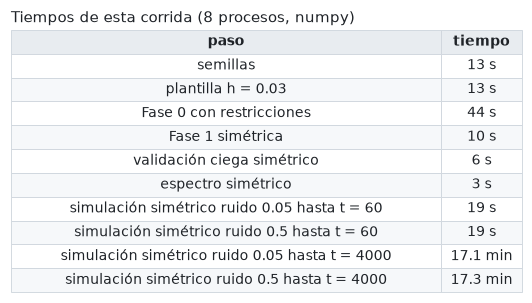

biblioteca exportada en externos/biblioteca_s7.py
   externos/biblioteca_s7.py
   externos/caso_01.py
   externos/certificar_grafos.py
   externos/curva.py
   externos/enteros.py
   externos/espectro.py
   externos/particiones.py
   externos/simular.py
   externos/validar_grafo.py


In [101]:
filas = []
for paso, segundos in TIEMPOS.items():
    filas.append([paso, f"{segundos:.0f} s" if segundos < 120 else f"{segundos / 60:.1f} min"])
if filas:
    mostrar_tabla(["paso", "tiempo"], filas, titulo=f"Tiempos de esta corrida ({PROCESOS} procesos, {DISPOSITIVO})")
print("biblioteca exportada en", exportar_biblioteca())
for script in sorted(Path("externos").glob("*.py")):
    print("  ", script)